<a href="https://colab.research.google.com/github/uniqueeee777/stability-aware-multiview-food-security/blob/main/07_Empirical_Selection_and_Regional_Interpretation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Empirical provenance and integrity audit

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 01 (CORRECTED)
# EMPIRICAL R0 PROVENANCE AND INTEGRITY AUDIT
# ================================================================
#
# Research:
# A Stability-Aware Multi-View Clustering Framework for
# Climate-Related Food Security Vulnerability:
# Evidence from Eastern Indonesia
#
# Objectives:
# 1. Verify empirical R0 provenance.
# 2. Resolve historical grid_sha256 interpretation.
# 3. Verify all 395 candidate configurations.
# 4. Verify all 85 district memberships.
# 5. Independently verify 303 unique partitions.
# 6. Audit 39,500 subsampling evaluations.
# 7. Verify seed-aligned V2 reproducibility.
# 8. Prepare verified candidates for Cell 02.
#
# READ ONLY.
# NO model fitting.
# NO file modification.
# NO model selection.
# ================================================================


# ================================================================
# 0. ENVIRONMENT
# ================================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

from pathlib import Path
from IPython.display import display

import hashlib
import json
import numpy as np
import pandas as pd


# ================================================================
# 1. SOURCE DIRECTORIES
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

BASE = ROOT / "03_outputs"

GRID_DIR = (
    BASE
    / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

STAB_DIR = (
    BASE
    / "06_stability_selection"
    / "R0_all395_selection_seed_aligned_v2"
)


SOURCE_PATHS = {
    "grid": (
        GRID_DIR / "grid_plan.csv"
    ),
    "quality": (
        GRID_DIR / "quality_grid_all.csv"
    ),
    "labels": (
        GRID_DIR / "labels_all.csv"
    ),
    "partitions": (
        GRID_DIR / "partition_uniqueness_audit.csv"
    ),
    "quality_protocol": (
        GRID_DIR / "protocol.json"
    ),
    "stability": (
        STAB_DIR / "stability_selection_all395.csv"
    ),
    "repetitions": (
        STAB_DIR / "stability_selection_repetitions.csv"
    ),
    "stability_manifest": (
        STAB_DIR / "manifest.json"
    ),
    "reproduction": (
        STAB_DIR / "full_data_reproduction_audit.csv"
    ),
    "seed_reproduction": (
        STAB_DIR / "full_data_refit_seed_audit.csv"
    )
}


for name, path in SOURCE_PATHS.items():

    if not path.is_file():
        raise FileNotFoundError(
            f"Missing {name}: {path}"
        )


# ================================================================
# 2. HELPER FUNCTIONS
# ================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8"
    ) as f:

        return json.load(f)


def verify_exact_set(reference, comparison, name):

    assert len(reference) == len(comparison), name

    assert set(reference) == set(comparison), (
        f"Model ID mismatch in {name}"
    )


def normalized_configuration(frame):

    required = [
        "model_id",
        "method",
        "K",
        "k_graph",
        "k_scale",
        "weight_id"
    ]

    assert set(required).issubset(
        frame.columns
    )

    out = frame[required].copy()

    out["model_id"] = (
        out["model_id"].astype(str)
    )

    out["method"] = (
        out["method"].astype(str)
    )

    out["weight_id"] = (
        out["weight_id"]
        .astype("string")
        .fillna("<NA>")
    )

    for col in [
        "K",
        "k_graph",
        "k_scale"
    ]:

        out[col] = pd.to_numeric(
            out[col],
            errors="coerce"
        )

    assert out["model_id"].is_unique

    return (
        out.sort_values("model_id")
        .reset_index(drop=True)
    )


# ================================================================
# 3. READ ALL SOURCE FILES
# ================================================================

EMP_GRID = pd.read_csv(
    SOURCE_PATHS["grid"]
)

EMP_QUALITY = pd.read_csv(
    SOURCE_PATHS["quality"]
)

EMP_LABELS = pd.read_csv(
    SOURCE_PATHS["labels"],
    dtype={"kode_bps": str}
)

EMP_PARTITIONS = pd.read_csv(
    SOURCE_PATHS["partitions"]
)

EMP_STABILITY = pd.read_csv(
    SOURCE_PATHS["stability"]
)

EMP_REPETITIONS = pd.read_csv(
    SOURCE_PATHS["repetitions"]
)

EMP_REPRO = pd.read_csv(
    SOURCE_PATHS["reproduction"]
)

EMP_SEED_REPRO = pd.read_csv(
    SOURCE_PATHS["seed_reproduction"]
)

EMP_Q_PROTOCOL = read_json(
    SOURCE_PATHS["quality_protocol"]
)

EMP_S_MANIFEST = read_json(
    SOURCE_PATHS["stability_manifest"]
)


# ================================================================
# 4. BASIC PROTOCOL VALIDATION
# ================================================================

assert EMP_Q_PROTOCOL["status"] == (
    "QUALITY_GRID_NOT_FINAL_SELECTION"
)

assert EMP_S_MANIFEST["protocol"] == (
    "R0-stability-selection-v2"
)

assert EMP_S_MANIFEST["n_candidates"] == 395

assert EMP_S_MANIFEST["n_subsamples"] == 100

assert np.isclose(
    EMP_S_MANIFEST["subsample_fraction"],
    0.8
)

assert EMP_S_MANIFEST["stratification"] == (
    "provinsi"
)

assert EMP_S_MANIFEST["preprocessing"] == (
    "R0_refit_each_subset"
)

assert EMP_S_MANIFEST["graph_k_rule"] == (
    "fixed_absolute_k"
)

assert EMP_S_MANIFEST["model_seed"] == 20261018

assert EMP_S_MANIFEST["subsample_seed"] == 20261019

assert EMP_Q_PROTOCOL["random_seed"] == (
    EMP_S_MANIFEST["model_seed"]
)

assert EMP_Q_PROTOCOL["representation"] == (
    "R0_raw_zscore"
)

assert EMP_Q_PROTOCOL["reference_distance"] == (
    "R0_fused_euclidean"
)


# ================================================================
# 5. CORRECTED HASH AND PROVENANCE AUDIT
# ================================================================
#
# IMPORTANT HISTORICAL FINDING:
#
# The manifest field named "grid_sha256" records
# the hash of quality_grid_all.csv, NOT grid_plan.csv.
#
# Verified in the prior diagnostic:
#
# grid_plan.csv:
# 55b2ba6964d32553bb7354cbbd5316261ca73aba84d4bbbc50dd1b31c2784593
#
# quality_grid_all.csv:
# f9b3d0a9b6531011235c9c92978756289a893696e082a96c6b9fa16b0398f805
#
# labels_all.csv:
# 81a975753dba5dd4d17f66cbb5dd1e6710d29b7c72e09fc1215a87d9c082db42
#
# Preserve the original manifest unchanged.
# ================================================================

KNOWN_GRID_PLAN_HASH = (
    "55b2ba6964d32553bb7354cbbd5316261ca73aba84d4bbbc50dd1b31c2784593"
)

KNOWN_QUALITY_HASH = (
    "f9b3d0a9b6531011235c9c92978756289a893696e082a96c6b9fa16b0398f805"
)

KNOWN_LABELS_HASH = (
    "81a975753dba5dd4d17f66cbb5dd1e6710d29b7c72e09fc1215a87d9c082db42"
)

GRID_PLAN_HASH = sha256_file(
    SOURCE_PATHS["grid"]
)

QUALITY_GRID_HASH = sha256_file(
    SOURCE_PATHS["quality"]
)

LABELS_HASH = sha256_file(
    SOURCE_PATHS["labels"]
)


# Verify files are unchanged since the diagnostic.
assert GRID_PLAN_HASH == KNOWN_GRID_PLAN_HASH

assert QUALITY_GRID_HASH == KNOWN_QUALITY_HASH

assert LABELS_HASH == KNOWN_LABELS_HASH


# CORRECTED HISTORICAL HASH CHECK:
assert EMP_S_MANIFEST["grid_sha256"] == (
    QUALITY_GRID_HASH
)

assert EMP_S_MANIFEST["labels_sha256"] == (
    LABELS_HASH
)


# Verify identical original input provenance.
assert EMP_S_MANIFEST["input_sha256"] == (
    EMP_Q_PROTOCOL["input_sha256"]
)


# Verify stability V2 references this R0 run.
assert Path(
    EMP_S_MANIFEST["reference_run"]
).resolve() == GRID_DIR.resolve()


# Historical V1 and V2 must reference the same
# original quality and label sources.

V1_MANIFEST_PATH = (
    BASE
    / "06_stability_selection"
    / "R0_all395_selection_v1"
    / "manifest.json"
)

assert V1_MANIFEST_PATH.exists()

EMP_V1_MANIFEST = read_json(
    V1_MANIFEST_PATH
)

assert EMP_V1_MANIFEST["grid_sha256"] == (
    EMP_S_MANIFEST["grid_sha256"]
)

assert EMP_V1_MANIFEST["labels_sha256"] == (
    EMP_S_MANIFEST["labels_sha256"]
)

assert EMP_V1_MANIFEST["input_sha256"] == (
    EMP_S_MANIFEST["input_sha256"]
)


EMP_PROVENANCE_AUDIT = {
    "grid_plan_sha256": GRID_PLAN_HASH,
    "quality_grid_sha256": QUALITY_GRID_HASH,
    "labels_sha256": LABELS_HASH,
    "manifest_grid_sha256_actual_source": (
        "quality_grid_all.csv"
    ),
    "historical_manifest_field_name": (
        "grid_sha256"
    ),
    "historical_manifest_corrected": False,
    "original_files_modified": False
}


print("=" * 70)
print("A. CORRECTED SOURCE PROVENANCE")
print("=" * 70)

print("Quality grid hash  : VERIFIED")
print("Grid plan hash     : VERIFIED")
print("Full labels hash   : VERIFIED")
print("Original input hash: MATCH")
print("Manifest V1/V2     : CONSISTENT")
print("Reference run      : VERIFIED")

print("\nHistorical manifest interpretation:")
print(
    "grid_sha256 refers to quality_grid_all.csv"
)

print(
    "Original files modified: NO"
)


# ================================================================
# 6. COMPLETE 395-CANDIDATE AUDIT
# ================================================================

EXPECTED_MODELS = 395

frames = {
    "grid": EMP_GRID,
    "quality": EMP_QUALITY,
    "stability": EMP_STABILITY,
    "partitions": EMP_PARTITIONS,
    "reproduction": EMP_REPRO,
    "seed_reproduction": EMP_SEED_REPRO
}


for name, frame in frames.items():

    assert len(frame) == EXPECTED_MODELS, name

    assert "model_id" in frame.columns, name

    assert frame["model_id"].notna().all(), name

    assert frame["model_id"].is_unique, name


GRID_IDS = set(
    EMP_GRID["model_id"]
)

for name, frame in frames.items():

    verify_exact_set(
        GRID_IDS,
        frame["model_id"],
        name
    )


assert EMP_QUALITY["status"].eq(
    "SUCCESS"
).all()

assert EMP_STABILITY["status"].eq(
    "SUCCESS"
).all()


print("\n" + "=" * 70)
print("B. CONFIGURATION COVERAGE")
print("=" * 70)

print("Grid configurations     :", len(EMP_GRID))
print("Quality configurations  :", len(EMP_QUALITY))
print("Stability configurations:", len(EMP_STABILITY))
print("Partition audit rows    :", len(EMP_PARTITIONS))
print("Matching model IDs      : TRUE")


# ================================================================
# 7. SEMANTIC CONFIGURATION IDENTITY
# ================================================================
#
# This check is essential because the historical
# manifest hash was computed from the quality table.
#
# Verify all six model-defining columns independently.
# ================================================================

G_CFG = normalized_configuration(EMP_GRID)

Q_CFG = normalized_configuration(EMP_QUALITY)

S_CFG = normalized_configuration(EMP_STABILITY)


CONFIG_COLUMNS = [
    "model_id",
    "method",
    "K",
    "k_graph",
    "k_scale",
    "weight_id"
]


for other_name, other in [
    ("quality", Q_CFG),
    ("stability_v2", S_CFG)
]:

    for column in CONFIG_COLUMNS:

        if column in [
            "K",
            "k_graph",
            "k_scale"
        ]:

            assert np.allclose(
                G_CFG[column].to_numpy(dtype=float),
                other[column].to_numpy(dtype=float),
                equal_nan=True,
                rtol=0,
                atol=1e-12
            ), (
                f"Configuration mismatch: "
                f"{other_name}/{column}"
            )

        else:

            assert G_CFG[column].equals(
                other[column]
            ), (
                f"Configuration mismatch: "
                f"{other_name}/{column}"
            )


# Verify all full-data quality metrics carried
# into the V2 stability table remain unchanged.

Q = (
    EMP_QUALITY
    .set_index("model_id")
    .sort_index()
)

S = (
    EMP_STABILITY
    .set_index("model_id")
    .sort_index()
)

G = (
    EMP_GRID
    .set_index("model_id")
    .sort_index()
)


QUALITY_COLUMNS = [
    "silhouette_R0",
    "negative_silhouette_pct",
    "smallest_cluster",
    "largest_cluster",
    "n_clusters_size_le_2",
    "sil_food",
    "sil_climate",
    "sil_accessibility",
    "graph_density"
]


for column in QUALITY_COLUMNS:

    a = pd.to_numeric(
        Q[column], errors="coerce"
    ).to_numpy(dtype=float)

    b = pd.to_numeric(
        S[column], errors="coerce"
    ).to_numpy(dtype=float)

    assert np.allclose(
        a, b,
        equal_nan=True,
        rtol=0,
        atol=1e-10
    ), (
        f"Quality metric mismatch: {column}"
    )


print("\n" + "=" * 70)
print("C. CONFIGURATION IDENTITY")
print("=" * 70)

print("Compared attributes:", CONFIG_COLUMNS)

print("Grid vs Quality     : IDENTICAL")
print("Grid vs Stability V2: IDENTICAL")

print(
    "Full-data metric agreement:",
    "VERIFIED"
)


# ================================================================
# 8. VALIDATE ALL 85 DISTRICT MEMBERSHIPS
# ================================================================

assert len(EMP_LABELS) == 85

assert EMP_LABELS.shape[1] == 396

assert "kode_bps" in EMP_LABELS.columns

assert EMP_LABELS["kode_bps"].notna().all()

assert EMP_LABELS["kode_bps"].is_unique

assert set(
    EMP_LABELS.columns
) - {"kode_bps"} == GRID_IDS


PARTITION_SIGNATURES = []


for model_id in EMP_GRID["model_id"]:

    labels = EMP_LABELS[
        model_id
    ].to_numpy()

    assert pd.notna(labels).all()

    expected_K = int(
        G.loc[model_id, "K"]
    )

    unique_labels, sizes = np.unique(
        labels,
        return_counts=True
    )

    assert len(unique_labels) == expected_K

    assert int(sizes.min()) == int(
        Q.loc[model_id, "smallest_cluster"]
    )

    assert int(sizes.max()) == int(
        Q.loc[model_id, "largest_cluster"]
    )

    # Canonicalize partitions.
    # Arbitrary cluster-label permutations are ignored.
    canonical = pd.factorize(
        labels,
        sort=False
    )[0].astype("<i2")

    digest = hashlib.sha256(
        canonical.tobytes()
    ).hexdigest()

    PARTITION_SIGNATURES.append({
        "model_id": model_id,
        "partition_signature": digest
    })


EMP_SIGNATURES = pd.DataFrame(
    PARTITION_SIGNATURES
)


PART_AUDIT = EMP_PARTITIONS[
    ["model_id", "partition_id"]
].merge(
    EMP_SIGNATURES,
    on="model_id",
    how="inner",
    validate="one_to_one"
)


assert len(PART_AUDIT) == 395

assert PART_AUDIT["partition_id"].notna().all()


# Same partition_id must have one canonical signature.
assert (
    PART_AUDIT.groupby(
        "partition_id"
    )["partition_signature"]
    .nunique()
    .max()
    == 1
)


# Same canonical signature must have one partition_id.
assert (
    PART_AUDIT.groupby(
        "partition_signature"
    )["partition_id"]
    .nunique()
    .max()
    == 1
)


N_UNIQUE = int(
    PART_AUDIT[
        "partition_signature"
    ].nunique()
)

assert N_UNIQUE == 303


print("\n" + "=" * 70)
print("D. PARTITION INTEGRITY")
print("=" * 70)

print("Districts              :", len(EMP_LABELS))
print("Unique BPS IDs         :", EMP_LABELS["kode_bps"].nunique())
print("Clustering models      :", 395)
print("Unique actual partitions:", N_UNIQUE)
print("Partition signatures   : VERIFIED")


# ================================================================
# 9. VALIDATE ALL 39,500 SUBSAMPLING RESULTS
# ================================================================

assert len(EMP_REPETITIONS) == 39500

assert EMP_REPETITIONS["model_id"].notna().all()

assert set(
    EMP_REPETITIONS["model_id"]
) == GRID_IDS


assert not EMP_REPETITIONS.duplicated(
    ["model_id", "repeat"]
).any()


assert EMP_REPETITIONS.groupby(
    "model_id"
).size().eq(100).all()


assert EMP_STABILITY[
    "n_evaluated"
].eq(100).all()

assert EMP_STABILITY[
    "n_success"
].eq(100).all()

assert EMP_STABILITY[
    "n_failed"
].eq(0).all()

assert np.allclose(
    EMP_STABILITY["success_rate"],
    1.0,
    rtol=0,
    atol=1e-12
)


assert EMP_REPETITIONS[
    "status"
].eq("SUCCESS").all()


assert np.isfinite(
    EMP_REPETITIONS["ARI"].to_numpy(dtype=float)
).all()


assert EMP_STABILITY[
    "mean_ARI"
].between(-1, 1).all()


STABILITY_METRICS = [
    "mean_ARI",
    "median_ARI",
    "sd_ARI",
    "p10_ARI",
    "mean_jaccard",
    "mean_min_jaccard"
]


assert np.isfinite(
    EMP_STABILITY[
        STABILITY_METRICS
    ].to_numpy(dtype=float)
).all()


# Independently recalculate mean ARI.

RECALC_MEAN_ARI = (
    EMP_REPETITIONS
    .groupby("model_id")["ARI"]
    .mean()
    .sort_index()
)


STORED_MEAN_ARI = (
    S["mean_ARI"]
    .sort_index()
)


assert RECALC_MEAN_ARI.index.equals(
    STORED_MEAN_ARI.index
)


MAX_ARI_DIFF = float(
    np.max(
        np.abs(
            RECALC_MEAN_ARI.to_numpy()
            - STORED_MEAN_ARI.to_numpy()
        )
    )
)


assert MAX_ARI_DIFF < 1e-10


# Independently recalculate 10th percentile ARI.
RECALC_P10_ARI = (
    EMP_REPETITIONS
    .groupby("model_id")["ARI"]
    .quantile(0.10)
    .sort_index()
)


MAX_P10_DIFF = float(
    np.max(
        np.abs(
            RECALC_P10_ARI.to_numpy()
            - S["p10_ARI"].to_numpy(dtype=float)
        )
    )
)


assert MAX_P10_DIFF < 1e-10


print("\n" + "=" * 70)
print("E. SUBSAMPLING STABILITY")
print("=" * 70)

print("Candidates evaluated    :", 395)
print("Subsamples per candidate:", 100)
print("Total evaluations       :", len(EMP_REPETITIONS))
print("Successful evaluations  :", len(EMP_REPETITIONS))
print("Maximum mean ARI error  :", MAX_ARI_DIFF)
print("Maximum p10 ARI error   :", MAX_P10_DIFF)
print("Stability V2 integrity  : VERIFIED")


# ================================================================
# 10. FULL-DATA REPRODUCIBILITY
# ================================================================

assert len(EMP_REPRO) == 395

assert len(EMP_SEED_REPRO) == 395


assert np.allclose(
    EMP_REPRO["ARI_refit"].to_numpy(dtype=float),
    1.0,
    rtol=0,
    atol=1e-12
)


assert (
    EMP_REPRO["same_partition"]
    .astype(str)
    .str.lower()
    .eq("true")
).all()


assert np.allclose(
    EMP_SEED_REPRO[
        "ARI_full_refit"
    ].to_numpy(dtype=float),
    1.0,
    rtol=0,
    atol=1e-12
)


assert (
    EMP_SEED_REPRO["same_partition"]
    .astype(str)
    .str.lower()
    .eq("true")
).all()


assert EMP_SEED_REPRO[
    "status"
].eq("SUCCESS").all()


print("\n" + "=" * 70)
print("F. FULL-DATA REPRODUCIBILITY")
print("=" * 70)

print("Models audited        :", len(EMP_REPRO))
print("Minimum refit ARI     :", EMP_REPRO["ARI_refit"].min())
print("Minimum seed-audit ARI:", EMP_SEED_REPRO["ARI_full_refit"].min())
print("Full partition matches: TRUE")


# ================================================================
# 11. BUILD SELECTION-READY CANDIDATE TABLE
# ================================================================
#
# The table is created IN MEMORY only.
#
# No selection is performed in Cell 01.
# ================================================================

STABILITY_SELECT_COLUMNS = [
    "model_id",
    "n_evaluated",
    "n_success",
    "n_failed",
    "mean_ARI",
    "median_ARI",
    "sd_ARI",
    "p10_ARI",
    "mean_jaccard",
    "mean_min_jaccard",
    "success_rate"
]


EMP_CANDIDATES = (
    EMP_QUALITY
    .merge(
        EMP_STABILITY[
            STABILITY_SELECT_COLUMNS
        ],
        on="model_id",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        EMP_PARTITIONS[
            ["model_id", "partition_id"]
        ],
        on="model_id",
        how="inner",
        validate="one_to_one"
    )
)


assert len(EMP_CANDIDATES) == 395

assert EMP_CANDIDATES[
    "model_id"
].is_unique


assert set(
    EMP_CANDIDATES["model_id"]
) == GRID_IDS


assert EMP_CANDIDATES[
    "n_evaluated"
].eq(100).all()


assert EMP_CANDIDATES[
    "n_success"
].eq(100).all()


assert EMP_CANDIDATES[
    "n_failed"
].eq(0).all()


assert np.isfinite(
    EMP_CANDIDATES[
        [
            "silhouette_R0",
            "mean_ARI",
            "p10_ARI",
            "smallest_cluster"
        ]
    ].to_numpy(dtype=float)
).all()


# ================================================================
# 12. FINAL AUDIT STATUS
# ================================================================

EMPIRICAL_AUDIT_PASSED = True


print("\n" + "=" * 70)
print("NOTEBOOK 07 — EMPIRICAL R0 AUDIT PASSED")
print("=" * 70)

print("Districts                  : 85/85")
print("Candidate configurations   : 395/395")
print("Unique partitions          :", N_UNIQUE)
print("Subsampling evaluations    : 39,500/39,500")
print("Model seed                 : 20261018")
print("Subsampling seed           : 20261019")
print("R0 source                  : VERIFIED")
print("Seed-aligned stability V2  : VERIFIED")
print("Historical hash mapping    : RESOLVED")
print("Original manifests modified: NO")
print("Model fitting performed    : NO")
print("Models selected            : NO")

print("\nStatus: PASSED")
print("Next: Notebook 07 Cell 02")
print("=" * 70)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
A. CORRECTED SOURCE PROVENANCE
Quality grid hash  : VERIFIED
Grid plan hash     : VERIFIED
Full labels hash   : VERIFIED
Original input hash: MATCH
Manifest V1/V2     : CONSISTENT
Reference run      : VERIFIED

Historical manifest interpretation:
grid_sha256 refers to quality_grid_all.csv
Original files modified: NO

B. CONFIGURATION COVERAGE
Grid configurations     : 395
Quality configurations  : 395
Stability configurations: 395
Partition audit rows    : 395
Matching model IDs      : TRUE

C. CONFIGURATION IDENTITY
Compared attributes: ['model_id', 'method', 'K', 'k_graph', 'k_scale', 'weight_id']
Grid vs Quality     : IDENTICAL
Grid vs Stability V2: IDENTICAL
Full-data metric agreement: VERIFIED

D. PARTITION INTEGRITY
Districts              : 85
Unique BPS IDs         : 85
Clustering models      : 395
Unique actual partitions: 303
Partition signatures   :

# Frozen empirical selection

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 02
# FROZEN EMPIRICAL QUALITY VS STABILITY-AWARE SELECTION
# ================================================================
#
# No clustering refits.
#
# Primary policy transferred from independent Monte Carlo:
#   minimum cluster size = 5
#   silhouette tolerance = 0.05
#
# Quality-only:
#   Maximize Silhouette among eligible candidates.
#
# Stability-aware:
#   Restrict to candidates within 0.05 of maximum
#   eligible Silhouette, then maximize mean subsampling ARI.
#
# Tie-breaking matches the frozen Monte Carlo policy.
#
# Saves immutable selection outputs.
# ================================================================

from sklearn.metrics import adjusted_rand_score
from pathlib import Path
from IPython.display import display
import hashlib
import json
import os
import numpy as np
import pandas as pd


assert globals().get(
    "EMPIRICAL_AUDIT_PASSED", False
), "Run and pass Notebook 07 Cell 01 first."


# ================================================================
# 1. PRIMARY SELECTION POLICY
# ================================================================

MIN_CLUSTER = 5
DELTA = 0.05

SELECT_DIR = (
    BASE / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

C = EMP_CANDIDATES.copy()

assert len(C) == 395

assert C["model_id"].is_unique

assert C["n_success"].eq(100).all()

assert C["success_rate"].eq(1).all()


# ================================================================
# 2. ELIGIBILITY
# ================================================================

C["primary_eligible"] = (
    C["smallest_cluster"] >= MIN_CLUSTER
)

ELIGIBLE = C.loc[
    C["primary_eligible"]
].copy()

if ELIGIBLE.empty:
    raise RuntimeError(
        "No candidate satisfies minimum cluster size 5. "
        "Do not change the frozen threshold automatically."
    )

S_MAX = float(
    ELIGIBLE["silhouette_R0"].max()
)

ELIGIBLE["within_delta"] = (
    ELIGIBLE["silhouette_R0"]
    >= S_MAX - DELTA - 1e-12
)

ALLOWED = ELIGIBLE.loc[
    ELIGIBLE["within_delta"]
].copy()

assert len(ALLOWED) >= 1


# ================================================================
# 3. DETERMINISTIC SELECTION RULES
# ================================================================

def quality_select(frame):

    return frame.sort_values(
        [
            "silhouette_R0",
            "K",
            "model_id"
        ],
        ascending=[
            False, True, True
        ],
        kind="stable"
    ).iloc[0]


def stability_select(frame):

    return frame.sort_values(
        [
            "mean_ARI",
            "p10_ARI",
            "silhouette_R0",
            "K",
            "model_id"
        ],
        ascending=[
            False,
            False,
            False,
            True,
            True
        ],
        kind="stable"
    ).iloc[0]


QUALITY_BEST = quality_select(
    ELIGIBLE
)

SA_BEST = stability_select(
    ALLOWED
)


# ================================================================
# 4. VERIFY THE SELECTION CONSTRAINTS
# ================================================================

assert QUALITY_BEST["smallest_cluster"] >= 5
assert SA_BEST["smallest_cluster"] >= 5

assert (
    SA_BEST["silhouette_R0"]
    >= S_MAX - DELTA - 1e-12
)

assert (
    SA_BEST["mean_ARI"]
    >= QUALITY_BEST["mean_ARI"] - 1e-12
)

assert (
    SA_BEST["silhouette_R0"]
    <= QUALITY_BEST["silhouette_R0"] + 1e-12
)


# ================================================================
# 5. SELECTED CONFIGURATION SUMMARY
# ================================================================

def selected_record(policy, row):

    return {
        "policy": policy,
        "model_id": row["model_id"],
        "partition_id": row["partition_id"],
        "method": row["method"],
        "K": int(row["K"]),
        "k_graph": row["k_graph"],
        "k_scale": row["k_scale"],
        "weight_id": row["weight_id"],
        "silhouette_R0": float(
            row["silhouette_R0"]
        ),
        "mean_ARI": float(
            row["mean_ARI"]
        ),
        "p10_ARI": float(
            row["p10_ARI"]
        ),
        "mean_jaccard": float(
            row["mean_jaccard"]
        ),
        "mean_min_jaccard": float(
            row["mean_min_jaccard"]
        ),
        "smallest_cluster": int(
            row["smallest_cluster"]
        ),
        "largest_cluster": int(
            row["largest_cluster"]
        )
    }


PRIMARY_SELECTION = pd.DataFrame([
    selected_record(
        "quality_only", QUALITY_BEST
    ),
    selected_record(
        "stability_aware", SA_BEST
    )
])


# ================================================================
# 6. COMPARE ACTUAL PARTITIONS
# ================================================================

q_id = QUALITY_BEST["model_id"]
sa_id = SA_BEST["model_id"]

y_q = EMP_LABELS[
    q_id
].to_numpy()

y_sa = EMP_LABELS[
    sa_id
].to_numpy()

PARTITION_ARI = adjusted_rand_score(
    y_q, y_sa
)

same_model = (
    q_id == sa_id
)

same_partition = (
    QUALITY_BEST["partition_id"]
    == SA_BEST["partition_id"]
)

changed_K = (
    int(QUALITY_BEST["K"])
    != int(SA_BEST["K"])
)

assert same_partition == np.isclose(
    PARTITION_ARI,
    1.0,
    atol=1e-12
)

COMPARISON = pd.DataFrame([{
    "n_districts": 85,
    "n_candidates": len(C),
    "n_eligible": len(ELIGIBLE),
    "n_quality_allowed": len(ALLOWED),
    "minimum_cluster_size": MIN_CLUSTER,
    "delta": DELTA,
    "same_model": bool(same_model),
    "same_partition": bool(same_partition),
    "changed_K": bool(changed_K),
    "partition_ARI": float(PARTITION_ARI),
    "stability_gain": float(
        SA_BEST["mean_ARI"]
        - QUALITY_BEST["mean_ARI"]
    ),
    "silhouette_loss": float(
        QUALITY_BEST["silhouette_R0"]
        - SA_BEST["silhouette_R0"]
    )
}])


# ================================================================
# 7. DISTRICT MEMBERSHIP (RAW CLUSTER LABELS)
# ================================================================

DISTRICT_MEMBERSHIP = pd.DataFrame({
    "kode_bps": EMP_LABELS[
        "kode_bps"
    ].astype(str),
    "cluster_quality_raw": y_q,
    "cluster_SA_raw": y_sa
})

assert len(DISTRICT_MEMBERSHIP) == 85

assert DISTRICT_MEMBERSHIP[
    "kode_bps"
].is_unique

assert DISTRICT_MEMBERSHIP[
    "cluster_quality_raw"
].nunique() == int(QUALITY_BEST["K"])

assert DISTRICT_MEMBERSHIP[
    "cluster_SA_raw"
].nunique() == int(SA_BEST["K"])


# ================================================================
# 8. FREEZE METADATA AND RESULTS
# ================================================================

def sha256_file(path):
    return hashlib.sha256(
        Path(path).read_bytes()
    ).hexdigest()


def save_once_bytes(payload, path):

    path = Path(path)

    if path.exists():

        if path.read_bytes() != payload:
            raise RuntimeError(
                "Frozen output already exists with "
                f"different content: {path}"
            )

    else:

        temp = path.with_suffix(".tmp")
        temp.write_bytes(payload)
        os.replace(temp, path)


def save_once_csv(frame, path):

    payload = frame.to_csv(
        index=False,
        float_format="%.17g",
        lineterminator="\n"
    ).encode("utf-8")

    save_once_bytes(
        payload, path
    )


def save_once_json(obj, path):

    payload = json.dumps(
        obj,
        indent=2,
        ensure_ascii=False
    ).encode("utf-8")

    save_once_bytes(
        payload, path
    )


POLICY_SPEC = {
    "stage": "empirical_selection_v1",
    "dataset": "85_eastern_indonesia_districts_2025",
    "selection_design": "independent_mc_policy_transfer",
    "minimum_cluster_size": 5,
    "silhouette_tolerance": 0.05,
    "quality_objective": "max_silhouette_R0",
    "stability_objective": "max_mean_subsample_ARI",
    "tie_rule_quality": [
        "silhouette_desc",
        "K_asc",
        "model_id_asc"
    ],
    "tie_rule_stability": [
        "mean_ARI_desc",
        "p10_ARI_desc",
        "silhouette_desc",
        "K_asc",
        "model_id_asc"
    ],
    "source_protocol": EMP_S_MANIFEST["protocol"],
    "source_model_seed": EMP_S_MANIFEST["model_seed"],
    "source_subsampling_seed": EMP_S_MANIFEST["subsample_seed"],
    "source_subsampling_n": 100,
    "source_stratification": "provinsi",
    "grid_sha256": sha256_file(
        SOURCE_PATHS["grid"]
    ),
    "quality_sha256": sha256_file(
        SOURCE_PATHS["quality"]
    ),
    "stability_sha256": sha256_file(
        SOURCE_PATHS["stability"]
    ),
    "labels_sha256": sha256_file(
        SOURCE_PATHS["labels"]
    ),
    "ground_truth_available": False,
    "model_refitting_performed": False
}

SELECT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

spec_path = SELECT_DIR / "selection_spec.json"
selected_path = SELECT_DIR / "primary_selections.csv"
compare_path = SELECT_DIR / "partition_comparison.csv"
membership_path = SELECT_DIR / "district_memberships.csv"

save_once_json(
    POLICY_SPEC, spec_path
)

save_once_csv(
    PRIMARY_SELECTION, selected_path
)

save_once_csv(
    COMPARISON, compare_path
)

save_once_csv(
    DISTRICT_MEMBERSHIP,
    membership_path
)

SEAL = {
    "selection_spec_sha256": sha256_file(spec_path),
    "primary_selections_sha256": sha256_file(selected_path),
    "partition_comparison_sha256": sha256_file(compare_path),
    "district_memberships_sha256": sha256_file(membership_path),
    "status": "FROZEN",
    "n_districts": 85,
    "n_candidates": 395
}

save_once_json(
    SEAL,
    SELECT_DIR / "selection_seal.json"
)


# ================================================================
# 9. REPORT
# ================================================================

print("=" * 65)
print("EMPIRICAL FROZEN SELECTION COMPLETED")
print("=" * 65)

print("\nA. PRIMARY SELECTED MODELS")
display(
    PRIMARY_SELECTION[
        [
            "policy",
            "model_id",
            "partition_id",
            "method",
            "K",
            "silhouette_R0",
            "mean_ARI",
            "p10_ARI",
            "smallest_cluster"
        ]
    ]
)

print("\nB. PARTITION COMPARISON")
display(COMPARISON.round(6))

print("\nC. CLUSTER SIZE DISTRIBUTIONS")

for policy, labels in [
    ("Quality-only", y_q),
    ("Stability-aware", y_sa)
]:

    counts = pd.Series(
        labels
    ).value_counts().sort_index()

    print("\n", policy)
    display(
        counts.rename(
            "n_districts"
        ).reset_index()
        .rename(columns={
            "index": "cluster_raw"
        })
    )

print("\nD. INTEGRITY")
print("Input audit       : PASSED")
print("Selection policy  : FROZEN")
print("Refitting         : NONE")
print("Ground truth      : NOT AVAILABLE")
print("Output directory  :", SELECT_DIR)
print("=" * 65)


EMPIRICAL FROZEN SELECTION COMPLETED

A. PRIMARY SELECTED MODELS


,policy,model_id,partition_id,method,K,silhouette_R0,mean_ARI,p10_ARI,smallest_cluster
0,quality_only,Multi_K2_G5_S10_food50,P0148,Spectral_MultiView,2,0.312667,0.767911,0.269537,19
1,stability_aware,Early_K3_G24_S10,P0068,Spectral_Early,3,0.288428,0.884998,0.780073,19



B. PARTITION COMPARISON


,n_districts,n_candidates,n_eligible,n_quality_allowed,minimum_cluster_size,delta,same_model,same_partition,changed_K,partition_ARI,stability_gain,silhouette_loss
0,85,395,364,37,5,0.05,False,False,True,0.399572,0.117088,0.024239



C. CLUSTER SIZE DISTRIBUTIONS

 Quality-only


,cluster_raw,n_districts
0,0,66
1,1,19



 Stability-aware


,cluster_raw,n_districts
0,0,27
1,1,39
2,2,19



D. INTEGRITY
Input audit       : PASSED
Selection policy  : FROZEN
Refitting         : NONE
Ground truth      : NOT AVAILABLE
Output directory  : /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/10_empirical_final_selection/R0_transfer_policy_v1


# Audit perbedaan partisi dan stabilitas per cluster

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 03
# PARTITION OVERLAP AND CLUSTERWISE STABILITY AUDIT
# ================================================================
#
# PURPOSE
# 1. Verify frozen empirical selection.
# 2. Compare K=2 versus K=3 partitions without
#    assuming cluster label correspondence.
# 3. Calculate contingency and overlap matrices.
# 4. Quantify pairwise co-membership changes.
# 5. Examine per-cluster Jaccard stability from V2.
# 6. Save immutable descriptive diagnostics.
#
# NO clustering fitting.
# NO model reselection.
# NO ground-truth assumptions.
# ================================================================

from pathlib import Path
from IPython.display import display
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

import pandas as pd
import numpy as np
import hashlib
import json
import os


# ================================================================
# A. PATHS
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

BASE = ROOT / "03_outputs"

GRID_DIR = (
    BASE / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

STAB_DIR = (
    BASE / "06_stability_selection"
    / "R0_all395_selection_seed_aligned_v2"
)

SELECT_DIR = (
    BASE / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

DIAG_DIR = SELECT_DIR / "partition_diagnostics_v1"

SELECTION_PATH = (
    SELECT_DIR / "primary_selections.csv"
)

COMPARISON_PATH = (
    SELECT_DIR / "partition_comparison.csv"
)

MEMBERSHIP_PATH = (
    SELECT_DIR / "district_memberships.csv"
)

SPEC_PATH = (
    SELECT_DIR / "selection_spec.json"
)

SEAL_PATH = (
    SELECT_DIR / "selection_seal.json"
)

LABELS_PATH = GRID_DIR / "labels_all.csv"

CLUSTERWISE_PATH = (
    STAB_DIR / "clusterwise_selection_all395.csv"
)

for p in [
    SELECTION_PATH,
    COMPARISON_PATH,
    MEMBERSHIP_PATH,
    SPEC_PATH,
    SEAL_PATH,
    LABELS_PATH,
    CLUSTERWISE_PATH
]:
    assert p.is_file(), f"Missing file: {p}"


# ================================================================
# B. HELPER FUNCTIONS
# ================================================================

def sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def load_json(path):
    return json.loads(
        Path(path).read_text(encoding="utf-8")
    )


def save_immutable_bytes(payload, path):
    path = Path(path)

    if path.exists():
        if path.read_bytes() != payload:
            raise RuntimeError(
                f"Frozen output mismatch: {path}"
            )
        return

    tmp = path.with_suffix(".tmp")
    tmp.write_bytes(payload)
    os.replace(tmp, path)


def save_immutable_csv(frame, path):
    payload = frame.to_csv(
        index=False,
        float_format="%.17g",
        lineterminator="\n"
    ).encode("utf-8")

    save_immutable_bytes(payload, path)


def save_immutable_json(obj, path):
    payload = json.dumps(
        obj,
        indent=2,
        ensure_ascii=False
    ).encode("utf-8")

    save_immutable_bytes(payload, path)


def choose2(x):
    x = int(x)
    return x * (x - 1) // 2


# ================================================================
# C. VALIDATE FROZEN SELECTION
# ================================================================

SEAL = load_json(SEAL_PATH)
SPEC = load_json(SPEC_PATH)

assert SEAL["status"] == "FROZEN"

checks = {
    SPEC_PATH: "selection_spec_sha256",
    SELECTION_PATH: "primary_selections_sha256",
    COMPARISON_PATH: "partition_comparison_sha256",
    MEMBERSHIP_PATH: "district_memberships_sha256"
}

for path, field in checks.items():
    assert sha256(path) == SEAL[field], field

assert sha256(LABELS_PATH) == SPEC[
    "labels_sha256"
]

assert int(SPEC["minimum_cluster_size"]) == 5

assert np.isclose(
    SPEC["silhouette_tolerance"], 0.05
)

SELECTED = pd.read_csv(SELECTION_PATH)

PREVIOUS_COMPARISON = pd.read_csv(
    COMPARISON_PATH
)

MEMBERSHIP = pd.read_csv(
    MEMBERSHIP_PATH,
    dtype={"kode_bps": str}
)

FULL_LABELS = pd.read_csv(
    LABELS_PATH,
    dtype={"kode_bps": str}
)

assert len(SELECTED) == 2
assert len(PREVIOUS_COMPARISON) == 1
assert len(MEMBERSHIP) == 85
assert len(FULL_LABELS) == 85

assert set(SELECTED["policy"]) == {
    "quality_only",
    "stability_aware"
}

assert MEMBERSHIP["kode_bps"].is_unique
assert FULL_LABELS["kode_bps"].is_unique

assert set(MEMBERSHIP["kode_bps"]) == set(
    FULL_LABELS["kode_bps"]
)

Q_ROW = SELECTED.loc[
    SELECTED["policy"] == "quality_only"
].iloc[0]

SA_ROW = SELECTED.loc[
    SELECTED["policy"] == "stability_aware"
].iloc[0]

Q_MODEL = Q_ROW["model_id"]
SA_MODEL = SA_ROW["model_id"]

assert Q_MODEL in FULL_LABELS.columns
assert SA_MODEL in FULL_LABELS.columns


# ================================================================
# D. MATCH BY BPS ID, NOT ROW POSITION
# ================================================================

REFERENCE = FULL_LABELS[
    ["kode_bps", Q_MODEL, SA_MODEL]
].copy()

D = MEMBERSHIP.merge(
    REFERENCE,
    on="kode_bps",
    how="inner",
    validate="one_to_one"
)

assert len(D) == 85

D["cluster_quality_raw"] = pd.to_numeric(
    D["cluster_quality_raw"],
    errors="raise"
).astype(int)

D["cluster_SA_raw"] = pd.to_numeric(
    D["cluster_SA_raw"],
    errors="raise"
).astype(int)

D[Q_MODEL] = pd.to_numeric(
    D[Q_MODEL],
    errors="raise"
).astype(int)

D[SA_MODEL] = pd.to_numeric(
    D[SA_MODEL],
    errors="raise"
).astype(int)

assert (
    D["cluster_quality_raw"] == D[Q_MODEL]
).all()

assert (
    D["cluster_SA_raw"] == D[SA_MODEL]
).all()

D = D[
    [
        "kode_bps",
        "cluster_quality_raw",
        "cluster_SA_raw"
    ]
].sort_values(
    "kode_bps"
).reset_index(drop=True)

assert D["cluster_quality_raw"].nunique() == (
    int(Q_ROW["K"])
)

assert D["cluster_SA_raw"].nunique() == (
    int(SA_ROW["K"])
)


# ================================================================
# E. PARTITION OVERLAP MATRIX
# ================================================================

CROSS = pd.crosstab(
    D["cluster_quality_raw"],
    D["cluster_SA_raw"]
)

CROSS.index.name = "Quality_cluster"
CROSS.columns.name = "SA_cluster"

Q_SIZES = CROSS.sum(axis=1)
SA_SIZES = CROSS.sum(axis=0)

assert int(CROSS.to_numpy().sum()) == 85

assert Q_SIZES.min() >= 5
assert SA_SIZES.min() >= 5

assert sorted(Q_SIZES.to_numpy().tolist()) == (
    sorted([66, 19])
)

assert sorted(SA_SIZES.to_numpy().tolist()) == (
    sorted([27, 39, 19])
)

CROSS_ROW_PCT = (
    CROSS.div(
        CROSS.sum(axis=1),
        axis=0
    ) * 100
)

CROSS_COL_PCT = (
    CROSS.div(
        CROSS.sum(axis=0),
        axis=1
    ) * 100
)

OVERLAP_ROWS = []

for q in CROSS.index:

    for sa in CROSS.columns:

        intersection = int(
            CROSS.loc[q, sa]
        )

        size_q = int(Q_SIZES.loc[q])
        size_sa = int(SA_SIZES.loc[sa])

        union = (
            size_q + size_sa - intersection
        )

        OVERLAP_ROWS.append({
            "quality_cluster_raw": int(q),
            "SA_cluster_raw": int(sa),
            "intersection": intersection,
            "size_quality": size_q,
            "size_SA": size_sa,
            "share_of_quality_pct": (
                100 * intersection / size_q
            ),
            "share_of_SA_pct": (
                100 * intersection / size_sa
            ),
            "overlap_jaccard": (
                intersection / union
                if union > 0
                else np.nan
            )
        })

OVERLAP = pd.DataFrame(
    OVERLAP_ROWS
)


# ================================================================
# F. PARTITION AGREEMENT
# ================================================================

ARI_BETWEEN = adjusted_rand_score(
    D["cluster_quality_raw"],
    D["cluster_SA_raw"]
)

NMI_BETWEEN = normalized_mutual_info_score(
    D["cluster_quality_raw"],
    D["cluster_SA_raw"]
)

assert np.isclose(
    ARI_BETWEEN,
    float(
        PREVIOUS_COMPARISON.iloc[0][
            "partition_ARI"
        ]
    ),
    rtol=0,
    atol=1e-12
)


# ================================================================
# G. PAIRWISE CO-MEMBERSHIP DECOMPOSITION
# ================================================================
#
# Same pair in both partitions: both cluster together.
#
# Q-only together: together under Quality,
#                  separated under Stability-aware.
#
# SA-only together: together under Stability-aware,
#                   separated under Quality.
#
# Neither: separated by both.
#
# These are pair counts, not counts of districts
# that "moved" between arbitrary cluster labels.
# ================================================================

TOTAL_PAIRS = choose2(85)

PAIRS_Q_TOGETHER = sum(
    choose2(x) for x in Q_SIZES
)

PAIRS_SA_TOGETHER = sum(
    choose2(x) for x in SA_SIZES
)

PAIRS_BOTH_TOGETHER = sum(
    choose2(x)
    for x in CROSS.to_numpy().ravel()
)

PAIRS_Q_ONLY = (
    PAIRS_Q_TOGETHER
    - PAIRS_BOTH_TOGETHER
)

PAIRS_SA_ONLY = (
    PAIRS_SA_TOGETHER
    - PAIRS_BOTH_TOGETHER
)

PAIRS_BOTH_SEPARATE = (
    TOTAL_PAIRS
    - PAIRS_BOTH_TOGETHER
    - PAIRS_Q_ONLY
    - PAIRS_SA_ONLY
)

assert min(
    PAIRS_BOTH_TOGETHER,
    PAIRS_Q_ONLY,
    PAIRS_SA_ONLY,
    PAIRS_BOTH_SEPARATE
) >= 0

assert sum([
    PAIRS_BOTH_TOGETHER,
    PAIRS_Q_ONLY,
    PAIRS_SA_ONLY,
    PAIRS_BOTH_SEPARATE
]) == TOTAL_PAIRS

PAIR_SUMMARY = pd.DataFrame([
    {
        "category": "together_in_both",
        "n_pairs": PAIRS_BOTH_TOGETHER
    },
    {
        "category": "together_only_quality",
        "n_pairs": PAIRS_Q_ONLY
    },
    {
        "category": "together_only_SA",
        "n_pairs": PAIRS_SA_ONLY
    },
    {
        "category": "separate_in_both",
        "n_pairs": PAIRS_BOTH_SEPARATE
    }
])

PAIR_SUMMARY["fraction"] = (
    PAIR_SUMMARY["n_pairs"]
    / TOTAL_PAIRS
)


# ================================================================
# H. CLUSTERWISE STABILITY FROM THE ORIGINAL V2
# ================================================================

CW = pd.read_csv(
    CLUSTERWISE_PATH
)

REQUIRED_CW = {
    "model_id",
    "reference_cluster",
    "n_observed",
    "mean_jaccard",
    "p10_jaccard",
    "observation_rate"
}

assert REQUIRED_CW.issubset(CW.columns)

CW = CW.loc[
    CW["model_id"].isin(
        [Q_MODEL, SA_MODEL]
    )
].copy()

assert len(CW) == (
    int(Q_ROW["K"]) + int(SA_ROW["K"])
)

CW["reference_cluster"] = pd.to_numeric(
    CW["reference_cluster"],
    errors="raise"
).astype(int)

assert not CW.duplicated(
    ["model_id", "reference_cluster"]
).any()

CW["policy"] = np.where(
    CW["model_id"] == Q_MODEL,
    "quality_only",
    "stability_aware"
)

# Derive full-sample cluster sizes from stored labels.
SIZE_ROWS = []

for policy, column in [
    ("quality_only", "cluster_quality_raw"),
    ("stability_aware", "cluster_SA_raw")
]:

    for cluster, n in D[column].value_counts().items():

        SIZE_ROWS.append({
            "policy": policy,
            "reference_cluster": int(cluster),
            "n_full": int(n)
        })

SIZE_TABLE = pd.DataFrame(SIZE_ROWS)

CLUSTERWISE = CW.merge(
    SIZE_TABLE,
    on=["policy", "reference_cluster"],
    how="left",
    validate="one_to_one"
)

assert CLUSTERWISE["n_full"].notna().all()

assert CLUSTERWISE["mean_jaccard"].between(
    0, 1
).all()

assert CLUSTERWISE["p10_jaccard"].between(
    0, 1
).all()

assert CLUSTERWISE["observation_rate"].between(
    0, 1
).all()

assert CLUSTERWISE["n_observed"].between(
    1, 100
).all()

CLUSTERWISE = CLUSTERWISE[
    [
        "policy",
        "model_id",
        "reference_cluster",
        "n_full",
        "n_observed",
        "observation_rate",
        "mean_jaccard",
        "p10_jaccard"
    ]
].sort_values(
    ["policy", "reference_cluster"]
).reset_index(drop=True)


# ================================================================
# I. JOINT MEMBERSHIP GROUPS
# ================================================================

D["joint_group"] = (
    "Q" + D["cluster_quality_raw"].astype(str)
    + "_SA" + D["cluster_SA_raw"].astype(str)
)

JOINT_GROUP_SUMMARY = (
    D.groupby(
        [
            "cluster_quality_raw",
            "cluster_SA_raw",
            "joint_group"
        ],
        as_index=False
    )
    .agg(
        n_districts=("kode_bps", "count")
    )
    .sort_values(
        [
            "cluster_quality_raw",
            "cluster_SA_raw"
        ]
    )
)

assert JOINT_GROUP_SUMMARY[
    "n_districts"
].sum() == 85


# ================================================================
# J. DESCRIPTIVE COMPARISON
# ================================================================

SUMMARY = pd.DataFrame([{
    "n_districts": 85,
    "model_quality": Q_MODEL,
    "model_SA": SA_MODEL,
    "K_quality": int(Q_ROW["K"]),
    "K_SA": int(SA_ROW["K"]),
    "ARI_between_partitions": float(ARI_BETWEEN),
    "NMI_between_partitions": float(NMI_BETWEEN),
    "total_district_pairs": TOTAL_PAIRS,
    "together_in_both": PAIRS_BOTH_TOGETHER,
    "together_only_quality": PAIRS_Q_ONLY,
    "together_only_SA": PAIRS_SA_ONLY,
    "separate_in_both": PAIRS_BOTH_SEPARATE,
    "mean_ARI_quality": float(Q_ROW["mean_ARI"]),
    "mean_ARI_SA": float(SA_ROW["mean_ARI"]),
    "p10_ARI_quality": float(Q_ROW["p10_ARI"]),
    "p10_ARI_SA": float(SA_ROW["p10_ARI"])
}])


# ================================================================
# K. SAVE DESCRIPTIVE OUTPUTS
# ================================================================

DIAG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUTS = {
    "overlap_counts.csv": CROSS.reset_index(),
    "overlap_row_percent.csv": CROSS_ROW_PCT.reset_index(),
    "overlap_col_percent.csv": CROSS_COL_PCT.reset_index(),
    "cluster_pairwise_overlaps.csv": OVERLAP,
    "district_joint_memberships.csv": D,
    "joint_group_summary.csv": JOINT_GROUP_SUMMARY,
    "clusterwise_stability.csv": CLUSTERWISE,
    "pairwise_membership_summary.csv": PAIR_SUMMARY,
    "partition_diagnostic_summary.csv": SUMMARY
}

for filename, frame in OUTPUTS.items():

    save_immutable_csv(
        frame,
        DIAG_DIR / filename
    )

DIAGNOSTIC_SEAL = {
    "stage": "empirical_partition_diagnostics_v1",
    "source_selection_seal_sha256": sha256(
        SEAL_PATH
    ),
    "source_full_labels_sha256": sha256(
        LABELS_PATH
    ),
    "source_clusterwise_sha256": sha256(
        CLUSTERWISE_PATH
    ),
    "outputs": {
        filename: sha256(DIAG_DIR / filename)
        for filename in OUTPUTS
    },
    "n_districts": 85,
    "K_quality": int(Q_ROW["K"]),
    "K_SA": int(SA_ROW["K"]),
    "ground_truth_available": False,
    "model_selection_modified": False,
    "model_fits_performed": 0,
    "status": "VERIFIED"
}

save_immutable_json(
    DIAGNOSTIC_SEAL,
    DIAG_DIR / "diagnostic_seal.json"
)


# ================================================================
# L. SCIENTIFIC REPORT
# ================================================================

print("=" * 70)
print("NOTEBOOK 07 — PARTITION DIAGNOSTIC COMPLETED")
print("=" * 70)

print("\nA. OVERLAP COUNTS: QUALITY × STABILITY-AWARE")
display(CROSS)

print("\nB. WITHIN-QUALITY CLUSTER DISTRIBUTION (%)")
display(CROSS_ROW_PCT.round(2))

print("\nC. ORIGIN OF EACH SA CLUSTER (%)")
display(CROSS_COL_PCT.round(2))

print("\nD. PAIRWISE CLUSTER OVERLAP")
display(OVERLAP.round(4))

print("\nE. CLUSTERWISE SUBSAMPLING STABILITY")
display(CLUSTERWISE.round(4))

print("\nF. PAIRWISE MEMBERSHIP AGREEMENT")
display(PAIR_SUMMARY.round(4))

print("\nG. JOINT MEMBERSHIP GROUPS")
display(JOINT_GROUP_SUMMARY)

print("\nH. SUMMARY")
display(SUMMARY.round(4))

print("\nINTEGRITY")
print("Frozen selection verified : YES")
print("District IDs aligned      : YES")
print("New model fits            : 0")
print("Model selection modified  : NO")
print("Ground truth available    : NO")
print("Diagnostic seal           : VERIFIED")
print("Output:", DIAG_DIR)
print("=" * 70)


NOTEBOOK 07 — PARTITION DIAGNOSTIC COMPLETED

A. OVERLAP COUNTS: QUALITY × STABILITY-AWARE


SA_cluster,0,1,2
Quality_cluster,,,
0,27,38,1
1,0,1,18



B. WITHIN-QUALITY CLUSTER DISTRIBUTION (%)


SA_cluster,0,1,2
Quality_cluster,,,
0,40.91,57.58,1.52
1,0.00,5.26,94.74



C. ORIGIN OF EACH SA CLUSTER (%)


SA_cluster,0,1,2
Quality_cluster,,,
0,100.0,97.44,5.26
1,0.0,2.56,94.74


... (7 outputs left out)

,cluster_quality_raw,cluster_SA_raw,joint_group,n_districts
0,0,0,Q0_SA0,27
1,0,1,Q0_SA1,38
2,0,2,Q0_SA2,1
3,1,1,Q1_SA1,1
4,1,2,Q1_SA2,18



H. SUMMARY


,n_districts,model_quality,model_SA,K_quality,K_SA,ARI_between_partitions,NMI_between_partitions,total_district_pairs,together_in_both,together_only_quality,together_only_SA,separate_in_both,mean_ARI_quality,mean_ARI_SA,p10_ARI_quality,p10_ARI_SA
0,85,Multi_K2_G5_S10_food50,Early_K3_G24_S10,2,3,0.3996,0.5422,3570,1207,1109,56,1198,0.7679,0.885,0.2695,0.7801



INTEGRITY
Frozen selection verified : YES
District IDs aligned      : YES
New model fits            : 0
Model selection modified  : NO
Ground truth available    : NO
Diagnostic seal           : VERIFIED
Output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/10_empirical_final_selection/R0_transfer_policy_v1/partition_diagnostics_v1


# Empirical Food–Climate–Accessibility Profiling

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 04
# EMPIRICAL FOOD–CLIMATE–ACCESSIBILITY PROFILING
# ================================================================
#
# Read-only inputs:
# - Frozen empirical selections (Cell 02)
# - Frozen partition diagnostics (Cell 03)
# - Original 85-district, nine-indicator matrix
#
# Outputs:
# - Raw and standardized district-level profiles
# - Feature profiles by cluster and selection policy
# - Within-Quality-cluster split contrasts
# - View-level descriptive separation
# - Province composition
# - Boundary membership exceptions
#
# NO clustering refit.
# NO change to selected models.
# NO automatic vulnerability ranking.
# NO significance tests on selected features.
# ================================================================

from pathlib import Path
from IPython.display import display
import hashlib
import json
import os

import numpy as np
import pandas as pd


# ================================================================
# A. PATHS AND VERIFIED INPUTS
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

BASE = ROOT / "03_outputs"

GRID_DIR = (
    BASE / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

SELECT_DIR = (
    BASE / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

DIAG_DIR = SELECT_DIR / "partition_diagnostics_v1"

PROFILE_DIR = SELECT_DIR / "regional_profiles_v1"

SELECTION_SEAL_FILE = (
    SELECT_DIR / "selection_seal.json"
)

DIAG_SEAL_FILE = (
    DIAG_DIR / "diagnostic_seal.json"
)

DISTRICT_FILE = (
    DIAG_DIR / "district_joint_memberships.csv"
)

SELECTED_FILE = (
    SELECT_DIR / "primary_selections.csv"
)

QUALITY_PROTOCOL_FILE = (
    GRID_DIR / "protocol.json"
)


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)
    return h.hexdigest()


def read_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def save_once_bytes(data, path):
    path = Path(path)

    if path.exists():
        if path.read_bytes() != data:
            raise RuntimeError(
                f"Immutable output mismatch: {path}"
            )
        return

    temp = path.with_suffix(".tmp")
    temp.write_bytes(data)
    os.replace(temp, path)


def save_once_csv(df, path):
    data = df.to_csv(
        index=False,
        float_format="%.17g",
        lineterminator="\n"
    ).encode("utf-8")

    save_once_bytes(data, path)


def save_once_json(obj, path):
    data = json.dumps(
        obj,
        indent=2,
        ensure_ascii=False
    ).encode("utf-8")

    save_once_bytes(data, path)


assert SELECTION_SEAL_FILE.is_file()
assert DIAG_SEAL_FILE.is_file()
assert DISTRICT_FILE.is_file()
assert SELECTED_FILE.is_file()
assert QUALITY_PROTOCOL_FILE.is_file()

SEAL = read_json(SELECTION_SEAL_FILE)
DIAG_SEAL = read_json(DIAG_SEAL_FILE)
QUALITY_PROTOCOL = read_json(QUALITY_PROTOCOL_FILE)

assert SEAL["status"] == "FROZEN"
assert DIAG_SEAL["status"] == "VERIFIED"

assert sha256_file(SELECTION_SEAL_FILE) == (
    DIAG_SEAL["source_selection_seal_sha256"]
)

assert sha256_file(DISTRICT_FILE) == (
    DIAG_SEAL["outputs"][
        "district_joint_memberships.csv"
    ]
)

assert sha256_file(SELECTED_FILE) == (
    SEAL["primary_selections_sha256"]
)


# ================================================================
# B. IDENTIFY THE ORIGINAL FEATURE MATRIX BY HASH
# ================================================================
#
# Never choose a source merely because its filename
# looks correct.
#
# The matching SHA-256 must be the input hash
# recorded in the original full-data R0 protocol.
# ================================================================

EXPECTED_INPUT_HASH = (
    QUALITY_PROTOCOL["input_sha256"]
)

FEATURES = {
    "Food": [
        "F1_ikp_ketersediaan",
        "F2_ikp_keterjangkauan",
        "F3_ikp_pemanfaatan"
    ],
    "Climate": [
        "C1_anomali_hujan_mm",
        "C2_cdd_hari",
        "C3_hari_hujan_ekstrem"
    ],
    "Accessibility": [
        "A1_persen_tanpa_angkutan",
        "A2_persen_jalan_tanah_lainnya",
        "A3_persen_tanpa_pertokoan_pasar"
    ]
}

ALL_FEATURES = [
    col
    for columns in FEATURES.values()
    for col in columns
]

assert len(ALL_FEATURES) == 9

# Search outside computed-output directories first.
candidate_paths = []

for top in ROOT.iterdir():

    if top.name == "03_outputs":
        continue

    if top.is_file() and top.suffix.lower() == ".csv":
        candidate_paths.append(top)

    elif top.is_dir():
        candidate_paths.extend(
            p for p in top.rglob("*.csv")
            if p.is_file()
        )

# Prioritize filenames resembling the known master matrix.
candidate_paths = sorted(
    set(candidate_paths),
    key=lambda p: (
        "MATRIX_9VAR_CLUSTERING_85KAB_2025"
        not in p.name.upper(),
        "85KAB" not in p.name.upper(),
        str(p)
    )
)

matched_sources = []

for path in candidate_paths:

    # Nine indicators, 85 rows: the master should be small.
    if path.stat().st_size > 5_000_000:
        continue

    if sha256_file(path) == EXPECTED_INPUT_HASH:
        matched_sources.append(path)

if not matched_sources:

    print("Expected original input SHA-256:")
    print(EXPECTED_INPUT_HASH)

    print("\nPossible master-matrix locations:")
    for path in candidate_paths:
        if "85KAB" in path.name.upper():
            print(path)

    raise FileNotFoundError(
        "The original R0 input CSV was not found "
        "outside 03_outputs with the required hash. "
        "Do not substitute a different dataset. "
        "Locate the original master CSV used in R0."
    )

MASTER_PATH = sorted(matched_sources)[0]

print("A. ORIGINAL MASTER DATA")
print("Source:", MASTER_PATH)
print("SHA-256:", EXPECTED_INPUT_HASH)
print("Checksum verified: YES")


# ================================================================
# C. LOAD AND VERIFY 85 DISTRICTS
# ================================================================

MASTER = pd.read_csv(
    MASTER_PATH,
    dtype={
        "kode_bps": str,
        "kode_gaul2": str
    }
)

MEM = pd.read_csv(
    DISTRICT_FILE,
    dtype={"kode_bps": str}
)

SELECTED = pd.read_csv(
    SELECTED_FILE
)

REQUIRED = (
    {
        "kode_bps",
        "provinsi",
        "kabupaten_kota"
    }
    | set(ALL_FEATURES)
)

assert REQUIRED.issubset(MASTER.columns)

assert len(MASTER) == 85
assert len(MEM) == 85

assert MASTER["kode_bps"].is_unique
assert MEM["kode_bps"].is_unique

assert MASTER["kode_bps"].notna().all()
assert MEM["kode_bps"].notna().all()

assert set(MASTER["kode_bps"]) == set(
    MEM["kode_bps"]
)

assert MASTER["provinsi"].nunique() == 9

assert MASTER[
    ["provinsi", "kabupaten_kota"]
].notna().all().all()

for col in ALL_FEATURES:
    MASTER[col] = pd.to_numeric(
        MASTER[col],
        errors="raise"
    )

assert np.isfinite(
    MASTER[ALL_FEATURES].to_numpy(dtype=float)
).all()

D = MASTER.merge(
    MEM[
        [
            "kode_bps",
            "cluster_quality_raw",
            "cluster_SA_raw",
            "joint_group"
        ]
    ],
    on="kode_bps",
    how="inner",
    validate="one_to_one"
)

assert len(D) == 85

D = D.sort_values(
    "kode_bps"
).reset_index(drop=True)

assert D["cluster_quality_raw"].nunique() == 2
assert D["cluster_SA_raw"].nunique() == 3

assert sorted(
    D["cluster_quality_raw"]
    .value_counts().tolist()
) == [19, 66]

assert sorted(
    D["cluster_SA_raw"]
    .value_counts().tolist()
) == [19, 27, 39]


# ================================================================
# D. COMMON REFERENCE STANDARDIZATION
# ================================================================
#
# Full-sample z-scores for descriptive comparisons.
# Same 85-district reference for both policies.
#
# ddof=0 follows population-SD convention.
# No cluster-specific rescaling.
# ================================================================

REFERENCE_MEANS = D[
    ALL_FEATURES
].mean()

REFERENCE_SDS = D[
    ALL_FEATURES
].std(ddof=0)

assert (REFERENCE_SDS > 0).all()

Z_COLUMNS = []

for col in ALL_FEATURES:

    zcol = "z_" + col

    D[zcol] = (
        D[col] - REFERENCE_MEANS[col]
    ) / REFERENCE_SDS[col]

    Z_COLUMNS.append(zcol)

assert np.allclose(
    D[Z_COLUMNS].mean().to_numpy(dtype=float),
    0.0,
    atol=1e-12
)

assert np.allclose(
    D[Z_COLUMNS].std(ddof=0).to_numpy(dtype=float),
    1.0,
    atol=1e-12
)


# ================================================================
# E. BUILD RAW AND STANDARDIZED CLUSTER PROFILES
# ================================================================

POLICIES = {
    "quality_only": "cluster_quality_raw",
    "stability_aware": "cluster_SA_raw"
}

PROFILE_ROWS = []

for policy, cluster_column in POLICIES.items():

    for cluster, group in D.groupby(
        cluster_column,
        sort=True
    ):

        for view, columns in FEATURES.items():

            for feature in columns:

                values = group[
                    feature
                ].to_numpy(dtype=float)

                zvalues = group[
                    "z_" + feature
                ].to_numpy(dtype=float)

                PROFILE_ROWS.append({
                    "policy": policy,
                    "cluster_raw": int(cluster),
                    "n_districts": len(group),
                    "view": view,
                    "feature": feature,
                    "mean_raw": float(
                        np.mean(values)
                    ),
                    "median_raw": float(
                        np.median(values)
                    ),
                    "q25_raw": float(
                        np.quantile(values, 0.25)
                    ),
                    "q75_raw": float(
                        np.quantile(values, 0.75)
                    ),
                    "sd_raw": float(
                        np.std(values, ddof=0)
                    ),
                    "mean_z": float(
                        np.mean(zvalues)
                    ),
                    "median_z": float(
                        np.median(zvalues)
                    )
                })

PROFILES = pd.DataFrame(
    PROFILE_ROWS
)

assert len(PROFILES) == 45

assert PROFILES.groupby(
    ["policy", "cluster_raw"]
).size().eq(9).all()

# Wide matrices for convenient interpretation.
Z_PROFILE = PROFILES.pivot(
    index=[
        "policy",
        "cluster_raw",
        "n_districts"
    ],
    columns="feature",
    values="mean_z"
).reset_index()

RAW_PROFILE = PROFILES.pivot(
    index=[
        "policy",
        "cluster_raw",
        "n_districts"
    ],
    columns="feature",
    values="mean_raw"
).reset_index()

Z_PROFILE.columns.name = None
RAW_PROFILE.columns.name = None


# ================================================================
# F. MAIN MECHANISM: SPLITTING QUALITY CLUSTER 0
# ================================================================
#
# Original large group:
# Quality cluster 0 (n=66)
#
# Principal descendants:
# Q0_SA0 (n=27)
# Q0_SA1 (n=38)
#
# One Q0 district belongs to SA cluster 2.
#
# We compare only the two main descendants here.
# This is descriptive, not a significance test.
# ================================================================

Q0 = D.loc[
    D["cluster_quality_raw"] == 0
].copy()

G0 = Q0.loc[
    Q0["cluster_SA_raw"] == 0
].copy()

G1 = Q0.loc[
    Q0["cluster_SA_raw"] == 1
].copy()

assert len(Q0) == 66
assert len(G0) == 27
assert len(G1) == 38

assert (
    Q0["cluster_SA_raw"] == 2
).sum() == 1

SPLIT_ROWS = []

for view, columns in FEATURES.items():

    for feature in columns:

        mean0 = float(G0[feature].mean())
        mean1 = float(G1[feature].mean())

        zmean0 = float(
            G0["z_" + feature].mean()
        )

        zmean1 = float(
            G1["z_" + feature].mean()
        )

        delta_z = zmean1 - zmean0

        SPLIT_ROWS.append({
            "view": view,
            "feature": feature,
            "n_Q0_SA0": len(G0),
            "n_Q0_SA1": len(G1),
            "mean_Q0_SA0": mean0,
            "mean_Q0_SA1": mean1,
            "delta_raw_SA1_minus_SA0": (
                mean1 - mean0
            ),
            "mean_z_Q0_SA0": zmean0,
            "mean_z_Q0_SA1": zmean1,
            "delta_z_SA1_minus_SA0": delta_z,
            "abs_delta_z": abs(delta_z)
        })

SPLIT_CONTRAST = pd.DataFrame(
    SPLIT_ROWS
).sort_values(
    "abs_delta_z",
    ascending=False
).reset_index(drop=True)

# Summarize separation by view using
# the RMS standardized centroid contrast.
#
# Descriptive geometry only.
# Not a causal or permutation feature importance.

VIEW_ROWS = []

for view, group in SPLIT_CONTRAST.groupby(
    "view",
    sort=False
):

    deltas = group[
        "delta_z_SA1_minus_SA0"
    ].to_numpy(dtype=float)

    rms = float(
        np.sqrt(np.mean(deltas ** 2))
    )

    strongest = group.sort_values(
        "abs_delta_z",
        ascending=False
    ).iloc[0]

    VIEW_ROWS.append({
        "view": view,
        "n_features": len(deltas),
        "rms_standardized_centroid_difference": rms,
        "largest_contrast_feature": strongest["feature"],
        "largest_abs_delta_z": float(
            strongest["abs_delta_z"]
        )
    })

VIEW_CONTRAST = pd.DataFrame(
    VIEW_ROWS
).sort_values(
    "rms_standardized_centroid_difference",
    ascending=False
).reset_index(drop=True)


# ================================================================
# G. COMPOSITION BY PROVINCE
# ================================================================

PROVINCE_ROWS = []

for policy, cluster_column in POLICIES.items():

    count_table = pd.crosstab(
        D["provinsi"],
        D[cluster_column]
    )

    province_totals = count_table.sum(axis=1)
    cluster_totals = count_table.sum(axis=0)

    for province in count_table.index:

        for cluster in count_table.columns:

            n = int(
                count_table.loc[province, cluster]
            )

            PROVINCE_ROWS.append({
                "policy": policy,
                "provinsi": province,
                "cluster_raw": int(cluster),
                "n_districts": n,
                "province_total": int(
                    province_totals.loc[province]
                ),
                "cluster_total": int(
                    cluster_totals.loc[cluster]
                ),
                "pct_within_province": (
                    100 * n
                    / province_totals.loc[province]
                ),
                "pct_within_cluster": (
                    100 * n
                    / cluster_totals.loc[cluster]
                )
            })

PROVINCE_COMPOSITION = pd.DataFrame(
    PROVINCE_ROWS
)

assert PROVINCE_COMPOSITION.groupby(
    "policy"
)["n_districts"].sum().eq(85).all()


# ================================================================
# H. THE TWO CROSS-PARTITION EXCEPTIONS
# ================================================================

EXCEPTIONS = D.loc[
    (
        (D["cluster_quality_raw"] == 0)
        & (D["cluster_SA_raw"] == 2)
    )
    |
    (
        (D["cluster_quality_raw"] == 1)
        & (D["cluster_SA_raw"] == 1)
    ),
    [
        "kode_bps",
        "provinsi",
        "kabupaten_kota",
        "cluster_quality_raw",
        "cluster_SA_raw",
        "joint_group"
    ] + ALL_FEATURES
].copy()

assert len(EXCEPTIONS) == 2


# ================================================================
# I. SAVE IMMUTABLE DESCRIPTIVE OUTPUTS
# ================================================================

PROFILE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUTS = {
    "district_feature_profiles.csv": D,
    "cluster_feature_profiles_long.csv": PROFILES,
    "cluster_centroids_z.csv": Z_PROFILE,
    "cluster_centroids_raw.csv": RAW_PROFILE,
    "quality_cluster0_split_contrasts.csv": SPLIT_CONTRAST,
    "quality_cluster0_view_contrasts.csv": VIEW_CONTRAST,
    "province_cluster_composition.csv": PROVINCE_COMPOSITION,
    "cross_partition_exceptions.csv": EXCEPTIONS
}

for filename, frame in OUTPUTS.items():

    save_once_csv(
        frame,
        PROFILE_DIR / filename
    )

PROFILE_SPEC = {
    "stage": "empirical_region_profiling_v1",
    "source_master_path": str(MASTER_PATH),
    "source_master_sha256": sha256_file(MASTER_PATH),
    "source_selection_seal_sha256": sha256_file(
        SELECTION_SEAL_FILE
    ),
    "source_diagnostic_seal_sha256": sha256_file(
        DIAG_SEAL_FILE
    ),
    "n_districts": 85,
    "features": FEATURES,
    "standardization": (
        "Full 85-district mean and population SD "
        "(ddof=0), for description only"
    ),
    "split_comparison": (
        "Within Quality cluster 0: SA0 vs SA1; "
        "Q0-SA2 exception excluded from contrast"
    ),
    "view_contrast": (
        "RMS of three standardized centroid "
        "differences; descriptive only"
    ),
    "inference": "descriptive_no_hypothesis_tests",
    "models_reselected": False,
    "new_fits": 0,
    "automatic_vulnerability_ranking": False,
    "outputs_sha256": {
        filename: sha256_file(
            PROFILE_DIR / filename
        )
        for filename in OUTPUTS
    },
    "status": "VERIFIED"
}

save_once_json(
    PROFILE_SPEC,
    PROFILE_DIR / "profile_seal.json"
)


# ================================================================
# J. SCIENTIFIC REPORT
# ================================================================

print("=" * 70)
print("NOTEBOOK 07 — EMPIRICAL REGIONAL PROFILING COMPLETED")
print("=" * 70)

print("\nA. CLUSTER CENTROIDS — COMMON Z SCALE")
display(Z_PROFILE.round(3))

print("\nB. CLUSTER CENTROIDS — ORIGINAL UNITS")
display(RAW_PROFILE.round(3))

print("\nC. MAIN Q0 SPLIT: FEATURE CONTRASTS")
display(
    SPLIT_CONTRAST[
        [
            "view",
            "feature",
            "mean_z_Q0_SA0",
            "mean_z_Q0_SA1",
            "delta_z_SA1_minus_SA0"
        ]
    ].round(3)
)

print("\nD. MAIN Q0 SPLIT: VIEW CONTRASTS")
display(VIEW_CONTRAST.round(3))

print("\nE. PROVINCE COMPOSITION")
display(
    PROVINCE_COMPOSITION[
        PROVINCE_COMPOSITION["n_districts"] > 0
    ].round(2)
)

print("\nF. CROSS-PARTITION EXCEPTION DISTRICTS")
display(
    EXCEPTIONS[
        [
            "kode_bps",
            "provinsi",
            "kabupaten_kota",
            "joint_group"
        ]
    ]
)

print("\nG. INTEGRITY")
print("Original data checksum :", "VERIFIED")
print("Frozen selection       :", "UNCHANGED")
print("Frozen diagnostics     :", "UNCHANGED")
print("Cluster refitting      :", "NONE")
print("Profile seal           :", "VERIFIED")
print("Output:", PROFILE_DIR)
print("=" * 70)


A. ORIGINAL MASTER DATA
Source: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/01_data/01_raw/MATRIX_9VAR_CLUSTERING_85KAB_2025.csv
SHA-256: ce932d322eb49cbdb6ea3b0a8768ca89c2e9e7f0722232883541d891089ca6fa
Checksum verified: YES
NOTEBOOK 07 — EMPIRICAL REGIONAL PROFILING COMPLETED

A. CLUSTER CENTROIDS — COMMON Z SCALE


,policy,cluster_raw,n_districts,A1_persen_tanpa_angkutan,A2_persen_jalan_tanah_lainnya,A3_persen_tanpa_pertokoan_pasar,C1_anomali_hujan_mm,C2_cdd_hari,C3_hari_hujan_ekstrem,F1_ikp_ketersediaan,F2_ikp_keterjangkauan,F3_ikp_pemanfaatan
0,quality_only,0,66,-0.308,-0.420,-0.151,0.152,0.110,0.060,0.292,0.409,0.421
1,quality_only,1,19,1.070,1.459,0.525,-0.528,-0.381,-0.207,-1.016,-1.420,-1.461
2,stability_aware,0,27,-0.648,-0.691,-0.418,-0.661,1.016,-1.035,0.660,0.555,0.307
3,stability_aware,1,39,-0.102,-0.182,0.052,0.769,-0.508,0.843,0.026,0.331,0.490
4,stability_aware,2,19,1.131,1.356,0.487,-0.641,-0.402,-0.258,-0.990,-1.468,-1.443



B. CLUSTER CENTROIDS — ORIGINAL UNITS


,policy,cluster_raw,n_districts,A1_persen_tanpa_angkutan,A2_persen_jalan_tanah_lainnya,A3_persen_tanpa_pertokoan_pasar,C1_anomali_hujan_mm,C2_cdd_hari,C3_hari_hujan_ekstrem,F1_ikp_ketersediaan,F2_ikp_keterjangkauan,F3_ikp_pemanfaatan
0,quality_only,0,66,17.469,10.898,82.730,933.075,15.440,22.060,41.402,70.854,57.701
1,quality_only,1,19,55.818,61.633,91.316,469.498,8.721,19.301,23.271,48.424,30.670
2,stability_aware,0,27,8.006,3.591,79.337,379.490,27.843,10.745,46.495,72.644,56.071
3,stability_aware,1,39,23.197,17.317,85.312,1353.586,6.992,30.149,37.704,69.904,58.705
4,stability_aware,2,19,57.507,58.840,90.835,393.019,8.435,18.775,23.623,47.833,30.926



C. MAIN Q0 SPLIT: FEATURE CONTRASTS


,view,feature,mean_z_Q0_SA0,mean_z_Q0_SA1,delta_z_SA1_minus_SA0
0,Climate,C3_hari_hujan_ekstrem,-1.035,0.838,1.873
1,Climate,C2_cdd_hari,1.016,-0.513,-1.529
2,Climate,C1_anomali_hujan_mm,-0.661,0.753,1.414
3,Food,F1_ikp_ketersediaan,0.660,0.051,-0.609
4,Accessibility,A1_persen_tanpa_angkutan,-0.648,-0.111,0.537
5,Accessibility,A2_persen_jalan_tanah_lainnya,-0.691,-0.243,0.448
6,Accessibility,A3_persen_tanpa_pertokoan_pasar,-0.418,0.025,0.444
7,Food,F2_ikp_keterjangkauan,0.555,0.342,-0.212
8,Food,F3_ikp_pemanfaatan,0.307,0.512,0.205


... (3 outputs left out)

,policy,provinsi,cluster_raw,n_districts,province_total,cluster_total,pct_within_province,pct_within_cluster
0,quality_only,Maluku,0,10,11,66,90.91,15.15
1,quality_only,Maluku,1,1,11,19,9.09,5.26
2,quality_only,Maluku Utara,0,10,10,66,100.00,15.15
4,quality_only,Nusa Tenggara Timur,0,22,22,66,100.00,33.33
6,quality_only,Papua,0,8,9,66,88.89,12.12
7,quality_only,Papua,1,1,9,19,11.11,5.26
8,quality_only,Papua Barat,0,6,7,66,85.71,9.09
9,quality_only,Papua Barat,1,1,7,19,14.29,5.26
10,quality_only,Papua Barat Daya,0,6,6,66,100.00,9.09
13,quality_only,Papua Pegunungan,1,8,8,19,100.00,42.11



F. CROSS-PARTITION EXCEPTION DISTRICTS


,kode_bps,provinsi,kabupaten_kota,joint_group
28,8107,Maluku,Kepulauan Aru,Q1_SA1
48,9115,Papua,Waropen,Q0_SA2



G. INTEGRITY
Original data checksum : VERIFIED
Frozen selection       : UNCHANGED
Frozen diagnostics     : UNCHANGED
Cluster refitting      : NONE
Profile seal           : VERIFIED
Output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/10_empirical_final_selection/R0_transfer_policy_v1/regional_profiles_v1


# Geographic Structure and Within-Province Diagnostic

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 05
# GEOGRAPHIC STRUCTURE AND WITHIN-PROVINCE DIAGNOSTICS
# ================================================================
#
# PURPOSE
# 1. Verify frozen profile and selection provenance.
# 2. Measure descriptive association between province
#    and each selected clustering policy.
# 3. Quantify province-associated variance in 9 features.
# 4. Compare Q0-SA0 versus Q0-SA1 within provinces
#    containing observations from BOTH groups.
# 5. Assess geographic coverage of that comparison.
#
# IMPORTANT
# - Descriptive post-selection diagnostics only.
# - No causal or independent feature-importance claims.
# - No clustering refits.
# - No new model selection.
# - No hypothesis tests.
# - All prior outputs remain immutable.
# ================================================================

from pathlib import Path
from IPython.display import display
from sklearn.metrics import adjusted_mutual_info_score

import hashlib
import json
import os
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Paths and integrity checks
# ------------------------------------------------------------

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

BASE = ROOT / "03_outputs"

SEL_DIR = (
    BASE / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

DIAG_DIR = SEL_DIR / "partition_diagnostics_v1"
PROFILE_DIR = SEL_DIR / "regional_profiles_v1"

OUT = (
    SEL_DIR
    / "geographic_structure_diagnostics_v1"
)

SEL_SEAL_PATH = SEL_DIR / "selection_seal.json"
DIAG_SEAL_PATH = DIAG_DIR / "diagnostic_seal.json"
PROFILE_SEAL_PATH = PROFILE_DIR / "profile_seal.json"
DATA_PATH = PROFILE_DIR / "district_feature_profiles.csv"


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()


def read_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def save_once(data, path):
    path = Path(path)
    if path.exists():
        if path.read_bytes() != data:
            raise RuntimeError(
                f"Immutable output conflict: {path}"
            )
        return

    tmp = path.with_suffix(".tmp")
    tmp.write_bytes(data)
    os.replace(tmp, path)


def save_csv(df, path):
    save_once(
        df.to_csv(
            index=False,
            float_format="%.17g",
            lineterminator="\n"
        ).encode("utf-8"),
        path
    )


def save_json(obj, path):
    save_once(
        json.dumps(
            obj,
            indent=2,
            ensure_ascii=False
        ).encode("utf-8"),
        path
    )


for path in [
    SEL_SEAL_PATH,
    DIAG_SEAL_PATH,
    PROFILE_SEAL_PATH,
    DATA_PATH
]:
    assert path.is_file(), path

SEL_SEAL = read_json(SEL_SEAL_PATH)
DIAG_SEAL = read_json(DIAG_SEAL_PATH)
PROFILE_SEAL = read_json(PROFILE_SEAL_PATH)

assert SEL_SEAL["status"] == "FROZEN"
assert DIAG_SEAL["status"] == "VERIFIED"
assert PROFILE_SEAL["status"] == "VERIFIED"

assert PROFILE_SEAL[
    "source_selection_seal_sha256"
] == sha256(SEL_SEAL_PATH)

assert PROFILE_SEAL[
    "source_diagnostic_seal_sha256"
] == sha256(DIAG_SEAL_PATH)

assert sha256(DATA_PATH) == PROFILE_SEAL[
    "outputs_sha256"
]["district_feature_profiles.csv"]


# ------------------------------------------------------------
# 2. Load verified district profiles
# ------------------------------------------------------------

D = pd.read_csv(
    DATA_PATH,
    dtype={"kode_bps": str}
)

FEATURES = PROFILE_SEAL["features"]

ALL_FEATURES = [
    f
    for variables in FEATURES.values()
    for f in variables
]

Z_FEATURES = [
    "z_" + f for f in ALL_FEATURES
]

required = {
    "kode_bps",
    "provinsi",
    "kabupaten_kota",
    "cluster_quality_raw",
    "cluster_SA_raw"
} | set(ALL_FEATURES) | set(Z_FEATURES)

assert required.issubset(D.columns)
assert len(D) == 85
assert D["kode_bps"].is_unique
assert D["provinsi"].nunique() == 9
assert D["cluster_quality_raw"].nunique() == 2
assert D["cluster_SA_raw"].nunique() == 3

assert np.isfinite(
    D[ALL_FEATURES + Z_FEATURES]
    .to_numpy(dtype=float)
).all()

D = D.sort_values(
    "kode_bps"
).reset_index(drop=True)


# ------------------------------------------------------------
# 3. Province-cluster association: descriptive
# ------------------------------------------------------------

def cramers_v(table):
    counts = table.to_numpy(dtype=float)

    n = counts.sum()
    row_totals = counts.sum(axis=1, keepdims=True)
    col_totals = counts.sum(axis=0, keepdims=True)

    expected = row_totals @ col_totals / n

    assert np.all(expected > 0)

    chi2 = np.sum(
        (counts - expected) ** 2 / expected
    )

    denominator = n * min(
        counts.shape[0] - 1,
        counts.shape[1] - 1
    )

    return float(np.sqrt(chi2 / denominator))


POLICIES = {
    "quality_only": "cluster_quality_raw",
    "stability_aware": "cluster_SA_raw"
}

PROVINCE_COUNTS = []
PROVINCE_ASSOCIATION = []

for policy, column in POLICIES.items():

    tab = pd.crosstab(
        D["provinsi"],
        D[column]
    )

    assert tab.to_numpy().sum() == 85

    majority_share = (
        tab.max(axis=1).sum() / 85
    )

    PROVINCE_ASSOCIATION.append({
        "policy": policy,
        "K": D[column].nunique(),
        "cramers_v_descriptive": cramers_v(tab),
        "adjusted_mutual_information": float(
            adjusted_mutual_info_score(
                D["provinsi"],
                D[column]
            )
        ),
        "within_province_majority_share": float(
            majority_share
        )
    })

    for province in tab.index:
        for cluster in tab.columns:

            PROVINCE_COUNTS.append({
                "policy": policy,
                "provinsi": province,
                "cluster_raw": int(cluster),
                "n_districts": int(
                    tab.loc[province, cluster]
                ),
                "province_total": int(
                    tab.loc[province].sum()
                ),
                "pct_within_province": float(
                    100 * tab.loc[province, cluster]
                    / tab.loc[province].sum()
                )
            })

PROVINCE_COUNTS = pd.DataFrame(PROVINCE_COUNTS)
PROVINCE_ASSOCIATION = pd.DataFrame(
    PROVINCE_ASSOCIATION
)


# ------------------------------------------------------------
# 4. Descriptive variance share associated with province
# ------------------------------------------------------------
#
# eta-squared = between-province SS / total SS.
#
# This is a descriptive decomposition of the same
# observed data, NOT a hypothesis test and NOT a
# causal measure of province effects.
# ------------------------------------------------------------

VARIANCE_ROWS = []

for view, feature_list in FEATURES.items():

    for feature in feature_list:

        y = D[feature].to_numpy(dtype=float)

        grand_mean = float(y.mean())

        ss_total = float(
            np.sum((y - grand_mean) ** 2)
        )

        assert ss_total > 0

        ss_between = 0.0

        for _, group in D.groupby("provinsi"):

            ss_between += (
                len(group)
                * (
                    float(group[feature].mean())
                    - grand_mean
                ) ** 2
            )

        eta2 = ss_between / ss_total

        assert -1e-12 <= eta2 <= 1 + 1e-12

        VARIANCE_ROWS.append({
            "view": view,
            "feature": feature,
            "eta2_province_descriptive": float(
                np.clip(eta2, 0, 1)
            )
        })

PROVINCE_VARIANCE = pd.DataFrame(
    VARIANCE_ROWS
).sort_values(
    "eta2_province_descriptive",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 5. Focus on the split of Quality Cluster 0
# ------------------------------------------------------------

Q0 = D.loc[
    D["cluster_quality_raw"] == 0
].copy()

MAIN_SPLIT = Q0.loc[
    Q0["cluster_SA_raw"].isin([0, 1])
].copy()

assert len(Q0) == 66
assert len(MAIN_SPLIT) == 65

assert (
    MAIN_SPLIT["cluster_SA_raw"]
    .value_counts()
    .sort_index()
    .to_dict()
) == {0: 27, 1: 38}


# Which provinces have BOTH SA0 and SA1
# within the original Quality cluster 0?

shared_table = pd.crosstab(
    MAIN_SPLIT["provinsi"],
    MAIN_SPLIT["cluster_SA_raw"]
).reindex(
    columns=[0, 1],
    fill_value=0
)

shared_table.columns = ["n_SA0", "n_SA1"]

shared_table["both_present"] = (
    (shared_table["n_SA0"] > 0)
    & (shared_table["n_SA1"] > 0)
)

shared_table["n_total"] = (
    shared_table["n_SA0"]
    + shared_table["n_SA1"]
)

shared_provinces = shared_table.index[
    shared_table["both_present"]
].tolist()

SHARED_COVERAGE = (
    shared_table.reset_index()
    .sort_values(
        ["both_present", "provinsi"],
        ascending=[False, True]
    )
)

assert len(shared_provinces) > 0

WITHIN_DATA = MAIN_SPLIT.loc[
    MAIN_SPLIT["provinsi"].isin(
        shared_provinces
    )
].copy()

coverage_SA0 = (
    (WITHIN_DATA["cluster_SA_raw"] == 0).sum()
    / 27
)

coverage_SA1 = (
    (WITHIN_DATA["cluster_SA_raw"] == 1).sum()
    / 38
)


# ------------------------------------------------------------
# 6. Within-province feature contrasts
# ------------------------------------------------------------
#
# Contrast = mean z(SA1) - mean z(SA0)
#
# Only shared provinces are eligible.
#
# A harmonic-size weight reduces the contribution of
# cells where one cluster is represented by very few
# observations. It does NOT eliminate small-sample
# uncertainty or geographical selection bias.
# ------------------------------------------------------------

WITHIN_ROWS = []

for province in shared_provinces:

    part = WITHIN_DATA.loc[
        WITHIN_DATA["provinsi"] == province
    ]

    G0 = part.loc[
        part["cluster_SA_raw"] == 0
    ]

    G1 = part.loc[
        part["cluster_SA_raw"] == 1
    ]

    n0 = len(G0)
    n1 = len(G1)

    assert n0 > 0 and n1 > 0

    harmonic_weight = (
        n0 * n1 / (n0 + n1)
    )

    for view, feature_list in FEATURES.items():

        for feature in feature_list:

            z = "z_" + feature

            delta = (
                float(G1[z].mean())
                - float(G0[z].mean())
            )

            WITHIN_ROWS.append({
                "provinsi": province,
                "view": view,
                "feature": feature,
                "n_SA0": n0,
                "n_SA1": n1,
                "harmonic_weight": harmonic_weight,
                "mean_z_SA0": float(G0[z].mean()),
                "mean_z_SA1": float(G1[z].mean()),
                "delta_z_SA1_minus_SA0": delta
            })

WITHIN_CONTRASTS = pd.DataFrame(
    WITHIN_ROWS
)


# ------------------------------------------------------------
# 7. Overall versus within-shared-province contrasts
# ------------------------------------------------------------

SUMMARY_ROWS = []

for view, feature_list in FEATURES.items():

    for feature in feature_list:

        z = "z_" + feature

        overall0 = MAIN_SPLIT.loc[
            MAIN_SPLIT["cluster_SA_raw"] == 0,
            z
        ].mean()

        overall1 = MAIN_SPLIT.loc[
            MAIN_SPLIT["cluster_SA_raw"] == 1,
            z
        ].mean()

        overall_delta = float(
            overall1 - overall0
        )

        s = WITHIN_CONTRASTS.loc[
            WITHIN_CONTRASTS["feature"] == feature
        ]

        within_delta = float(
            np.average(
                s["delta_z_SA1_minus_SA0"],
                weights=s["harmonic_weight"]
            )
        )

        SUMMARY_ROWS.append({
            "view": view,
            "feature": feature,
            "overall_delta_z": overall_delta,
            "within_shared_provinces_delta_z": (
                within_delta
            ),
            "n_shared_provinces": len(
                shared_provinces
            ),
            "SA0_coverage_fraction": float(
                coverage_SA0
            ),
            "SA1_coverage_fraction": float(
                coverage_SA1
            )
        })

CONTRAST_SUMMARY = pd.DataFrame(
    SUMMARY_ROWS
)

# Merge province variance to help interpretation.
CONTRAST_SUMMARY = CONTRAST_SUMMARY.merge(
    PROVINCE_VARIANCE,
    on=["view", "feature"],
    validate="one_to_one"
)


# ------------------------------------------------------------
# 8. Verify outputs and save without overwriting changes
# ------------------------------------------------------------

assert len(PROVINCE_VARIANCE) == 9
assert len(CONTRAST_SUMMARY) == 9

assert CONTRAST_SUMMARY[
    "overall_delta_z"
].notna().all()

assert CONTRAST_SUMMARY[
    "within_shared_provinces_delta_z"
].notna().all()

OUT.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUTS = {
    "province_cluster_counts.csv":
        PROVINCE_COUNTS,
    "province_cluster_association.csv":
        PROVINCE_ASSOCIATION,
    "province_feature_variance.csv":
        PROVINCE_VARIANCE,
    "shared_province_coverage.csv":
        SHARED_COVERAGE,
    "within_province_feature_contrasts.csv":
        WITHIN_CONTRASTS,
    "overall_vs_within_province_contrasts.csv":
        CONTRAST_SUMMARY
}

for name, frame in OUTPUTS.items():
    save_csv(frame, OUT / name)

RESULT_SEAL = {
    "stage": "geographic_structure_diagnostics_v1",
    "source_profile_seal_sha256": sha256(
        PROFILE_SEAL_PATH
    ),
    "source_district_profile_sha256": sha256(
        DATA_PATH
    ),
    "n_districts": 85,
    "n_provinces": 9,
    "n_shared_provinces": len(shared_provinces),
    "within_province_comparison": (
        "Only provinces containing both SA0 and SA1 "
        "inside Quality cluster 0"
    ),
    "analysis_status": (
        "Post-selection descriptive diagnostics; "
        "no causal or confirmatory inference"
    ),
    "model_refits": 0,
    "model_reselection": False,
    "output_sha256": {
        name: sha256(OUT / name)
        for name in OUTPUTS
    },
    "status": "VERIFIED"
}

save_json(
    RESULT_SEAL,
    OUT / "diagnostic_seal.json"
)


# ------------------------------------------------------------
# 9. Scientific report
# ------------------------------------------------------------

print("=" * 70)
print("NOTEBOOK 07 — GEOGRAPHIC STRUCTURE AUDIT COMPLETED")
print("=" * 70)

print("\nA. PROVINCE–CLUSTER ASSOCIATION")
display(PROVINCE_ASSOCIATION.round(4))

print("\nB. FEATURE VARIANCE ASSOCIATED WITH PROVINCE")
display(PROVINCE_VARIANCE.round(4))

print("\nC. PROVINCES WITH BOTH MAIN SPLIT GROUPS")
display(SHARED_COVERAGE)

print("\nD. MAIN SPLIT: OVERALL VS WITHIN PROVINCE")
display(
    CONTRAST_SUMMARY[
        [
            "view",
            "feature",
            "overall_delta_z",
            "within_shared_provinces_delta_z",
            "eta2_province_descriptive"
        ]
    ].round(4)
)

print("\nE. WITHIN-PROVINCE CLIMATE CONTRASTS")
display(
    WITHIN_CONTRASTS.loc[
        WITHIN_CONTRASTS["view"] == "Climate",
        [
            "provinsi",
            "feature",
            "n_SA0",
            "n_SA1",
            "delta_z_SA1_minus_SA0"
        ]
    ].round(4)
)

print("\nF. COVERAGE LIMITATIONS")
print("Shared provinces:", shared_provinces)
print("SA0 coverage:", round(coverage_SA0, 4))
print("SA1 coverage:", round(coverage_SA1, 4))

print("\nG. INTEGRITY")
print("Frozen selections : UNCHANGED")
print("Original profiles : VERIFIED")
print("New clustering fits:", 0)
print("Diagnostic seal   : VERIFIED")
print("Output:", OUT)
print("=" * 70)


NOTEBOOK 07 — GEOGRAPHIC STRUCTURE AUDIT COMPLETED

A. PROVINCE–CLUSTER ASSOCIATION


,policy,K,cramers_v_descriptive,adjusted_mutual_information,within_province_majority_share
0,quality_only,2,0.8066,0.224,0.9176
1,stability_aware,3,0.8429,0.441,0.8588



B. FEATURE VARIANCE ASSOCIATED WITH PROVINCE


,view,feature,eta2_province_descriptive
0,Climate,C1_anomali_hujan_mm,0.7834
1,Climate,C3_hari_hujan_ekstrem,0.7208
2,Food,F2_ikp_keterjangkauan,0.6886
3,Accessibility,A2_persen_jalan_tanah_lainnya,0.6248
4,Climate,C2_cdd_hari,0.5785
5,Accessibility,A1_persen_tanpa_angkutan,0.5680
6,Food,F3_ikp_pemanfaatan,0.4737
7,Food,F1_ikp_ketersediaan,0.2878
8,Accessibility,A3_persen_tanpa_pertokoan_pasar,0.1947



C. PROVINCES WITH BOTH MAIN SPLIT GROUPS


,provinsi,n_SA0,n_SA1,both_present,n_total
0,Maluku,1,9,True,10
3,Papua,3,4,True,7
4,Papua Barat,1,5,True,6
1,Maluku Utara,0,10,False,10
2,Nusa Tenggara Timur,22,0,False,22
5,Papua Barat Daya,0,6,False,6
6,Papua Selatan,0,2,False,2
7,Papua Tengah,0,2,False,2



D. MAIN SPLIT: OVERALL VS WITHIN PROVINCE


,view,feature,overall_delta_z,within_shared_provinces_delta_z,eta2_province_descriptive
0,Food,F1_ikp_ketersediaan,-0.6086,-0.6861,0.2878
1,Food,F2_ikp_keterjangkauan,-0.2124,-0.5242,0.6886
2,Food,F3_ikp_pemanfaatan,0.2051,-0.3505,0.4737
3,Climate,C1_anomali_hujan_mm,1.4136,1.1296,0.7834
4,Climate,C2_cdd_hari,-1.5289,-0.6195,0.5785
5,Climate,C3_hari_hujan_ekstrem,1.8734,1.4331,0.7208
6,Accessibility,A1_persen_tanpa_angkutan,0.5370,0.3200,0.5680
7,Accessibility,A2_persen_jalan_tanah_lainnya,0.4477,0.1185,0.6248
8,Accessibility,A3_persen_tanpa_pertokoan_pasar,0.4436,0.5499,0.1947



E. WITHIN-PROVINCE CLIMATE CONTRASTS


,provinsi,feature,n_SA0,n_SA1,delta_z_SA1_minus_SA0
3,Maluku,C1_anomali_hujan_mm,1,9,2.1756
4,Maluku,C2_cdd_hari,1,9,-1.7511
5,Maluku,C3_hari_hujan_ekstrem,1,9,2.4017
12,Papua,C1_anomali_hujan_mm,3,4,0.8178
13,Papua,C2_cdd_hari,3,4,-0.1850
14,Papua,C3_hari_hujan_ekstrem,3,4,1.3540
21,Papua Barat,C1_anomali_hujan_mm,1,5,0.6413
22,Papua Barat,C2_cdd_hari,1,5,-0.2911
23,Papua Barat,C3_hari_hujan_ekstrem,1,5,0.5498



F. COVERAGE LIMITATIONS
Shared provinces: ['Maluku', 'Papua', 'Papua Barat']
SA0 coverage: 0.1852
SA1 coverage: 0.4737

G. INTEGRITY
Frozen selections : UNCHANGED
Original profiles : VERIFIED
New clustering fits: 0
Diagnostic seal   : VERIFIED
Output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/10_empirical_final_selection/R0_transfer_policy_v1/geographic_structure_diagnostics_v1


# Robustness Across Admissible Candidate Partitions

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 06
# ADMISSIBLE-PARTITION ROBUSTNESS DIAGNOSTICS
# ================================================================
#
# Research: Stability-Aware Multi-View Clustering
#
# PURPOSE
# 1. Verify the frozen selection and source integrity.
# 2. Reconstruct the pre-specified admissible set.
# 3. Assess agreement of admissible partitions with
#    the frozen Quality-only and Stability-aware results.
# 4. Separate configuration counts from unique partitions.
# 5. Evaluate co-membership consistency across distinct
#    admissible K=3 partitions.
# 6. Summarize whether the climate-related split persists
#    across alternative admissible configurations.
#
# INTERPRETATION
# - Descriptive sensitivity within the existing model grid.
# - NOT independent external validation.
# - NOT a new model selection procedure.
# - NOT evidence that any clustering is ground truth.
#
# No fitting or refitting.
# No policy changes.
# All previous results remain immutable.
# ================================================================

from pathlib import Path
from IPython.display import display
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

import hashlib
import json
import os
import numpy as np
import pandas as pd


# ================================================================
# A. SOURCE PATHS
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

BASE = ROOT / "03_outputs"

GRID_DIR = (
    BASE / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

STAB_DIR = (
    BASE / "06_stability_selection"
    / "R0_all395_selection_seed_aligned_v2"
)

SELECT_DIR = (
    BASE / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

PROFILE_DIR = (
    SELECT_DIR / "regional_profiles_v1"
)

OUT = (
    SELECT_DIR / "candidate_robustness_v1"
)

PATHS = {
    "quality": GRID_DIR / "quality_grid_all.csv",
    "labels": GRID_DIR / "labels_all.csv",
    "partitions": (
        GRID_DIR / "partition_uniqueness_audit.csv"
    ),
    "stability": (
        STAB_DIR / "stability_selection_all395.csv"
    ),
    "selected": (
        SELECT_DIR / "primary_selections.csv"
    ),
    "selection_spec": (
        SELECT_DIR / "selection_spec.json"
    ),
    "selection_seal": (
        SELECT_DIR / "selection_seal.json"
    ),
    "profile": (
        PROFILE_DIR / "district_feature_profiles.csv"
    ),
    "profile_seal": (
        PROFILE_DIR / "profile_seal.json"
    )
}

for name, path in PATHS.items():
    assert path.is_file(), f"Missing {name}: {path}"


# ================================================================
# B. IMMUTABLE I/O HELPERS
# ================================================================

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)
    return h.hexdigest()


def read_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def save_once(payload, path):
    path = Path(path)

    if path.exists():
        if path.read_bytes() != payload:
            raise RuntimeError(
                f"Immutable output conflict: {path}"
            )
        return

    temp = path.with_suffix(".tmp")

    with open(temp, "wb") as f:
        f.write(payload)

    os.replace(temp, path)


def save_csv(frame, path):
    payload = frame.to_csv(
        index=False,
        float_format="%.17g",
        lineterminator="\n"
    ).encode("utf-8")

    save_once(payload, path)


def save_json(obj, path):
    payload = json.dumps(
        obj,
        indent=2,
        ensure_ascii=False
    ).encode("utf-8")

    save_once(payload, path)


# ================================================================
# C. VERIFY FROZEN INPUTS
# ================================================================

SEAL = read_json(PATHS["selection_seal"])
SPEC = read_json(PATHS["selection_spec"])

PROFILE_SEAL = read_json(PATHS["profile_seal"])

assert SEAL["status"] == "FROZEN"
assert PROFILE_SEAL["status"] == "VERIFIED"

SOURCE_HASH_KEYS = {
    "quality": "quality_sha256",
    "stability": "stability_sha256",
    "labels": "labels_sha256"
}

for source, key in SOURCE_HASH_KEYS.items():
    assert file_sha256(PATHS[source]) == SPEC[key]

assert file_sha256(PATHS["selected"]) == (
    SEAL["primary_selections_sha256"]
)

assert file_sha256(PATHS["selection_spec"]) == (
    SEAL["selection_spec_sha256"]
)

assert file_sha256(PATHS["profile"]) == (
    PROFILE_SEAL["outputs_sha256"][
        "district_feature_profiles.csv"
    ]
)

MIN_SIZE = int(
    SPEC["minimum_cluster_size"]
)

DELTA = float(
    SPEC["silhouette_tolerance"]
)

assert MIN_SIZE == 5
assert np.isclose(DELTA, 0.05)

print("=" * 70)
print("A. FROZEN SOURCE VERIFICATION")
print("=" * 70)
print("Selection seal : VERIFIED")
print("Feature source : VERIFIED")
print("Minimum size   :", MIN_SIZE)
print("Delta          :", DELTA)


# ================================================================
# D. RECONSTRUCT THE ORIGINAL ADMISSIBLE SET
# ================================================================

Q = pd.read_csv(PATHS["quality"])
S = pd.read_csv(PATHS["stability"])
P = pd.read_csv(PATHS["partitions"])

SELECTED = pd.read_csv(PATHS["selected"])

LABELS = pd.read_csv(
    PATHS["labels"],
    dtype={"kode_bps": str}
)

REGIONS = pd.read_csv(
    PATHS["profile"],
    dtype={"kode_bps": str}
)

assert len(Q) == len(S) == len(P) == 395
assert len(LABELS) == 85
assert len(REGIONS) == 85

assert Q["model_id"].is_unique
assert S["model_id"].is_unique
assert P["model_id"].is_unique

assert set(Q["model_id"]) == set(S["model_id"])
assert set(Q["model_id"]) == set(P["model_id"])

C = (
    Q.merge(
        S[
            [
                "model_id",
                "mean_ARI",
                "p10_ARI",
                "mean_jaccard",
                "mean_min_jaccard"
            ]
        ],
        on="model_id",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        P[
            ["model_id", "partition_id"]
        ],
        on="model_id",
        how="inner",
        validate="one_to_one"
    )
)

assert len(C) == 395

ELIGIBLE = C.loc[
    C["smallest_cluster"] >= MIN_SIZE
].copy()

S_MAX = float(
    ELIGIBLE["silhouette_R0"].max()
)

ADMISSIBLE = ELIGIBLE.loc[
    ELIGIBLE["silhouette_R0"]
    >= S_MAX - DELTA - 1e-12
].copy()

assert len(ELIGIBLE) == 364
assert len(ADMISSIBLE) == 37

assert set(SELECTED["policy"]) == {
    "quality_only",
    "stability_aware"
}

Q_SELECTED = SELECTED.loc[
    SELECTED["policy"] == "quality_only"
].iloc[0]

SA_SELECTED = SELECTED.loc[
    SELECTED["policy"] == "stability_aware"
].iloc[0]

Q_ID = Q_SELECTED["model_id"]
SA_ID = SA_SELECTED["model_id"]

assert Q_ID in set(ADMISSIBLE["model_id"])
assert SA_ID in set(ADMISSIBLE["model_id"])

assert np.isclose(
    float(Q_SELECTED["silhouette_R0"]),
    S_MAX,
    rtol=0,
    atol=1e-12
)

assert np.isclose(
    float(SA_SELECTED["mean_ARI"]),
    float(ADMISSIBLE["mean_ARI"].max()),
    rtol=0,
    atol=1e-12
)


# ================================================================
# E. ALIGN THE 85 DISTRICT IDENTIFIERS
# ================================================================

assert LABELS["kode_bps"].is_unique
assert REGIONS["kode_bps"].is_unique

assert set(LABELS["kode_bps"]) == set(
    REGIONS["kode_bps"]
)

LABELS = (
    LABELS.set_index("kode_bps")
    .sort_index()
)

REGIONS = (
    REGIONS.set_index("kode_bps")
    .reindex(LABELS.index)
)

assert REGIONS["provinsi"].notna().all()

DISTRICT_IDS = LABELS.index.to_numpy()

Y_Q = LABELS[Q_ID].to_numpy()
Y_SA = LABELS[SA_ID].to_numpy()

assert len(np.unique(Y_Q)) == 2
assert len(np.unique(Y_SA)) == 3


# ================================================================
# F. CONFIGURATION-LEVEL PARTITION AGREEMENT
# ================================================================

AGREEMENT_ROWS = []

for r in ADMISSIBLE.itertuples(index=False):

    y = LABELS[
        r.model_id
    ].to_numpy()

    assert len(y) == 85
    assert pd.notna(y).all()
    assert len(np.unique(y)) == int(r.K)

    AGREEMENT_ROWS.append({
        "model_id": r.model_id,
        "partition_id": r.partition_id,
        "method": r.method,
        "K": int(r.K),
        "k_graph": r.k_graph,
        "k_scale": r.k_scale,
        "weight_id": r.weight_id,
        "silhouette_R0": float(
            r.silhouette_R0
        ),
        "mean_subsampling_ARI": float(
            r.mean_ARI
        ),
        "p10_subsampling_ARI": float(
            r.p10_ARI
        ),
        "ARI_vs_quality": float(
            adjusted_rand_score(Y_Q, y)
        ),
        "ARI_vs_SA": float(
            adjusted_rand_score(Y_SA, y)
        ),
        "NMI_vs_SA": float(
            normalized_mutual_info_score(Y_SA, y)
        ),
        "same_partition_as_quality": bool(
            r.partition_id == Q_SELECTED["partition_id"]
        ),
        "same_partition_as_SA": bool(
            r.partition_id == SA_SELECTED["partition_id"]
        )
    })

AGREEMENT = pd.DataFrame(
    AGREEMENT_ROWS
).sort_values(
    ["ARI_vs_SA", "model_id"],
    ascending=[False, True]
).reset_index(drop=True)

assert len(AGREEMENT) == 37

assert np.isclose(
    AGREEMENT.loc[
        AGREEMENT["model_id"] == SA_ID,
        "ARI_vs_SA"
    ].iloc[0],
    1.0
)


# ================================================================
# G. UNIQUE PARTITION MULTIPLICITY
# ================================================================
#
# Multiple configurations may produce identical partitions.
# Their number is NOT independent evidence for that partition.
# ================================================================

UNIQUE_PARTITION_SUMMARY = (
    AGREEMENT.groupby(
        "partition_id",
        as_index=False
    )
    .agg(
        n_configurations=("model_id", "count"),
        K=("K", "first"),
        ARI_vs_SA=("ARI_vs_SA", "first"),
        ARI_vs_quality=("ARI_vs_quality", "first"),
        stability_min=(
            "mean_subsampling_ARI", "min"
        ),
        stability_max=(
            "mean_subsampling_ARI", "max"
        )
    )
)

assert (
    UNIQUE_PARTITION_SUMMARY[
        "n_configurations"
    ].sum()
) == 37

assert (
    AGREEMENT.groupby(
        "partition_id"
    )["K"].nunique().max()
) == 1

assert (
    AGREEMENT.groupby(
        "partition_id"
    )["ARI_vs_SA"].nunique().max()
) == 1

N_UNIQUE_ADMISSIBLE = (
    UNIQUE_PARTITION_SUMMARY[
        "partition_id"
    ].nunique()
)

# Candidate coverage by method and K.
METHOD_K_SUMMARY = (
    AGREEMENT.groupby(
        ["method", "K"],
        as_index=False
    )
    .agg(
        n_configurations=("model_id", "count"),
        n_unique_partitions=(
            "partition_id", "nunique"
        ),
        median_ARI_vs_SA=(
            "ARI_vs_SA", "median"
        ),
        min_ARI_vs_SA=(
            "ARI_vs_SA", "min"
        ),
        max_ARI_vs_SA=(
            "ARI_vs_SA", "max"
        )
    )
    .sort_values(
        ["method", "K"]
    )
)


# ================================================================
# H. ROBUSTNESS SCOPES
# ================================================================
#
# The selected SA model uses Spectral_Early, K=3.
#
# We compare:
# 1. All admissible configurations.
# 2. Admissible K=3 configurations.
# 3. Admissible Spectral_Early K=3 configurations.
#
# These subsets remain DESCRIPTIVE.
# We do not select a new model from them.
# ================================================================

SCOPES = {
    "all_admissible": AGREEMENT,
    "admissible_K3": AGREEMENT.loc[
        AGREEMENT["K"] == 3
    ],
    "SA_same_method_and_K": AGREEMENT.loc[
        (AGREEMENT["method"] == SA_SELECTED["method"])
        & (AGREEMENT["K"] == int(SA_SELECTED["K"]))
    ]
}

SCOPE_ROWS = []

for scope_name, frame in SCOPES.items():

    n = len(frame)
    n_unique = frame["partition_id"].nunique()

    if n == 0:
        SCOPE_ROWS.append({
            "scope": scope_name,
            "n_configs": 0,
            "n_unique_partitions": 0,
            "ARI_min": np.nan,
            "ARI_q25": np.nan,
            "ARI_median": np.nan,
            "ARI_q75": np.nan,
            "ARI_max": np.nan
        })
        continue

    # Deduplicate partitions before describing
    # the distribution of partition agreement.
    unique = (
        frame.sort_values("model_id")
        .drop_duplicates("partition_id")
    )

    values = unique[
        "ARI_vs_SA"
    ].to_numpy(dtype=float)

    SCOPE_ROWS.append({
        "scope": scope_name,
        "n_configs": n,
        "n_unique_partitions": n_unique,
        "ARI_min": float(np.min(values)),
        "ARI_q25": float(
            np.quantile(values, 0.25)
        ),
        "ARI_median": float(
            np.median(values)
        ),
        "ARI_q75": float(
            np.quantile(values, 0.75)
        ),
        "ARI_max": float(np.max(values))
    })

SCOPE_SUMMARY = pd.DataFrame(
    SCOPE_ROWS
)


# ================================================================
# I. CO-MEMBERSHIP ACROSS DISTINCT ADMISSIBLE K=3 PARTITIONS
# ================================================================
#
# Label-invariant:
# Two districts are co-members if they share a cluster,
# regardless of the numerical cluster label.
#
# Equal weight is given to each distinct partition,
# NOT to each configuration ID.
#
# This is within-grid sensitivity, NOT a probability
# that two districts belong to the same true cluster.
# ================================================================

K3_CANDIDATES = (
    AGREEMENT.loc[
        AGREEMENT["K"] == 3
    ]
    .sort_values(
        ["partition_id", "model_id"]
    )
)

K3_UNIQUE = K3_CANDIDATES.drop_duplicates(
    "partition_id"
).copy()

N_K3_UNIQUE = len(K3_UNIQUE)

assert N_K3_UNIQUE >= 1
assert SA_SELECTED["partition_id"] in set(
    K3_UNIQUE["partition_id"]
)

N = len(DISTRICT_IDS)

COASSIGNMENT_SUM = np.zeros(
    (N, N),
    dtype=float
)

for model_id in K3_UNIQUE["model_id"]:

    y = LABELS[model_id].to_numpy()

    SAME_CLUSTER = (
        y[:, None] == y[None, :]
    )

    COASSIGNMENT_SUM += (
        SAME_CLUSTER.astype(float)
    )

COASSIGNMENT = (
    COASSIGNMENT_SUM / N_K3_UNIQUE
)

assert np.allclose(
    COASSIGNMENT,
    COASSIGNMENT.T,
    atol=1e-12
)

assert np.allclose(
    np.diag(COASSIGNMENT), 1.0
)

assert np.all(
    (COASSIGNMENT >= -1e-12)
    & (COASSIGNMENT <= 1 + 1e-12)
)


# ================================================================
# J. WITHIN- AND BETWEEN-SA-CLUSTER SUPPORT
# ================================================================

SA_CLUSTERS = np.sort(
    np.unique(Y_SA)
)

PAIR_ROWS = []

for i, cluster_a in enumerate(SA_CLUSTERS):

    for cluster_b in SA_CLUSTERS[i:]:

        ids_a = np.where(
            Y_SA == cluster_a
        )[0]

        ids_b = np.where(
            Y_SA == cluster_b
        )[0]

        if cluster_a == cluster_b:

            submatrix = COASSIGNMENT[
                np.ix_(ids_a, ids_a)
            ]

            upper = np.triu_indices(
                len(ids_a),
                k=1
            )

            values = submatrix[upper]

        else:

            values = COASSIGNMENT[
                np.ix_(ids_a, ids_b)
            ].ravel()

        assert len(values) > 0

        PAIR_ROWS.append({
            "SA_cluster_a": int(cluster_a),
            "SA_cluster_b": int(cluster_b),
            "pair_type": (
                "within" if cluster_a == cluster_b
                else "between"
            ),
            "n_district_pairs": len(values),
            "n_distinct_K3_partitions": N_K3_UNIQUE,
            "mean_coassignment": float(
                values.mean()
            ),
            "median_coassignment": float(
                np.median(values)
            ),
            "p10_coassignment": float(
                np.quantile(values, 0.10)
            )
        })

PAIR_SUPPORT = pd.DataFrame(
    PAIR_ROWS
)


# ================================================================
# K. SPECIFIC GEOGRAPHIC DIAGNOSTIC: NTT
# ================================================================
#
# This follows Cell 05's empirical finding that
# all 22 NTT districts fall in selected SA Cluster 0.
#
# It is a post-selection descriptive diagnostic.
# ================================================================

PROVINCES = REGIONS[
    "provinsi"
].to_numpy()

IS_NTT = (
    PROVINCES == "Nusa Tenggara Timur"
)

assert IS_NTT.sum() == 22

assert np.all(
    Y_SA[IS_NTT] == 0
)

NTT_INDICES = np.where(IS_NTT)[0]

OTHER_SA0_INDICES = np.where(
    (~IS_NTT) & (Y_SA == 0)
)[0]

assert len(OTHER_SA0_INDICES) == 5

NTT_WITHIN = COASSIGNMENT[
    np.ix_(NTT_INDICES, NTT_INDICES)
]

NTT_UPPER = np.triu_indices(
    len(NTT_INDICES),
    k=1
)

NTT_PAIR_SUPPORT = NTT_WITHIN[
    NTT_UPPER
]

NTT_OTHER_SA0_SUPPORT = COASSIGNMENT[
    np.ix_(
        NTT_INDICES,
        OTHER_SA0_INDICES
    )
].ravel()

NTT_DIAGNOSTIC = pd.DataFrame([
    {
        "comparison": "Within NTT",
        "n_pairs": len(NTT_PAIR_SUPPORT),
        "mean_coassignment": float(
            NTT_PAIR_SUPPORT.mean()
        )
    },
    {
        "comparison": "NTT versus other SA0 districts",
        "n_pairs": len(NTT_OTHER_SA0_SUPPORT),
        "mean_coassignment": float(
            NTT_OTHER_SA0_SUPPORT.mean()
        )
    }
])


# ================================================================
# L. SAVE IMMUTABLE OUTPUTS
# ================================================================

OUT.mkdir(
    parents=True,
    exist_ok=True
)

COASSIGNMENT_TABLE = pd.DataFrame(
    COASSIGNMENT,
    index=DISTRICT_IDS,
    columns=DISTRICT_IDS
)

COASSIGNMENT_TABLE.index.name = "kode_bps"

OUTPUTS = {
    "admissible_configurations.csv":
        AGREEMENT,
    "admissible_unique_partitions.csv":
        UNIQUE_PARTITION_SUMMARY,
    "admissible_method_K_summary.csv":
        METHOD_K_SUMMARY,
    "robustness_scope_summary.csv":
        SCOPE_SUMMARY,
    "admissible_K3_unique_representatives.csv":
        K3_UNIQUE,
    "K3_partition_coassignment.csv":
        COASSIGNMENT_TABLE.reset_index(),
    "SA_cluster_pair_coassignment.csv":
        PAIR_SUPPORT,
    "NTT_coassignment_diagnostic.csv":
        NTT_DIAGNOSTIC
}

for filename, frame in OUTPUTS.items():

    save_csv(
        frame,
        OUT / filename
    )

RESULT_SEAL = {
    "stage": "empirical_candidate_robustness_v1",
    "source_selection_seal_sha256": (
        file_sha256(PATHS["selection_seal"])
    ),
    "source_profile_seal_sha256": (
        file_sha256(PATHS["profile_seal"])
    ),
    "source_quality_sha256": (
        file_sha256(PATHS["quality"])
    ),
    "source_stability_sha256": (
        file_sha256(PATHS["stability"])
    ),
    "source_labels_sha256": (
        file_sha256(PATHS["labels"])
    ),
    "n_candidates": 395,
    "n_eligible": len(ELIGIBLE),
    "n_admissible": len(ADMISSIBLE),
    "n_unique_admissible_partitions": (
        N_UNIQUE_ADMISSIBLE
    ),
    "n_distinct_K3_partitions": N_K3_UNIQUE,
    "interpretation": (
        "Descriptive sensitivity to alternative "
        "full-data partitions within the frozen "
        "quality-tolerance set"
    ),
    "new_fits": 0,
    "model_reselection": False,
    "outputs_sha256": {
        filename: file_sha256(OUT / filename)
        for filename in OUTPUTS
    },
    "status": "VERIFIED"
}

save_json(
    RESULT_SEAL,
    OUT / "robustness_seal.json"
)


# ================================================================
# M. REPORT
# ================================================================

print("=" * 70)
print("NOTEBOOK 07 — CANDIDATE ROBUSTNESS COMPLETED")
print("=" * 70)

print("\nA. ADMISSIBLE CANDIDATE COVERAGE")
print("All configurations      :", len(C))
print("Eligible configurations :", len(ELIGIBLE))
print("Within delta=0.05       :", len(ADMISSIBLE))
print(
    "Unique admissible partitions:",
    N_UNIQUE_ADMISSIBLE
)
print(
    "Unique admissible K3 partitions:",
    N_K3_UNIQUE
)

print("\nB. ADMISSIBLE CONFIGURATIONS BY METHOD AND K")
display(METHOD_K_SUMMARY.round(4))

print("\nC. PARTITION AGREEMENT BY ROBUSTNESS SCOPE")
display(SCOPE_SUMMARY.round(4))

print("\nD. SELECTED MODEL AGREEMENT")
display(
    AGREEMENT.loc[
        AGREEMENT["model_id"].isin(
            [Q_ID, SA_ID]
        ),
        [
            "model_id",
            "method",
            "K",
            "partition_id",
            "ARI_vs_quality",
            "ARI_vs_SA",
            "mean_subsampling_ARI"
        ]
    ].round(4)
)

print("\nE. CO-MEMBERSHIP SUPPORT BY SA CLUSTER")
display(PAIR_SUPPORT.round(4))

print("\nF. NTT GEOGRAPHIC CO-MEMBERSHIP")
display(NTT_DIAGNOSTIC.round(4))

print("\nG. INTEGRITY")
print("Original frozen policy : UNCHANGED")
print("Selected models        : UNCHANGED")
print("New clustering fits    : 0")
print("Unique-partition audit : COMPLETED")
print("Result seal            : VERIFIED")
print("Output directory       :", OUT)
print("=" * 70)


A. FROZEN SOURCE VERIFICATION
Selection seal : VERIFIED
Feature source : VERIFIED
Minimum size   : 5
Delta          : 0.05
NOTEBOOK 07 — CANDIDATE ROBUSTNESS COMPLETED

A. ADMISSIBLE CANDIDATE COVERAGE
All configurations      : 395
Eligible configurations : 364
Within delta=0.05       : 37
Unique admissible partitions: 23
Unique admissible K3 partitions: 11

B. ADMISSIBLE CONFIGURATIONS BY METHOD AND K


,method,K,n_configurations,n_unique_partitions,median_ARI_vs_SA,min_ARI_vs_SA,max_ARI_vs_SA
0,Hierarchical_Complete,2,1,1,0.2338,0.2338,0.2338
1,Hierarchical_Ward,2,1,1,0.3118,0.3118,0.3118
2,Hierarchical_Ward,3,1,1,0.6011,0.6011,0.6011
3,KMedoids_PAM,3,1,1,0.7279,0.7279,0.7279
4,Spectral_Early,3,15,9,0.8327,0.7350,1.0000
5,Spectral_MultiView,2,18,10,0.3996,0.3561,0.4379



C. PARTITION AGREEMENT BY ROBUSTNESS SCOPE


,scope,n_configs,n_unique_partitions,ARI_min,ARI_q25,ARI_median,ARI_q75,ARI_max
0,all_admissible,37,23,0.2338,0.3819,0.4379,0.8128,1.0
1,admissible_K3,17,11,0.6011,0.7622,0.8289,0.8747,1.0
2,SA_same_method_and_K,15,9,0.7350,0.7966,0.8327,0.8934,1.0



D. SELECTED MODEL AGREEMENT


,model_id,method,K,partition_id,ARI_vs_quality,ARI_vs_SA,mean_subsampling_ARI
0,Early_K3_G24_S10,Spectral_Early,3,P0068,0.3996,1.0000,0.8850
25,Multi_K2_G5_S10_food50,Spectral_MultiView,2,P0148,1.0000,0.3996,0.7679



E. CO-MEMBERSHIP SUPPORT BY SA CLUSTER


,SA_cluster_a,SA_cluster_b,pair_type,n_district_pairs,n_distinct_K3_partitions,mean_coassignment,median_coassignment,p10_coassignment
0,0,0,within,351,11,0.9803,1.0,0.9091
1,0,1,between,1053,11,0.0567,0.0,0.0000
2,0,2,between,513,11,0.0069,0.0,0.0000
3,1,1,within,741,11,0.9073,1.0,0.7273
4,1,2,between,741,11,0.1545,0.0,0.0000
5,2,2,within,171,11,0.7225,1.0,0.0909



F. NTT GEOGRAPHIC CO-MEMBERSHIP


,comparison,n_pairs,mean_coassignment
0,Within NTT,231,1.0000
1,NTT versus other SA0 districts,110,0.9455



G. INTEGRITY
Original frozen policy : UNCHANGED
Selected models        : UNCHANGED
New clustering fits    : 0
Unique-partition audit : COMPLETED
Result seal            : VERIFIED
Output directory       : /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/10_empirical_final_selection/R0_transfer_policy_v1/candidate_robustness_v1


# District-Level Assignment Consistency

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 07
# DISTRICT-LEVEL ASSIGNMENT CONSISTENCY
# ================================================================
#
# PURPOSE
# 1. Verify frozen source and candidate-robustness seals.
# 2. Audit all 11 distinct admissible K=3 partitions.
# 3. Match arbitrary cluster labels via Hungarian algorithm.
# 4. Calculate district-level assignment agreement.
# 5. Calculate within-cluster and cross-cluster
#    coassignment support for every district.
# 6. Identify sensitive district memberships.
#
# DESCRIPTIVE POST-SELECTION DIAGNOSTIC.
# NOT ground-truth classification confidence.
# NOT independent model validation.
#
# NO new model fits.
# NO reselection.
# NO modifications to previously frozen outputs.
# ================================================================

from pathlib import Path
from IPython.display import display
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score

import hashlib
import json
import os
import numpy as np
import pandas as pd


# ================================================================
# A. SOURCE PATHS
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

BASE = ROOT / "03_outputs"

GRID_DIR = (
    BASE / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

SEL_DIR = (
    BASE / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

PROFILE_DIR = SEL_DIR / "regional_profiles_v1"
ROBUST_DIR = SEL_DIR / "candidate_robustness_v1"
OUT = SEL_DIR / "district_consistency_v1"

PATHS = {
    "labels": GRID_DIR / "labels_all.csv",
    "selected": SEL_DIR / "primary_selections.csv",
    "selection_seal": SEL_DIR / "selection_seal.json",
    "profile": PROFILE_DIR / "district_feature_profiles.csv",
    "profile_seal": PROFILE_DIR / "profile_seal.json",
    "robust_seal": ROBUST_DIR / "robustness_seal.json",
    "k3_reps": (
        ROBUST_DIR
        / "admissible_K3_unique_representatives.csv"
    ),
    "coassignment": (
        ROBUST_DIR / "K3_partition_coassignment.csv"
    )
}


def sha256_file(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def save_once_bytes(data, path):
    path = Path(path)

    if path.exists():
        if path.read_bytes() != data:
            raise RuntimeError(
                f"Immutable output conflict: {path}"
            )
        return

    temp = path.with_suffix(".tmp")
    temp.write_bytes(data)
    os.replace(temp, path)


def save_once_csv(df, path):
    save_once_bytes(
        df.to_csv(
            index=False,
            float_format="%.17g",
            lineterminator="\n"
        ).encode("utf-8"),
        path
    )


def save_once_json(obj, path):
    save_once_bytes(
        json.dumps(
            obj,
            indent=2,
            ensure_ascii=False
        ).encode("utf-8"),
        path
    )


for name, path in PATHS.items():
    assert path.is_file(), f"Missing {name}: {path}"


# ================================================================
# B. VERIFY ORIGINAL PROVENANCE
# ================================================================

SELECTION_SEAL = load_json(
    PATHS["selection_seal"]
)

PROFILE_SEAL = load_json(
    PATHS["profile_seal"]
)

ROBUST_SEAL = load_json(
    PATHS["robust_seal"]
)

assert SELECTION_SEAL["status"] == "FROZEN"
assert PROFILE_SEAL["status"] == "VERIFIED"
assert ROBUST_SEAL["status"] == "VERIFIED"

assert ROBUST_SEAL[
    "source_selection_seal_sha256"
] == sha256_file(PATHS["selection_seal"])

assert ROBUST_SEAL[
    "source_profile_seal_sha256"
] == sha256_file(PATHS["profile_seal"])

assert ROBUST_SEAL[
    "source_labels_sha256"
] == sha256_file(PATHS["labels"])

assert PROFILE_SEAL[
    "outputs_sha256"
]["district_feature_profiles.csv"] == sha256_file(
    PATHS["profile"]
)

for name, seal_key in [
    (
        "k3_reps",
        "admissible_K3_unique_representatives.csv"
    ),
    (
        "coassignment",
        "K3_partition_coassignment.csv"
    )
]:
    assert sha256_file(PATHS[name]) == (
        ROBUST_SEAL["outputs_sha256"][seal_key]
    )


# ================================================================
# C. LOAD VERIFIED DATA
# ================================================================

LABELS = pd.read_csv(
    PATHS["labels"],
    dtype={"kode_bps": str}
)

REGIONS = pd.read_csv(
    PATHS["profile"],
    dtype={"kode_bps": str}
)

SELECTED = pd.read_csv(
    PATHS["selected"]
)

K3_REPS = pd.read_csv(
    PATHS["k3_reps"]
)

COASSIGN = pd.read_csv(
    PATHS["coassignment"],
    dtype={"kode_bps": str}
)

assert len(LABELS) == 85
assert len(REGIONS) == 85
assert len(K3_REPS) == 11

assert K3_REPS["model_id"].is_unique
assert K3_REPS["partition_id"].is_unique
assert K3_REPS["K"].eq(3).all()

assert LABELS["kode_bps"].is_unique
assert REGIONS["kode_bps"].is_unique

assert set(LABELS["kode_bps"]) == set(
    REGIONS["kode_bps"]
)

SA_ROW = SELECTED.loc[
    SELECTED["policy"] == "stability_aware"
]

assert len(SA_ROW) == 1

SA_ID = SA_ROW.iloc[0]["model_id"]
SA_PARTITION = SA_ROW.iloc[0]["partition_id"]

assert SA_PARTITION in set(
    K3_REPS["partition_id"]
)

LABELS = (
    LABELS
    .set_index("kode_bps")
    .sort_index()
)

REGIONS = (
    REGIONS
    .set_index("kode_bps")
    .reindex(LABELS.index)
)

assert REGIONS["provinsi"].notna().all()
assert REGIONS["kabupaten_kota"].notna().all()

IDS = LABELS.index.tolist()

REFERENCE = LABELS[
    SA_ID
].to_numpy()

REFERENCE_CLUSTERS = sorted(
    np.unique(REFERENCE).tolist()
)

assert len(REFERENCE_CLUSTERS) == 3


# ================================================================
# D. VERIFY ORIGINAL COASSIGNMENT MATRIX
# ================================================================

assert "kode_bps" in COASSIGN.columns

COASSIGN = COASSIGN.set_index(
    "kode_bps"
)

COASSIGN.columns = COASSIGN.columns.map(str)

assert set(COASSIGN.index) == set(IDS)
assert set(COASSIGN.columns) == set(IDS)

A = COASSIGN.loc[
    IDS, IDS
].to_numpy(dtype=float)

assert A.shape == (85, 85)

assert np.allclose(A, A.T, atol=1e-12)
assert np.allclose(np.diag(A), 1.0, atol=1e-12)

assert np.all(
    (A >= -1e-12)
    & (A <= 1 + 1e-12)
)

# Independently reconstruct from the 11
# distinct full-data partitions.

RECALC = np.zeros_like(A)

for model_id in K3_REPS["model_id"]:

    assert model_id in LABELS.columns

    y = LABELS[model_id].to_numpy()

    assert len(np.unique(y)) == 3

    RECALC += (
        y[:, None] == y[None, :]
    ).astype(float)

RECALC /= len(K3_REPS)

assert np.allclose(
    A, RECALC, rtol=0, atol=1e-12
)


# ================================================================
# E. HUNGARIAN MATCHING
# ================================================================
#
# Match alternative cluster labels to the selected
# SA labels by maximizing total label agreement.
#
# All alternatives have K=3.
#
# The resulting agreement is conditional on the
# best label correspondence. It is not a probability
# of true cluster membership.
# ================================================================

MATCH_COUNTS = np.zeros(
    len(REFERENCE),
    dtype=int
)

ALTERNATIVE_ROWS = []

for r in K3_REPS.itertuples(index=False):

    model_id = r.model_id

    alternative = LABELS[
        model_id
    ].to_numpy()

    alt_clusters = sorted(
        np.unique(alternative).tolist()
    )

    contingency = np.array([
        [
            np.sum(
                (REFERENCE == ref_label)
                & (alternative == alt_label)
            )
            for alt_label in alt_clusters
        ]
        for ref_label in REFERENCE_CLUSTERS
    ], dtype=int)

    assert contingency.shape == (3, 3)
    assert contingency.sum() == 85

    rows, cols = linear_sum_assignment(
        -contingency
    )

    label_map = {
        alt_clusters[col]: REFERENCE_CLUSTERS[row]
        for row, col in zip(rows, cols)
    }

    aligned = np.array(
        [label_map[x] for x in alternative]
    )

    matching = (
        aligned == REFERENCE
    )

    MATCH_COUNTS += matching.astype(int)

    ari = adjusted_rand_score(
        REFERENCE, alternative
    )

    assert np.isclose(
        ari,
        float(r.ARI_vs_SA),
        rtol=0,
        atol=1e-12
    )

    record = {
        "model_id": model_id,
        "partition_id": r.partition_id,
        "method": r.method,
        "ARI_vs_selected_SA": float(ari),
        "matched_agreement_fraction": float(
            matching.mean()
        ),
        "n_districts_disagreeing": int(
            (~matching).sum()
        ),
        "is_same_partition_as_SA": bool(
            r.partition_id == SA_PARTITION
        )
    }

    for cluster in REFERENCE_CLUSTERS:

        mask = (
            REFERENCE == cluster
        )

        record[
            f"matched_agreement_SA{cluster}"
        ] = float(
            matching[mask].mean()
        )

    ALTERNATIVE_ROWS.append(record)


ALTERNATIVE_AGREEMENT = pd.DataFrame(
    ALTERNATIVE_ROWS
).sort_values(
    [
        "ARI_vs_selected_SA",
        "model_id"
    ],
    ascending=[False, True]
).reset_index(drop=True)

assert MATCH_COUNTS.min() >= 0
assert MATCH_COUNTS.max() <= 11

assert (
    ALTERNATIVE_AGREEMENT[
        "is_same_partition_as_SA"
    ].sum()
) == 1

assert np.isclose(
    ALTERNATIVE_AGREEMENT.loc[
        ALTERNATIVE_AGREEMENT[
            "is_same_partition_as_SA"
        ],
        "matched_agreement_fraction"
    ].iloc[0],
    1.0
)


# ================================================================
# F. DISTRICT-LEVEL COASSIGNMENT SUPPORT
# ================================================================
#
# own_group_support:
# Mean coassignment with OTHER districts belonging
# to the same selected SA cluster.
#
# cross_group_support:
# Mean coassignment with members of another selected
# SA cluster.
#
# margin:
# own_group_support - max_cross_group_support.
#
# Margins are diagnostics relative to the selected
# SA partition, not classification probabilities.
# ================================================================

DETAIL_ROWS = []

for i, code in enumerate(IDS):

    cluster = REFERENCE[i]

    own_indices = np.where(
        REFERENCE == cluster
    )[0]

    own_indices = own_indices[
        own_indices != i
    ]

    assert len(own_indices) > 0

    own_support = float(
        A[i, own_indices].mean()
    )

    cross = {}

    for other in REFERENCE_CLUSTERS:

        if other == cluster:
            continue

        other_indices = np.where(
            REFERENCE == other
        )[0]

        cross[int(other)] = float(
            A[i, other_indices].mean()
        )

    max_cross = max(
        cross.values()
    )

    DETAIL_ROWS.append({
        "kode_bps": code,
        "provinsi": REGIONS.loc[
            code, "provinsi"
        ],
        "kabupaten_kota": REGIONS.loc[
            code, "kabupaten_kota"
        ],
        "SA_cluster": int(cluster),
        "matched_assignment_count": int(
            MATCH_COUNTS[i]
        ),
        "matched_assignment_fraction": float(
            MATCH_COUNTS[i] / len(K3_REPS)
        ),
        "own_cluster_coassignment": own_support,
        "max_other_cluster_coassignment": max_cross,
        "coassignment_margin": float(
            own_support - max_cross
        ),
        "other_cluster_support": json.dumps(
            cross,
            sort_keys=True
        )
    })


DISTRICT_CONSISTENCY = pd.DataFrame(
    DETAIL_ROWS
)

assert len(DISTRICT_CONSISTENCY) == 85

assert DISTRICT_CONSISTENCY[
    "kode_bps"
].is_unique

assert DISTRICT_CONSISTENCY[
    "matched_assignment_fraction"
].between(0, 1).all()

assert DISTRICT_CONSISTENCY[
    "own_cluster_coassignment"
].between(0, 1).all()

assert DISTRICT_CONSISTENCY[
    "max_other_cluster_coassignment"
].between(0, 1).all()


# ================================================================
# G. CLUSTER-LEVEL SUMMARY
# ================================================================

CLUSTER_SUMMARY = (
    DISTRICT_CONSISTENCY
    .groupby(
        "SA_cluster",
        as_index=False
    )
    .agg(
        n_districts=("kode_bps", "count"),
        mean_assignment_agreement=(
            "matched_assignment_fraction",
            "mean"
        ),
        minimum_assignment_agreement=(
            "matched_assignment_fraction",
            "min"
        ),
        mean_own_coassignment=(
            "own_cluster_coassignment",
            "mean"
        ),
        minimum_own_coassignment=(
            "own_cluster_coassignment",
            "min"
        ),
        mean_margin=(
            "coassignment_margin",
            "mean"
        ),
        n_negative_margin=(
            "coassignment_margin",
            lambda s: int((s < 0).sum())
        )
    )
    .sort_values("SA_cluster")
)

assert CLUSTER_SUMMARY[
    "n_districts"
].sum() == 85

assert sorted(
    CLUSTER_SUMMARY["n_districts"].tolist()
) == [19, 27, 39]


# ================================================================
# H. PROVINCE-LEVEL DESCRIPTIVE SUMMARY
# ================================================================

PROVINCE_SUMMARY = (
    DISTRICT_CONSISTENCY
    .groupby(
        ["provinsi", "SA_cluster"],
        as_index=False
    )
    .agg(
        n_districts=("kode_bps", "count"),
        mean_assignment_agreement=(
            "matched_assignment_fraction", "mean"
        ),
        mean_own_coassignment=(
            "own_cluster_coassignment", "mean"
        ),
        mean_margin=(
            "coassignment_margin", "mean"
        )
    )
    .sort_values(
        ["provinsi", "SA_cluster"]
    )
)

assert PROVINCE_SUMMARY[
    "n_districts"
].sum() == 85


# ================================================================
# I. IMMUTABLE OUTPUTS
# ================================================================

OUT.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUTS = {
    "alternative_K3_label_agreement.csv":
        ALTERNATIVE_AGREEMENT,
    "district_assignment_consistency.csv":
        DISTRICT_CONSISTENCY,
    "cluster_assignment_consistency.csv":
        CLUSTER_SUMMARY,
    "province_assignment_consistency.csv":
        PROVINCE_SUMMARY
}

for filename, frame in OUTPUTS.items():
    save_once_csv(
        frame,
        OUT / filename
    )


RESULT_SEAL = {
    "stage": "district_consistency_v1",
    "source_robustness_seal_sha256": sha256_file(
        PATHS["robust_seal"]
    ),
    "source_selection_seal_sha256": sha256_file(
        PATHS["selection_seal"]
    ),
    "source_profile_seal_sha256": sha256_file(
        PATHS["profile_seal"]
    ),
    "n_districts": 85,
    "n_distinct_K3_partitions": len(K3_REPS),
    "label_alignment": (
        "Hungarian one-to-one maximum overlap "
        "relative to frozen SA labels"
    ),
    "coassignment_measure": (
        "Equal weight per unique admissible K3 "
        "full-data partition"
    ),
    "interpretation": (
        "Conditional descriptive agreement; "
        "not ground-truth probabilities"
    ),
    "new_model_fits": 0,
    "model_reselection": False,
    "output_sha256": {
        filename: sha256_file(OUT / filename)
        for filename in OUTPUTS
    },
    "status": "VERIFIED"
}

save_once_json(
    RESULT_SEAL,
    OUT / "consistency_seal.json"
)


# ================================================================
# J. SCIENTIFIC REPORT
# ================================================================

print("=" * 70)
print("NOTEBOOK 07 — DISTRICT CONSISTENCY COMPLETED")
print("=" * 70)

print("\nA. AGREEMENT ACROSS UNIQUE K=3 PARTITIONS")
display(
    ALTERNATIVE_AGREEMENT[
        [
            "model_id",
            "method",
            "ARI_vs_selected_SA",
            "matched_agreement_fraction",
            "n_districts_disagreeing",
            "matched_agreement_SA0",
            "matched_agreement_SA1",
            "matched_agreement_SA2"
        ]
    ].round(4)
)

print("\nB. CLUSTER-LEVEL CONSISTENCY")
display(
    CLUSTER_SUMMARY.round(4)
)

print("\nC. MOST SENSITIVE SA2 DISTRICTS")
display(
    DISTRICT_CONSISTENCY.loc[
        DISTRICT_CONSISTENCY["SA_cluster"] == 2,
        [
            "kode_bps",
            "provinsi",
            "kabupaten_kota",
            "matched_assignment_fraction",
            "own_cluster_coassignment",
            "max_other_cluster_coassignment",
            "coassignment_margin"
        ]
    ].sort_values(
        [
            "coassignment_margin",
            "matched_assignment_fraction"
        ]
    ).head(15).round(4)
)

print("\nD. MOST SENSITIVE DISTRICTS OVERALL")
display(
    DISTRICT_CONSISTENCY[
        [
            "kode_bps",
            "provinsi",
            "kabupaten_kota",
            "SA_cluster",
            "matched_assignment_fraction",
            "own_cluster_coassignment",
            "max_other_cluster_coassignment",
            "coassignment_margin"
        ]
    ].sort_values(
        "coassignment_margin"
    ).head(15).round(4)
)

print("\nE. PROVINCE-LEVEL CONSISTENCY")
display(
    PROVINCE_SUMMARY.round(4)
)

print("\nF. INTEGRITY")
print("Frozen selection verified : YES")
print("Unique K3 partitions      :", len(K3_REPS))
print("Districts verified        : 85")
print("New model fits            : 0")
print("Selection changed         : NO")
print("Output seal               : VERIFIED")
print("Output:", OUT)
print("=" * 70)


NOTEBOOK 07 — DISTRICT CONSISTENCY COMPLETED

A. AGREEMENT ACROSS UNIQUE K=3 PARTITIONS


,model_id,method,ARI_vs_selected_SA,matched_agreement_fraction,n_districts_disagreeing,matched_agreement_SA0,matched_agreement_SA1,matched_agreement_SA2
0,Early_K3_G24_S10,Spectral_Early,1.0000,1.0000,0,1.0000,1.0000,1.0000
1,Early_K3_G24_S7,Spectral_Early,0.9319,0.9765,2,1.0000,1.0000,0.8947
2,Early_K3_G16_S10,Spectral_Early,0.8934,0.9647,3,1.0000,0.9744,0.8947
3,Early_K3_G16_S7,Spectral_Early,0.8559,0.9529,4,1.0000,0.9487,0.8947
4,Early_K3_G12_S5,Spectral_Early,0.8327,0.9412,5,1.0000,0.9744,0.7895
5,Early_K3_G24_S5,Spectral_Early,0.8289,0.9412,5,0.9630,1.0000,0.7895
6,Early_K3_G12_S10,Spectral_Early,0.7966,0.9294,6,1.0000,0.9487,0.7895
7,Early_K3_G16_S5,Spectral_Early,0.7893,0.9294,6,0.9259,1.0000,0.7895
8,Early_K3_G5_S10,Spectral_Early,0.7350,0.9059,8,1.0000,0.9231,0.7368
9,KMedoids_PAM_K3,KMedoids_PAM,0.7279,0.9059,8,1.0000,0.8974,0.7895



B. CLUSTER-LEVEL CONSISTENCY


,SA_cluster,n_districts,mean_assignment_agreement,minimum_assignment_agreement,mean_own_coassignment,minimum_own_coassignment,mean_margin,n_negative_margin
0,0,27,0.9899,0.8182,0.9803,0.8217,0.9236,0
1,1,39,0.9487,0.4545,0.9073,0.4833,0.7261,2
2,2,19,0.8373,0.0909,0.7225,0.2020,0.5680,4



C. MOST SENSITIVE SA2 DISTRICTS


,kode_bps,provinsi,kabupaten_kota,matched_assignment_fraction,own_cluster_coassignment,max_other_cluster_coassignment,coassignment_margin
61,9303,Papua Selatan,Mappi,0.0909,0.2071,0.8578,-0.6507
50,9120,Papua,Mamberamo Raya,0.0909,0.2020,0.8042,-0.6022
62,9304,Papua Selatan,Asmat,0.3636,0.4343,0.5921,-0.1577
48,9115,Papua,Waropen,0.4545,0.5051,0.5268,-0.0218
58,9212,Papua Barat,Pegunungan Arfak,0.9091,0.7828,0.0886,0.6943
64,9402,Papua Tengah,Puncak Jaya,1.0000,0.8283,0.0047,0.8236
65,9403,Papua Tengah,Paniai,1.0000,0.8283,0.0047,0.8236
67,9405,Papua Tengah,Puncak,1.0000,0.8283,0.0047,0.8236
68,9406,Papua Tengah,Dogiyai,1.0000,0.8283,0.0047,0.8236
69,9407,Papua Tengah,Intan Jaya,1.0000,0.8283,0.0047,0.8236



D. MOST SENSITIVE DISTRICTS OVERALL


,kode_bps,provinsi,kabupaten_kota,SA_cluster,matched_assignment_fraction,own_cluster_coassignment,max_other_cluster_coassignment,coassignment_margin
61,9303,Papua Selatan,Mappi,2,0.0909,0.2071,0.8578,-0.6507
50,9120,Papua,Mamberamo Raya,2,0.0909,0.2020,0.8042,-0.6022
62,9304,Papua Selatan,Asmat,2,0.3636,0.4343,0.5921,-0.1577
46,9110,Papua,Sarmi,1,0.4545,0.4833,0.5556,-0.0723
57,9211,Papua Barat,Manokwari Selatan,1,0.4545,0.4833,0.5556,-0.0723
48,9115,Papua,Waropen,2,0.4545,0.5051,0.5268,-0.0218
51,9171,Papua,Kota Jayapura,0,0.8182,0.8217,0.2284,0.5932
24,8103,Maluku,Kepulauan Tanimbar,1,0.8182,0.8062,0.2057,0.6005
63,9401,Papua Tengah,Nabire,1,0.8182,0.8134,0.1919,0.6215
82,9604,Papua Barat Daya,Tambrauw,1,0.9091,0.8804,0.2249,0.6555



E. PROVINCE-LEVEL CONSISTENCY


,provinsi,SA_cluster,n_districts,mean_assignment_agreement,mean_own_coassignment,mean_margin
0,Maluku,0,1,1.0000,0.9895,0.9429
1,Maluku,1,10,0.9818,0.9333,0.7706
2,Maluku Utara,1,10,0.9909,0.9400,0.7840
3,Nusa Tenggara Timur,0,22,1.0000,0.9895,0.9429
4,Papua,0,3,0.9091,0.9068,0.7692
5,Papua,1,4,0.8182,0.8038,0.5489
6,Papua,2,2,0.2727,0.3535,-0.3120
7,Papua Barat,0,1,1.0000,0.9895,0.9429
8,Papua Barat,1,5,0.8727,0.8435,0.6071
9,Papua Barat,2,1,0.9091,0.7828,0.6943



F. INTEGRITY
Frozen selection verified : YES
Unique K3 partitions      : 11
Districts verified        : 85
New model fits            : 0
Selection changed         : NO
Output seal               : VERIFIED
Output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/10_empirical_final_selection/R0_transfer_policy_v1/district_consistency_v1


# Reference-Excluded Consistency and View-Sensitivity Readiness

In [ ]:

# ============================================================
# NOTEBOOK 07 — CELL 08
# REFERENCE-EXCLUDED CONSISTENCY & VIEW AUDIT
#
# No clustering fits.
# No model reselection.
# Frozen previous outputs remain unchanged.
# ============================================================

from pathlib import Path
from IPython.display import display
import hashlib
import json
import os

import numpy as np
import pandas as pd


# ============================================================
# A. PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

BASE = ROOT / "03_outputs"

GRID_DIR = (
    BASE / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

SEL_DIR = (
    BASE / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

ROBUST_DIR = SEL_DIR / "candidate_robustness_v1"
CONS_DIR = SEL_DIR / "district_consistency_v1"
PROFILE_DIR = SEL_DIR / "regional_profiles_v1"

OUT = SEL_DIR / "reference_excluded_consistency_v1"

PATHS = {
    "selection": SEL_DIR / "primary_selections.csv",
    "selection_seal": SEL_DIR / "selection_seal.json",
    "labels": GRID_DIR / "labels_all.csv",
    "grid": GRID_DIR / "grid_plan.csv",
    "protocol": GRID_DIR / "protocol.json",
    "profile": (
        PROFILE_DIR / "district_feature_profiles.csv"
    ),
    "robust_seal": ROBUST_DIR / "robustness_seal.json",
    "k3_reps": (
        ROBUST_DIR
        / "admissible_K3_unique_representatives.csv"
    ),
    "coassignment": (
        ROBUST_DIR / "K3_partition_coassignment.csv"
    ),
    "consistency_seal": (
        CONS_DIR / "consistency_seal.json"
    ),
    "district_consistency": (
        CONS_DIR / "district_assignment_consistency.csv"
    ),
    "alternative_agreement": (
        CONS_DIR / "alternative_K3_label_agreement.csv"
    )
}

for name, path in PATHS.items():
    assert path.is_file(), f"Missing {name}: {path}"


# ============================================================
# B. IMMUTABLE HELPERS
# ============================================================

def file_hash(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()


def load_json(path):
    return json.loads(
        Path(path).read_text(encoding="utf-8")
    )


def save_once(payload, path):
    path = Path(path)

    if path.exists():
        if path.read_bytes() != payload:
            raise RuntimeError(
                f"Frozen output conflict: {path}"
            )
        return

    temp = path.with_suffix(".tmp")
    temp.write_bytes(payload)
    os.replace(temp, path)


def save_csv(frame, path):
    data = frame.to_csv(
        index=False,
        float_format="%.17g",
        lineterminator="\n"
    ).encode("utf-8")

    save_once(data, path)


def save_json(obj, path):
    data = json.dumps(
        obj, indent=2,
        ensure_ascii=False
    ).encode("utf-8")

    save_once(data, path)


# ============================================================
# C. VERIFY SOURCE SEALS
# ============================================================

SEL_SEAL = load_json(PATHS["selection_seal"])
ROB_SEAL = load_json(PATHS["robust_seal"])
CONS_SEAL = load_json(PATHS["consistency_seal"])

assert SEL_SEAL["status"] == "FROZEN"
assert ROB_SEAL["status"] == "VERIFIED"
assert CONS_SEAL["status"] == "VERIFIED"

assert CONS_SEAL[
    "source_robustness_seal_sha256"
] == file_hash(PATHS["robust_seal"])

assert CONS_SEAL[
    "source_selection_seal_sha256"
] == file_hash(PATHS["selection_seal"])

assert ROB_SEAL[
    "source_labels_sha256"
] == file_hash(PATHS["labels"])

assert file_hash(PATHS["selection"]) == (
    SEL_SEAL["primary_selections_sha256"]
)

for key, output_name in [
    ("k3_reps", "admissible_K3_unique_representatives.csv"),
    ("coassignment", "K3_partition_coassignment.csv")
]:
    assert file_hash(PATHS[key]) == (
        ROB_SEAL["outputs_sha256"][output_name]
    )

for key, output_name in [
    ("district_consistency", "district_assignment_consistency.csv"),
    ("alternative_agreement", "alternative_K3_label_agreement.csv")
]:
    assert file_hash(PATHS[key]) == (
        CONS_SEAL["output_sha256"][output_name]
    )


# ============================================================
# D. LOAD AND ALIGN DATA
# ============================================================

SELECTED = pd.read_csv(PATHS["selection"])

LABELS = pd.read_csv(
    PATHS["labels"],
    dtype={"kode_bps": str}
)

REGIONS = pd.read_csv(
    PATHS["profile"],
    dtype={"kode_bps": str}
)

K3 = pd.read_csv(PATHS["k3_reps"])

A_STORED = pd.read_csv(
    PATHS["coassignment"],
    dtype={"kode_bps": str}
)

PREVIOUS = pd.read_csv(
    PATHS["district_consistency"],
    dtype={"kode_bps": str}
)

ALTERNATIVE_AGREEMENT = pd.read_csv(
    PATHS["alternative_agreement"]
)

SA = SELECTED.loc[
    SELECTED["policy"] == "stability_aware"
]

assert len(SA) == 1

SA_ID = SA.iloc[0]["model_id"]
SA_PARTITION = SA.iloc[0]["partition_id"]

assert len(LABELS) == len(REGIONS) == len(PREVIOUS) == 85

assert LABELS["kode_bps"].is_unique
assert REGIONS["kode_bps"].is_unique
assert PREVIOUS["kode_bps"].is_unique

assert len(K3) == 11
assert K3["partition_id"].is_unique

assert (
    K3["partition_id"] == SA_PARTITION
).sum() == 1

LABELS = (
    LABELS.set_index("kode_bps").sort_index()
)

REGIONS = (
    REGIONS.set_index("kode_bps")
    .reindex(LABELS.index)
)

PREVIOUS = (
    PREVIOUS.set_index("kode_bps")
    .reindex(LABELS.index)
)

assert REGIONS["provinsi"].notna().all()
assert PREVIOUS["SA_cluster"].notna().all()

IDS = LABELS.index.tolist()
REFERENCE = LABELS[SA_ID].to_numpy()

assert np.array_equal(
    REFERENCE.astype(int),
    REGIONS["cluster_SA_raw"].to_numpy(dtype=int)
)

assert np.array_equal(
    REFERENCE.astype(int),
    PREVIOUS["SA_cluster"].to_numpy(dtype=int)
)

N_PARTITIONS = len(K3)
N_ALTERNATIVES = N_PARTITIONS - 1

assert N_PARTITIONS == 11
assert N_ALTERNATIVES == 10


# ============================================================
# E. REMOVE REFERENCE SELF-CONTRIBUTION
# ============================================================
#
# A11 = (A_reference + sum(A_alternative)) / 11
#
# A10 = (11 * A11 - A_reference) / 10
#
# This is algebraically exact.
# ============================================================

A_STORED = A_STORED.set_index("kode_bps")

assert set(A_STORED.index) == set(IDS)
assert set(A_STORED.columns) == set(IDS)

A11 = A_STORED.loc[
    IDS, IDS
].to_numpy(dtype=float)

SELF = (
    REFERENCE[:, None] == REFERENCE[None, :]
).astype(float)

A10 = (
    N_PARTITIONS * A11 - SELF
) / N_ALTERNATIVES

# Independently reconstruct the result from
# the ten alternative stored partitions.

RECALCULATED = np.zeros_like(A10)

ALTERNATIVE_K3 = K3.loc[
    K3["partition_id"] != SA_PARTITION
].copy()

assert len(ALTERNATIVE_K3) == 10

for model_id in ALTERNATIVE_K3["model_id"]:

    y = LABELS[model_id].to_numpy()

    assert len(np.unique(y)) == 3

    RECALCULATED += (
        y[:, None] == y[None, :]
    ).astype(float)

RECALCULATED /= N_ALTERNATIVES

assert np.allclose(
    A10, RECALCULATED,
    rtol=0, atol=1e-12
)

assert np.allclose(A10, A10.T, atol=1e-12)
assert np.allclose(np.diag(A10), 1, atol=1e-12)

assert np.all(
    (A10 >= -1e-12) &
    (A10 <= 1 + 1e-12)
)


# ============================================================
# F. REFERENCE-EXCLUDED ASSIGNMENT AGREEMENT
# ============================================================
#
# Cell 07 included one guaranteed agreement from
# the selected reference partition.
#
# Exclude that one agreement and divide by 10.
# ============================================================

COUNT11 = PREVIOUS[
    "matched_assignment_count"
].to_numpy(dtype=int)

assert np.all(
    (COUNT11 >= 1) &
    (COUNT11 <= 11)
)

COUNT10 = COUNT11 - 1

FRACTION10 = (
    COUNT10 / N_ALTERNATIVES
)

assert np.allclose(
    PREVIOUS["matched_assignment_fraction"]
    .to_numpy(dtype=float),
    COUNT11 / 11,
    rtol=0,
    atol=1e-12
)

CLUSTERS = sorted(
    np.unique(REFERENCE).tolist()
)

DETAIL = []

for i, code in enumerate(IDS):

    cluster = int(REFERENCE[i])

    own = np.where(
        REFERENCE == cluster
    )[0]

    own = own[own != i]

    own_support = float(
        A10[i, own].mean()
    )

    cross_support = {}

    for other_cluster in CLUSTERS:

        if other_cluster == cluster:
            continue

        other = np.where(
            REFERENCE == other_cluster
        )[0]

        cross_support[int(other_cluster)] = float(
            A10[i, other].mean()
        )

    maximum_cross = max(
        cross_support.values()
    )

    DETAIL.append({
        "kode_bps": code,
        "provinsi": REGIONS.loc[code, "provinsi"],
        "kabupaten_kota": REGIONS.loc[
            code, "kabupaten_kota"
        ],
        "SA_cluster": cluster,
        "n_alternative_partitions": 10,
        "matched_assignment_count_excl": int(
            COUNT10[i]
        ),
        "matched_assignment_fraction_excl": float(
            FRACTION10[i]
        ),
        "own_coassignment_excl": own_support,
        "max_other_coassignment_excl": maximum_cross,
        "coassignment_margin_excl": (
            own_support - maximum_cross
        ),
        "negative_margin_excl": bool(
            own_support < maximum_cross
        )
    })

DETAIL = pd.DataFrame(DETAIL)

assert len(DETAIL) == 85
assert DETAIL["kode_bps"].is_unique


# ============================================================
# G. CLUSTER-LEVEL SUMMARY
# ============================================================

CLUSTER_SUMMARY = (
    DETAIL.groupby(
        "SA_cluster",
        as_index=False
    )
    .agg(
        n_districts=("kode_bps", "count"),
        mean_agreement_excl=(
            "matched_assignment_fraction_excl", "mean"
        ),
        minimum_agreement_excl=(
            "matched_assignment_fraction_excl", "min"
        ),
        mean_own_coassignment_excl=(
            "own_coassignment_excl", "mean"
        ),
        minimum_own_coassignment_excl=(
            "own_coassignment_excl", "min"
        ),
        mean_margin_excl=(
            "coassignment_margin_excl", "mean"
        ),
        n_negative_margin_excl=(
            "negative_margin_excl", "sum"
        )
    )
    .sort_values("SA_cluster")
)

assert CLUSTER_SUMMARY[
    "n_districts"
].sum() == 85


# ============================================================
# H. FAMILY COVERAGE AFTER REFERENCE EXCLUSION
# ============================================================

flag = (
    ALTERNATIVE_AGREEMENT[
        "is_same_partition_as_SA"
    ].astype(str).str.lower().eq("true")
)

assert flag.sum() == 1

OTHER_MODELS = ALTERNATIVE_AGREEMENT.loc[
    ~flag
].copy()

assert len(OTHER_MODELS) == 10

FAMILY_SUMMARY = (
    OTHER_MODELS.groupby(
        "method",
        as_index=False
    )
    .agg(
        n_unique_partitions=("partition_id", "nunique"),
        median_ARI_vs_SA=(
            "ARI_vs_selected_SA", "median"
        ),
        median_assignment_agreement=(
            "matched_agreement_fraction", "median"
        )
    )
    .sort_values("method")
)


# ============================================================
# I. EXISTING VIEW-WEIGHT GRID INVENTORY
# ============================================================
#
# This determines what the original grid contains.
# It does NOT claim that a leave-one-view-out
# experiment was performed.
# ============================================================

GRID = pd.read_csv(PATHS["grid"])
PROTOCOL = load_json(PATHS["protocol"])

assert len(GRID) == 395
assert GRID["model_id"].is_unique

WEIGHT_COVERAGE = (
    GRID.assign(
        weight_id=(
            GRID["weight_id"]
            .astype("string")
            .fillna("not_applicable")
        )
    )
    .groupby(
        ["method", "weight_id"],
        as_index=False
    )
    .agg(
        n_configurations=("model_id", "count"),
        K_min=("K", "min"),
        K_max=("K", "max")
    )
    .sort_values(
        ["method", "weight_id"]
    )
)

assert WEIGHT_COVERAGE[
    "n_configurations"
].sum() == 395


# ============================================================
# J. IMMUTABLE OUTPUTS
# ============================================================

OUT.mkdir(parents=True, exist_ok=True)

COASSIGNMENT_EXCL = pd.DataFrame(
    A10,
    index=IDS,
    columns=IDS
)

COASSIGNMENT_EXCL.index.name = "kode_bps"

OUTPUTS = {
    "reference_excluded_coassignment.csv":
        COASSIGNMENT_EXCL.reset_index(),
    "district_consistency_excluding_reference.csv":
        DETAIL,
    "cluster_consistency_excluding_reference.csv":
        CLUSTER_SUMMARY,
    "alternative_method_coverage.csv":
        FAMILY_SUMMARY,
    "existing_view_weight_coverage.csv":
        WEIGHT_COVERAGE
}

for name, table in OUTPUTS.items():
    save_csv(table, OUT / name)

RESULT_SEAL = {
    "stage": "reference_excluded_consistency_v1",
    "source_consistency_seal_sha256": file_hash(
        PATHS["consistency_seal"]
    ),
    "source_robustness_seal_sha256": file_hash(
        PATHS["robust_seal"]
    ),
    "source_grid_sha256": file_hash(
        PATHS["grid"]
    ),
    "n_reference_partitions_in_original": 1,
    "n_alternative_partitions": 10,
    "interpretation": (
        "Post-selection agreement among distinct "
        "admissible K3 partitions, with reference "
        "self-contribution removed"
    ),
    "view_ablation_performed": False,
    "new_model_fits": 0,
    "model_reselection": False,
    "output_sha256": {
        name: file_hash(OUT / name)
        for name in OUTPUTS
    },
    "status": "VERIFIED"
}

save_json(
    RESULT_SEAL,
    OUT / "reference_excluded_seal.json"
)


# ============================================================
# K. REPORT
# ============================================================

print("=" * 70)
print("NOTEBOOK 07 — REFERENCE-EXCLUDED AUDIT COMPLETED")
print("=" * 70)

print("\nA. TEN-ALTERNATIVE CLUSTER CONSISTENCY")
display(CLUSTER_SUMMARY.round(4))

print("\nB. DISTRICTS WITH NEGATIVE MARGINS")
display(
    DETAIL.loc[
        DETAIL["negative_margin_excl"],
        [
            "kode_bps",
            "provinsi",
            "kabupaten_kota",
            "SA_cluster",
            "matched_assignment_fraction_excl",
            "own_coassignment_excl",
            "max_other_coassignment_excl",
            "coassignment_margin_excl"
        ]
    ].sort_values(
        "coassignment_margin_excl"
    ).round(4)
)

print("\nC. TEN-ALTERNATIVE METHOD COVERAGE")
display(FAMILY_SUMMARY.round(4))

print("\nD. EXISTING VIEW-WEIGHT GRID")
display(WEIGHT_COVERAGE)

print("\nE. ORIGINAL WEIGHT-GRID SPECIFICATION")
print(
    json.dumps(
        PROTOCOL.get("weight_grid", None),
        indent=2,
        ensure_ascii=False
    )[:5000]
)

print("\nF. INTEGRITY")
print("Reference partition excluded : YES")
print("Original Cell 07 results     : UNCHANGED")
print("Frozen selection             : UNCHANGED")
print("New clustering fits          : 0")
print("View ablation performed      : NO")
print("Output seal                  : VERIFIED")
print("Output:", OUT)
print("=" * 70)


NOTEBOOK 07 — REFERENCE-EXCLUDED AUDIT COMPLETED

A. TEN-ALTERNATIVE CLUSTER CONSISTENCY


,SA_cluster,n_districts,mean_agreement_excl,minimum_agreement_excl,mean_own_coassignment_excl,minimum_own_coassignment_excl,mean_margin_excl,n_negative_margin_excl
0,0,27,0.9889,0.8,0.9783,0.8038,0.9160,0
1,1,39,0.9436,0.4,0.8980,0.4316,0.6987,2
2,2,19,0.8211,0.0,0.6947,0.1222,0.5248,4



B. DISTRICTS WITH NEGATIVE MARGINS


,kode_bps,provinsi,kabupaten_kota,SA_cluster,matched_assignment_fraction_excl,own_coassignment_excl,max_other_coassignment_excl,coassignment_margin_excl
61,9303,Papua Selatan,Mappi,2,0.0,0.1278,0.9436,-0.8158
50,9120,Papua,Mamberamo Raya,2,0.0,0.1222,0.8846,-0.7624
62,9304,Papua Selatan,Asmat,2,0.3,0.3778,0.6513,-0.2735
46,9110,Papua,Sarmi,1,0.4,0.4316,0.6111,-0.1795
57,9211,Papua Barat,Manokwari Selatan,1,0.4,0.4316,0.6111,-0.1795
48,9115,Papua,Waropen,2,0.4,0.4556,0.5795,-0.1239



C. TEN-ALTERNATIVE METHOD COVERAGE


,method,n_unique_partitions,median_ARI_vs_SA,median_assignment_agreement
0,Hierarchical_Ward,1,0.6011,0.8588
1,KMedoids_PAM,1,0.7279,0.9059
2,Spectral_Early,8,0.8308,0.9412



D. EXISTING VIEW-WEIGHT GRID


,method,weight_id,n_configurations,K_min,K_max
0,Hierarchical_Average,na,5,2,6
1,Hierarchical_Complete,na,5,2,6
2,Hierarchical_Ward,na,5,2,6
3,KMedoids_PAM,na,5,2,6
4,Spectral_Early,na,75,2,6
5,Spectral_MultiView,access50,75,2,6
6,Spectral_MultiView,climate50,75,2,6
7,Spectral_MultiView,equal,75,2,6
8,Spectral_MultiView,food50,75,2,6



E. ORIGINAL WEIGHT-GRID SPECIFICATION
{
  "equal": [
    0.3333333333333333,
    0.3333333333333333,
    0.3333333333333333
  ],
  "food50": [
    0.5,
    0.25,
    0.25
  ],
  "climate50": [
    0.25,
    0.5,
    0.25
  ],
  "access50": [
    0.25,
    0.25,
    0.5
  ]
}

F. INTEGRITY
Reference partition excluded : YES
Original Cell 07 results     : UNCHANGED
Frozen selection             : UNCHANGED
New clustering fits          : 0
View ablation performed      : NO
Output seal                  : VERIFIED
Output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/10_empirical_final_selection/R0_transfer_policy_v1/reference_excluded_consistency_v1


# View-Weight Sensitivity Using Existing Model

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 09
# MATCHED VIEW-WEIGHT SENSITIVITY (EXISTING R0 GRID)
# ================================================================
#
# Design:
#   75 matched (K, k_graph, k_scale) settings
#   x 4 predefined view weights
#   = 300 existing Spectral Multi-View configurations.
#
# Weights:
#   equal     = (1/3, 1/3, 1/3)
#   food50    = (0.50, 0.25, 0.25)
#   climate50 = (0.25, 0.50, 0.25)
#   access50  = (0.25, 0.25, 0.50)
#
# Compare at FIXED K, graph k and kernel scale.
#
# NO new model fits.
# NO optimization or model reselection.
# NO significance testing of dependent grid settings.
# NO changes to frozen previous results.
# ================================================================

from pathlib import Path
from itertools import combinations
from IPython.display import display
from sklearn.metrics import adjusted_rand_score

import hashlib
import json
import os
import numpy as np
import pandas as pd


# ================================================================
# A. SOURCE PATHS
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

BASE = ROOT / "03_outputs"

GRID_DIR = (
    BASE / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

STAB_DIR = (
    BASE / "06_stability_selection"
    / "R0_all395_selection_seed_aligned_v2"
)

SEL_DIR = (
    BASE / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

OUT = SEL_DIR / "view_weight_sensitivity_v1"

PATHS = {
    "grid": GRID_DIR / "grid_plan.csv",
    "quality": GRID_DIR / "quality_grid_all.csv",
    "partitions": (
        GRID_DIR / "partition_uniqueness_audit.csv"
    ),
    "labels": GRID_DIR / "labels_all.csv",
    "stability": (
        STAB_DIR / "stability_selection_all395.csv"
    ),
    "selected": SEL_DIR / "primary_selections.csv",
    "spec": SEL_DIR / "selection_spec.json",
    "seal": SEL_DIR / "selection_seal.json",
    "protocol": GRID_DIR / "protocol.json"
}


# ================================================================
# B. HELPERS
# ================================================================

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()


def load_json(path):
    return json.loads(
        Path(path).read_text(encoding="utf-8")
    )


def immutable_save(payload, path):
    path = Path(path)

    if path.exists():
        if path.read_bytes() != payload:
            raise RuntimeError(
                f"Frozen output conflict: {path}"
            )
        return

    tmp = path.with_suffix(".tmp")
    tmp.write_bytes(payload)
    os.replace(tmp, path)


def save_csv(df, path):
    payload = df.to_csv(
        index=False,
        float_format="%.17g",
        lineterminator="\n"
    ).encode("utf-8")

    immutable_save(payload, path)


def save_json(obj, path):
    payload = json.dumps(
        obj,
        indent=2,
        ensure_ascii=False
    ).encode("utf-8")

    immutable_save(payload, path)


for name, path in PATHS.items():
    assert path.is_file(), f"Missing {name}: {path}"


# ================================================================
# C. VERIFY FROZEN PROVENANCE
# ================================================================

SPEC = load_json(PATHS["spec"])
SEAL = load_json(PATHS["seal"])
PROTOCOL = load_json(PATHS["protocol"])

assert SEAL["status"] == "FROZEN"

for key, source in [
    ("grid_sha256", "grid"),
    ("quality_sha256", "quality"),
    ("stability_sha256", "stability"),
    ("labels_sha256", "labels")
]:
    assert SPEC[key] == sha256_file(
        PATHS[source]
    ), key

assert sha256_file(PATHS["spec"]) == (
    SEAL["selection_spec_sha256"]
)

assert sha256_file(PATHS["selected"]) == (
    SEAL["primary_selections_sha256"]
)

assert int(SPEC["minimum_cluster_size"]) == 5
assert np.isclose(
    float(SPEC["silhouette_tolerance"]),
    0.05
)


# ================================================================
# D. VERIFY ORIGINAL WEIGHT SPECIFICATION
# ================================================================

WEIGHTS = {
    "equal": (1/3, 1/3, 1/3),
    "food50": (0.50, 0.25, 0.25),
    "climate50": (0.25, 0.50, 0.25),
    "access50": (0.25, 0.25, 0.50)
}

WEIGHT_ORDER = [
    "equal",
    "food50",
    "climate50",
    "access50"
]

assert set(
    PROTOCOL["weight_grid"]
) == set(WEIGHTS)

for key, expected in WEIGHTS.items():
    actual = np.asarray(
        PROTOCOL["weight_grid"][key],
        dtype=float
    )

    assert np.allclose(
        actual, expected, rtol=0, atol=1e-12
    )

    assert np.isclose(
        actual.sum(), 1.0
    )


# ================================================================
# E. LOAD AND VERIFY ALL R0 CANDIDATES
# ================================================================

GRID = pd.read_csv(PATHS["grid"])
QUALITY = pd.read_csv(PATHS["quality"])
STABILITY = pd.read_csv(PATHS["stability"])
PARTITIONS = pd.read_csv(PATHS["partitions"])

LABELS = pd.read_csv(
    PATHS["labels"],
    dtype={"kode_bps": str}
)

SELECTED = pd.read_csv(PATHS["selected"])

for frame in [
    GRID, QUALITY, STABILITY, PARTITIONS
]:
    assert len(frame) == 395
    assert frame["model_id"].is_unique

assert set(GRID["model_id"]) == set(
    QUALITY["model_id"]
) == set(STABILITY["model_id"]) == set(
    PARTITIONS["model_id"]
)

assert QUALITY["status"].eq("SUCCESS").all()
assert STABILITY["status"].eq("SUCCESS").all()

assert STABILITY["n_success"].eq(100).all()
assert STABILITY["n_failed"].eq(0).all()

assert len(LABELS) == 85
assert LABELS["kode_bps"].is_unique

C = (
    QUALITY
    .merge(
        STABILITY[
            [
                "model_id",
                "mean_ARI",
                "p10_ARI",
                "mean_jaccard",
                "mean_min_jaccard"
            ]
        ],
        on="model_id",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        PARTITIONS[
            ["model_id", "partition_id"]
        ],
        on="model_id",
        how="inner",
        validate="one_to_one"
    )
)

assert len(C) == 395


# ================================================================
# F. ISOLATE SPECTRAL MULTI-VIEW
# ================================================================

MV = C.loc[
    C["method"] == "Spectral_MultiView"
].copy()

assert len(MV) == 300

assert set(MV["weight_id"]) == set(
    WEIGHT_ORDER
)

assert (
    MV.groupby("weight_id")
    .size()
    .eq(75)
).all()

for col in ["K", "k_graph", "k_scale"]:
    MV[col] = pd.to_numeric(
        MV[col],
        errors="raise"
    )

assert MV[
    ["K", "k_graph", "k_scale"]
].notna().all().all()

PARAM_COLS = ["K", "k_graph", "k_scale"]

MATCHED_COUNTS = (
    MV.groupby(PARAM_COLS)
    .agg(
        n_models=("model_id", "count"),
        n_weights=("weight_id", "nunique")
    )
    .reset_index()
)

assert len(MATCHED_COUNTS) == 75

assert MATCHED_COUNTS[
    "n_models"
].eq(4).all()

assert MATCHED_COUNTS[
    "n_weights"
].eq(4).all()

assert not MV.duplicated(
    PARAM_COLS + ["weight_id"]
).any()


# ================================================================
# G. ALIGN STORED PARTITION LABELS
# ================================================================

LABELS = (
    LABELS
    .set_index("kode_bps")
    .sort_index()
)

assert set(MV["model_id"]).issubset(
    LABELS.columns
)

SELECTED_Q = SELECTED.loc[
    SELECTED["policy"] == "quality_only"
]

SELECTED_SA = SELECTED.loc[
    SELECTED["policy"] == "stability_aware"
]

assert len(SELECTED_Q) == 1
assert len(SELECTED_SA) == 1

Q_MODEL = SELECTED_Q.iloc[0]["model_id"]
SA_MODEL = SELECTED_SA.iloc[0]["model_id"]

assert Q_MODEL in set(MV["model_id"])
assert SA_MODEL in LABELS.columns

Y_Q = LABELS[Q_MODEL].to_numpy()
Y_SA = LABELS[SA_MODEL].to_numpy()


# ================================================================
# H. ALL SIX PAIRWISE WEIGHT COMPARISONS
# ================================================================
#
# Every comparison holds constant:
#   K, k_graph, k_scale.
#
# Differences therefore describe sensitivity to
# the specified fusion weight under these settings.
#
# The 75 configurations are not independent samples.
# ================================================================

PAIR_ROWS = []

for params, group in MV.groupby(
    PARAM_COLS,
    sort=True
):

    lookup = group.set_index("weight_id")

    assert set(lookup.index) == set(
        WEIGHT_ORDER
    )

    assert lookup.index.is_unique

    for weight_a, weight_b in combinations(
        WEIGHT_ORDER, 2
    ):

        a = lookup.loc[weight_a]
        b = lookup.loc[weight_b]

        ya = LABELS[
            a["model_id"]
        ].to_numpy()

        yb = LABELS[
            b["model_id"]
        ].to_numpy()

        ari = adjusted_rand_score(
            ya, yb
        )

        same_partition = (
            a["partition_id"]
            == b["partition_id"]
        )

        assert same_partition == bool(
            np.isclose(
                ari, 1.0,
                atol=1e-12,
                rtol=0
            )
        )

        PAIR_ROWS.append({
            "K": int(params[0]),
            "k_graph": int(params[1]),
            "k_scale": float(params[2]),
            "weight_a": weight_a,
            "weight_b": weight_b,
            "model_a": a["model_id"],
            "model_b": b["model_id"],
            "same_partition": bool(
                same_partition
            ),
            "partition_ARI": float(ari),
            "delta_silhouette_B_minus_A": float(
                b["silhouette_R0"]
                - a["silhouette_R0"]
            ),
            "delta_mean_ARI_B_minus_A": float(
                b["mean_ARI"]
                - a["mean_ARI"]
            ),
            "delta_p10_ARI_B_minus_A": float(
                b["p10_ARI"]
                - a["p10_ARI"]
            ),
            "A_smallest_cluster": int(
                a["smallest_cluster"]
            ),
            "B_smallest_cluster": int(
                b["smallest_cluster"]
            ),
            "both_min5_eligible": bool(
                a["smallest_cluster"] >= 5
                and b["smallest_cluster"] >= 5
            )
        })

PAIRWISE = pd.DataFrame(
    PAIR_ROWS
)

assert len(PAIRWISE) == 450

assert PAIRWISE.groupby(
    ["weight_a", "weight_b"]
).size().eq(75).all()


# ================================================================
# I. SUMMARY BY WEIGHT PAIR
# ================================================================

PAIR_SUMMARY = (
    PAIRWISE
    .groupby(
        ["weight_a", "weight_b"],
        as_index=False
    )
    .agg(
        n_matched_settings=(
            "partition_ARI", "count"
        ),
        n_identical_partitions=(
            "same_partition", "sum"
        ),
        n_both_min5=(
            "both_min5_eligible", "sum"
        ),
        mean_partition_ARI=(
            "partition_ARI", "mean"
        ),
        median_partition_ARI=(
            "partition_ARI", "median"
        ),
        minimum_partition_ARI=(
            "partition_ARI", "min"
        ),
        mean_delta_silhouette=(
            "delta_silhouette_B_minus_A", "mean"
        ),
        median_delta_silhouette=(
            "delta_silhouette_B_minus_A", "median"
        ),
        mean_delta_stability=(
            "delta_mean_ARI_B_minus_A", "mean"
        ),
        median_delta_stability=(
            "delta_mean_ARI_B_minus_A", "median"
        )
    )
)

PAIR_SUMMARY["fraction_identical"] = (
    PAIR_SUMMARY["n_identical_partitions"]
    / PAIR_SUMMARY["n_matched_settings"]
)

assert PAIR_SUMMARY[
    "n_matched_settings"
].eq(75).all()


# ================================================================
# J. SPECIFIC COMPARISON AGAINST EQUAL WEIGHTS
# ================================================================

EQUAL_COMPARISONS = PAIRWISE.loc[
    PAIRWISE["weight_a"] == "equal"
].copy()

assert len(EQUAL_COMPARISONS) == 225

EQUAL_SUMMARY = []

for weight, group in EQUAL_COMPARISONS.groupby(
    "weight_b",
    sort=True
):

    EQUAL_SUMMARY.append({
        "weight_compared_to_equal": weight,
        "n_matched_settings": len(group),
        "median_ARI_to_equal": float(
            group["partition_ARI"].median()
        ),
        "fraction_same_partition": float(
            group["same_partition"].mean()
        ),
        "median_delta_silhouette": float(
            group[
                "delta_silhouette_B_minus_A"
            ].median()
        ),
        "median_delta_mean_ARI": float(
            group[
                "delta_mean_ARI_B_minus_A"
            ].median()
        ),
        "n_higher_silhouette": int(
            (
                group[
                    "delta_silhouette_B_minus_A"
                ] > 1e-12
            ).sum()
        ),
        "n_lower_silhouette": int(
            (
                group[
                    "delta_silhouette_B_minus_A"
                ] < -1e-12
            ).sum()
        ),
        "n_higher_stability": int(
            (
                group[
                    "delta_mean_ARI_B_minus_A"
                ] > 1e-12
            ).sum()
        ),
        "n_lower_stability": int(
            (
                group[
                    "delta_mean_ARI_B_minus_A"
                ] < -1e-12
            ).sum()
        )
    })

EQUAL_SUMMARY = pd.DataFrame(
    EQUAL_SUMMARY
)

assert len(EQUAL_SUMMARY) == 3


# ================================================================
# K. FOCUSED SENSITIVITY OF FROZEN QUALITY MODEL
# ================================================================
#
# The quality-selected model is a Multi-View model
# with the food50 weighting.
#
# Compare the other 3 weights using exactly the
# same K, graph k and kernel scale.
#
# This does not select a replacement model.
# ================================================================

Q_MV_ROW = MV.loc[
    MV["model_id"] == Q_MODEL
]

assert len(Q_MV_ROW) == 1

Q_PARAMS = Q_MV_ROW.iloc[0]

assert Q_PARAMS["weight_id"] == "food50"

FOCUS = MV.loc[
    (MV["K"] == Q_PARAMS["K"])
    & (MV["k_graph"] == Q_PARAMS["k_graph"])
    & np.isclose(
        MV["k_scale"].to_numpy(dtype=float),
        float(Q_PARAMS["k_scale"]),
        atol=1e-12,
        rtol=0
    )
].copy()

assert len(FOCUS) == 4

assert set(FOCUS["weight_id"]) == set(
    WEIGHT_ORDER
)

FOCUS_ROWS = []

for r in FOCUS.itertuples(index=False):

    y = LABELS[
        r.model_id
    ].to_numpy()

    FOCUS_ROWS.append({
        "weight_id": r.weight_id,
        "model_id": r.model_id,
        "partition_id": r.partition_id,
        "K": int(r.K),
        "k_graph": int(r.k_graph),
        "k_scale": float(r.k_scale),
        "smallest_cluster": int(
            r.smallest_cluster
        ),
        "eligible_min5": bool(
            r.smallest_cluster >= 5
        ),
        "silhouette_R0": float(
            r.silhouette_R0
        ),
        "mean_subsampling_ARI": float(
            r.mean_ARI
        ),
        "p10_subsampling_ARI": float(
            r.p10_ARI
        ),
        "ARI_vs_frozen_quality": float(
            adjusted_rand_score(Y_Q, y)
        ),
        "ARI_vs_frozen_SA": float(
            adjusted_rand_score(Y_SA, y)
        ),
        "same_as_frozen_quality": bool(
            r.partition_id
            == SELECTED_Q.iloc[0]["partition_id"]
        )
    })

FOCUS_RESULT = (
    pd.DataFrame(FOCUS_ROWS)
    .set_index("weight_id")
    .reindex(WEIGHT_ORDER)
    .reset_index()
)

assert len(FOCUS_RESULT) == 4

assert FOCUS_RESULT[
    "weight_id"
].eq("food50").sum() == 1

assert np.isclose(
    FOCUS_RESULT.loc[
        FOCUS_RESULT["weight_id"] == "food50",
        "ARI_vs_frozen_quality"
    ].iloc[0],
    1.0,
    atol=1e-12
)


# ================================================================
# L. VARIATION ACROSS ALL FOUR WEIGHTS
# ================================================================
#
# Descriptive range of quality/stability and number
# of unique partitions at each fixed hyperparameter.
# ================================================================

FOUR_WAY = (
    MV.groupby(PARAM_COLS)
    .agg(
        n_models=("model_id", "count"),
        n_unique_partitions=(
            "partition_id", "nunique"
        ),
        min_silhouette=(
            "silhouette_R0", "min"
        ),
        max_silhouette=(
            "silhouette_R0", "max"
        ),
        min_stability=(
            "mean_ARI", "min"
        ),
        max_stability=(
            "mean_ARI", "max"
        ),
        n_eligible_min5=(
            "smallest_cluster",
            lambda x: int((x >= 5).sum())
        )
    )
    .reset_index()
)

FOUR_WAY["silhouette_range"] = (
    FOUR_WAY["max_silhouette"]
    - FOUR_WAY["min_silhouette"]
)

FOUR_WAY["stability_range"] = (
    FOUR_WAY["max_stability"]
    - FOUR_WAY["min_stability"]
)

assert len(FOUR_WAY) == 75

assert FOUR_WAY["n_models"].eq(4).all()

assert FOUR_WAY[
    "n_unique_partitions"
].between(1, 4).all()


# ================================================================
# M. WRITE IMMUTABLE SENSITIVITY OUTPUTS
# ================================================================

OUT.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUTS = {
    "matched_weight_pairwise_comparisons.csv":
        PAIRWISE,
    "weight_pair_summary.csv":
        PAIR_SUMMARY,
    "equal_weight_comparison_summary.csv":
        EQUAL_SUMMARY,
    "frozen_quality_weight_sensitivity.csv":
        FOCUS_RESULT,
    "four_weight_parameter_sensitivity.csv":
        FOUR_WAY
}

for name, frame in OUTPUTS.items():
    save_csv(frame, OUT / name)

RESULT_SEAL = {
    "stage": "view_weight_sensitivity_v1",
    "analysis_type": (
        "Existing-grid matched hyperparameter "
        "view-weight sensitivity"
    ),
    "source_selection_seal_sha256": (
        sha256_file(PATHS["seal"])
    ),
    "source_grid_sha256": (
        sha256_file(PATHS["grid"])
    ),
    "source_quality_sha256": (
        sha256_file(PATHS["quality"])
    ),
    "source_stability_sha256": (
        sha256_file(PATHS["stability"])
    ),
    "source_labels_sha256": (
        sha256_file(PATHS["labels"])
    ),
    "weight_order": WEIGHT_ORDER,
    "weights": {
        k: list(v)
        for k, v in WEIGHTS.items()
    },
    "n_matched_hyperparameter_settings": 75,
    "n_spectral_multiview_configurations": 300,
    "n_pairwise_comparisons": 450,
    "n_weight_comparisons_to_equal": 225,
    "primary_selection_modified": False,
    "new_model_fits": 0,
    "view_ablation_performed": False,
    "statistical_inference": (
        "None; related grid configurations are "
        "not independent observations"
    ),
    "outputs_sha256": {
        name: sha256_file(OUT / name)
        for name in OUTPUTS
    },
    "status": "VERIFIED"
}

save_json(
    RESULT_SEAL,
    OUT / "weight_sensitivity_seal.json"
)


# ================================================================
# N. SCIENTIFIC REPORT
# ================================================================

print("=" * 70)
print("NOTEBOOK 07 — VIEW-WEIGHT SENSITIVITY COMPLETED")
print("=" * 70)

print("\nA. MATCHED GRID COVERAGE")
print("Multi-View configurations :", len(MV))
print("Matched parameter settings:", len(MATCHED_COUNTS))
print("Compared weights          :", WEIGHT_ORDER)
print("Pairwise weight contrasts :", len(PAIRWISE))

print("\nB. PAIRWISE WEIGHT ROBUSTNESS")
display(
    PAIR_SUMMARY[
        [
            "weight_a",
            "weight_b",
            "n_identical_partitions",
            "fraction_identical",
            "median_partition_ARI",
            "median_delta_silhouette",
            "median_delta_stability"
        ]
    ].round(4)
)

print("\nC. ALTERNATIVE WEIGHTS VS EQUAL")
display(EQUAL_SUMMARY.round(4))

print("\nD. FROZEN QUALITY-ONLY MODEL: FIXED PARAMETERS")
display(
    FOCUS_RESULT[
        [
            "weight_id",
            "model_id",
            "partition_id",
            "smallest_cluster",
            "eligible_min5",
            "silhouette_R0",
            "mean_subsampling_ARI",
            "p10_subsampling_ARI",
            "ARI_vs_frozen_quality",
            "ARI_vs_frozen_SA"
        ]
    ].round(4)
)

print("\nE. FOUR-WEIGHT VARIATION ACROSS 75 SETTINGS")
print(
    "Settings with identical partition under all weights:",
    int(
        (FOUR_WAY["n_unique_partitions"] == 1).sum()
    )
)
print(
    "Settings producing multiple partitions:",
    int(
        (FOUR_WAY["n_unique_partitions"] > 1).sum()
    )
)
display(
    FOUR_WAY[
        [
            "K",
            "n_unique_partitions",
            "silhouette_range",
            "stability_range"
        ]
    ].groupby(
        "K",
        as_index=False
    ).agg(
        n_settings=("K", "count"),
        mean_unique_partitions=(
            "n_unique_partitions", "mean"
        ),
        median_silhouette_range=(
            "silhouette_range", "median"
        ),
        median_stability_range=(
            "stability_range", "median"
        )
    ).round(4)
)

print("\nF. INTEGRITY")
print("Source hashes verified : YES")
print("Frozen model selection : UNCHANGED")
print("New clustering fits    : 0")
print("View ablation          : NOT PERFORMED")
print("Results sealed         : VERIFIED")
print("Output:", OUT)
print("=" * 70)


NOTEBOOK 07 — VIEW-WEIGHT SENSITIVITY COMPLETED

A. MATCHED GRID COVERAGE
Multi-View configurations : 300
Matched parameter settings: 75
Compared weights          : ['equal', 'food50', 'climate50', 'access50']
Pairwise weight contrasts : 450

B. PAIRWISE WEIGHT ROBUSTNESS


,weight_a,weight_b,n_identical_partitions,fraction_identical,median_partition_ARI,median_delta_silhouette,median_delta_stability
0,climate50,access50,0,0.0,0.2979,0.0115,-0.0182
1,equal,access50,0,0.0,0.5446,0.0083,0.0474
2,equal,climate50,0,0.0,0.4464,-0.0101,0.0735
3,equal,food50,0,0.0,0.6617,0.0160,0.0930
4,food50,access50,0,0.0,0.3597,-0.0182,-0.0596
5,food50,climate50,0,0.0,0.2997,-0.0238,-0.0564



C. ALTERNATIVE WEIGHTS VS EQUAL


,weight_compared_to_equal,n_matched_settings,median_ARI_to_equal,fraction_same_partition,median_delta_silhouette,median_delta_mean_ARI,n_higher_silhouette,n_lower_silhouette,n_higher_stability,n_lower_stability
0,access50,75,0.5446,0.0,0.0083,0.0474,54,21,55,20
1,climate50,75,0.4464,0.0,-0.0101,0.0735,30,45,52,23
2,food50,75,0.6617,0.0,0.0160,0.0930,59,16,69,6



D. FROZEN QUALITY-ONLY MODEL: FIXED PARAMETERS


,weight_id,model_id,partition_id,smallest_cluster,eligible_min5,silhouette_R0,mean_subsampling_ARI,p10_subsampling_ARI,ARI_vs_frozen_quality,ARI_vs_frozen_SA
0,equal,Multi_K2_G5_S10_equal,P0081,20,True,0.2928,0.5818,0.1575,0.9488,0.3819
1,food50,Multi_K2_G5_S10_food50,P0148,19,True,0.3127,0.7679,0.2695,1.0000,0.3996
2,climate50,Multi_K2_G5_S10_climate50,P0202,28,True,0.1969,0.5174,0.1029,0.5291,0.2789
3,access50,Multi_K2_G5_S10_access50,P0247,36,True,0.2121,0.6022,0.3620,0.3501,0.2569



E. FOUR-WEIGHT VARIATION ACROSS 75 SETTINGS
Settings with identical partition under all weights: 0
Settings producing multiple partitions: 75


,K,n_settings,mean_unique_partitions,median_silhouette_range,median_stability_range
0,2,15,4.0,0.1250,0.2123
1,3,15,4.0,0.0224,0.2065
2,4,15,4.0,0.1006,0.1151
3,5,15,4.0,0.0316,0.1212
4,6,15,4.0,0.0286,0.2318



F. INTEGRITY
Source hashes verified : YES
Frozen model selection : UNCHANGED
New clustering fits    : 0
View ablation          : NOT PERFORMED
Results sealed         : VERIFIED
Output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/10_empirical_final_selection/R0_transfer_policy_v1/view_weight_sensitivity_v1


# Audit kesiapan Leave-One-View-Out Ablation

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 10
# ORIGINAL R0 IMPLEMENTATION AND ABLATION READINESS AUDIT
#
# READ ONLY
# NO fitting, NO saving, NO reselection.
# ================================================================

from pathlib import Path
from IPython.display import display
import os
import re
import json
import hashlib
import pandas as pd
import numpy as np


# ================================================================
# A. PROJECT PATHS
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

BASE = ROOT / "03_outputs"

GRID_DIR = (
    BASE / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

STAB_DIR = (
    BASE / "06_stability_selection"
    / "R0_all395_selection_seed_aligned_v2"
)

SEL_DIR = (
    BASE / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

WEIGHT_DIR = (
    SEL_DIR / "view_weight_sensitivity_v1"
)

MASTER_PATH = (
    ROOT / "01_data" / "01_raw"
    / "MATRIX_9VAR_CLUSTERING_85KAB_2025.csv"
)

PROTOCOL_PATH = GRID_DIR / "protocol.json"
MANIFEST_PATH = STAB_DIR / "manifest.json"
SELECTED_PATH = SEL_DIR / "primary_selections.csv"
SELECTION_SEAL_PATH = SEL_DIR / "selection_seal.json"
GRID_PATH = GRID_DIR / "grid_plan.csv"
WEIGHT_SEAL_PATH = (
    WEIGHT_DIR / "weight_sensitivity_seal.json"
)

for p in [
    MASTER_PATH,
    PROTOCOL_PATH,
    MANIFEST_PATH,
    SELECTED_PATH,
    SELECTION_SEAL_PATH,
    GRID_PATH,
    WEIGHT_SEAL_PATH
]:
    assert p.is_file(), p


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()


def load_json(path):
    return json.loads(
        path.read_text(encoding="utf-8")
    )


PROTOCOL = load_json(PROTOCOL_PATH)
MANIFEST = load_json(MANIFEST_PATH)
SEAL = load_json(SELECTION_SEAL_PATH)
WEIGHT_SEAL = load_json(WEIGHT_SEAL_PATH)

SELECTED = pd.read_csv(SELECTED_PATH)
GRID = pd.read_csv(GRID_PATH)

assert SEAL["status"] == "FROZEN"
assert WEIGHT_SEAL["status"] == "VERIFIED"

assert sha256(MASTER_PATH) == PROTOCOL[
    "input_sha256"
]

assert sha256(GRID_PATH) == WEIGHT_SEAL[
    "source_grid_sha256"
]

assert sha256(SELECTION_SEAL_PATH) == WEIGHT_SEAL[
    "source_selection_seal_sha256"
]

assert sha256(SELECTED_PATH) == SEAL[
    "primary_selections_sha256"
]

assert MANIFEST["model_seed"] == 20261018

for filename, expected_hash in WEIGHT_SEAL[
    "outputs_sha256"
].items():
    actual_path = WEIGHT_DIR / filename
    assert actual_path.is_file()
    assert sha256(actual_path) == expected_hash


# ================================================================
# B. ORIGINAL DATA AND VIEW DEFINITIONS
# ================================================================

VIEWS = {
    "Food": [
        "F1_ikp_ketersediaan",
        "F2_ikp_keterjangkauan",
        "F3_ikp_pemanfaatan"
    ],
    "Climate": [
        "C1_anomali_hujan_mm",
        "C2_cdd_hari",
        "C3_hari_hujan_ekstrem"
    ],
    "Accessibility": [
        "A1_persen_tanpa_angkutan",
        "A2_persen_jalan_tanah_lainnya",
        "A3_persen_tanpa_pertokoan_pasar"
    ]
}

MASTER = pd.read_csv(
    MASTER_PATH,
    dtype={"kode_bps": str}
)

assert len(MASTER) == 85
assert MASTER["kode_bps"].is_unique

ALL_FEATURES = [
    col for cols in VIEWS.values()
    for col in cols
]

assert len(ALL_FEATURES) == 9
assert set(ALL_FEATURES).issubset(MASTER.columns)

X = MASTER[ALL_FEATURES].to_numpy(dtype=float)

assert np.isfinite(X).all()
assert np.all(X.std(axis=0, ddof=0) > 0)

print("=" * 70)
print("A. VERIFIED ORIGINAL DATA")
print("=" * 70)
print("Districts   :", len(MASTER))
print("Features    :", len(ALL_FEATURES))
print("Views       :", list(VIEWS))
print("Input SHA256: VERIFIED")


# ================================================================
# C. FROZEN MODEL DETAILS
# ================================================================

assert set(SELECTED["policy"]) == {
    "quality_only",
    "stability_aware"
}

MODEL_SPECS = SELECTED[
    [
        "policy",
        "model_id",
        "method",
        "K",
        "k_graph",
        "k_scale",
        "weight_id"
    ]
].copy()

print("\nB. FROZEN MODEL SPECIFICATIONS")
display(MODEL_SPECS)

print("\nC. SOURCE PROTOCOL")
print("Protocol keys:")
print(list(PROTOCOL.keys()))

print("\nR0 representation:")
print(PROTOCOL.get("representation"))

print("\nR0 reference distance:")
print(PROTOCOL.get("reference_distance"))

print("\nSource model seed:")
print(MANIFEST["model_seed"])

print("\nSource preprocessing:")
print(MANIFEST["preprocessing"])


# ================================================================
# D. SPECIFY SIX ABLATION COMPARISONS
# ================================================================
#
# These specifications describe intended tests.
# They do not execute the tests.
# ================================================================

WEIGHT_MAP = {
    "equal": (1/3, 1/3, 1/3),
    "food50": (0.50, 0.25, 0.25),
    "climate50": (0.25, 0.50, 0.25),
    "access50": (0.25, 0.25, 0.50)
}

VIEW_ORDER = [
    "Food",
    "Climate",
    "Accessibility"
]

ABLATION_ROWS = []

for r in MODEL_SPECS.itertuples(index=False):

    if r.method == "Spectral_MultiView":

        assert r.weight_id in WEIGHT_MAP

        original_weights = np.array(
            WEIGHT_MAP[r.weight_id],
            dtype=float
        )

    elif r.method == "Spectral_Early":

        original_weights = np.ones(3) / 3

    else:

        raise ValueError(
            "Unexpected selected method: " + r.method
        )

    for omitted in VIEW_ORDER:

        kept = [
            v for v in VIEW_ORDER
            if v != omitted
        ]

        kept_indices = [
            VIEW_ORDER.index(v)
            for v in kept
        ]

        new_weights = original_weights[
            kept_indices
        ].copy()

        new_weights /= new_weights.sum()

        assert np.isclose(
            new_weights.sum(),
            1.0
        )

        ABLATION_ROWS.append({
            "reference_policy": r.policy,
            "reference_model": r.model_id,
            "method": r.method,
            "K_fixed": int(r.K),
            "k_graph_fixed": r.k_graph,
            "k_scale_fixed": r.k_scale,
            "omitted_view": omitted,
            "remaining_views": "+".join(kept),
            "weight_first_remaining": float(
                new_weights[0]
            ),
            "weight_second_remaining": float(
                new_weights[1]
            ),
            "model_seed_fixed": int(
                MANIFEST["model_seed"]
            ),
            "fitting_performed": False
        })

ABLATION_PLAN = pd.DataFrame(
    ABLATION_ROWS
)

assert len(ABLATION_PLAN) == 6

print("\nD. PROPOSED MATCHED ABLATION DESIGN")
display(ABLATION_PLAN)


# ================================================================
# E. INVENTORY EXISTING SINGLE-VIEW EXPERIMENTS
# ================================================================

print("\nE. EXISTING R0 METHOD COVERAGE")

display(
    GRID.groupby(
        "method",
        as_index=False
    ).agg(
        n_configurations=("model_id", "count"),
        K_min=("K", "min"),
        K_max=("K", "max")
    )
)

print(
    "\nIMPORTANT: The grid inventory alone does not "
    "establish that separate single-view experiments exist."
)


# ================================================================
# F. FIND ORIGINAL PYTHON / COLAB IMPLEMENTATION
# ================================================================
#
# Search only plausible code locations.
# Skip data files, large output folders, and Monte Carlo.
#
# Files are inspected as text only.
# Nothing is executed.
# ================================================================

CODE_FILES = []

EXCLUDE_FOLDERS = {
    ".git",
    "__pycache__",
    ".ipynb_checkpoints",
    "01_data",
    "03_outputs",
    "node_modules",
    ".venv"
}

for current, dirs, files in os.walk(ROOT):

    dirs[:] = [
        d for d in dirs
        if d not in EXCLUDE_FOLDERS
    ]

    for filename in files:

        path = Path(current) / filename

        if path.suffix.lower() not in {
            ".py",
            ".ipynb"
        }:
            continue

        if path.stat().st_size > 30_000_000:
            continue

        CODE_FILES.append(path)


# Also inspect scripts/notebooks stored with R0 results.
for path in GRID_DIR.rglob("*"):

    if (
        path.is_file()
        and path.suffix.lower() in {
            ".py", ".ipynb"
        }
        and path.stat().st_size <= 30_000_000
    ):
        CODE_FILES.append(path)


# Colab notebooks may be stored directly in MyDrive.
MYDRIVE = ROOT.parent

for path in MYDRIVE.iterdir():

    if (
        path.is_file()
        and path.suffix.lower() == ".ipynb"
        and any(
            term in path.name.lower()
            for term in [
                "climate",
                "foodsecurity",
                "clustering",
                "multi_view",
                "multiview",
                "r0"
            ]
        )
        and path.stat().st_size <= 30_000_000
    ):
        CODE_FILES.append(path)


CODE_FILES = sorted(
    set(CODE_FILES)
)

KEYWORDS = [
    "SpectralClustering",
    "spectral_clustering",
    "kneighbors_graph",
    "NearestNeighbors",
    "affinity",
    "laplacian",
    "spectral_embedding",
    "k_scale",
    "k_graph",
    "weight_grid",
    "StandardScaler",
    "fit_predict",
    "rbf_kernel",
    "sigma",
    "bandwidth",
    "fused",
    "fusion",
    "preprocess"
]


def extract_code(path):

    if path.suffix.lower() == ".py":

        return path.read_text(
            encoding="utf-8",
            errors="replace"
        )

    notebook = json.loads(
        path.read_text(
            encoding="utf-8"
        )
    )

    cells = []

    for index, cell in enumerate(
        notebook.get("cells", [])
    ):

        if cell.get("cell_type") != "code":
            continue

        source = cell.get("source", "")

        if isinstance(source, list):
            source = "".join(source)

        cells.append(
            f"\n# NOTEBOOK CELL {index}\n"
            + source
        )

    return "\n\n".join(cells)


SOURCE_ROWS = []
SOURCE_TEXTS = {}

for path in CODE_FILES:

    try:

        source = extract_code(path)

        matches = [
            keyword
            for keyword in KEYWORDS
            if keyword.lower() in source.lower()
        ]

        if not matches:
            continue

        SOURCE_TEXTS[str(path)] = source

        SOURCE_ROWS.append({
            "path": str(path),
            "filename": path.name,
            "sha256": sha256(path),
            "size_kb": round(
                path.stat().st_size / 1024, 2
            ),
            "matching_keywords": len(matches),
            "keywords": ", ".join(matches)
        })

    except Exception as exc:

        print(
            "Could not inspect:",
            path.name,
            type(exc).__name__,
            str(exc)[:150]
        )


SOURCE_INVENTORY = pd.DataFrame(
    SOURCE_ROWS
)

print("\nF. ORIGINAL IMPLEMENTATION INVENTORY")
print("Code files inspected:", len(CODE_FILES))
print("Code sources with relevant matches:", len(SOURCE_ROWS))

if not SOURCE_INVENTORY.empty:

    SOURCE_INVENTORY = (
        SOURCE_INVENTORY.sort_values(
            ["matching_keywords", "filename"],
            ascending=[False, True]
        ).reset_index(drop=True)
    )

    display(
        SOURCE_INVENTORY[
            [
                "filename",
                "matching_keywords",
                "keywords",
                "path"
            ]
        ].head(20)
    )

else:

    print(
        "Original R0 implementation was not found "
        "in the inspected locations."
    )


# ================================================================
# G. PREVIEW ORIGINAL IMPLEMENTATION
# ================================================================
#
# Inspect relevant code snippets before reuse.
# This preview is NOT a mathematical equivalence test.
# ================================================================

PATTERN = re.compile(
    r"spectral|affinity|laplacian|"
    r"k_graph|k_scale|weight_grid|"
    r"preprocess|StandardScaler|"
    r"nearest|sigma|bandwidth|"
    r"fusion|fused",
    flags=re.IGNORECASE
)

print("\nG. RELEVANT ORIGINAL CODE EXCERPTS")

if not SOURCE_INVENTORY.empty:

    for path_str in SOURCE_INVENTORY[
        "path"
    ].head(3):

        source = SOURCE_TEXTS[path_str]
        lines = source.splitlines()

        match_indices = [
            i for i, line in enumerate(lines)
            if PATTERN.search(line)
        ]

        print("\nSOURCE:", path_str)

        windows = []

        for idx in match_indices:

            start = max(0, idx - 3)
            end = min(len(lines), idx + 9)

            if any(
                start <= prev_end
                for _, prev_end in windows
            ):
                continue

            windows.append((start, end))

            if len(windows) >= 6:
                break

        for start, end in windows:

            print(
                f"\n--- Lines {start+1}-{end} ---"
            )

            for i in range(start, end):
                print(
                    f"{i+1:5d}: {lines[i]}"
                )


# ================================================================
# H. ABLATION READINESS
# ================================================================

print("\n" + "=" * 70)
print("NOTEBOOK 07 — ABLATION READINESS AUDIT")
print("=" * 70)

print("Original master data    : VERIFIED")
print("Frozen selected models  : VERIFIED")
print("Source model seed       : VERIFIED")
print("View definitions        : VERIFIED")
print("Existing weight study   : VERIFIED")
print("Proposed ablation cases :", len(ABLATION_PLAN))
print("Relevant code sources   :", len(SOURCE_ROWS))

print("\nCritical remaining checks:")
print("1. Exact R0 preprocessing implementation")
print("2. Exact per-view graph construction")
print("3. Exact affinity bandwidth/scaling")
print("4. Exact graph-fusion normalization")
print("5. Exact spectral label assignment and seed")

print("\nNo automatic equivalence claim is made.")
print("No ablation model has been fitted.")
print("No source or frozen result has been modified.")
print("=" * 70)


A. VERIFIED ORIGINAL DATA
Districts   : 85
Features    : 9
Views       : ['Food', 'Climate', 'Accessibility']
Input SHA256: VERIFIED

B. FROZEN MODEL SPECIFICATIONS


,policy,model_id,method,K,k_graph,k_scale,weight_id
0,quality_only,Multi_K2_G5_S10_food50,Spectral_MultiView,2,5,10,food50
1,stability_aware,Early_K3_G24_S10,Spectral_Early,3,24,10,na



C. SOURCE PROTOCOL
Protocol keys:
['stage', 'run_id', 'input_sha256', 'representation', 'reference_distance', 'K_grid', 'k_graph_grid', 'k_scale_grid', 'weight_grid', 'random_seed', 'pam_init', 'spectral_assign_labels', 'spectral_n_init', 'graph_type', 'affinity', 'fusion_normalization', 'status', 'versions']

R0 representation:
R0_raw_zscore

R0 reference distance:
R0_fused_euclidean

Source model seed:
20261018

Source preprocessing:
R0_refit_each_subset

D. PROPOSED MATCHED ABLATION DESIGN


,reference_policy,reference_model,method,K_fixed,k_graph_fixed,k_scale_fixed,omitted_view,remaining_views,weight_first_remaining,weight_second_remaining,model_seed_fixed,fitting_performed
0,quality_only,Multi_K2_G5_S10_food50,Spectral_MultiView,2,5,10,Food,Climate+Accessibility,0.500000,0.500000,20261018,False
1,quality_only,Multi_K2_G5_S10_food50,Spectral_MultiView,2,5,10,Climate,Food+Accessibility,0.666667,0.333333,20261018,False
2,quality_only,Multi_K2_G5_S10_food50,Spectral_MultiView,2,5,10,Accessibility,Food+Climate,0.666667,0.333333,20261018,False
3,stability_aware,Early_K3_G24_S10,Spectral_Early,3,24,10,Food,Climate+Accessibility,0.500000,0.500000,20261018,False
4,stability_aware,Early_K3_G24_S10,Spectral_Early,3,24,10,Climate,Food+Accessibility,0.500000,0.500000,20261018,False
5,stability_aware,Early_K3_G24_S10,Spectral_Early,3,24,10,Accessibility,Food+Climate,0.500000,0.500000,20261018,False



E. EXISTING R0 METHOD COVERAGE


,method,n_configurations,K_min,K_max
0,Hierarchical_Average,5,2,6
1,Hierarchical_Complete,5,2,6
2,Hierarchical_Ward,5,2,6
3,KMedoids_PAM,5,2,6
4,Spectral_Early,75,2,6
5,Spectral_MultiView,300,2,6



IMPORTANT: The grid inventory alone does not establish that separate single-view experiments exist.

F. ORIGINAL IMPLEMENTATION INVENTORY
Code files inspected: 0
Code sources with relevant matches: 0
Original R0 implementation was not found in the inspected locations.

G. RELEVANT ORIGINAL CODE EXCERPTS

NOTEBOOK 07 — ABLATION READINESS AUDIT
Original master data    : VERIFIED
Frozen selected models  : VERIFIED
Source model seed       : VERIFIED
View definitions        : VERIFIED
Existing weight study   : VERIFIED
Proposed ablation cases : 6
Relevant code sources   : 0

Critical remaining checks:
1. Exact R0 preprocessing implementation
2. Exact per-view graph construction
3. Exact affinity bandwidth/scaling
4. Exact graph-fusion normalization
5. Exact spectral label assignment and seed

No automatic equivalence claim is made.
No ablation model has been fitted.
No source or frozen result has been modified.


## Locate Original R0 Implementation

In [ ]:

# ============================================================
# NOTEBOOK 07 — CELL 11
# ORIGINAL R0 IMPLEMENTATION RECOVERY
#
# READ ONLY
# No model fitting.
# No file modification.
# No ablation execution.
# ============================================================

from pathlib import Path
from IPython.display import display

import os
import json
import hashlib
import pandas as pd

MYDRIVE = Path("/content/drive/MyDrive")

ROOT = (
    MYDRIVE
    / "Research_Climate_FoodSecurity_85Kab"
)

PROTOCOL_PATH = (
    ROOT / "03_outputs"
    / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
    / "protocol.json"
)

assert PROTOCOL_PATH.is_file()

with open(PROTOCOL_PATH, encoding="utf-8") as f:
    PROTOCOL = json.load(f)


# ============================================================
# A. EXACT FROZEN PROTOCOL
# ============================================================

print("=" * 70)
print("A. ORIGINAL R0 NUMERICAL SPECIFICATION")
print("=" * 70)

for key in [
    "representation",
    "reference_distance",
    "graph_type",
    "affinity",
    "fusion_normalization",
    "spectral_assign_labels",
    "spectral_n_init",
    "random_seed",
    "k_graph_grid",
    "k_scale_grid",
    "weight_grid",
    "versions"
]:

    print(f"\n{key}:")
    print(
        json.dumps(
            PROTOCOL.get(key),
            indent=2,
            ensure_ascii=False
        )
    )


# ============================================================
# B. SEARCH ALL MYDRIVE NOTEBOOKS AND PYTHON SCRIPTS
# ============================================================

EXCLUDE = {
    ".git",
    ".venv",
    "node_modules",
    "__pycache__",
    ".ipynb_checkpoints"
}

CODE_PATHS = []

for current, directories, filenames in os.walk(
    MYDRIVE
):

    directories[:] = [
        d for d in directories
        if d not in EXCLUDE
    ]

    for filename in filenames:

        path = Path(current) / filename

        if path.suffix.lower() not in {
            ".ipynb", ".py"
        }:
            continue

        try:
            size = path.stat().st_size
        except OSError:
            continue

        if size > 30 * 1024 * 1024:
            continue

        CODE_PATHS.append(path)


print("\n" + "=" * 70)
print("B. DRIVE CODE INVENTORY")
print("=" * 70)

print("Python/Colab files found:", len(CODE_PATHS))


# ============================================================
# C. EXTRACT CODE WITHOUT EXECUTION
# ============================================================

def get_code(path):

    if path.suffix.lower() == ".py":
        return path.read_text(
            encoding="utf-8",
            errors="replace"
        )

    notebook = json.loads(
        path.read_text(
            encoding="utf-8",
            errors="replace"
        )
    )

    blocks = []

    for i, cell in enumerate(
        notebook.get("cells", [])
    ):

        if cell.get("cell_type") != "code":
            continue

        source = cell.get("source", "")

        if isinstance(source, list):
            source = "".join(source)

        blocks.append(
            f"\n# CELL {i}\n{source}"
        )

    return "\n".join(blocks)


# The following are indicators, not proof
# of implementation equivalence.

TERMS = {
    "symmetric_union_knn": 5,
    "local_scaling_gaussian": 5,
    "spectral_multiview": 4,
    "spectral_early": 4,
    "frobenius": 3,
    "nearestneighbors": 2,
    "spectralclustering": 2,
    "k_graph": 2,
    "k_scale": 2,
    "affinity": 1,
    "fit_predict(": 1,
    "def spectral": 3,
    "def build": 1
}

ROWS = []
CODES = {}

for path in sorted(CODE_PATHS):

    try:
        code = get_code(path)
    except Exception:
        continue

    lower = code.lower()

    matched = [
        key for key in TERMS
        if key in lower
    ]

    if not matched:
        continue

    score = sum(
        TERMS[key]
        for key in matched
    )

    # Favour original R0 experiments.
    name = path.name.lower()

    if any(
        term in name
        for term in [
            "r0", "gridsearch",
            "clustering", "stability"
        ]
    ):
        score += 5

    if "07_empirical_selection" in name:
        score -= 10

    digest = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    ROWS.append({
        "filename": path.name,
        "score": score,
        "n_matched_terms": len(matched),
        "matched_terms": ", ".join(matched),
        "sha256": digest,
        "path": str(path)
    })

    CODES[str(path)] = code


RESULTS = pd.DataFrame(ROWS)

print("\n" + "=" * 70)
print("C. POSSIBLE IMPLEMENTATIONS")
print("=" * 70)

if RESULTS.empty:

    print("No matching code source found.")

else:

    RESULTS = RESULTS.sort_values(
        ["score", "n_matched_terms", "filename"],
        ascending=[False, False, True]
    ).reset_index(drop=True)

    display(
        RESULTS[
            [
                "filename",
                "score",
                "matched_terms",
                "path"
            ]
        ].head(25)
    )


# ============================================================
# D. SHOW FUNCTION DEFINITIONS IN MOST RELEVANT SOURCES
# ============================================================

print("\n" + "=" * 70)
print("D. SOURCE FUNCTION INVENTORY")
print("=" * 70)

if not RESULTS.empty:

    for path_str in RESULTS["path"].head(5):

        code = CODES[path_str]

        print("\nSOURCE:", path_str)

        lines = code.splitlines()

        definitions = [
            (i, line.strip())
            for i, line in enumerate(lines)
            if line.lstrip().startswith(
                ("def ", "class ")
            )
        ]

        if definitions:

            for line_no, definition in definitions[:40]:
                print(
                    f"L{line_no + 1}: {definition}"
                )

        else:

            print(
                "No explicit function/class "
                "definitions identified."
            )


# ============================================================
# E. PREVIEW RELEVANT COMPUTATIONAL CODE
# ============================================================

print("\n" + "=" * 70)
print("E. NUMERICAL IMPLEMENTATION PREVIEW")
print("=" * 70)

TARGET_TERMS = [
    "def spectral",
    "def build",
    "spectralclustering(",
    "nearestneighbors(",
    "kneighbors_graph(",
    "np.linalg.norm(",
    "fusion_normalization",
    "local_scaling"
]

if not RESULTS.empty:

    for path_str in RESULTS["path"].head(3):

        lines = CODES[path_str].splitlines()

        hits = [
            i
            for i, line in enumerate(lines)
            if any(
                term in line.lower()
                for term in TARGET_TERMS
            )
        ]

        print("\nSOURCE:", path_str)

        windows = []
        last_end = -1

        for hit in hits:

            start = max(0, hit - 3)
            end = min(len(lines), hit + 16)

            if start <= last_end:
                continue

            windows.append((start, end))
            last_end = end

            if len(windows) == 5:
                break

        for start, end in windows:

            print(
                f"\n--- Lines {start + 1}-{end} ---"
            )

            for i in range(start, end):
                print(f"{i+1:5d}: {lines[i]}")


# ============================================================
# F. DECISION
# ============================================================

print("\n" + "=" * 70)
print("NOTEBOOK 07 — IMPLEMENTATION RECOVERY AUDIT")
print("=" * 70)

print("Code files searched :", len(CODE_PATHS))
print("Matching sources    :", len(RESULTS))
print("Existing model fits : UNCHANGED")
print("Frozen policy       : UNCHANGED")
print("Ablation executed   : NO")

if RESULTS.empty:

    print("\nNEXT REQUIREMENT:")
    print(
        "Locate or export the original R0 Colab notebook."
    )

else:

    print("\nNEXT REQUIREMENT:")
    print(
        "Inspect candidate source and reproduce "
        "both frozen full-data partitions "
        "before running ablation."
    )

print("=" * 70)


A. ORIGINAL R0 NUMERICAL SPECIFICATION

representation:
"R0_raw_zscore"

reference_distance:
"R0_fused_euclidean"

graph_type:
"symmetric_union_kNN"

affinity:
"local_scaling_gaussian"

fusion_normalization:
"frobenius"

spectral_assign_labels:
"kmeans"

spectral_n_init:
20

random_seed:
20261018

k_graph_grid:
[
  5,
  8,
  12,
  16,
  24
]

k_scale_grid:
[
  5,
  7,
  10
]

weight_grid:
{
  "equal": [
    0.3333333333333333,
    0.3333333333333333,
    0.3333333333333333
  ],
  "food50": [
    0.5,
    0.25,
    0.25
  ],
  "climate50": [
    0.25,
    0.5,
    0.25
  ],
  "access50": [
    0.25,
    0.25,
    0.5
  ]
}

versions:
{
  "python_kmedoids": "0.5.5",
  "scikit_learn": "1.6.1",
  "scipy": "1.16.3",
  "numpy": "2.1.3",
  "pandas": "2.2.3"
}

B. DRIVE CODE INVENTORY
Python/Colab files found: 82

C. POSSIBLE IMPLEMENTATIONS


,filename,score,matched_terms,path
0,04_Extended_GridSearch_R0.ipynb,35,"symmetric_union_knn, local_scaling_gaussian, s...",/content/drive/MyDrive/Colab Notebooks/04_Exte...
1,07_Empirical_Selection_and_Regional_Interpreta...,25,"symmetric_union_knn, local_scaling_gaussian, s...",/content/drive/MyDrive/Colab Notebooks/07_Empi...
2,05_Stability_Assessment_R0.ipynb,21,"spectral_multiview, spectral_early, spectralcl...",/content/drive/MyDrive/Colab Notebooks/05_Stab...
3,06_Simulation_and_Statistical_Validation.ipynb,19,"spectral_multiview, spectral_early, frobenius,...",/content/drive/MyDrive/Colab Notebooks/06_Simu...
4,02_Preprocessing_and_MultiView_Representation....,19,"symmetric_union_knn, local_scaling_gaussian, f...",/content/drive/MyDrive/Colab Notebooks/02_Prep...
5,03_Baseline_Grid_Search.ipynb,16,"spectral_multiview, spectral_early, spectralcl...",/content/drive/MyDrive/Colab Notebooks/03_Base...
6,03_clustering.ipynb,6,fit_predict(,/content/drive/MyDrive/Colab Notebooks/03_clus...
7,03_MBG_Topic_Modeling.ipynb,4,"frobenius, def build",/content/drive/MyDrive/Colab Notebooks/03_MBG_...
8,ntt-tppo-research-ic3na2026.ipynb,3,frobenius,/content/drive/MyDrive/Colab Notebooks/ntt-tpp...
9,Conference NLP-Time Series Pipeline (Versi Fin...,1,def build,/content/drive/MyDrive/Colab Notebooks/Confere...



D. SOURCE FUNCTION INVENTORY

SOURCE: /content/drive/MyDrive/Colab Notebooks/04_Extended_GridSearch_R0.ipynb
L237: def build_graph(D, kg, ks):
L309: def get_affinity(method, kg, ks, weight_id):
L379: def fit_grid_model(row):
L455: def quality_metrics(labels, sizes):
L708: def join_key(row):
L834: def canonical_partition(labels):

SOURCE: /content/drive/MyDrive/Colab Notebooks/07_Empirical_Selection_and_Regional_Interpretation.ipynb
L117: def sha256_file(path):
L132: def read_json(path):
L143: def verify_exact_set(reference, comparison, name):
L152: def normalized_configuration(frame):
L1176: def quality_select(frame):
L1191: def stability_select(frame):
L1248: def selected_record(policy, row):
L1385: def sha256_file(path):
L1391: def save_once_bytes(payload, path):
L1410: def save_once_csv(frame, path):
L1423: def save_once_json(obj, path):
L1683: def sha256(path):
L1696: def load_json(path):
L1702: def save_immutable_bytes(payload, path):
L1717: def save_immutable_csv(frame, path):
L

# Exact R0 Implementation Extraction

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 12
# EXACT ORIGINAL R0 IMPLEMENTATION EXTRACTION
# ================================================================
#
# SOURCE:
# 04_Extended_GridSearch_R0.ipynb
# 05_Stability_Assessment_R0.ipynb
#
# PURPOSE:
# - Extract exact original numerical functions.
# - Inspect preprocessing, graph construction,
#   affinity fusion, and spectral fitting.
# - Cross-check stability refitting implementation.
# - Record source notebook SHA-256.
#
# READ ONLY.
# No model fitting.
# No executing extracted source.
# No modification of frozen outputs.
# ================================================================

from pathlib import Path

import json
import re
import hashlib


# ================================================================
# A. ORIGINAL NOTEBOOK PATHS
# ================================================================

NOTEBOOK_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks"
)

SOURCE_04 = (
    NOTEBOOK_DIR /
    "04_Extended_GridSearch_R0.ipynb"
)

SOURCE_05 = (
    NOTEBOOK_DIR /
    "05_Stability_Assessment_R0.ipynb"
)

for path in [SOURCE_04, SOURCE_05]:
    assert path.is_file(), (
        f"Original notebook missing: {path}"
    )


def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()


# ================================================================
# B. LOAD ORIGINAL CODE AS TEXT ONLY
# ================================================================

def extract_notebook_code(path):

    with open(
        path,
        encoding="utf-8"
    ) as f:

        nb = json.load(f)

    sources = []

    for cell_number, cell in enumerate(
        nb.get("cells", [])
    ):

        if cell.get("cell_type") != "code":
            continue

        source = cell.get("source", "")

        if isinstance(source, list):
            source = "".join(source)

        sources.append(
            f"\n# ORIGINAL NOTEBOOK CELL {cell_number}\n"
            + source
        )

    return "\n\n".join(sources)


CODE_04 = extract_notebook_code(SOURCE_04)
CODE_05 = extract_notebook_code(SOURCE_05)

LINES_04 = CODE_04.splitlines()
LINES_05 = CODE_05.splitlines()

assert len(LINES_04) > 300
assert len(LINES_05) > 300


print("=" * 72)
print("A. VERIFIED ORIGINAL CODE FILES")
print("=" * 72)

for label, path, lines in [
    ("Extended Grid Search", SOURCE_04, LINES_04),
    ("Stability Assessment", SOURCE_05, LINES_05)
]:

    print("\nSource:", label)
    print("Path  :", path)
    print("SHA256:", sha256_file(path))
    print("Lines :", len(lines))


# ================================================================
# C. EXACT FUNCTION EXTRACTION
# ================================================================
#
# Extract from top-level def until the next
# nonempty, non-comment top-level statement.
#
# The source remains ordinary text.
# It is never executed.
# ================================================================

def find_function(lines, function_name):

    expression = re.compile(
        r"^def\s+"
        + re.escape(function_name)
        + r"\s*\("
    )

    starts = [
        i for i, line in enumerate(lines)
        if expression.match(line)
    ]

    if len(starts) != 1:

        raise RuntimeError(
            f"Expected exactly one definition of "
            f"{function_name}; found {len(starts)}"
        )

    start = starts[0]

    end = len(lines)

    for j in range(start + 1, len(lines)):

        line = lines[j]

        if not line.strip():
            continue

        if line.lstrip().startswith("#"):
            continue

        # A non-indented executable statement
        # ends the current top-level function.
        if (
            not line.startswith((" ", "\t"))
        ):
            end = j
            break

    return start, end


def print_function(lines, function_name):

    start, end = find_function(
        lines,
        function_name
    )

    print("\n" + "-" * 72)
    print("FUNCTION:", function_name)
    print("LINES:", start + 1, "to", end)
    print("-" * 72)

    for i in range(start, end):

        print(
            f"{i+1:5d} | {lines[i]}"
        )


# ================================================================
# D. ORIGINAL GRID SEARCH — EXACT FUNCTIONS
# ================================================================

print("\n" + "=" * 72)
print("B. ORIGINAL FULL-DATA R0 IMPLEMENTATION")
print("=" * 72)

GRID_FUNCTIONS = [
    "build_graph",
    "get_affinity",
    "fit_grid_model"
]

for function_name in GRID_FUNCTIONS:

    print_function(
        LINES_04,
        function_name
    )


# ================================================================
# E. ORIGINAL STABILITY — EXACT FUNCTIONS
# ================================================================

print("\n" + "=" * 72)
print("C. ORIGINAL SUBSAMPLING IMPLEMENTATION")
print("=" * 72)

STABILITY_FUNCTIONS = [
    "prepare_subset",
    "make_graph",
    "make_fit_context",
    "get_graph",
    "fit_model"
]

for function_name in STABILITY_FUNCTIONS:

    print_function(
        LINES_05,
        function_name
    )


# ================================================================
# F. REVIEW NUMERICAL SETUP AND DEPENDENCIES
# ================================================================
#
# Show bounded context around relevant definitions,
# rather than printing the entire notebook.
# ================================================================

KEY_PATTERNS = [
    r"\bSEED\s*=",
    r"\bWEIGHT_GRID\s*=",
    r"\bVIEW_NAMES\s*=",
    r"\bVIEW_ORDER\s*=",
    r"\bVIEW_COLS\s*=",
    r"\bVIEW_COLUMNS\s*=",
    r"\bVIEW_CACHE\s*=",
    r"\bD_views\s*=",
    r"\bD_ref\s*=",
    r"\bD_fused\s*=",
    r"\bZ_views\s*=",
    r"\bX_views\s*=",
    r"\bStandardScaler\b",
    r"\bpairwise_distances\b",
    r"\bpdist\s*\(",
    r"\bsquareform\s*\(",
    r"\bfit_transform\s*\(",
    r"\bnp\.std\s*\(",
    r"\bnp\.mean\s*\("
]

COMPILED_PATTERNS = [
    re.compile(pattern)
    for pattern in KEY_PATTERNS
]


def print_setup_excerpts(lines, source_name):

    print("\n" + "-" * 72)
    print("NUMERICAL SETUP:", source_name)
    print("-" * 72)

    selected_indices = set()

    for i, line in enumerate(lines):

        if any(
            p.search(line)
            for p in COMPILED_PATTERNS
        ):

            for j in range(
                max(0, i - 3),
                min(len(lines), i + 8)
            ):
                selected_indices.add(j)

    # Remove excerpts inside functions that have
    # already been printed in full.

    functions = (
        GRID_FUNCTIONS
        if source_name == "FULL-DATA R0"
        else STABILITY_FUNCTIONS
    )

    excluded = set()

    for name in functions:

        a, b = find_function(lines, name)

        excluded.update(
            range(a, b)
        )

    selected_indices -= excluded

    selected = sorted(
        selected_indices
    )

    # Bounded console output.
    selected = selected[:160]

    for i in selected:

        print(
            f"{i+1:5d} | {lines[i]}"
        )


print("\n" + "=" * 72)
print("D. NUMERICAL DEPENDENCY CONTEXT")
print("=" * 72)

print_setup_excerpts(
    LINES_04,
    "FULL-DATA R0"
)

print_setup_excerpts(
    LINES_05,
    "SUBSAMPLING R0"
)


# ================================================================
# G. AUDIT STATUS
# ================================================================

print("\n" + "=" * 72)
print("NOTEBOOK 07 — ORIGINAL R0 SOURCE EXTRACTION COMPLETED")
print("=" * 72)

print("Full-data source found   : YES")
print("Stability source found   : YES")
print("Grid functions extracted :", len(GRID_FUNCTIONS))
print("Subset functions extracted:", len(STABILITY_FUNCTIONS))
print("Source execution         : NONE")
print("Model fitting            : NONE")
print("Ablation fitting         : NONE")
print("Frozen results modified  : NO")

print("\nNEXT VALIDATION:")
print(
    "Construct an isolated reproduction test using "
    "the exact extracted R0 numerical operations."
)
print(
    "Compare both reproduced partitions to "
    "the frozen original labels using ARI."
)
print("=" * 72)


A. VERIFIED ORIGINAL CODE FILES

Source: Extended Grid Search
Path  : /content/drive/MyDrive/Colab Notebooks/04_Extended_GridSearch_R0.ipynb
SHA256: 4234a2896f44fc8d3551ed4016525c493efa39efa6ee7d1692ae0eee8e84a078
Lines : 1022

Source: Stability Assessment
Path  : /content/drive/MyDrive/Colab Notebooks/05_Stability_Assessment_R0.ipynb
SHA256: a49e2b7ed850ed9a4621e0c1ac3c410143f83db08c00c4edb558dd4c56742486
Lines : 2282

B. ORIGINAL FULL-DATA R0 IMPLEMENTATION

------------------------------------------------------------------------
FUNCTION: build_graph
LINES: 238 to 306
------------------------------------------------------------------------
  238 | def build_graph(D, kg, ks):
  239 | 
  240 |     D = np.asarray(D, dtype=float)
  241 |     n = D.shape[0]
  242 | 
  243 |     if D.shape != (n, n):
  244 |         raise ValueError("Distance matrix not square.")
  245 | 
  246 |     if not np.allclose(D, D.T):
  247 |         raise ValueError("Distance matrix not symmetric.")
  248 | 
  

# Reproduksi dua model referensi dari matriks R0 asli

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 13
# FROZEN R0 REFERENCE REPRODUCTION
# ================================================================
#
# Fits ONLY the two frozen selected spectral models:
#   Quality-only    : Multi_K2_G5_S10_food50
#   Stability-aware : Early_K3_G24_S10
#
# Source geometry: original R0 NPZ from Notebook 04.
# Graph formula: verified Notebook 04 Cell 12 extraction.
# Estimator: sklearn SpectralClustering, same parameters.
#
# No ablation.
# No grid search.
# No model reselection.
# Previous files remain immutable.
# ================================================================

from pathlib import Path
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import SpectralClustering
from sklearn.metrics import (
    adjusted_rand_score,
    silhouette_score
)
from IPython.display import display

import numpy as np
import pandas as pd
import sklearn
import scipy
import hashlib
import json
import os


# ================================================================
# A. PATHS
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

GRID_DIR = (
    ROOT / "03_outputs"
    / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

SEL_DIR = (
    ROOT / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

NB_DIR = Path("/content/drive/MyDrive/Colab Notebooks")

SOURCE_04 = NB_DIR / "04_Extended_GridSearch_R0.ipynb"
SOURCE_05 = NB_DIR / "05_Stability_Assessment_R0.ipynb"

MASTER_PATH = (
    ROOT / "01_data" / "01_raw"
    / "MATRIX_9VAR_CLUSTERING_85KAB_2025.csv"
)

LABELS_PATH = GRID_DIR / "labels_all.csv"
QUALITY_PATH = GRID_DIR / "quality_grid_all.csv"
PROTOCOL_PATH = GRID_DIR / "protocol.json"

SELECTED_PATH = SEL_DIR / "primary_selections.csv"
SEAL_PATH = SEL_DIR / "selection_seal.json"

OUT = SEL_DIR / "reference_reproduction_v1"


# ================================================================
# B. INTEGRITY HELPERS
# ================================================================

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()


def load_json(path):
    return json.loads(
        Path(path).read_text(encoding="utf-8")
    )


def immutable_write(data, path):
    path = Path(path)

    if path.exists():
        if path.read_bytes() != data:
            raise RuntimeError(
                f"Immutable output mismatch: {path}"
            )
        return

    temp = path.with_suffix(".tmp")
    temp.write_bytes(data)
    os.replace(temp, path)


def save_csv(frame, path):
    immutable_write(
        frame.to_csv(
            index=False,
            float_format="%.17g",
            lineterminator="\n"
        ).encode("utf-8"),
        path
    )


def save_json(obj, path):
    immutable_write(
        json.dumps(
            obj, indent=2,
            ensure_ascii=False
        ).encode("utf-8"),
        path
    )


for path in [
    SOURCE_04, SOURCE_05, MASTER_PATH,
    LABELS_PATH, QUALITY_PATH, PROTOCOL_PATH,
    SELECTED_PATH, SEAL_PATH
]:
    assert path.is_file(), f"Missing source: {path}"


# ================================================================
# C. VERIFY EXACT SOURCE VERSIONS
# ================================================================

EXPECTED_SOURCE_HASHES = {
    SOURCE_04:
        "4234a2896f44fc8d3551ed4016525c493efa39efa6ee7d1692ae0eee8e84a078",
    SOURCE_05:
        "a49e2b7ed850ed9a4621e0c1ac3c410143f83db08c00c4edb558dd4c56742486"
}

for path, expected in EXPECTED_SOURCE_HASHES.items():
    assert sha256(path) == expected, (
        f"Original notebook changed since Cell 12: {path}"
    )

PROTOCOL = load_json(PROTOCOL_PATH)
SEAL = load_json(SEAL_PATH)

assert SEAL["status"] == "FROZEN"

assert sha256(MASTER_PATH) == PROTOCOL[
    "input_sha256"
]

assert sha256(SELECTED_PATH) == SEAL[
    "primary_selections_sha256"
]

assert int(PROTOCOL["random_seed"]) == 20261018
assert PROTOCOL["graph_type"] == "symmetric_union_kNN"
assert PROTOCOL["affinity"] == "local_scaling_gaussian"
assert PROTOCOL["fusion_normalization"] == "frobenius"
assert PROTOCOL["spectral_assign_labels"] == "kmeans"
assert int(PROTOCOL["spectral_n_init"]) == 20

SEED = 20261018

WEIGHTS = {
    k: tuple(v)
    for k, v in PROTOCOL["weight_grid"].items()
}

VIEW_ORDER = [
    "Food", "Climate", "Accessibility"
]

SELECTED = pd.read_csv(SELECTED_PATH)
QUALITY = pd.read_csv(QUALITY_PATH)

LABELS_RAW = pd.read_csv(
    LABELS_PATH,
    dtype={"kode_bps": str}
)

MASTER = pd.read_csv(
    MASTER_PATH,
    dtype={"kode_bps": str}
)

assert len(MASTER) == len(LABELS_RAW) == 85

assert LABELS_RAW["kode_bps"].is_unique
assert MASTER["kode_bps"].is_unique

assert set(MASTER["kode_bps"]) == set(
    LABELS_RAW["kode_bps"]
)

assert len(SELECTED) == 2

SELECTED = SELECTED.set_index("policy")

assert set(SELECTED.index) == {
    "quality_only", "stability_aware"
}

Q_ROW = SELECTED.loc["quality_only"]
SA_ROW = SELECTED.loc["stability_aware"]

assert Q_ROW["model_id"] == (
    "Multi_K2_G5_S10_food50"
)

assert SA_ROW["model_id"] == (
    "Early_K3_G24_S10"
)

LABELS_BY_ID = LABELS_RAW.set_index("kode_bps")
QUALITY_BY_MODEL = QUALITY.set_index("model_id")

print("=" * 70)
print("A. SOURCE PROVENANCE")
print("=" * 70)
print("Original notebooks : VERIFIED")
print("Input SHA256       : VERIFIED")
print("Frozen selection   : VERIFIED")
print("Model seed         :", SEED)

print("\nRuntime versions:")
print("scikit-learn:", sklearn.__version__)
print("SciPy       :", scipy.__version__)
print("NumPy       :", np.__version__)

print("\nOriginal scikit-learn:",
      PROTOCOL["versions"]["scikit_learn"])

if sklearn.__version__ != (
    PROTOCOL["versions"]["scikit_learn"]
):
    print(
        "WARNING: scikit-learn version differs. "
        "Numerical reproduction must still pass."
    )


# ================================================================
# D. LOCATE ORIGINAL R0 NPZ GEOMETRY
# ================================================================
#
# The source notebook uses NPZ arrays:
#   fused, euclidean_features, kode_bps,
#   food, climate, accessibility.
#
# We do not rebuild these arrays from the CSV.
#
# Candidate acceptance requires that the reference
# Silhouette values match the original quality grid.
# ================================================================

REQUIRED_NPZ_KEYS = {
    "fused",
    "euclidean_features",
    "kode_bps",
    "food",
    "climate",
    "accessibility"
}

NPZ_PATHS = sorted(
    ROOT.rglob("*.npz")
)

if not NPZ_PATHS:
    raise FileNotFoundError(
        "No NPZ files found in the project. "
        "Inspect the original NPZ path in Notebook 04."
    )


def examine_npz(path):

    with np.load(
        path,
        allow_pickle=True
    ) as f:

        if not REQUIRED_NPZ_KEYS.issubset(
            set(f.files)
        ):
            return None

        ids = f["kode_bps"].astype(str)

        D = np.asarray(
            f["fused"], dtype=float
        )

        Phi = np.asarray(
            f["euclidean_features"],
            dtype=float
        )

        D_views = {
            "Food": np.asarray(
                f["food"], dtype=float
            ),
            "Climate": np.asarray(
                f["climate"], dtype=float
            ),
            "Accessibility": np.asarray(
                f["accessibility"], dtype=float
            )
        }

    if len(ids) != 85 or len(set(ids)) != 85:
        return None

    if set(ids) != set(LABELS_RAW["kode_bps"]):
        return None

    if D.shape != (85, 85):
        return None

    if Phi.shape[0] != 85:
        return None

    if any(
        v.shape != (85, 85)
        for v in D_views.values()
    ):
        return None

    if not np.isfinite(D).all():
        return None

    if not np.allclose(
        D, D.T,
        atol=1e-10
    ):
        return None

    if not np.allclose(
        np.diag(D), 0,
        atol=1e-10
    ):
        return None

    if not np.allclose(
        squareform(pdist(Phi)),
        D,
        atol=1e-10
    ):
        return None

    for d in D_views.values():

        if not np.isfinite(d).all():
            return None

        if not np.allclose(
            d, d.T,
            atol=1e-10
        ):
            return None

        if not np.allclose(
            np.diag(d), 0,
            atol=1e-10
        ):
            return None

    # The frozen labels are aligned by BPS ID,
    # not by assumption about dataframe ordering.

    reference_labels = (
        LABELS_BY_ID.reindex(ids)
    )

    if reference_labels.isna().any().any():
        return None

    errors = []

    for r in [Q_ROW, SA_ROW]:

        model_id = r["model_id"]

        y = reference_labels[
            model_id
        ].to_numpy()

        observed_silhouette = silhouette_score(
            D, y,
            metric="precomputed"
        )

        expected_silhouette = float(
            QUALITY_BY_MODEL.loc[
                model_id, "silhouette_R0"
            ]
        )

        errors.append(
            abs(
                observed_silhouette
                - expected_silhouette
            )
        )

        for view, column in [
            ("Food", "sil_food"),
            ("Climate", "sil_climate"),
            ("Accessibility", "sil_accessibility")
        ]:

            observed = silhouette_score(
                D_views[view],
                y,
                metric="precomputed"
            )

            expected = float(
                QUALITY_BY_MODEL.loc[
                    model_id, column
                ]
            )

            errors.append(
                abs(observed - expected)
            )

    max_error = max(errors)

    return {
        "path": path,
        "ids": ids,
        "D": D,
        "Phi": Phi,
        "D_views": D_views,
        "max_silhouette_error": max_error
    }


CANDIDATES = []

for path in NPZ_PATHS:

    try:
        candidate = examine_npz(path)

        if candidate is not None:
            CANDIDATES.append(candidate)

    except Exception as exc:
        print(
            "Skipped:",
            path.name,
            type(exc).__name__,
            str(exc)[:100]
        )


VALID_CANDIDATES = [
    c for c in CANDIDATES
    if c["max_silhouette_error"] <= 1e-8
]

print("\nB. ORIGINAL NPZ SEARCH")
print("NPZ files inspected :", len(NPZ_PATHS))
print("Structural matches  :", len(CANDIDATES))
print("Metric-verified R0  :", len(VALID_CANDIDATES))

for c in CANDIDATES:

    print(
        str(c["path"]),
        "max metric error:",
        c["max_silhouette_error"]
    )

if not VALID_CANDIDATES:
    raise RuntimeError(
        "No NPZ passed the frozen R0 quality-metric "
        "checks. Reproduction stopped before fitting."
    )


# Multiple byte-identical copies are acceptable.
# Distinct qualifying sources require review.

SOURCE_HASHES = {
    sha256(c["path"])
    for c in VALID_CANDIDATES
}

if len(SOURCE_HASHES) != 1:
    raise RuntimeError(
        "Multiple distinct metric-matching NPZ files. "
        "Identify the exact source referenced by "
        "Notebook 04 before continuing."
    )

SOURCE = sorted(
    VALID_CANDIDATES,
    key=lambda c: str(c["path"])
)[0]

NPZ_PATH = SOURCE["path"]

IDS = SOURCE["ids"]
D_REF = SOURCE["D"]
D_VIEWS = SOURCE["D_views"]

assert np.array_equal(
    IDS,
    LABELS_RAW["kode_bps"].to_numpy()
), (
    "Original NPZ and label rows differ in order. "
    "Check the source alignment before fitting."
)

print("\nChosen original NPZ:", NPZ_PATH)
print("NPZ SHA256:", sha256(NPZ_PATH))
print(
    "Maximum source metric error:",
    SOURCE["max_silhouette_error"]
)


# ================================================================
# E. EXACT R0 GRAPH CONSTRUCTION
# ================================================================
#
# Direct numerical transcription of Notebook 04's
# verified build_graph() function.
# ================================================================

def build_graph_R0(D, kg, ks):

    D = np.asarray(D, dtype=float)
    n = D.shape[0]

    if D.shape != (n, n):
        raise ValueError(
            "Distance matrix not square."
        )

    if not np.allclose(D, D.T):
        raise ValueError(
            "Distance matrix not symmetric."
        )

    if not np.allclose(np.diag(D), 0):
        raise ValueError(
            "Nonzero distance diagonal."
        )

    if not np.isfinite(D).all() or (D < 0).any():
        raise ValueError(
            "Invalid distance values."
        )

    if not (1 <= kg < n and 1 <= ks < n):
        raise ValueError(
            "Invalid graph parameters."
        )

    A = D.copy()
    np.fill_diagonal(A, np.inf)

    order = np.argsort(
        A, axis=1, kind="stable"
    )

    sigma = np.take_along_axis(
        A,
        order[:, [ks - 1]],
        axis=1
    ).ravel()

    if (sigma <= 0).any() or not np.isfinite(
        sigma
    ).all():
        raise ValueError(
            "Invalid local scales."
        )

    adjacency = np.zeros(
        (n, n), dtype=bool
    )

    adjacency[
        np.arange(n)[:, None],
        order[:, :kg]
    ] = True

    adjacency |= adjacency.T

    W = np.exp(
        -(D ** 2) /
        (sigma[:, None] * sigma[None, :])
    )

    W = np.where(
        adjacency, W, 0.0
    )

    np.fill_diagonal(W, 0.0)

    if not np.allclose(W, W.T):
        raise ValueError(
            "Graph not symmetric."
        )

    components = connected_components(
        (W > 0).astype(np.uint8),
        directed=False
    )[0]

    if components != 1:
        raise ValueError(
            f"Disconnected graph: {components} components."
        )

    return W


# ================================================================
# F. EXACT REFERENCE AFFINITY CONSTRUCTION
# ================================================================

def reference_affinity(row):

    method = row["method"]

    kg = int(row["k_graph"])
    ks = int(row["k_scale"])

    if method == "Spectral_Early":

        return build_graph_R0(
            D_REF, kg, ks
        )

    if method == "Spectral_MultiView":

        weights = WEIGHTS[
            row["weight_id"]
        ]

        normalized = {}

        for view, D in D_VIEWS.items():

            Wv = build_graph_R0(
                D, kg, ks
            )

            norm = np.linalg.norm(
                Wv, ord="fro"
            )

            if norm <= 0 or not np.isfinite(norm):
                raise ValueError(
                    "Invalid Frobenius norm."
                )

            normalized[view] = Wv / norm

        return sum(
            weights[i] * normalized[view]
            for i, view in enumerate(VIEW_ORDER)
        )

    raise ValueError(
        f"Unexpected method: {method}"
    )


# ================================================================
# G. REFIT THE TWO FROZEN MODELS
# ================================================================

RESULTS = []
REPRODUCED = {}

for policy in [
    "quality_only",
    "stability_aware"
]:

    r = SELECTED.loc[policy]

    model_id = r["model_id"]
    K = int(r["K"])

    y_original = LABELS_BY_ID.loc[
        IDS, model_id
    ].to_numpy()

    W = reference_affinity(r)

    model = SpectralClustering(
        n_clusters=K,
        affinity="precomputed",
        assign_labels="kmeans",
        eigen_solver="arpack",
        n_init=20,
        random_state=SEED
    )

    y_reproduced = model.fit_predict(W)

    ari = adjusted_rand_score(
        y_original,
        y_reproduced
    )

    sil = silhouette_score(
        D_REF,
        y_reproduced,
        metric="precomputed"
    )

    expected_sil = float(
        QUALITY_BY_MODEL.loc[
            model_id, "silhouette_R0"
        ]
    )

    density = (
        np.count_nonzero(
            np.triu(W, k=1)
        ) /
        (len(W) * (len(W) - 1) / 2)
    )

    expected_density = float(
        QUALITY_BY_MODEL.loc[
            model_id, "graph_density"
        ]
    )

    sizes = sorted(
        np.unique(
            y_reproduced,
            return_counts=True
        )[1].tolist()
    )

    RESULTS.append({
        "policy": policy,
        "model_id": model_id,
        "K": K,
        "partition_ARI": float(ari),
        "silhouette_reproduced": float(sil),
        "silhouette_original": expected_sil,
        "silhouette_abs_error": float(
            abs(sil - expected_sil)
        ),
        "graph_density_reproduced": float(
            density
        ),
        "graph_density_original": expected_density,
        "graph_density_abs_error": float(
            abs(density - expected_density)
        ),
        "cluster_sizes": json.dumps(sizes),
        "partition_reproduced": bool(
            np.isclose(
                ari, 1.0,
                rtol=0,
                atol=1e-12
            )
        )
    })

    REPRODUCED[policy] = y_reproduced


RESULTS = pd.DataFrame(
    RESULTS
)

print("\n" + "=" * 70)
print("C. FULL-DATA REPRODUCTION RESULTS")
print("=" * 70)

display(RESULTS.round(12))


# ================================================================
# H. STRICT PASS / FAIL GATE
# ================================================================

passed = (
    RESULTS["partition_ARI"].ge(
        1 - 1e-12
    ).all()

    and RESULTS[
        "silhouette_abs_error"
    ].le(1e-8).all()

    and RESULTS[
        "graph_density_abs_error"
    ].le(1e-12).all()
)

if not passed:
    raise RuntimeError(
        "REFERENCE REPRODUCTION FAILED. "
        "Do not proceed to view ablation. "
        "Review source geometry, package versions "
        "and graph construction."
    )

assert sorted(
    np.unique(
        REPRODUCED["quality_only"],
        return_counts=True
    )[1].tolist()
) == [19, 66]

assert sorted(
    np.unique(
        REPRODUCED["stability_aware"],
        return_counts=True
    )[1].tolist()
) == [19, 27, 39]


# ================================================================
# I. IMMUTABLE REPRODUCTION RECORD
# ================================================================

DETAIL = pd.DataFrame({
    "kode_bps": IDS,
    "quality_original": (
        LABELS_BY_ID.loc[
            IDS, Q_ROW["model_id"]
        ].to_numpy()
    ),
    "quality_reproduced": (
        REPRODUCED["quality_only"]
    ),
    "SA_original": (
        LABELS_BY_ID.loc[
            IDS, SA_ROW["model_id"]
        ].to_numpy()
    ),
    "SA_reproduced": (
        REPRODUCED["stability_aware"]
    )
})

OUT.mkdir(
    parents=True,
    exist_ok=True
)

save_csv(
    RESULTS,
    OUT / "reference_reproduction_summary.csv"
)

save_csv(
    DETAIL,
    OUT / "reference_reproduction_labels.csv"
)

REPRO_SEAL = {
    "stage": "R0_reference_reproduction_v1",
    "source_notebook_04_sha256": sha256(
        SOURCE_04
    ),
    "source_notebook_05_sha256": sha256(
        SOURCE_05
    ),
    "source_npz_path": str(NPZ_PATH),
    "source_npz_sha256": sha256(NPZ_PATH),
    "source_labels_sha256": sha256(
        LABELS_PATH
    ),
    "source_quality_sha256": sha256(
        QUALITY_PATH
    ),
    "source_selection_seal_sha256": sha256(
        SEAL_PATH
    ),
    "random_seed": SEED,
    "original_sklearn": (
        PROTOCOL["versions"]["scikit_learn"]
    ),
    "runtime_sklearn": sklearn.__version__,
    "n_reference_fits": 2,
    "n_ablation_fits": 0,
    "model_reselection": False,
    "all_partition_ARI_equal_one": True,
    "all_quality_metrics_reproduced": True,
    "outputs_sha256": {
        "reference_reproduction_summary.csv": sha256(
            OUT / "reference_reproduction_summary.csv"
        ),
        "reference_reproduction_labels.csv": sha256(
            OUT / "reference_reproduction_labels.csv"
        )
    },
    "status": "VERIFIED"
}

save_json(
    REPRO_SEAL,
    OUT / "reproduction_seal.json"
)


print("\n" + "=" * 70)
print("NOTEBOOK 07 — REFERENCE REPRODUCTION PASSED")
print("=" * 70)

print("Original R0 geometry      : VERIFIED")
print("Quality-only partition ARI:", RESULTS.iloc[0]["partition_ARI"])
print("Stability-aware ARI       :", RESULTS.iloc[1]["partition_ARI"])
print("Original Silhouette       : REPRODUCED")
print("Graph density             : REPRODUCED")
print("Reference models refitted : 2")
print("Ablation models fitted    : 0")
print("Frozen selection modified : NO")
print("Reproduction seal         : VERIFIED")
print("Output:", OUT)
print("=" * 70)


A. SOURCE PROVENANCE
Original notebooks : VERIFIED
Input SHA256       : VERIFIED
Frozen selection   : VERIFIED
Model seed         : 20261018

Runtime versions:
scikit-learn: 1.6.1
SciPy       : 1.16.3
NumPy       : 2.1.3

Original scikit-learn: 1.6.1

B. ORIGINAL NPZ SEARCH
NPZ files inspected : 4
Structural matches  : 4
Metric-verified R0  : 1
/content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/02_representation/20261018_173812_UTC/R0_raw_zscore_distances.npz max metric error: 9.020562075079397e-17
/content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/02_representation/20261018_173812_UTC/R1_logCDD_zscore_distances.npz max metric error: 0.02086803639422763
/content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/02_representation/20261018_173812_UTC/R2_logCDD_A1_A2_zscore_distances.npz max metric error: 0.17272241691824783
/content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/02_representation/20261018_173812_UTC/R3_raw_ro

,policy,model_id,K,partition_ARI,silhouette_reproduced,silhouette_original,silhouette_abs_error,graph_density_reproduced,graph_density_original,graph_density_abs_error,cluster_sizes,partition_reproduced
0,quality_only,Multi_K2_G5_S10_food50,2,1.0,0.312667,0.312667,0.0,0.202241,0.202241,0.0,"[19, 66]",True
1,stability_aware,Early_K3_G24_S10,3,1.0,0.288428,0.288428,0.0,0.370028,0.370028,0.0,"[19, 27, 39]",True



NOTEBOOK 07 — REFERENCE REPRODUCTION PASSED
Original R0 geometry      : VERIFIED
Quality-only partition ARI: 1.0
Stability-aware ARI       : 1.0
Original Silhouette       : REPRODUCED
Graph density             : REPRODUCED
Reference models refitted : 2
Ablation models fitted    : 0
Frozen selection modified : NO
Reproduction seal         : VERIFIED
Output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/10_empirical_final_selection/R0_transfer_policy_v1/reference_reproduction_v1


# Leave-One-View-Out Ablation

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 14
# FROZEN-MODEL LEAVE-ONE-VIEW-OUT ABLATION
# ================================================================
#
# Six predetermined experiments:
#   2 frozen reference models x 3 omitted views.
#
# Primary comparisons:
# - ARI against the corresponding frozen partition.
# - Matched-label district reassignment.
# - Silhouette on the COMMON original R0 distance.
# - Silhouette on the SAME two-view distance
#   for the frozen and ablated partitions.
# - Cluster sizes and graph connectivity.
#
# NO parameter tuning.
# NO clustering-policy reselection.
# NO replacement of frozen regional memberships.
# NO statistical inference.
#
# New spectral fits: at most SIX.
# ================================================================

from pathlib import Path
from scipy.sparse.csgraph import connected_components
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import SpectralClustering
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score
)
from IPython.display import display

import numpy as np
import pandas as pd
import sklearn
import scipy
import hashlib
import json
import os


# ================================================================
# A. PATHS AND IMMUTABLE HELPERS
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

BASE = ROOT / "03_outputs"

GRID_DIR = (
    BASE / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

SEL_DIR = (
    BASE / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

REPRO_DIR = SEL_DIR / "reference_reproduction_v1"

OUT = SEL_DIR / "leave_one_view_out_v1"

PATHS = {
    "protocol": GRID_DIR / "protocol.json",
    "labels": GRID_DIR / "labels_all.csv",
    "quality": GRID_DIR / "quality_grid_all.csv",
    "selected": SEL_DIR / "primary_selections.csv",
    "selection_seal": SEL_DIR / "selection_seal.json",
    "reproduction_seal": (
        REPRO_DIR / "reproduction_seal.json"
    ),
    "reproduction_summary": (
        REPRO_DIR / "reference_reproduction_summary.csv"
    ),
    "reproduction_labels": (
        REPRO_DIR / "reference_reproduction_labels.csv"
    ),
    "notebook_04": (
        Path("/content/drive/MyDrive/Colab Notebooks")
        / "04_Extended_GridSearch_R0.ipynb"
    ),
    "notebook_05": (
        Path("/content/drive/MyDrive/Colab Notebooks")
        / "05_Stability_Assessment_R0.ipynb"
    )
}


def file_hash(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()


def load_json(path):

    with open(path, encoding="utf-8") as f:
        return json.load(f)


def save_once_bytes(payload, path):

    path = Path(path)

    if path.exists():
        if path.read_bytes() != payload:
            raise RuntimeError(
                f"Immutable output conflict: {path}"
            )
        return

    temp = path.with_suffix(".tmp")
    temp.write_bytes(payload)
    os.replace(temp, path)


def save_once_csv(df, path):

    payload = df.to_csv(
        index=False,
        float_format="%.17g",
        lineterminator="\n"
    ).encode("utf-8")

    save_once_bytes(payload, path)


def save_once_json(obj, path):

    payload = json.dumps(
        obj,
        indent=2,
        ensure_ascii=False
    ).encode("utf-8")

    save_once_bytes(payload, path)


for name, path in PATHS.items():
    assert path.is_file(), (
        f"Missing required {name}: {path}"
    )


# ================================================================
# B. VERIFY THE SUCCESSFUL CELL 13 GATE
# ================================================================

PROTOCOL = load_json(PATHS["protocol"])
SEL_SEAL = load_json(PATHS["selection_seal"])
REPRO_SEAL = load_json(PATHS["reproduction_seal"])

assert SEL_SEAL["status"] == "FROZEN"
assert REPRO_SEAL["status"] == "VERIFIED"

assert REPRO_SEAL[
    "all_partition_ARI_equal_one"
] is True

assert REPRO_SEAL[
    "all_quality_metrics_reproduced"
] is True

assert REPRO_SEAL["n_reference_fits"] == 2
assert REPRO_SEAL["n_ablation_fits"] == 0

assert REPRO_SEAL[
    "source_selection_seal_sha256"
] == file_hash(PATHS["selection_seal"])

assert REPRO_SEAL[
    "source_labels_sha256"
] == file_hash(PATHS["labels"])

assert REPRO_SEAL[
    "source_quality_sha256"
] == file_hash(PATHS["quality"])

assert REPRO_SEAL[
    "source_notebook_04_sha256"
] == file_hash(PATHS["notebook_04"])

assert REPRO_SEAL[
    "source_notebook_05_sha256"
] == file_hash(PATHS["notebook_05"])

for name, filename in [
    (
        "reproduction_summary",
        "reference_reproduction_summary.csv"
    ),
    (
        "reproduction_labels",
        "reference_reproduction_labels.csv"
    )
]:

    assert file_hash(PATHS[name]) == (
        REPRO_SEAL["outputs_sha256"][filename]
    )

NPZ_PATH = Path(
    REPRO_SEAL["source_npz_path"]
)

assert NPZ_PATH.is_file()

assert file_hash(NPZ_PATH) == (
    REPRO_SEAL["source_npz_sha256"]
)

assert NPZ_PATH.name == (
    "R0_raw_zscore_distances.npz"
)

SEED = int(PROTOCOL["random_seed"])

assert SEED == 20261018

assert PROTOCOL["graph_type"] == (
    "symmetric_union_kNN"
)

assert PROTOCOL["affinity"] == (
    "local_scaling_gaussian"
)

assert PROTOCOL["fusion_normalization"] == (
    "frobenius"
)

assert PROTOCOL["spectral_assign_labels"] == (
    "kmeans"
)

assert int(PROTOCOL["spectral_n_init"]) == 20

# The successful Cell 13 reported exact agreement
# between original and runtime library versions.
# Check again before additional model fitting.

for package, actual in [
    ("scikit_learn", sklearn.__version__),
    ("scipy", scipy.__version__),
    ("numpy", np.__version__)
]:

    expected = PROTOCOL["versions"][package]

    assert actual == expected, (
        f"{package} version changed: "
        f"{actual} != {expected}"
    )


REPRO_RESULTS = pd.read_csv(
    PATHS["reproduction_summary"]
)

assert len(REPRO_RESULTS) == 2

assert REPRO_RESULTS[
    "partition_ARI"
].ge(1 - 1e-12).all()

assert REPRO_RESULTS[
    "silhouette_abs_error"
].le(1e-8).all()

assert REPRO_RESULTS[
    "graph_density_abs_error"
].le(1e-12).all()

print("=" * 70)
print("A. REFERENCE REPRODUCTION GATE")
print("=" * 70)

print("Original source notebooks : VERIFIED")
print("Original R0 NPZ           : VERIFIED")
print("Cell 13 reproduction      : PASSED")
print("Both reference ARI values : 1.0")
print("Frozen selection          : UNCHANGED")


# ================================================================
# C. LOAD ORIGINAL REPRESENTATION AND LABELS
# ================================================================

with np.load(
    NPZ_PATH,
    allow_pickle=True
) as f:

    IDS = f["kode_bps"].astype(str)

    D_REF = np.asarray(
        f["fused"], dtype=float
    )

    PHI_REF = np.asarray(
        f["euclidean_features"],
        dtype=float
    )

    D_VIEWS = {
        "Food": np.asarray(
            f["food"], dtype=float
        ),
        "Climate": np.asarray(
            f["climate"], dtype=float
        ),
        "Accessibility": np.asarray(
            f["accessibility"], dtype=float
        )
    }


VIEW_ORDER = [
    "Food",
    "Climate",
    "Accessibility"
]

WEIGHTS = {
    k: np.asarray(v, dtype=float)
    for k, v in PROTOCOL["weight_grid"].items()
}

assert len(IDS) == 85
assert len(set(IDS)) == 85

assert D_REF.shape == (85, 85)
assert PHI_REF.shape[0] == 85

assert np.allclose(
    D_REF, D_REF.T,
    atol=1e-12
)

assert np.allclose(
    np.diag(D_REF), 0,
    atol=1e-12
)

assert np.isfinite(D_REF).all()

for view in VIEW_ORDER:

    D = D_VIEWS[view]

    assert D.shape == (85, 85)
    assert np.isfinite(D).all()

    assert np.allclose(
        D, D.T, atol=1e-12
    )

    assert np.allclose(
        np.diag(D), 0, atol=1e-12
    )

    assert (D >= 0).all()


# ------------------------------------------------------------
# Verify the original equal-view fusion identity.
# This is required before constructing two-view distances.
# ------------------------------------------------------------

D_REF_FROM_VIEWS = np.sqrt(
    sum(
        D_VIEWS[view] ** 2 / 3
        for view in VIEW_ORDER
    )
)

MAX_FUSION_ERROR = float(
    np.max(
        np.abs(
            D_REF_FROM_VIEWS - D_REF
        )
    )
)

assert np.allclose(
    D_REF_FROM_VIEWS,
    D_REF,
    rtol=0,
    atol=1e-10
), (
    "R0 distance is not reproduced by equal "
    "view-distance fusion. Stop before ablation."
)

print("\nB. ORIGINAL GEOMETRY")
print("Views:", VIEW_ORDER)
print("Districts:", len(IDS))
print("Equal-view fusion error:", MAX_FUSION_ERROR)


# ================================================================
# D. VERIFY FROZEN MODEL MEMBERSHIP
# ================================================================

SELECTED = pd.read_csv(
    PATHS["selected"]
)

LABELS = pd.read_csv(
    PATHS["labels"],
    dtype={"kode_bps": str}
)

QUALITY = pd.read_csv(
    PATHS["quality"]
)

REPRO_LABELS = pd.read_csv(
    PATHS["reproduction_labels"],
    dtype={"kode_bps": str}
)

assert len(SELECTED) == 2

assert set(SELECTED["policy"]) == {
    "quality_only",
    "stability_aware"
}

assert len(LABELS) == len(REPRO_LABELS) == 85

assert LABELS["kode_bps"].is_unique
assert REPRO_LABELS["kode_bps"].is_unique

assert set(IDS) == set(LABELS["kode_bps"])
assert set(IDS) == set(REPRO_LABELS["kode_bps"])

SELECTED = SELECTED.set_index("policy")

LABELS = (
    LABELS.set_index("kode_bps")
    .loc[IDS]
)

REPRO_LABELS = (
    REPRO_LABELS.set_index("kode_bps")
    .loc[IDS]
)

QUALITY = QUALITY.set_index("model_id")

REFERENCES = {
    "quality_only": (
        "Multi_K2_G5_S10_food50",
        "quality_original",
        "quality_reproduced"
    ),
    "stability_aware": (
        "Early_K3_G24_S10",
        "SA_original",
        "SA_reproduced"
    )
}

for policy, (
    expected_id,
    original_col,
    reproduced_col
) in REFERENCES.items():

    row = SELECTED.loc[policy]

    assert row["model_id"] == expected_id

    original = LABELS[
        expected_id
    ].to_numpy()

    audited = REPRO_LABELS[
        original_col
    ].to_numpy()

    reproduced = REPRO_LABELS[
        reproduced_col
    ].to_numpy()

    assert np.array_equal(
        original, audited
    )

    assert np.isclose(
        adjusted_rand_score(
            original, reproduced
        ),
        1.0,
        atol=1e-12
    )

    assert len(np.unique(original)) == int(
        row["K"]
    )

    observed_sil = silhouette_score(
        D_REF,
        original,
        metric="precomputed"
    )

    expected_sil = float(
        QUALITY.loc[
            expected_id, "silhouette_R0"
        ]
    )

    assert np.isclose(
        observed_sil,
        expected_sil,
        rtol=0,
        atol=1e-10
    )


# ================================================================
# E. EXACT ORIGINAL R0 GRAPH CONSTRUCTION
# ================================================================
#
# Preserves the full-data procedure:
# stable sort, kth local scale, symmetric-union kNN,
# exp[-d^2/(sigma_i*sigma_j)], zero diagonal,
# and connected graph requirement.
# ================================================================

def build_graph_R0(D, kg, ks):

    D = np.asarray(D, dtype=float)
    n = D.shape[0]

    if D.shape != (n, n):
        raise ValueError(
            "Distance matrix not square."
        )

    if not np.allclose(D, D.T):
        raise ValueError(
            "Distance matrix not symmetric."
        )

    if not np.allclose(np.diag(D), 0):
        raise ValueError(
            "Nonzero distance diagonal."
        )

    if not np.isfinite(D).all() or (D < 0).any():
        raise ValueError(
            "Invalid distance values."
        )

    if not (1 <= kg < n and 1 <= ks < n):
        raise ValueError(
            "Invalid graph parameters."
        )

    A = D.copy()
    np.fill_diagonal(A, np.inf)

    order = np.argsort(
        A, axis=1, kind="stable"
    )

    sigma = np.take_along_axis(
        A,
        order[:, [ks - 1]],
        axis=1
    ).ravel()

    if (sigma <= 0).any() or not np.isfinite(
        sigma
    ).all():
        raise ValueError(
            "Invalid local scales."
        )

    adjacency = np.zeros(
        (n, n),
        dtype=bool
    )

    adjacency[
        np.arange(n)[:, None],
        order[:, :kg]
    ] = True

    adjacency |= adjacency.T

    W = np.exp(
        -(D ** 2) /
        (sigma[:, None] * sigma[None, :])
    )

    W = np.where(
        adjacency,
        W,
        0.0
    )

    np.fill_diagonal(W, 0.0)

    if not np.allclose(W, W.T):
        raise ValueError(
            "Graph not symmetric."
        )

    components = connected_components(
        (W > 0).astype(np.uint8),
        directed=False
    )[0]

    if components != 1:
        raise ValueError(
            f"Disconnected graph: "
            f"{components} components."
        )

    return W


# ================================================================
# F. TWO-VIEW DISTANCE CONSTRUCTION
# ================================================================
#
# Original per-view distances remain unchanged.
# Only the view combination changes.
#
# Equal weights after removing one view:
#   1/2 and 1/2.
#
# This preserves the calibrated distances
# calculated by the original R0 preprocessing.
# ================================================================

def build_two_view_distance(kept_views):

    assert len(kept_views) == 2
    assert len(set(kept_views)) == 2

    D_TWO = np.sqrt(
        sum(
            D_VIEWS[view] ** 2 / 2
            for view in kept_views
        )
    )

    assert D_TWO.shape == (85, 85)
    assert np.isfinite(D_TWO).all()

    assert np.allclose(
        D_TWO,
        D_TWO.T,
        atol=1e-12
    )

    assert np.allclose(
        np.diag(D_TWO), 0,
        atol=1e-12
    )

    return D_TWO


# ================================================================
# G. ABLATED AFFINITY CONSTRUCTION
# ================================================================

def build_ablated_affinity(
    row,
    kept_views,
    D_TWO
):

    method = row["method"]

    kg = int(row["k_graph"])
    ks = int(row["k_scale"])

    if method == "Spectral_Early":

        # Two-view equal-weight Euclidean fusion.
        W = build_graph_R0(
            D_TWO, kg, ks
        )

        weights_kept = [0.5, 0.5]

    elif method == "Spectral_MultiView":

        original_weights = WEIGHTS[
            row["weight_id"]
        ]

        indices = [
            VIEW_ORDER.index(view)
            for view in kept_views
        ]

        weights_kept = original_weights[
            indices
        ].copy()

        weights_kept /= weights_kept.sum()

        assert np.isclose(
            weights_kept.sum(), 1.0
        )

        normalized_graphs = []

        for view in kept_views:

            Wv = build_graph_R0(
                D_VIEWS[view],
                kg,
                ks
            )

            norm = np.linalg.norm(
                Wv,
                ord="fro"
            )

            if norm <= 0 or not np.isfinite(norm):
                raise ValueError(
                    "Invalid Frobenius norm."
                )

            normalized_graphs.append(
                Wv / norm
            )

        W = sum(
            float(weights_kept[i])
            * normalized_graphs[i]
            for i in range(2)
        )

    else:

        raise ValueError(
            f"Unknown spectral method: {method}"
        )

    assert W.shape == (85, 85)
    assert np.isfinite(W).all()

    assert np.allclose(
        W, W.T,
        atol=1e-12
    )

    assert np.allclose(
        np.diag(W), 0,
        atol=1e-12
    )

    assert (W >= 0).all()

    components = connected_components(
        (W > 0).astype(np.uint8),
        directed=False
    )[0]

    if components != 1:
        raise ValueError(
            f"Ablated fused graph disconnected: "
            f"{components} components."
        )

    return W, weights_kept


# ================================================================
# H. LABEL ALIGNMENT FOR MEMBERSHIP COMPARISON
# ================================================================
#
# Hungarian assignment finds the maximum one-to-one
# overlap between ablated and frozen cluster labels.
#
# ARI remains label-invariant and is the primary
# partition agreement measure.
# ================================================================

def align_labels(reference, alternative):

    ref_values = sorted(
        np.unique(reference).tolist()
    )

    alt_values = sorted(
        np.unique(alternative).tolist()
    )

    assert len(ref_values) == len(alt_values)

    overlap = np.array([
        [
            np.sum(
                (reference == r)
                & (alternative == a)
            )
            for a in alt_values
        ]
        for r in ref_values
    ], dtype=int)

    row_indices, col_indices = (
        linear_sum_assignment(-overlap)
    )

    mapping = {
        alt_values[j]: ref_values[i]
        for i, j in zip(
            row_indices, col_indices
        )
    }

    aligned = np.array([
        mapping[x]
        for x in alternative
    ])

    return aligned, mapping


# ================================================================
# I. RUN SIX FROZEN-PARAMETER ABLATIONS
# ================================================================

RESULT_ROWS = []
MEMBERSHIP_ROWS = []

N_ATTEMPTED = 0
N_FITTED = 0

POLICY_ORDER = [
    "quality_only",
    "stability_aware"
]

for policy in POLICY_ORDER:

    r = SELECTED.loc[policy]

    model_id = r["model_id"]
    K = int(r["K"])

    reference = LABELS[
        model_id
    ].to_numpy()

    frozen_sil_R0 = float(
        QUALITY.loc[
            model_id,
            "silhouette_R0"
        ]
    )

    for omitted in VIEW_ORDER:

        N_ATTEMPTED += 1

        kept = [
            view for view in VIEW_ORDER
            if view != omitted
        ]

        record = {
            "policy": policy,
            "reference_model_id": model_id,
            "method": r["method"],
            "K": K,
            "k_graph": int(r["k_graph"]),
            "k_scale": int(r["k_scale"]),
            "original_weight_id": str(
                r["weight_id"]
            ),
            "omitted_view": omitted,
            "kept_views": "+".join(kept),
            "model_seed": SEED,
            "status": "NOT_STARTED",
            "error_type": "",
            "error_message": ""
        }

        try:

            # ------------------------------------------
            # I.1 Create the two-view reference distance.
            # ------------------------------------------

            D_TWO = build_two_view_distance(
                kept
            )

            # ------------------------------------------
            # I.2 Rebuild graph with fixed parameters.
            # ------------------------------------------

            W, weights_kept = (
                build_ablated_affinity(
                    r,
                    kept,
                    D_TWO
                )
            )

            # ------------------------------------------
            # I.3 Fit exactly one ablated spectral model.
            # ------------------------------------------

            model = SpectralClustering(
                n_clusters=K,
                affinity="precomputed",
                assign_labels="kmeans",
                eigen_solver="arpack",
                n_init=20,
                random_state=SEED
            )

            y_ablated = model.fit_predict(W)

            N_FITTED += 1

            assert len(y_ablated) == 85

            assert len(
                np.unique(y_ablated)
            ) == K

            # ------------------------------------------
            # I.4 Compare partitions.
            # ------------------------------------------

            ari = float(
                adjusted_rand_score(
                    reference,
                    y_ablated
                )
            )

            nmi = float(
                normalized_mutual_info_score(
                    reference,
                    y_ablated
                )
            )

            aligned, mapping = align_labels(
                reference,
                y_ablated
            )

            changed = (
                reference != aligned
            )

            n_changed = int(
                changed.sum()
            )

            # ------------------------------------------
            # I.5 Common-reference quality.
            # ------------------------------------------
            #
            # Both silhouettes below use the SAME
            # original R0 metric.
            # ------------------------------------------

            sil_R0_ablation = float(
                silhouette_score(
                    D_REF,
                    y_ablated,
                    metric="precomputed"
                )
            )

            delta_sil_R0 = (
                sil_R0_ablation
                - frozen_sil_R0
            )

            # ------------------------------------------
            # I.6 Two-view descriptive quality.
            # ------------------------------------------
            #
            # Both silhouettes below use the SAME
            # ablated two-view distance.
            # These form a valid WITHIN-CONDITION
            # geometric comparison.
            # ------------------------------------------

            sil_two_reference = float(
                silhouette_score(
                    D_TWO,
                    reference,
                    metric="precomputed"
                )
            )

            sil_two_ablation = float(
                silhouette_score(
                    D_TWO,
                    y_ablated,
                    metric="precomputed"
                )
            )

            delta_sil_two = (
                sil_two_ablation
                - sil_two_reference
            )

            # ------------------------------------------
            # I.7 Size and graph diagnostics.
            # ------------------------------------------

            cluster_sizes = np.unique(
                y_ablated,
                return_counts=True
            )[1]

            min_size = int(
                cluster_sizes.min()
            )

            graph_density = float(
                np.count_nonzero(
                    np.triu(W, k=1)
                )
                / (85 * 84 / 2)
            )

            # ------------------------------------------
            # I.8 Complete record.
            # ------------------------------------------

            record.update({
                "remaining_weights": json.dumps(
                    [
                        float(x)
                        for x in weights_kept
                    ]
                ),
                "partition_ARI_to_frozen": ari,
                "partition_NMI_to_frozen": nmi,
                "n_changed_after_alignment": (
                    n_changed
                ),
                "fraction_changed_after_alignment": (
                    n_changed / 85
                ),
                "silhouette_R0_frozen": (
                    frozen_sil_R0
                ),
                "silhouette_R0_ablated": (
                    sil_R0_ablation
                ),
                "delta_silhouette_R0": (
                    delta_sil_R0
                ),
                "silhouette_D2_frozen": (
                    sil_two_reference
                ),
                "silhouette_D2_ablated": (
                    sil_two_ablation
                ),
                "delta_silhouette_D2": (
                    delta_sil_two
                ),
                "smallest_cluster": min_size,
                "min5_eligible": bool(
                    min_size >= 5
                ),
                "cluster_sizes": json.dumps(
                    sorted(
                        cluster_sizes.tolist()
                    )
                ),
                "graph_density": graph_density,
                "graph_components": 1,
                "label_mapping": json.dumps(
                    {
                        str(key): int(value)
                        for key, value in mapping.items()
                    },
                    sort_keys=True
                ),
                "status": "SUCCESS"
            })

            # ------------------------------------------
            # I.9 District membership audit.
            # ------------------------------------------

            for i, kode in enumerate(IDS):

                MEMBERSHIP_ROWS.append({
                    "kode_bps": kode,
                    "policy": policy,
                    "reference_model_id": model_id,
                    "omitted_view": omitted,
                    "frozen_cluster_raw": int(
                        reference[i]
                    ),
                    "ablated_cluster_raw": int(
                        y_ablated[i]
                    ),
                    "ablated_cluster_aligned": int(
                        aligned[i]
                    ),
                    "changed_after_alignment": bool(
                        changed[i]
                    )
                })

        except Exception as exc:

            record["status"] = "FAILED"
            record["error_type"] = (
                type(exc).__name__
            )

            record["error_message"] = (
                str(exc)[:500]
            )

            print(
                "ABLATION FAILURE:",
                policy,
                omitted,
                type(exc).__name__,
                str(exc)[:200]
            )

        RESULT_ROWS.append(record)


RESULTS = pd.DataFrame(
    RESULT_ROWS
)

MEMBERSHIPS = pd.DataFrame(
    MEMBERSHIP_ROWS
)

assert len(RESULTS) == 6

assert not RESULTS.duplicated(
    ["policy", "omitted_view"]
).any()

N_SUCCESS = int(
    RESULTS["status"].eq("SUCCESS").sum()
)

N_FAILURE = int(
    RESULTS["status"].eq("FAILED").sum()
)

assert N_SUCCESS + N_FAILURE == 6

assert N_ATTEMPTED == 6

assert len(MEMBERSHIPS) == (
    N_SUCCESS * 85
)


# ================================================================
# J. SUMMARY OF ABLATION EFFECTS
# ================================================================

SUCCESS = RESULTS.loc[
    RESULTS["status"] == "SUCCESS"
].copy()

if len(SUCCESS):

    DISPLAY_COLUMNS = [
        "policy",
        "omitted_view",
        "K",
        "partition_ARI_to_frozen",
        "n_changed_after_alignment",
        "silhouette_R0_ablated",
        "delta_silhouette_R0",
        "delta_silhouette_D2",
        "smallest_cluster",
        "min5_eligible",
        "graph_density"
    ]

    SUMMARY = SUCCESS[
        DISPLAY_COLUMNS
    ].sort_values(
        [
            "policy",
            "partition_ARI_to_frozen"
        ]
    ).reset_index(drop=True)

else:

    SUMMARY = pd.DataFrame()


# ================================================================
# K. CLUSTER-LEVEL REASSIGNMENT DIAGNOSTICS
# ================================================================

CHANGE_ROWS = []

if len(MEMBERSHIPS):

    for (
        policy, omitted, frozen_cluster
    ), group in MEMBERSHIPS.groupby(
        [
            "policy",
            "omitted_view",
            "frozen_cluster_raw"
        ],
        sort=True
    ):

        CHANGE_ROWS.append({
            "policy": policy,
            "omitted_view": omitted,
            "frozen_cluster_raw": int(
                frozen_cluster
            ),
            "n_reference_members": len(group),
            "n_reassigned": int(
                group[
                    "changed_after_alignment"
                ].sum()
            ),
            "fraction_reassigned": float(
                group[
                    "changed_after_alignment"
                ].mean()
            )
        })

CLUSTER_CHANGES = pd.DataFrame(
    CHANGE_ROWS
)

if len(CLUSTER_CHANGES):

    assert CLUSTER_CHANGES.groupby(
        ["policy", "omitted_view"]
    )["n_reference_members"].sum().eq(85).all()


# ================================================================
# L. IMMUTABLE RESULTS AND PROVENANCE
# ================================================================

OUT.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUTS = {
    "ablation_six_case_results.csv":
        RESULTS,
    "ablation_district_memberships.csv":
        MEMBERSHIPS,
    "ablation_cluster_reassignment.csv":
        CLUSTER_CHANGES
}

for filename, frame in OUTPUTS.items():

    save_once_csv(
        frame,
        OUT / filename
    )


RESULT_SEAL = {
    "stage": "R0_frozen_model_leave_one_view_out_v1",
    "source_reproduction_seal_sha256": (
        file_hash(
            PATHS["reproduction_seal"]
        )
    ),
    "source_selection_seal_sha256": (
        file_hash(
            PATHS["selection_seal"]
        )
    ),
    "source_npz_sha256": (
        file_hash(NPZ_PATH)
    ),
    "source_notebook_04_sha256": (
        file_hash(
            PATHS["notebook_04"]
        )
    ),
    "source_labels_sha256": (
        file_hash(
            PATHS["labels"]
        )
    ),
    "n_districts": 85,
    "n_views_original": 3,
    "n_views_remaining": 2,
    "n_planned_ablations": 6,
    "n_attempted_ablations": N_ATTEMPTED,
    "n_successful_ablations": N_SUCCESS,
    "n_failed_ablations": N_FAILURE,
    "n_spectral_fits_completed": N_FITTED,
    "reference_models": {
        policy: REFERENCES[policy][0]
        for policy in POLICY_ORDER
    },
    "distance_convention": (
        "Reuse calibrated original R0 per-view "
        "distances; renormalize equal two-view "
        "Euclidean fusion to 1/2 each"
    ),
    "spectral_multiview_convention": (
        "Retain original per-view graph construction "
        "and Frobenius normalization; renormalize "
        "remaining original view weights"
    ),
    "common_quality_metric": (
        "Original nine-indicator R0 distance"
    ),
    "two_view_quality_metric": (
        "Matched two-view distance, evaluated "
        "for both frozen and ablated partitions"
    ),
    "primary_selection_modified": False,
    "hyperparameters_reoptimized": False,
    "subsampling_stability_reestimated": False,
    "statistical_inference": (
        "None: sensitivity of frozen models "
        "to removal of one view"
    ),
    "outputs_sha256": {
        filename: file_hash(
            OUT / filename
        )
        for filename in OUTPUTS
    },
    "status": (
        "VERIFIED"
        if N_SUCCESS == 6
        else "INCOMPLETE_DIAGNOSTIC"
    )
}

save_once_json(
    RESULT_SEAL,
    OUT / "ablation_seal.json"
)


# ================================================================
# M. SCIENTIFIC REPORT
# ================================================================

print("\n" + "=" * 72)
print("NOTEBOOK 07 — LEAVE-ONE-VIEW-OUT ABLATION")
print("=" * 72)

print("\nA. EXPERIMENT COVERAGE")
print("Planned cases     :", 6)
print("Attempted cases   :", N_ATTEMPTED)
print("Completed fits    :", N_FITTED)
print("Successful cases  :", N_SUCCESS)
print("Failed cases      :", N_FAILURE)

print("\nB. SIX-CASE RESULTS")

display(
    RESULTS[
        [
            "policy",
            "omitted_view",
            "status",
            "partition_ARI_to_frozen",
            "n_changed_after_alignment",
            "delta_silhouette_R0",
            "delta_silhouette_D2",
            "smallest_cluster",
            "error_message"
        ]
    ].round(5)
)

if len(SUMMARY):

    print("\nC. SUCCESSFUL ABLATION COMPARISONS")
    display(SUMMARY.round(5))

if len(CLUSTER_CHANGES):

    print("\nD. MEMBERSHIP CHANGES BY REFERENCE CLUSTER")
    display(
        CLUSTER_CHANGES.round(4)
    )

print("\nE. INTEGRITY")
print("R0 geometry verified      : YES")
print("Cell 13 reference gate    : PASSED")
print("Frozen model selection    : UNCHANGED")
print("Hyperparameters retuned   : NO")
print("Subsampling rerun         : NO")
print("Output status             :", RESULT_SEAL["status"])
print("Output:", OUT)

if N_FAILURE > 0:

    print("\nATTENTION:")
    print(
        "At least one ablation failed. "
        "Retain its failure record. "
        "Do not alter graph construction, "
        "K, or kNN parameters to force success."
    )

else:

    print("\nALL SIX ABLATIONS COMPLETED SUCCESSFULLY.")

print("=" * 72)


A. REFERENCE REPRODUCTION GATE
Original source notebooks : VERIFIED
Original R0 NPZ           : VERIFIED
Cell 13 reproduction      : PASSED
Both reference ARI values : 1.0
Frozen selection          : UNCHANGED

B. ORIGINAL GEOMETRY
Views: ['Food', 'Climate', 'Accessibility']
Districts: 85
Equal-view fusion error: 8.881784197001252e-16

NOTEBOOK 07 — LEAVE-ONE-VIEW-OUT ABLATION

A. EXPERIMENT COVERAGE
Planned cases     : 6
Attempted cases   : 6
Completed fits    : 6
Successful cases  : 6
Failed cases      : 0

B. SIX-CASE RESULTS


,policy,omitted_view,status,partition_ARI_to_frozen,n_changed_after_alignment,delta_silhouette_R0,delta_silhouette_D2,smallest_cluster,error_message
0,quality_only,Food,SUCCESS,0.18242,24,-0.12977,-0.00447,41,
1,quality_only,Climate,SUCCESS,0.94880,1,-0.01466,-0.01536,20,
2,quality_only,Accessibility,SUCCESS,-0.08245,37,-0.31157,-0.25564,20,
3,stability_aware,Food,SUCCESS,0.52805,16,-0.05192,0.02708,26,
4,stability_aware,Climate,SUCCESS,0.31942,34,-0.01646,0.26088,4,
5,stability_aware,Accessibility,SUCCESS,0.78269,6,0.00049,0.02645,17,



C. SUCCESSFUL ABLATION COMPARISONS


,policy,omitted_view,K,partition_ARI_to_frozen,n_changed_after_alignment,silhouette_R0_ablated,delta_silhouette_R0,delta_silhouette_D2,smallest_cluster,min5_eligible,graph_density
0,quality_only,Accessibility,2,-0.08245,37,0.00110,-0.31157,-0.25564,20,True,0.14258
1,quality_only,Food,2,0.18242,24,0.18290,-0.12977,-0.00447,41,True,0.14790
2,quality_only,Climate,2,0.94880,1,0.29800,-0.01466,-0.01536,20,True,0.14454
3,stability_aware,Climate,3,0.31942,34,0.27197,-0.01646,0.26088,4,False,0.38768
4,stability_aware,Food,3,0.52805,16,0.23650,-0.05192,0.02708,26,True,0.37787
5,stability_aware,Accessibility,3,0.78269,6,0.28892,0.00049,0.02645,17,True,0.35098



D. MEMBERSHIP CHANGES BY REFERENCE CLUSTER


,policy,omitted_view,frozen_cluster_raw,n_reference_members,n_reassigned,fraction_reassigned
0,quality_only,Accessibility,0,66,19,0.2879
1,quality_only,Accessibility,1,19,18,0.9474
2,quality_only,Climate,0,66,1,0.0152
3,quality_only,Climate,1,19,0,0.0000
4,quality_only,Food,0,66,23,0.3485
5,quality_only,Food,1,19,1,0.0526
6,stability_aware,Accessibility,0,27,1,0.0370
7,stability_aware,Accessibility,1,39,3,0.0769
8,stability_aware,Accessibility,2,19,2,0.1053
9,stability_aware,Climate,0,27,25,0.9259



E. INTEGRITY
R0 geometry verified      : YES
Cell 13 reference gate    : PASSED
Frozen model selection    : UNCHANGED
Hyperparameters retuned   : NO
Subsampling rerun         : NO
Output status             : VERIFIED
Output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/10_empirical_final_selection/R0_transfer_policy_v1/leave_one_view_out_v1

ALL SIX ABLATIONS COMPLETED SUCCESSFULLY.


# Geographic and Cluster-Transition Diagnostics

In [ ]:

# =============================================================
# NOTEBOOK 07 — CELL 15
# ABLATION GEOGRAPHIC AND MEMBERSHIP TRANSITION AUDIT
# =============================================================
#
# 1. Verify source seals and stored ablation results.
# 2. Reconstruct aligned cluster transition tables.
# 3. Locate reassignment patterns by province.
# 4. Examine NTT memberships under ablation.
# 5. Compare SA reassignment with previous
#    reference-excluded membership sensitivity.
#
# Post-selection descriptive analysis only.
# No fitting, no reselection, no hypothesis testing.
# =============================================================

from pathlib import Path
from IPython.display import display
from itertools import product
import pandas as pd
import numpy as np
import hashlib
import json
import os

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

SEL = (
    ROOT / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

ABL = SEL / "leave_one_view_out_v1"
PROF = SEL / "regional_profiles_v1"
EXCL = SEL / "reference_excluded_consistency_v1"
REPRO = SEL / "reference_reproduction_v1"

OUT = SEL / "ablation_geographic_transition_v1"

FILES = {
    "selection_seal": SEL / "selection_seal.json",
    "reproduction_seal": REPRO / "reproduction_seal.json",
    "ablation_seal": ABL / "ablation_seal.json",
    "profile_seal": PROF / "profile_seal.json",
    "excluded_seal": EXCL / "reference_excluded_seal.json",
    "ablation_results": ABL / "ablation_six_case_results.csv",
    "ablation_members": ABL / "ablation_district_memberships.csv",
    "profiles": PROF / "district_feature_profiles.csv",
    "excluded": (
        EXCL / "district_consistency_excluding_reference.csv"
    )
}


def hash_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1048576), b""):
            h.update(chunk)
    return h.hexdigest()


def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


def save_immutable(data, path):
    path = Path(path)
    if path.exists():
        if path.read_bytes() != data:
            raise RuntimeError(f"Output conflict: {path}")
        return

    tmp = path.with_name(path.name + ".tmp")
    tmp.write_bytes(data)
    os.replace(tmp, path)


def save_csv(df, path):
    save_immutable(
        df.to_csv(
            index=False,
            float_format="%.17g",
            lineterminator="\n"
        ).encode("utf-8"),
        path
    )


def save_json(obj, path):
    save_immutable(
        json.dumps(
            obj, indent=2, ensure_ascii=False
        ).encode("utf-8"),
        path
    )


def check_output(seal, path, hash_key):
    expected = seal[hash_key][path.name]
    assert hash_file(path) == expected, path.name


def to_boolean(series):
    values = series.astype(str).str.lower()
    assert values.isin(["true", "false"]).all()
    return values.eq("true")


# -------------------------------------------------------------
# A. VERIFY SOURCES
# -------------------------------------------------------------

for name, path in FILES.items():
    assert path.is_file(), f"Missing {name}: {path}"

S_SEAL = read_json(FILES["selection_seal"])
R_SEAL = read_json(FILES["reproduction_seal"])
A_SEAL = read_json(FILES["ablation_seal"])
P_SEAL = read_json(FILES["profile_seal"])
E_SEAL = read_json(FILES["excluded_seal"])

assert S_SEAL["status"] == "FROZEN"
assert R_SEAL["status"] == "VERIFIED"
assert A_SEAL["status"] == "VERIFIED"
assert P_SEAL["status"] == "VERIFIED"
assert E_SEAL["status"] == "VERIFIED"

assert A_SEAL["source_reproduction_seal_sha256"] == (
    hash_file(FILES["reproduction_seal"])
)

assert A_SEAL["source_selection_seal_sha256"] == (
    hash_file(FILES["selection_seal"])
)

assert A_SEAL["n_successful_ablations"] == 6
assert A_SEAL["n_failed_ablations"] == 0

check_output(
    A_SEAL, FILES["ablation_results"], "outputs_sha256"
)

check_output(
    A_SEAL, FILES["ablation_members"], "outputs_sha256"
)

check_output(
    P_SEAL, FILES["profiles"], "outputs_sha256"
)

check_output(
    E_SEAL, FILES["excluded"], "output_sha256"
)


# -------------------------------------------------------------
# B. LOAD DATA AND VERIFY DISTRICT ALIGNMENT
# -------------------------------------------------------------

RESULTS = pd.read_csv(FILES["ablation_results"])

MEM = pd.read_csv(
    FILES["ablation_members"],
    dtype={"kode_bps": str}
)

REG = pd.read_csv(
    FILES["profiles"],
    dtype={"kode_bps": str}
)

CONS = pd.read_csv(
    FILES["excluded"],
    dtype={"kode_bps": str}
)

assert len(RESULTS) == 6
assert RESULTS["status"].eq("SUCCESS").all()
assert len(MEM) == 510
assert len(REG) == len(CONS) == 85

assert REG["kode_bps"].is_unique
assert CONS["kode_bps"].is_unique

assert not MEM.duplicated(
    ["kode_bps", "policy", "omitted_view"]
).any()

MEM["changed_after_alignment"] = to_boolean(
    MEM["changed_after_alignment"]
)

CONS["negative_margin_excl"] = to_boolean(
    CONS["negative_margin_excl"]
)

M = MEM.merge(
    REG[
        ["kode_bps", "provinsi", "kabupaten_kota",
         "cluster_quality_raw", "cluster_SA_raw"]
    ],
    on="kode_bps",
    how="left",
    validate="many_to_one"
)

assert len(M) == 510
assert M["provinsi"].notna().all()

EXPECTED_REFERENCE = np.where(
    M["policy"].eq("quality_only"),
    M["cluster_quality_raw"],
    M["cluster_SA_raw"]
)

assert np.array_equal(
    M["frozen_cluster_raw"].to_numpy(dtype=int),
    EXPECTED_REFERENCE.astype(int)
)

RECALCULATED_CHANGE = (
    M["frozen_cluster_raw"].to_numpy(dtype=int)
    != M["ablated_cluster_aligned"].to_numpy(dtype=int)
)

assert np.array_equal(
    M["changed_after_alignment"].to_numpy(),
    RECALCULATED_CHANGE
)

for r in RESULTS.itertuples(index=False):
    group = M.loc[
        M["policy"].eq(r.policy)
        & M["omitted_view"].eq(r.omitted_view)
    ]

    assert len(group) == 85

    assert int(group["changed_after_alignment"].sum()) == (
        int(r.n_changed_after_alignment)
    )


# -------------------------------------------------------------
# C. ALL ALIGNED CLUSTER TRANSITION MATRICES
# -------------------------------------------------------------

TRANSITION_ROWS = []

for (policy, omitted), group in M.groupby(
    ["policy", "omitted_view"]
):

    labels = sorted(
        group["frozen_cluster_raw"].unique()
    )

    for source, target in product(labels, labels):

        n = int((
            (group["frozen_cluster_raw"] == source)
            & (group["ablated_cluster_aligned"] == target)
        ).sum())

        TRANSITION_ROWS.append({
            "policy": policy,
            "omitted_view": omitted,
            "frozen_cluster": int(source),
            "ablated_cluster_aligned": int(target),
            "n_districts": n,
            "is_diagonal": source == target
        })

TRANSITIONS = pd.DataFrame(TRANSITION_ROWS)

assert TRANSITIONS.groupby(
    ["policy", "omitted_view"]
)["n_districts"].sum().eq(85).all()


# -------------------------------------------------------------
# D. GEOGRAPHIC REASSIGNMENT DIAGNOSTICS
# -------------------------------------------------------------

PROVINCE_CHANGE = (
    M.groupby(
        ["policy", "omitted_view", "provinsi"],
        as_index=False
    )
    .agg(
        n_districts=("kode_bps", "count"),
        n_reassigned=("changed_after_alignment", "sum")
    )
)

PROVINCE_CHANGE["fraction_reassigned"] = (
    PROVINCE_CHANGE["n_reassigned"]
    / PROVINCE_CHANGE["n_districts"]
)

PROVINCE_CLUSTER_CHANGE = (
    M.groupby(
        [
            "policy",
            "omitted_view",
            "provinsi",
            "frozen_cluster_raw"
        ],
        as_index=False
    )
    .agg(
        n_districts=("kode_bps", "count"),
        n_reassigned=("changed_after_alignment", "sum")
    )
)

PROVINCE_CLUSTER_CHANGE["fraction_reassigned"] = (
    PROVINCE_CLUSTER_CHANGE["n_reassigned"]
    / PROVINCE_CLUSTER_CHANGE["n_districts"]
)


# -------------------------------------------------------------
# E. SPECIFIC NTT DIAGNOSTIC
# -------------------------------------------------------------

NTT = M.loc[
    M["provinsi"].eq("Nusa Tenggara Timur")
].copy()

assert NTT["kode_bps"].nunique() == 22

NTT_SUMMARY = (
    NTT.groupby(
        ["policy", "omitted_view"],
        as_index=False
    )
    .agg(
        n_districts=("kode_bps", "count"),
        n_reassigned=("changed_after_alignment", "sum"),
        n_original_clusters=(
            "frozen_cluster_raw", "nunique"
        ),
        n_ablated_clusters=(
            "ablated_cluster_aligned", "nunique"
        )
    )
)

NTT_SUMMARY["fraction_reassigned"] = (
    NTT_SUMMARY["n_reassigned"]
    / NTT_SUMMARY["n_districts"]
)

assert NTT_SUMMARY["n_districts"].eq(22).all()


# -------------------------------------------------------------
# F. PREVIOUSLY SENSITIVE SA DISTRICTS
# -------------------------------------------------------------
#
# Use Cell 08 negative-margin results as a separate
# diagnostic of configuration sensitivity.
#
# Do not interpret the overlap as external validation
# or a causal test.
# -------------------------------------------------------------

SENSITIVE = CONS.loc[
    CONS["negative_margin_excl"],
    [
        "kode_bps",
        "SA_cluster",
        "matched_assignment_fraction_excl",
        "coassignment_margin_excl"
    ]
].copy()

assert len(SENSITIVE) == 6

SA_MEM = M.loc[
    M["policy"] == "stability_aware"
].copy()

SA_MEM = SA_MEM.merge(
    SENSITIVE,
    on="kode_bps",
    how="left",
    validate="many_to_one"
)

SA_MEM["previously_sensitive"] = (
    SA_MEM["SA_cluster"].notna()
)

SENSITIVITY_OVERLAP = (
    SA_MEM.groupby(
        ["omitted_view", "previously_sensitive"],
        as_index=False
    )
    .agg(
        n_districts=("kode_bps", "count"),
        n_reassigned=("changed_after_alignment", "sum")
    )
)

SENSITIVITY_OVERLAP["fraction_reassigned"] = (
    SENSITIVITY_OVERLAP["n_reassigned"]
    / SENSITIVITY_OVERLAP["n_districts"]
)

SENSITIVE_CASES = SA_MEM.loc[
    SA_MEM["previously_sensitive"],
    [
        "kode_bps",
        "kabupaten_kota",
        "provinsi",
        "omitted_view",
        "frozen_cluster_raw",
        "ablated_cluster_aligned",
        "changed_after_alignment",
        "matched_assignment_fraction_excl",
        "coassignment_margin_excl"
    ]
].sort_values(
    ["kabupaten_kota", "omitted_view"]
)

assert len(SENSITIVE_CASES) == 18


# -------------------------------------------------------------
# G. SAVE NEW DIAGNOSTICS WITHOUT ALTERING OLD OUTPUTS
# -------------------------------------------------------------

OUT.mkdir(parents=True, exist_ok=True)

OUTPUTS = {
    "ablation_cluster_transition_matrix.csv":
        TRANSITIONS,
    "ablation_province_reassignment.csv":
        PROVINCE_CHANGE,
    "ablation_province_cluster_reassignment.csv":
        PROVINCE_CLUSTER_CHANGE,
    "ablation_NTT_reassignment.csv":
        NTT_SUMMARY,
    "SA_prior_sensitivity_overlap.csv":
        SENSITIVITY_OVERLAP,
    "SA_sensitive_district_ablation_cases.csv":
        SENSITIVE_CASES
}

for filename, frame in OUTPUTS.items():
    save_csv(frame, OUT / filename)

SEAL = {
    "stage": "ablation_geographic_transition_v1",
    "source_ablation_seal_sha256": hash_file(
        FILES["ablation_seal"]
    ),
    "source_profile_seal_sha256": hash_file(
        FILES["profile_seal"]
    ),
    "source_excluded_seal_sha256": hash_file(
        FILES["excluded_seal"]
    ),
    "n_districts": 85,
    "n_ablation_cases": 6,
    "n_membership_records": 510,
    "n_previously_sensitive_SA_districts": 6,
    "interpretation": (
        "Geographic and reference-aligned membership "
        "transition diagnostics; descriptive only"
    ),
    "new_model_fits": 0,
    "model_reselection": False,
    "outputs_sha256": {
        filename: hash_file(OUT / filename)
        for filename in OUTPUTS
    },
    "status": "VERIFIED"
}

save_json(
    SEAL,
    OUT / "transition_seal.json"
)


# -------------------------------------------------------------
# H. SCIENTIFIC REPORT
# -------------------------------------------------------------

print("=" * 72)
print("NOTEBOOK 07 — ABLATION TRANSITION AUDIT COMPLETED")
print("=" * 72)

for policy, omitted in [
    ("quality_only", "Accessibility"),
    ("stability_aware", "Climate")
]:

    print(
        f"\nA. TRANSITIONS: {policy} | WITHOUT {omitted}"
    )

    temp = TRANSITIONS.loc[
        TRANSITIONS["policy"].eq(policy)
        & TRANSITIONS["omitted_view"].eq(omitted)
    ]

    display(
        temp.pivot(
            index="frozen_cluster",
            columns="ablated_cluster_aligned",
            values="n_districts"
        ).fillna(0).astype(int)
    )

    print(
        f"\nB. PROVINCE REASSIGNMENT: {policy}"
        f" | WITHOUT {omitted}"
    )

    display(
        PROVINCE_CHANGE.loc[
            PROVINCE_CHANGE["policy"].eq(policy)
            & PROVINCE_CHANGE["omitted_view"].eq(omitted)
        ].sort_values(
            ["n_reassigned", "provinsi"],
            ascending=[False, True]
        ).round(4)
    )

print("\nC. NTT REASSIGNMENT ACROSS ALL ABLATIONS")
display(NTT_SUMMARY.round(4))

print("\nD. PREVIOUS SA SENSITIVITY VS ABLATION")
display(SENSITIVITY_OVERLAP.round(4))

print("\nE. SIX PREVIOUSLY SENSITIVE DISTRICTS")
display(SENSITIVE_CASES)

print("\nF. INTEGRITY")
print("Stored ablation outputs : VERIFIED")
print("85 district IDs         : VERIFIED")
print("All six cases           : VERIFIED")
print("New spectral fits       : 0")
print("Frozen selection        : UNCHANGED")
print("Diagnostic seal         : VERIFIED")
print("Output:", OUT)
print("=" * 72)


NOTEBOOK 07 — ABLATION TRANSITION AUDIT COMPLETED

A. TRANSITIONS: quality_only | WITHOUT Accessibility


ablated_cluster_aligned,0,1
frozen_cluster,,
0,47,19
1,18,1



B. PROVINCE REASSIGNMENT: quality_only | WITHOUT Accessibility


,policy,omitted_view,provinsi,n_districts,n_reassigned,fraction_reassigned
1,quality_only,Accessibility,Maluku Utara,10,8,0.8000
6,quality_only,Accessibility,Papua Pegunungan,8,8,1.0000
8,quality_only,Accessibility,Papua Tengah,8,6,0.7500
4,quality_only,Accessibility,Papua Barat,7,5,0.7143
3,quality_only,Accessibility,Papua,9,3,0.3333
7,quality_only,Accessibility,Papua Selatan,4,3,0.7500
0,quality_only,Accessibility,Maluku,11,2,0.1818
5,quality_only,Accessibility,Papua Barat Daya,6,2,0.3333
2,quality_only,Accessibility,Nusa Tenggara Timur,22,0,0.0000



A. TRANSITIONS: stability_aware | WITHOUT Climate


ablated_cluster_aligned,0,1,2
frozen_cluster,,,
0,2,25,0
1,2,30,7
2,0,0,19


... (5 outputs left out)

,omitted_view,previously_sensitive,n_districts,n_reassigned,fraction_reassigned
0,Accessibility,False,79,2,0.0253
1,Accessibility,True,6,4,0.6667
2,Climate,False,79,34,0.4304
3,Climate,True,6,0,0.0000
4,Food,False,79,15,0.1899
5,Food,True,6,1,0.1667



E. SIX PREVIOUSLY SENSITIVE DISTRICTS


,kode_bps,kabupaten_kota,provinsi,omitted_view,frozen_cluster_raw,ablated_cluster_aligned,changed_after_alignment,matched_assignment_fraction_excl,coassignment_margin_excl
245,9304,Asmat,Papua Selatan,Accessibility,2,1,True,0.3,-0.273504
160,9304,Asmat,Papua Selatan,Climate,2,2,False,0.3,-0.273504
75,9304,Asmat,Papua Selatan,Food,2,2,False,0.3,-0.273504
236,9120,Mamberamo Raya,Papua,Accessibility,2,2,False,0.0,-0.762393
151,9120,Mamberamo Raya,Papua,Climate,2,2,False,0.0,-0.762393
66,9120,Mamberamo Raya,Papua,Food,2,2,False,0.0,-0.762393
210,9211,Manokwari Selatan,Papua Barat,Accessibility,1,0,True,0.4,-0.179532
125,9211,Manokwari Selatan,Papua Barat,Climate,1,1,False,0.4,-0.179532
40,9211,Manokwari Selatan,Papua Barat,Food,1,1,False,0.4,-0.179532
247,9303,Mappi,Papua Selatan,Accessibility,2,1,True,0.0,-0.815812



F. INTEGRITY
Stored ablation outputs : VERIFIED
85 district IDs         : VERIFIED
All six cases           : VERIFIED
New spectral fits       : 0
Frozen selection        : UNCHANGED
Diagnostic seal         : VERIFIED
Output: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/10_empirical_final_selection/R0_transfer_policy_v1/ablation_geographic_transition_v1


# Membaca ZIP batas wilayah dan mencocokkan 85 kabupaten/kota

In [ ]:
# CELL 16A — SIMPAN ZIP YANG SUDAH DIUPLOAD KE DRIVE

from google.colab import drive
from pathlib import Path
import shutil
import hashlib

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

SPATIAL_DIR = ROOT / "01_data" / "02_spatial"
SPATIAL_DIR.mkdir(parents=True, exist_ok=True)

filename = "BATASWILAYAH_KABKOTA_20260601.gdb.zip"

SOURCE = Path("/content") / filename
DESTINATION = SPATIAL_DIR / filename

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

if DESTINATION.is_file():
    print("ZIP sudah tersedia di Google Drive.")
    if SOURCE.is_file():
        assert file_sha256(SOURCE) == file_sha256(DESTINATION), (
            "File Drive dan file upload berbeda. Periksa sumber."
        )
else:
    assert SOURCE.is_file(), "ZIP tidak ada di /content."
    shutil.copy2(SOURCE, DESTINATION)
    assert file_sha256(SOURCE) == file_sha256(DESTINATION)

print("\nZIP TERSIMPAN PERMANEN")
print("Path:", DESTINATION)
print("Size (MB):", round(DESTINATION.stat().st_size / 1024**2, 2))
print("SHA256:", file_sha256(DESTINATION))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP sudah tersedia di Google Drive.

ZIP TERSIMPAN PERMANEN
Path: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/01_data/02_spatial/BATASWILAYAH_KABKOTA_20260601.gdb.zip
Size (MB): 348.54
SHA256: 80406e4d8e527149815f8c7c1533866b001cbc169337e33817f272626afa0c2d


In [ ]:

# ============================================================
# NOTEBOOK 07 — CELL 16B
# PERSISTENT GEOSPATIAL RECOVERY AND CACHE
# ============================================================
#
# INPUT PERMANEN DI GOOGLE DRIVE:
# - BIG .gdb.zip
# - Frozen master 9 indikator
# - Frozen original labels
# - Frozen model selections
#
# CACHE PERMANEN:
# - GeoPackage 85 kabupaten/kota + labels
# - GeoPackage 541 poligon BIG (background)
# - JSON provenance / checksums
#
# OUTPUT DI MEMORI:
# GDF, B, REGIONS, ZIP_PATH
#
# NO refitting.
# NO modification of original sources.
# ============================================================

from google.colab import drive
from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from IPython.display import display

import hashlib
import json
import os
import re
import tempfile
import unicodedata
import zipfile

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely

from pyproj import CRS

drive.mount("/content/drive")

# ------------------------------------------------------------
# A. PERMANENT PATHS
# ------------------------------------------------------------

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

SPATIAL_DIR = ROOT / "01_data" / "02_spatial"

CACHE_DIR = (
    ROOT / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
    / "geospatial_cache_v1"
)

CACHE_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = (
    SPATIAL_DIR
    / "BATASWILAYAH_KABKOTA_20260601.gdb.zip"
)

MASTER_PATH = (
    ROOT / "01_data/01_raw"
    / "MATRIX_9VAR_CLUSTERING_85KAB_2025.csv"
)

ANALYSIS_MASTER_PATH = (
    ROOT / "01_data/01_raw"
    / "MASTER_ANALISIS_85KAB_2025_v1.csv"
)

GRID_DIR = (
    ROOT / "03_outputs"
    / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

SEL_DIR = (
    ROOT / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

LABELS_PATH = GRID_DIR / "labels_all.csv"
SELECTED_PATH = SEL_DIR / "primary_selections.csv"
SEAL_PATH = SEL_DIR / "selection_seal.json"

CACHE_GDF = CACHE_DIR / "GDF_85_verified.gpkg"
CACHE_BIG = CACHE_DIR / "BIG_541_context.gpkg"
CACHE_JSON = CACHE_DIR / "geospatial_cache_manifest.json"

EXPECTED_MASTER_SHA = (
    "ce932d322eb49cbdb6ea3b0a8768ca89c2e9"
    "e7f0722232883541d891089ca6fa"
)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

for p in [
    ZIP_PATH,
    MASTER_PATH,
    LABELS_PATH,
    SELECTED_PATH,
    SEAL_PATH
]:
    assert p.is_file(), f"Missing source: {p}"

assert zipfile.is_zipfile(ZIP_PATH)
assert sha256(MASTER_PATH) == EXPECTED_MASTER_SHA

with open(SEAL_PATH, encoding="utf-8") as f:
    SEAL = json.load(f)

assert SEAL["status"] == "FROZEN"
assert sha256(SELECTED_PATH) == (
    SEAL["primary_selections_sha256"]
)

print("=" * 70)
print("A. PERMANENT DRIVE SOURCES VERIFIED")
print("=" * 70)
print("Boundary ZIP :", ZIP_PATH)
print("Frozen master:", MASTER_PATH)
print("Analysis CSV :", ANALYSIS_MASTER_PATH)
print("Analysis CSV available:", ANALYSIS_MASTER_PATH.is_file())


# ------------------------------------------------------------
# B. LOAD FROZEN MASTER AND CLUSTER MEMBERSHIP
# ------------------------------------------------------------

REGIONS = pd.read_csv(
    MASTER_PATH,
    dtype={
        "kode_bps": "string",
        "kode_gaul2": "string"
    }
)

LABELS = pd.read_csv(
    LABELS_PATH,
    dtype={"kode_bps": "string"}
)

SELECTED = pd.read_csv(SELECTED_PATH)

def clean_code(s):
    return (
        s.astype("string")
        .str.strip()
        .str.replace(r"\.0+$", "", regex=True)
    )

for frame in [REGIONS, LABELS]:
    frame["kode_bps"] = clean_code(frame["kode_bps"])

REGIONS["kode_gaul2"] = clean_code(
    REGIONS["kode_gaul2"]
)

assert len(REGIONS) == 85
assert REGIONS["kode_bps"].is_unique
assert REGIONS["kode_gaul2"].is_unique
assert LABELS["kode_bps"].is_unique
assert len(LABELS) == 85

q = SELECTED.loc[
    SELECTED["policy"].eq("quality_only")
]

sa = SELECTED.loc[
    SELECTED["policy"].eq("stability_aware")
]

assert len(q) == len(sa) == 1

Q_MODEL = str(q.iloc[0]["model_id"])
SA_MODEL = str(sa.iloc[0]["model_id"])

assert Q_MODEL == "Multi_K2_G5_S10_food50"
assert SA_MODEL == "Early_K3_G24_S10"

REGIONS = REGIONS.merge(
    LABELS[["kode_bps", Q_MODEL, SA_MODEL]],
    on="kode_bps",
    validate="one_to_one",
    how="left"
).rename(columns={
    Q_MODEL: "cluster_Q",
    SA_MODEL: "cluster_SA"
})

assert REGIONS[["cluster_Q", "cluster_SA"]].notna().all().all()

for col in ["cluster_Q", "cluster_SA"]:
    REGIONS[col] = REGIONS[col].astype(int)

assert sorted(
    REGIONS["cluster_Q"].value_counts().tolist()
) == [19, 66]

assert sorted(
    REGIONS["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]

# Source fingerprints used for cache validation.
SOURCE_SEAL = {
    "zip_sha256": sha256(ZIP_PATH),
    "master_sha256": sha256(MASTER_PATH),
    "labels_sha256": sha256(LABELS_PATH),
    "selections_sha256": sha256(SELECTED_PATH),
    "quality_model": Q_MODEL,
    "stability_model": SA_MODEL,
    "boundary_layer": "BATAS_KABKOTA_AR",
    "join_field": "KDPKAB",
    "repair_policy": "targeted_make_valid_5311_v1"
}


# ------------------------------------------------------------
# C. REUSE CACHE IF ALL SOURCES ARE IDENTICAL
# ------------------------------------------------------------

USE_CACHE = False

if (
    CACHE_GDF.is_file()
    and CACHE_BIG.is_file()
    and CACHE_JSON.is_file()
):
    try:
        with open(CACHE_JSON, encoding="utf-8") as f:
            SAVED_SEAL = json.load(f)

        if all(
            SAVED_SEAL.get(k) == v
            for k, v in SOURCE_SEAL.items()
        ):
            print("\nReading verified GeoPackages from Drive...")

            GDF = gpd.read_file(
                CACHE_GDF, layer="districts_85"
            )

            B = gpd.read_file(
                CACHE_BIG, layer="big_context"
            )

            USE_CACHE = True

    except Exception as exc:
        print(
            "Cache could not be read:",
            type(exc).__name__,
            str(exc)[:200]
        )
        USE_CACHE = False


# ------------------------------------------------------------
# D. BUILD GEOMETRY ONLY IF CACHE IS UNAVAILABLE
# ------------------------------------------------------------

if not USE_CACHE:

    print("\n" + "=" * 70)
    print("B. BUILDING VERIFIED SPATIAL CACHE")
    print("=" * 70)

    # Extraction is temporary, but BOTH the ZIP and
    # verified GeoPackage outputs are stored in Drive.

    with tempfile.TemporaryDirectory(
        dir="/content",
        prefix="big85_"
    ) as tmp:

        TEMP = Path(tmp)

        with ZipFile(ZIP_PATH, "r") as z:

            for member in z.infolist():

                relative = PurePosixPath(
                    member.filename
                )

                if (
                    relative.is_absolute()
                    or ".." in relative.parts
                ):
                    raise RuntimeError(
                        "Unsafe ZIP member path."
                    )

                target = (
                    TEMP / member.filename
                ).resolve()

                if not target.is_relative_to(
                    TEMP.resolve()
                ):
                    raise RuntimeError(
                        "Unsafe extraction path."
                    )

            print("Extracting GDB temporarily...")
            z.extractall(TEMP)

        gdb_dirs = [
            p for p in TEMP.rglob("*")
            if p.is_dir()
            and p.name.lower().endswith(".gdb")
        ]

        assert len(gdb_dirs) == 1, (
            "Expected one GDB folder."
        )

        GDB_PATH = gdb_dirs[0]

        B = gpd.read_file(
            GDB_PATH,
            layer="BATAS_KABKOTA_AR",
            columns=[
                "KDPKAB", "WADMPR", "WADMKK"
            ],
            engine="pyogrio"
        )

    assert len(B) == 541
    assert B.crs is not None

    # BIG source uses horizontal WGS84.
    horizontal = CRS.from_user_input(
        B.crs
    ).to_2d()

    assert horizontal.to_epsg() == 4326

    # Remove the vertical dimension for mapping.
    B = B.copy()
    B["geometry"] = B.geometry.map(
        shapely.force_2d
    )

    B = B.set_crs(
        "EPSG:4326",
        allow_override=True
    )

    # --------------------------------------------------------
    # E. VERIFIED BIG CODE NORMALIZATION
    # --------------------------------------------------------

    def normalize_kdpkab(series):

        if pd.api.types.is_numeric_dtype(series):
            raw = series.map(
                lambda v: (
                    pd.NA
                    if pd.isna(v)
                    else f"{float(v):.2f}"
                )
            ).astype("string")
        else:
            raw = series.astype("string").str.strip()

        dotted = raw.str.fullmatch(
            r"\d{2}\.\d{2}"
        ).fillna(False)

        compact = raw.str.fullmatch(
            r"\d{4}"
        ).fillna(False)

        result = pd.Series(
            pd.NA,
            index=series.index,
            dtype="string"
        )

        result.loc[dotted] = (
            raw.loc[dotted]
            .str.replace(".", "", regex=False)
        )

        result.loc[compact] = raw.loc[compact]

        return result

    B["kode_bps_gdb"] = normalize_kdpkab(
        B["KDPKAB"]
    )

    TARGET_CODES = set(REGIONS["kode_bps"])

    MATCHED = B.loc[
        B["kode_bps_gdb"].isin(TARGET_CODES)
    ].copy()

    assert len(MATCHED) == 85
    assert MATCHED["kode_bps_gdb"].is_unique

    assert set(
        MATCHED["kode_bps_gdb"]
    ) == TARGET_CODES

    # --------------------------------------------------------
    # F. VERIFY DISTRICT AND PROVINCE IDENTITIES
    # --------------------------------------------------------

    def normalize_name(v):

        if pd.isna(v):
            return ""

        x = unicodedata.normalize(
            "NFKD", str(v)
        )

        x = "".join(
            c for c in x
            if not unicodedata.combining(c)
        )

        x = re.sub(
            r"[^A-Z0-9]+",
            " ",
            x.upper()
        )

        x = re.sub(
            r"^(KABUPATEN|KAB|KOTA)\s+",
            "",
            x
        )

        return " ".join(x.split())

    IDENTITY = REGIONS[
        [
            "kode_bps",
            "kode_gaul2",
            "provinsi",
            "kabupaten_kota"
        ]
    ].merge(
        MATCHED[
            [
                "kode_bps_gdb",
                "WADMPR",
                "WADMKK"
            ]
        ],
        left_on="kode_bps",
        right_on="kode_bps_gdb",
        validate="one_to_one"
    )

    same_province = (
        IDENTITY["provinsi"].map(normalize_name)
        == IDENTITY["WADMPR"].map(normalize_name)
    )

    same_district = (
        IDENTITY["kabupaten_kota"].map(normalize_name)
        == IDENTITY["WADMKK"].map(normalize_name)
    )

    accepted_fakfak = (
        IDENTITY["kode_bps"].eq("9203")
        & IDENTITY["kode_gaul2"].eq("126339")
        & IDENTITY["provinsi"].eq("Papua Barat")
        & IDENTITY["kabupaten_kota"].eq("Fakfak")
        & IDENTITY["WADMPR"].eq("Papua Barat")
        & IDENTITY["WADMKK"].eq("Fak Fak")
    )

    if not (
        same_province
        & (same_district | accepted_fakfak)
    ).all():
        print("\nAdministrative mismatches:")
        display(
            IDENTITY.loc[
                ~(same_province &
                  (same_district | accepted_fakfak))
            ]
        )
        raise RuntimeError(
            "Administrative identity mismatch."
        )

    assert int(accepted_fakfak.sum()) == 1

    # --------------------------------------------------------
    # G. TARGETED GEOMETRY REPAIR
    # --------------------------------------------------------

    GEO = gpd.GeoDataFrame(
        MATCHED[["kode_bps_gdb", "geometry"]].copy(),
        geometry="geometry",
        crs="EPSG:4326"
    )

    invalid_codes = GEO.loc[
        ~GEO.geometry.is_valid,
        "kode_bps_gdb"
    ].astype(str).tolist()

    assert invalid_codes == ["5311"], (
        f"Unexpected invalid codes: {invalid_codes}"
    )

    idx = GEO.index[
        GEO["kode_bps_gdb"].eq("5311")
    ][0]

    original = GEO.at[idx, "geometry"]

    assert "Self-intersection" in (
        shapely.is_valid_reason(original)
    )

    repaired = shapely.make_valid(
        original,
        method="structure",
        keep_collapsed=False
    )

    assert repaired.geom_type in (
        "Polygon", "MultiPolygon"
    )

    assert repaired.is_valid
    assert not repaired.is_empty

    comparison = gpd.GeoSeries(
        [original, repaired],
        crs="EPSG:4326"
    ).to_crs("EPSG:6933")

    area_original = comparison.iloc[0].area
    area_repaired = comparison.iloc[1].area

    assert area_original > 0

    area_difference = (
        abs(area_repaired - area_original)
        / area_original
    )

    assert area_difference <= 0.001, (
        "Area change exceeds 0.1%."
    )

    GEO.at[idx, "geometry"] = repaired

    assert GEO.geometry.is_valid.all()

    # Verify no substantial overlap with the
    # other 84 study districts.
    GEO_EA = GEO.to_crs("EPSG:6933")
    target = GEO_EA.loc[idx, "geometry"]

    overlap_km2 = 0.0

    for j, row in GEO_EA.iterrows():

        if j == idx:
            continue

        if target.intersects(row.geometry):
            overlap_km2 += (
                target.intersection(row.geometry).area
                / 1e6
            )

    assert overlap_km2 <= 1.0, (
        "Repair produces substantial overlap."
    )

    # --------------------------------------------------------
    # H. FINAL SPATIAL JOIN
    # --------------------------------------------------------

    joined = REGIONS.merge(
        GEO[["kode_bps_gdb", "geometry"]],
        left_on="kode_bps",
        right_on="kode_bps_gdb",
        how="left",
        validate="one_to_one",
        indicator=True
    )

    assert joined["_merge"].eq("both").all()

    GDF = gpd.GeoDataFrame(
        joined.drop(columns="_merge"),
        geometry="geometry",
        crs="EPSG:4326"
    )

    # --------------------------------------------------------
    # I. SAVE PERMANENT GEOPACKAGE CACHE
    # --------------------------------------------------------

    print("\nSaving validated GeoPackages to Drive...")

    temp_gdf = CACHE_DIR / "GDF_85_pending.gpkg"
    temp_big = CACHE_DIR / "BIG_541_pending.gpkg"

    for p in [temp_gdf, temp_big]:
        if p.exists():
            p.unlink()

    GDF.to_file(
        temp_gdf,
        layer="districts_85",
        driver="GPKG",
        index=False
    )

    B[
        [
            "KDPKAB",
            "WADMPR",
            "WADMKK",
            "geometry"
        ]
    ].to_file(
        temp_big,
        layer="big_context",
        driver="GPKG",
        index=False
    )

    # Verify both files can be reopened.
    check_gdf = gpd.read_file(
        temp_gdf, layer="districts_85"
    )

    check_big = gpd.read_file(
        temp_big, layer="big_context"
    )

    assert len(check_gdf) == 85
    assert len(check_big) == 541
    assert check_gdf.geometry.is_valid.all()

    os.replace(temp_gdf, CACHE_GDF)
    os.replace(temp_big, CACHE_BIG)

    with open(
        CACHE_JSON.with_suffix(".tmp"),
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            {
                **SOURCE_SEAL,
                "districts": 85,
                "big_features": 541,
                "fixed_polygon": "5311",
                "area_change_fraction": float(
                    area_difference
                ),
                "overlap_km2": float(
                    overlap_km2
                )
            },
            f,
            indent=2
        )

    os.replace(
        CACHE_JSON.with_suffix(".tmp"),
        CACHE_JSON
    )


# ------------------------------------------------------------
# J. FINAL VALIDATION FOR BOTH CACHE AND NEW BUILD
# ------------------------------------------------------------

GDF["kode_bps"] = clean_code(
    GDF["kode_bps"]
)

GDF["kode_gaul2"] = clean_code(
    GDF["kode_gaul2"]
)

for col in ["cluster_Q", "cluster_SA"]:
    GDF[col] = pd.to_numeric(
        GDF[col], errors="raise"
    ).astype(int)

assert len(GDF) == 85
assert len(B) == 541

assert GDF["kode_bps"].is_unique
assert GDF["kode_gaul2"].is_unique

assert GDF.geometry.notna().all()
assert not GDF.geometry.is_empty.any()
assert GDF.geometry.is_valid.all()

assert GDF["provinsi"].nunique() == 9

assert GDF.crs.to_epsg() == 4326

assert sorted(
    GDF["cluster_Q"].value_counts().tolist()
) == [19, 66]

assert sorted(
    GDF["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]

# Crucial: compare every district membership
# against original frozen labels, not just sizes.
CHECK = REGIONS[
    ["kode_bps", "cluster_Q", "cluster_SA"]
].merge(
    GDF[
        ["kode_bps", "cluster_Q", "cluster_SA"]
    ],
    on="kode_bps",
    suffixes=("_frozen", "_map"),
    validate="one_to_one"
)

assert len(CHECK) == 85

for col in ["cluster_Q", "cluster_SA"]:
    assert (
        CHECK[f"{col}_frozen"]
        == CHECK[f"{col}_map"]
    ).all(), f"Frozen membership mismatch: {col}"

xmin, ymin, xmax, ymax = GDF.total_bounds

assert (
    105 < xmin < xmax < 150
    and -15 < ymin < ymax < 10
)

JOIN_SYSTEM = "BPS"
GEOMETRY_SOURCE = "BATAS_KABKOTA_AR"
GEOMETRY_CODE_COLUMN = "KDPKAB"


# ------------------------------------------------------------
# K. REPORT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL 16B — PERMANENT SPATIAL CACHE VERIFIED")
print("=" * 70)

print("Cache reused         :", USE_CACHE)
print("Matched districts    :", len(GDF))
print("Matched provinces    :", GDF["provinsi"].nunique())
print("BIG background       :", len(B))
print("Invalid study polygons:", (~GDF.geometry.is_valid).sum())

print("\nPERMANENT GOOGLE DRIVE FILES")
print("ZIP:", ZIP_PATH)
print("85-district GeoPackage:", CACHE_GDF)
print("BIG context GeoPackage:", CACHE_BIG)
print("Provenance manifest:", CACHE_JSON)

print("\nCLUSTER INTEGRITY")
print("Quality-only         :", [19, 66])
print("Stability-aware      :", [19, 27, 39])
print("Memberships unchanged: YES")
print("Clustering refitted  : NO")

print("\nSTABILITY-AWARE CLUSTERS BY PROVINCE")
display(
    pd.crosstab(
        GDF["provinsi"],
        GDF["cluster_SA"]
    )
)

print("\nReady for Cell 19/21: YES")
print("=" * 70)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
A. PERMANENT DRIVE SOURCES VERIFIED
Boundary ZIP : /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/01_data/02_spatial/BATASWILAYAH_KABKOTA_20260601.gdb.zip
Frozen master: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/01_data/01_raw/MATRIX_9VAR_CLUSTERING_85KAB_2025.csv
Analysis CSV : /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/01_data/01_raw/MASTER_ANALISIS_85KAB_2025_v1.csv
Analysis CSV available: True

Reading verified GeoPackages from Drive...

CELL 16B — PERMANENT SPATIAL CACHE VERIFIED
Cache reused         : True
Matched districts    : 85
Matched provinces    : 9
BIG background       : 541
Invalid study polygons: 0

PERMANENT GOOGLE DRIVE FILES
ZIP: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/01_data/02_spatial/BATASWILAYAH_KABKOTA_20260601.gdb.zip
85-district GeoPackage: /content/drive/MyDrive/Resear

cluster_SA,0,1,2
provinsi,,,
Maluku,1,10,0
Maluku Utara,0,10,0
Nusa Tenggara Timur,22,0,0
Papua,3,4,2
Papua Barat,1,5,1
Papua Barat Daya,0,6,0
Papua Pegunungan,0,0,8
Papua Selatan,0,2,2
Papua Tengah,0,2,6



Ready for Cell 19/21: YES


# Verifikasi profil pangan dan sembilan indikator pada cluster final

A. FINAL F1-F3 FOOD SECURITY PROFILES
Interpretation: higher F scores = relatively better


,indicator,SA0_mean,SA0_median,SA1_mean,SA1_median,SA2_mean,SA2_median,overall_mean
0,F1_ikp_ketersediaan,46.495,46.16,37.704,37.69,23.623,21.46,37.349
1,F2_ikp_keterjangkauan,72.644,73.65,69.904,70.37,47.833,50.67,65.841
2,F3_ikp_pemanfaatan,56.071,56.63,58.705,58.14,30.926,32.44,51.659



B. ALL NINE INDICATORS — ORIGINAL UNITS


,indicator,view,SA0_mean,SA1_mean,SA2_mean,SA0_median,SA1_median,SA2_median
0,F1_ikp_ketersediaan,Food,46.495,37.704,23.623,46.160,37.690,21.460
1,F2_ikp_keterjangkauan,Food,72.644,69.904,47.833,73.650,70.370,50.670
2,F3_ikp_pemanfaatan,Food,56.071,58.705,30.926,56.630,58.140,32.440
3,C1_anomali_hujan_mm,Climate,379.490,1353.586,393.019,396.719,1256.807,285.037
4,C2_cdd_hari,Climate,27.843,6.992,8.435,28.538,6.102,6.114
5,C3_hari_hujan_ekstrem,Climate,10.745,30.149,18.775,9.291,28.288,19.194
6,A1_persen_tanpa_angkutan,Physical accessibility,8.006,23.197,57.507,1.351,17.978,56.098
7,A2_persen_jalan_tanah_lainnya,Physical accessibility,3.591,17.317,58.840,1.456,10.811,61.667
8,A3_persen_tanpa_pertokoan_pasar,Physical accessibility,79.337,85.312,90.835,81.865,87.500,94.298



C. FOOD DIMENSION ORDERING
Cluster numbers represent membership identities, not vulnerability ranks.


,F1_ikp_ketersediaan,F2_ikp_keterjangkauan,F3_ikp_pemanfaatan
Highest cluster mean,0,0,1
Middle cluster mean,1,1,0
Lowest cluster mean,2,2,2



D. STANDARDIZED NINE-INDICATOR PROFILES


,F1_ikp_ketersediaan,F2_ikp_keterjangkauan,F3_ikp_pemanfaatan,C1_anomali_hujan_mm,C2_cdd_hari,C3_hari_hujan_ekstrem,A1_persen_tanpa_angkutan,A2_persen_jalan_tanah_lainnya,A3_persen_tanpa_pertokoan_pasar
cluster_SA,,,,,,,,,
0,0.656,0.551,0.305,-0.657,1.010,-1.029,-0.644,-0.687,-0.416
1,0.025,0.329,0.487,0.765,-0.505,0.838,-0.102,-0.181,0.052
2,-0.984,-1.459,-1.434,-0.637,-0.400,-0.257,1.124,1.348,0.484


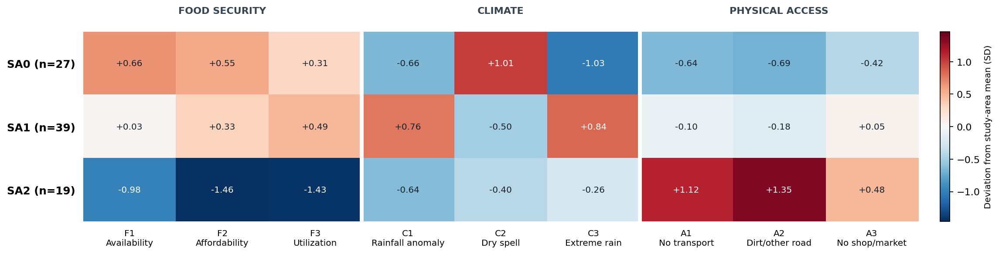


CELL 18 — PROFILE AUDIT COMPLETED
Districts assessed : 85
Frozen model       : Early_K3_G24_S10
Food indicators    : 3
Climate indicators : 3
Access indicators  : 3
Cluster refitted   : NO
Files saved        : NO


In [ ]:

# ==============================================================
# NOTEBOOK 07 — CELL 18
# FINAL FOOD-CENTRED TYPOLOGY PROFILE AUDIT
# ==============================================================
#
# Tujuan:
# 1. Verifikasi F1-F3 berdasarkan cluster final K=3
# 2. Periksa sembilan indikator secara konsisten
# 3. Bandingkan rerata dan median antarkelompok
# 4. Buat heatmap profil empiris (bukan centroid)
#
# Tidak menghitung ulang cluster.
# Tidak mengubah bobot view.
# Tidak menyimpan file.
# ==============================================================

from pathlib import Path
from IPython.display import display
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

MASTER_PATH = (
    ROOT / "01_data/01_raw"
    / "MATRIX_9VAR_CLUSTERING_85KAB_2025.csv"
)

LABELS_PATH = (
    ROOT / "03_outputs"
    / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
    / "labels_all.csv"
)

MODEL_ID = "Early_K3_G24_S10"

EXPECTED_HASH = (
    "ce932d322eb49cbdb6ea3b0a8768ca89c2e9"
    "e7f0722232883541d891089ca6fa"
)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

assert MASTER_PATH.is_file()
assert LABELS_PATH.is_file()
assert sha256(MASTER_PATH) == EXPECTED_HASH

FEATURES = [
    "F1_ikp_ketersediaan",
    "F2_ikp_keterjangkauan",
    "F3_ikp_pemanfaatan",
    "C1_anomali_hujan_mm",
    "C2_cdd_hari",
    "C3_hari_hujan_ekstrem",
    "A1_persen_tanpa_angkutan",
    "A2_persen_jalan_tanah_lainnya",
    "A3_persen_tanpa_pertokoan_pasar"
]

FOOD = FEATURES[:3]
CLIMATE = FEATURES[3:6]
ACCESS = FEATURES[6:9]

MASTER = pd.read_csv(
    MASTER_PATH,
    dtype={"kode_bps": str}
)

LABELS = pd.read_csv(
    LABELS_PATH,
    dtype={"kode_bps": str}
)

assert len(MASTER) == len(LABELS) == 85
assert MASTER["kode_bps"].is_unique
assert LABELS["kode_bps"].is_unique
assert MODEL_ID in LABELS.columns
assert set(FEATURES).issubset(MASTER.columns)

DATA = MASTER.merge(
    LABELS[["kode_bps", MODEL_ID]],
    on="kode_bps",
    validate="one_to_one"
).rename(columns={MODEL_ID: "cluster_SA"})

assert len(DATA) == 85
assert set(DATA["cluster_SA"]) == {0, 1, 2}

assert sorted(
    DATA["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]

# Verify that map memberships are still identical
# to the original frozen labels.

assert "GDF" in globals()
assert len(GDF) == 85

MAP_MEMBERSHIP = (
    GDF.assign(
        kode_bps=GDF["kode_bps"].astype(str)
    )
    .set_index("kode_bps")["cluster_SA"]
)

FROZEN_MEMBERSHIP = (
    DATA.set_index("kode_bps")["cluster_SA"]
)

assert (
    MAP_MEMBERSHIP.sort_index().astype(int)
    .equals(
        FROZEN_MEMBERSHIP
        .sort_index().astype(int)
    )
), "Keanggotaan peta tidak sesuai hasil clustering final."

DATA[FEATURES] = DATA[FEATURES].apply(
    pd.to_numeric, errors="raise"
)

assert np.isfinite(
    DATA[FEATURES].to_numpy(dtype=float)
).all()

# --------------------------------------------------------------
# A. CLUSTER SUMMARY IN ORIGINAL INDICATOR UNITS
# --------------------------------------------------------------

MEANS = DATA.groupby("cluster_SA")[FEATURES].mean()
MEDIANS = DATA.groupby("cluster_SA")[FEATURES].median()
Q25 = DATA.groupby("cluster_SA")[FEATURES].quantile(0.25)
Q75 = DATA.groupby("cluster_SA")[FEATURES].quantile(0.75)

COUNTS = (
    DATA["cluster_SA"]
    .value_counts()
    .sort_index()
)

FOOD_TABLE = pd.DataFrame({
    "indicator": FOOD,
    "SA0_mean": MEANS.loc[0, FOOD].values,
    "SA0_median": MEDIANS.loc[0, FOOD].values,
    "SA1_mean": MEANS.loc[1, FOOD].values,
    "SA1_median": MEDIANS.loc[1, FOOD].values,
    "SA2_mean": MEANS.loc[2, FOOD].values,
    "SA2_median": MEDIANS.loc[2, FOOD].values,
    "overall_mean": DATA[FOOD].mean().values
})

print("=" * 72)
print("A. FINAL F1-F3 FOOD SECURITY PROFILES")
print("=" * 72)
print("Interpretation: higher F scores = relatively better")
display(FOOD_TABLE.round(3))

PROFILE_TABLE = pd.DataFrame({
    "indicator": FEATURES,
    "view": (
        ["Food"] * 3
        + ["Climate"] * 3
        + ["Physical accessibility"] * 3
    ),
    "SA0_mean": MEANS.loc[0, FEATURES].values,
    "SA1_mean": MEANS.loc[1, FEATURES].values,
    "SA2_mean": MEANS.loc[2, FEATURES].values,
    "SA0_median": MEDIANS.loc[0, FEATURES].values,
    "SA1_median": MEDIANS.loc[1, FEATURES].values,
    "SA2_median": MEDIANS.loc[2, FEATURES].values
})

print("\nB. ALL NINE INDICATORS — ORIGINAL UNITS")
display(PROFILE_TABLE.round(3))

# --------------------------------------------------------------
# B. FOOD SECURITY RANKING DIAGNOSTIC
# --------------------------------------------------------------
# This is NOT a composite food-security index.
# It only checks the three original dimensions.
# --------------------------------------------------------------

FOOD_RANKING = pd.DataFrame({
    feature: (
        MEANS[feature]
        .sort_values(ascending=False)
        .index.tolist()
    )
    for feature in FOOD
}, index=[
    "Highest cluster mean",
    "Middle cluster mean",
    "Lowest cluster mean"
])

print("\nC. FOOD DIMENSION ORDERING")
print(
    "Cluster numbers represent membership identities, "
    "not vulnerability ranks."
)
display(FOOD_RANKING)

# --------------------------------------------------------------
# C. STANDARDIZED POST-CLUSTERING PROFILES
# --------------------------------------------------------------
# Standardized against all 85 districts.
# Negative z = below study-area mean.
# Positive z = above study-area mean.
#
# IMPORTANT:
# For F indicators, lower generally means weaker.
# For A indicators, higher generally means worse.
# For C1, positive means wetter than the baseline,
# not automatically more vulnerable.
# --------------------------------------------------------------

GLOBAL_MEAN = DATA[FEATURES].mean()
GLOBAL_SD = DATA[FEATURES].std(ddof=1)

assert (GLOBAL_SD > 0).all()

Z_PROFILE = (
    (MEANS[FEATURES] - GLOBAL_MEAN)
    / GLOBAL_SD
)

assert Z_PROFILE.shape == (3, 9)

print("\nD. STANDARDIZED NINE-INDICATOR PROFILES")
display(Z_PROFILE.round(3))

# --------------------------------------------------------------
# D. HEATMAP
# --------------------------------------------------------------

heat = Z_PROFILE.loc[
    [0, 1, 2], FEATURES
].to_numpy()

limit = max(
    1.0,
    float(np.abs(heat).max())
)

FIG_LABELS = [
    "F1\nAvailability",
    "F2\nAffordability",
    "F3\nUtilization",
    "C1\nRainfall anomaly",
    "C2\nDry spell",
    "C3\nExtreme rain",
    "A1\nNo transport",
    "A2\nDirt/other road",
    "A3\nNo shop/market"
]

fig, ax = plt.subplots(
    figsize=(15, 4.7),
    dpi=160,
    facecolor="white"
)

im = ax.imshow(
    heat,
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    aspect="auto"
)

ax.set_xticks(range(9))
ax.set_xticklabels(
    FIG_LABELS,
    fontsize=9
)

ax.set_yticks([0, 1, 2])
ax.set_yticklabels(
    [
        f"SA0 (n={COUNTS.loc[0]})",
        f"SA1 (n={COUNTS.loc[1]})",
        f"SA2 (n={COUNTS.loc[2]})"
    ],
    fontsize=11,
    fontweight="bold"
)

for row in range(3):
    for col in range(9):
        val = heat[row, col]

        ax.text(
            col, row,
            f"{val:+.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color=(
                "white"
                if abs(val) >= limit * 0.55
                else "#17212B"
            )
        )

# View boundaries
ax.axvline(2.5, color="white", linewidth=4)
ax.axvline(5.5, color="white", linewidth=4)

# Group headings
for xpos, label in [
    (1, "FOOD SECURITY"),
    (4, "CLIMATE"),
    (7, "PHYSICAL ACCESS")
]:
    ax.text(
        xpos, -0.83,
        label,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="#354552",
        clip_on=False
    )

ax.tick_params(
    axis="both",
    length=0,
    pad=8
)

for spine in ax.spines.values():
    spine.set_visible(False)

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.025,
    pad=0.025
)

cbar.set_label(
    "Deviation from study-area mean (SD)",
    fontsize=9
)

fig.subplots_adjust(
    left=0.12,
    right=0.96,
    top=0.81,
    bottom=0.23
)

plt.show()

print("\n" + "=" * 72)
print("CELL 18 — PROFILE AUDIT COMPLETED")
print("=" * 72)
print("Districts assessed :", len(DATA))
print("Frozen model       :", MODEL_ID)
print("Food indicators    :", len(FOOD))
print("Climate indicators :", len(CLIMATE))
print("Access indicators  :", len(ACCESS))
print("Cluster refitted   : NO")
print("Files saved        : NO")
print("=" * 72)


# Audit IKP dan peta ketahanan pangan

A. SEARCH FOR ANALYSIS MASTER
Found: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/01_data/01_raw/MASTER_ANALISIS_85KAB_2025_v1.csv

Selected source: /content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/01_data/01_raw/MASTER_ANALISIS_85KAB_2025_v1.csv

B. NINE-INDICATOR INTEGRITY AUDIT


,indicator,maximum_absolute_difference
0,F1_ikp_ketersediaan,0.000000e+00
1,F2_ikp_keterjangkauan,0.000000e+00
2,F3_ikp_pemanfaatan,0.000000e+00
3,C1_anomali_hujan_mm,4.547474e-13
4,C2_cdd_hari,0.000000e+00
5,C3_hari_hujan_ekstrem,3.552714e-15
6,A1_persen_tanpa_angkutan,0.000000e+00
7,A2_persen_jalan_tanah_lainnya,3.552714e-15
8,A3_persen_tanpa_pertokoan_pasar,0.000000e+00


All original indicators: VERIFIED

C. IKP SOURCE AND COVERAGE
Analysis master: MASTER_ANALISIS_85KAB_2025_v1.csv
Matched BPS codes : 85
Matched GAUL codes: 85
Indicator agreement: 9/9
IKP values present : 85

D. IKP DISTRIBUTION


,IKP 2025
count,85.000
mean,51.545
std,11.445
min,19.930
25%,46.170
50%,55.090
75%,59.560
max,67.430



E. IKP BY FROZEN STABILITY-AWARE CLUSTER


,n,mean,median,std,minimum,maximum
cluster_SA,,,,,,
0,27,58.332,58.57,4.194,49.22,67.43
1,39,55.365,56.22,6.782,42.40,67.31
2,19,34.060,33.09,8.081,19.93,46.97


... (2 outputs left out)


G. DISTRICTS WITH LOWEST IKP


,kode_bps,provinsi,kabupaten_kota,cluster_SA,IKP_MAP,IKP_2025_status_noninput
71,9508,Papua Pegunungan,Nduga,2,19.93,Sangat Rentan
83,9405,Papua Tengah,Puncak,2,23.75,Sangat Rentan
70,9505,Papua Pegunungan,Mamberamo Tengah,2,26.40,Sangat Rentan
82,9403,Papua Tengah,Paniai,2,27.27,Sangat Rentan
81,9407,Papua Tengah,Intan Jaya,2,27.34,Sangat Rentan
73,9503,Papua Pegunungan,Yahukimo,2,27.41,Sangat Rentan
79,9408,Papua Tengah,Deiyai,2,28.96,Sangat Rentan
72,9504,Papua Pegunungan,Tolikara,2,31.11,Sangat Rentan
67,9507,Papua Pegunungan,Lanny Jaya,2,31.51,Sangat Rentan
41,9212,Papua Barat,Pegunungan Arfak,2,33.09,Sangat Rentan



H. DISTRICTS WITH HIGHEST IKP


,kode_bps,provinsi,kabupaten_kota,cluster_SA,IKP_MAP,IKP_2025_status_noninput
44,9202,Papua Barat,Manokwari,0,67.43,Agak Tahan
55,8206,Maluku Utara,Halmahera Timur,1,67.31,Agak Tahan
39,9208,Papua Barat,Kaimana,1,66.38,Agak Tahan
78,9301,Papua Selatan,Merauke,1,65.56,Agak Tahan
63,9103,Papua,Jayapura,0,64.83,Agak Tahan
28,5309,Nusa Tenggara Timur,Ngada,0,64.71,Agak Tahan
57,8271,Maluku Utara,Kota Ternate,1,64.26,Agak Tahan
7,8171,Maluku,Kota Ambon,1,63.53,Agak Tahan
58,8207,Maluku Utara,Pulau Morotai,1,63.34,Agak Tahan
18,5308,Nusa Tenggara Timur,Ende,0,63.06,Agak Tahan


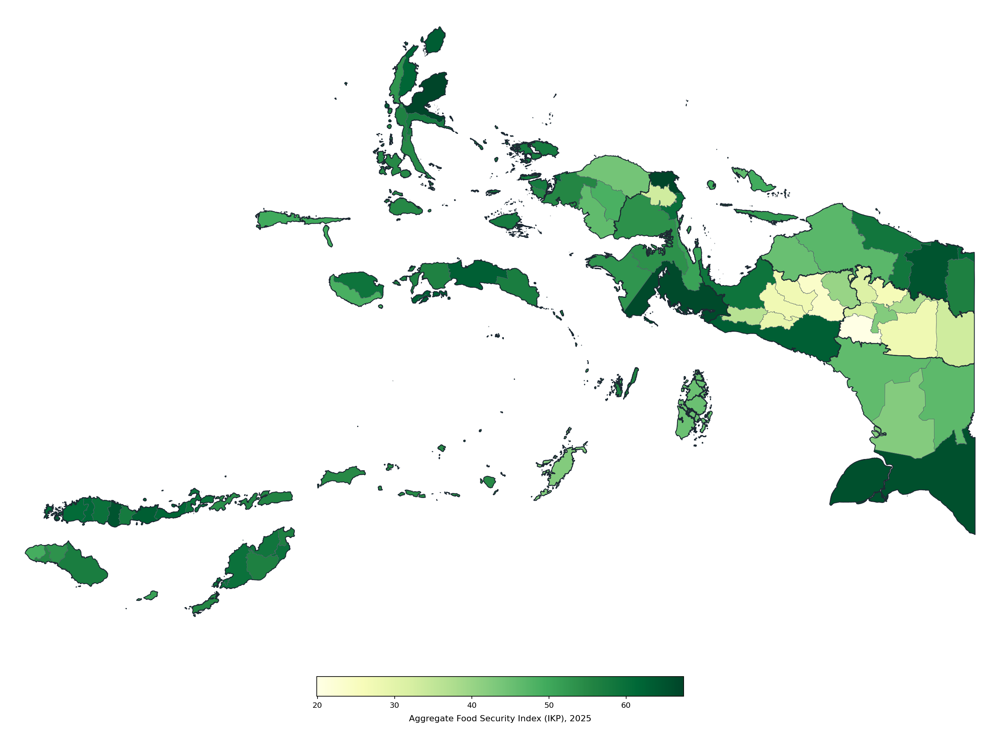


CELL 19 — FOOD SECURITY MAP COMPLETED
Mapped districts   : 85
Mapped provinces   : 9
IKP observed range : 19.93 to 67.43
Exact BPS join     : VERIFIED
GAUL crosswalk     : VERIFIED
Nine indicators    : VERIFIED
Frozen clustering  : UNCHANGED
New model fitting  : NO
Files saved        : NO


In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 19 (REVISED)
# JOIN 2025 AGGREGATE IKP TO VERIFIED 85-DISTRICT MAP
# ================================================================
#
# Spatial source:
#   GDF from Cell 16R
#
# Food-security source:
#   MASTER_ANALISIS_85KAB_2025_v1.csv
#
# Controls:
#   - 85 exact BPS matches
#   - 85 exact GAUL crosswalk matches
#   - identical 9 clustering indicators
#   - verified data year = 2025
#   - no missing IKP values
#   - frozen cluster membership unchanged
#
# No new index construction.
# No clustering refitting.
# No automatic file saving.
# ================================================================

from pathlib import Path
from google.colab import files as colab_files
from IPython.display import display

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib as mpl


# ================================================================
# A. VERIFY ORIGINAL SPATIAL DATA
# ================================================================

assert "GDF" in globals(), (
    "GDF belum tersedia. Jalankan Cell 16R dahulu."
)

assert len(GDF) == 85
assert GDF["kode_bps"].is_unique
assert GDF["kode_gaul2"].is_unique
assert GDF.geometry.notna().all()
assert GDF.geometry.is_valid.all()

assert sorted(
    GDF["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]


# ================================================================
# B. FIND THE CORRECT ANALYSIS MASTER
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

FILENAME = "MASTER_ANALISIS_85KAB_2025_v1.csv"

# Optional: specify exact path if already known.
MASTER_ANALYSIS_PATH = None

if MASTER_ANALYSIS_PATH is None:

    candidate_paths = []

    local = Path("/content") / FILENAME

    if local.is_file():
        candidate_paths.append(local)

    if ROOT.is_dir():

        candidate_paths.extend(
            ROOT.rglob(FILENAME)
        )

    candidate_paths = sorted(
        set(candidate_paths),
        key=lambda p: str(p)
    )

    print("=" * 70)
    print("A. SEARCH FOR ANALYSIS MASTER")
    print("=" * 70)

    for path in candidate_paths:
        print("Found:", path)

    if len(candidate_paths) == 1:

        MASTER_ANALYSIS_PATH = candidate_paths[0]

    elif len(candidate_paths) > 1:

        # Multiple copies: verify whether byte-identical.
        import hashlib

        def checksum(path):
            h = hashlib.sha256()
            with open(path, "rb") as f:
                for part in iter(
                    lambda: f.read(1048576), b""
                ):
                    h.update(part)
            return h.hexdigest()

        hashes = {
            checksum(p)
            for p in candidate_paths
        }

        if len(hashes) != 1:
            raise RuntimeError(
                "Ditemukan beberapa master analisis "
                "dengan isi berbeda. Tentukan path "
                "yang benar secara eksplisit."
            )

        MASTER_ANALYSIS_PATH = candidate_paths[0]

    else:

        print(
            "\nMaster analisis belum ditemukan "
            "pada folder proyek."
        )

        print(
            "Upload MASTER_ANALISIS_85KAB_2025_v1.csv "
            "dari komputer."
        )

        uploaded = colab_files.upload()

        assert len(uploaded) == 1
        assert FILENAME in uploaded, (
            "File yang diunggah harus bernama "
            f"{FILENAME}"
        )

        MASTER_ANALYSIS_PATH = (
            Path("/content") / FILENAME
        )

        assert MASTER_ANALYSIS_PATH.is_file()

        del uploaded

MASTER_ANALYSIS_PATH = Path(
    MASTER_ANALYSIS_PATH
)

assert MASTER_ANALYSIS_PATH.is_file()

print("\nSelected source:", MASTER_ANALYSIS_PATH)


# ================================================================
# C. READ AND VERIFY ANALYSIS MASTER
# ================================================================

FULL = pd.read_csv(
    MASTER_ANALYSIS_PATH,
    dtype={
        "kode_bps": "string",
        "kode_gaul2": "string"
    },
    low_memory=False
)

REQUIRED = [
    "tahun",
    "kode_bps",
    "kode_gaul2",
    "IKP_2025_agregat_noninput",
    "IKP_2025_kelompok_noninput",
    "IKP_2025_status_noninput"
]

missing_columns = [
    c for c in REQUIRED
    if c not in FULL.columns
]

assert not missing_columns, (
    f"Master analisis kehilangan kolom: "
    f"{missing_columns}"
)

assert len(FULL) == 85
assert FULL["kode_bps"].is_unique
assert FULL["kode_gaul2"].is_unique

FULL["kode_bps"] = (
    FULL["kode_bps"]
    .str.strip()
    .str.replace(r"\.0+$", "", regex=True)
)

FULL["kode_gaul2"] = (
    FULL["kode_gaul2"]
    .str.strip()
    .str.replace(r"\.0+$", "", regex=True)
)

assert FULL["kode_bps"].notna().all()
assert FULL["kode_gaul2"].notna().all()

assert pd.to_numeric(
    FULL["tahun"],
    errors="raise"
).eq(2025).all()

# The two masters must describe exactly the same
# districts and GAUL/BPS identities.

SPATIAL_KEYS = GDF[
    ["kode_bps", "kode_gaul2"]
].copy()

SPATIAL_KEYS["kode_bps"] = (
    SPATIAL_KEYS["kode_bps"].astype("string")
)

SPATIAL_KEYS["kode_gaul2"] = (
    SPATIAL_KEYS["kode_gaul2"].astype("string")
)

assert set(FULL["kode_bps"]) == set(
    SPATIAL_KEYS["kode_bps"]
)

CROSSWALK = SPATIAL_KEYS.merge(
    FULL[
        ["kode_bps", "kode_gaul2"]
    ],
    on="kode_bps",
    suffixes=("_spatial", "_analysis"),
    validate="one_to_one"
)

assert len(CROSSWALK) == 85

assert (
    CROSSWALK["kode_gaul2_spatial"]
    == CROSSWALK["kode_gaul2_analysis"]
).all()


# ================================================================
# D. VERIFY ORIGINAL NINE CLUSTERING INDICATORS
# ================================================================
#
# This verifies that the analysis master and
# clustering master use the same input data.
#
# Never recompute the clustering.
# ================================================================

FEATURES = [
    "F1_ikp_ketersediaan",
    "F2_ikp_keterjangkauan",
    "F3_ikp_pemanfaatan",
    "C1_anomali_hujan_mm",
    "C2_cdd_hari",
    "C3_hari_hujan_ekstrem",
    "A1_persen_tanpa_angkutan",
    "A2_persen_jalan_tanah_lainnya",
    "A3_persen_tanpa_pertokoan_pasar"
]

assert set(FEATURES).issubset(FULL.columns)
assert set(FEATURES).issubset(GDF.columns)

REFERENCE_VALUES = GDF[
    ["kode_bps"] + FEATURES
].copy()

REFERENCE_VALUES["kode_bps"] = (
    REFERENCE_VALUES["kode_bps"].astype("string")
)

COMPARE = REFERENCE_VALUES.merge(
    FULL[
        ["kode_bps"] + FEATURES
    ],
    on="kode_bps",
    suffixes=("_frozen", "_analysis"),
    validate="one_to_one"
)

assert len(COMPARE) == 85

INDICATOR_AUDIT = []

for feature in FEATURES:

    left = pd.to_numeric(
        COMPARE[f"{feature}_frozen"],
        errors="raise"
    ).to_numpy(dtype=float)

    right = pd.to_numeric(
        COMPARE[f"{feature}_analysis"],
        errors="raise"
    ).to_numpy(dtype=float)

    assert np.isfinite(left).all()
    assert np.isfinite(right).all()

    max_diff = float(
        np.max(np.abs(left - right))
    )

    INDICATOR_AUDIT.append({
        "indicator": feature,
        "maximum_absolute_difference": max_diff
    })

    assert np.allclose(
        left, right,
        rtol=0,
        atol=1e-8
    ), (
        f"Indicator mismatch: {feature}. "
        "Periksa versi master analisis."
    )

print("\nB. NINE-INDICATOR INTEGRITY AUDIT")
display(
    pd.DataFrame(
        INDICATOR_AUDIT
    )
)

print("All original indicators: VERIFIED")


# ================================================================
# E. ATTACH IKP AND NON-INPUT COLUMNS TO GDF
# ================================================================

SOURCE_COLUMNS = [
    "kode_bps",
    "IKP_2025_agregat_noninput",
    "IKP_2025_kelompok_noninput",
    "IKP_2025_status_noninput"
]

if "penduduk_2025_jiwa_noninput" in FULL.columns:
    SOURCE_COLUMNS.append(
        "penduduk_2025_jiwa_noninput"
    )

SPATIAL = GDF.copy()

SPATIAL["kode_bps"] = (
    SPATIAL["kode_bps"].astype("string")
)

# Avoid overwriting previously attached fields.
assert not (
    set(SOURCE_COLUMNS) - {"kode_bps"}
).intersection(SPATIAL.columns), (
    "Kolom IKP sudah ada pada GDF. "
    "Periksa apakah Cell 19 sudah dijalankan."
)

FOOD_MAP = SPATIAL.merge(
    FULL[SOURCE_COLUMNS],
    on="kode_bps",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert FOOD_MAP["_merge"].eq("both").all()

FOOD_MAP = gpd.GeoDataFrame(
    FOOD_MAP.drop(columns="_merge"),
    geometry=GDF.geometry.name,
    crs=GDF.crs
)

assert len(FOOD_MAP) == 85
assert FOOD_MAP["kode_bps"].is_unique

FOOD_MAP["IKP_MAP"] = pd.to_numeric(
    FOOD_MAP["IKP_2025_agregat_noninput"],
    errors="coerce"
)

assert FOOD_MAP["IKP_MAP"].notna().all()
assert np.isfinite(FOOD_MAP["IKP_MAP"]).all()

assert FOOD_MAP["IKP_MAP"].between(
    0, 100
).all()

assert FOOD_MAP["IKP_MAP"].nunique() > 1

# Verify that frozen clustering is not modified.
assert (
    FOOD_MAP.set_index("kode_bps")["cluster_SA"]
    .sort_index()
    .equals(
        SPATIAL.set_index("kode_bps")["cluster_SA"]
        .sort_index()
    )
)


# ================================================================
# F. SUBSTANTIVE FOOD SECURITY DIAGNOSTICS
# ================================================================

print("\n" + "=" * 70)
print("C. IKP SOURCE AND COVERAGE")
print("=" * 70)

print("Analysis master:", MASTER_ANALYSIS_PATH.name)
print("Matched BPS codes :", len(FOOD_MAP))
print("Matched GAUL codes:", len(CROSSWALK))
print("Indicator agreement: 9/9")
print("IKP values present :", FOOD_MAP["IKP_MAP"].notna().sum())

print("\nD. IKP DISTRIBUTION")
display(
    FOOD_MAP["IKP_MAP"]
    .describe()
    .to_frame("IKP 2025")
    .round(3)
)

print("\nE. IKP BY FROZEN STABILITY-AWARE CLUSTER")

IKP_BY_CLUSTER = (
    FOOD_MAP.groupby("cluster_SA")["IKP_MAP"]
    .agg(
        n="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
)

display(IKP_BY_CLUSTER.round(3))

print("\nF. RECORDED IKP STATUS BY CLUSTER")

display(
    pd.crosstab(
        FOOD_MAP["cluster_SA"],
        FOOD_MAP["IKP_2025_status_noninput"],
        margins=True
    )
)

print("\nG. DISTRICTS WITH LOWEST IKP")

display(
    FOOD_MAP.nsmallest(
        10, "IKP_MAP"
    )[
        [
            "kode_bps",
            "provinsi",
            "kabupaten_kota",
            "cluster_SA",
            "IKP_MAP",
            "IKP_2025_status_noninput"
        ]
    ]
)

print("\nH. DISTRICTS WITH HIGHEST IKP")

display(
    FOOD_MAP.nlargest(
        10, "IKP_MAP"
    )[
        [
            "kode_bps",
            "provinsi",
            "kabupaten_kota",
            "cluster_SA",
            "IKP_MAP",
            "IKP_2025_status_noninput"
        ]
    ]
)


# ================================================================
# G. SINGLE CONTINUOUS IKP MAP
# ================================================================
#
# Map directly represents aggregate IKP values.
# Colours are continuous, not clustering labels.
#
# Plot only: no title or footnotes.
# ================================================================

M = FOOD_MAP.to_crs("EPSG:3857").copy()

PROV = M.dissolve(
    by="provinsi",
    as_index=False
)

xmin, ymin, xmax, ymax = M.total_bounds

xspan = xmax - xmin
yspan = ymax - ymin

pad_x = 0.02 * xspan
pad_y = 0.035 * yspan

XMIN = xmin - pad_x
XMAX = xmax + pad_x
YMIN = ymin - pad_y
YMAX = ymax + pad_y

map_ratio = (
    (XMAX - XMIN)
    / (YMAX - YMIN)
)

FIG_WIDTH = 16.5
AX_LEFT = 0.015
AX_WIDTH = 0.970
AX_BOTTOM = 0.145
AX_HEIGHT = 0.835

FIG_HEIGHT = (
    FIG_WIDTH * AX_WIDTH
    / (map_ratio * AX_HEIGHT)
)

fig = plt.figure(
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    dpi=160,
    facecolor="white"
)

ax = fig.add_axes([
    AX_LEFT,
    AX_BOTTOM,
    AX_WIDTH,
    AX_HEIGHT
])

# Use observed range to reveal district variation.
# The colourbar shows actual IKP values.
vmin = float(M["IKP_MAP"].min())
vmax = float(M["IKP_MAP"].max())

norm = mpl.colors.Normalize(
    vmin=vmin,
    vmax=vmax
)

cmap = mpl.colormaps["YlGn"]

M.plot(
    ax=ax,
    column="IKP_MAP",
    cmap=cmap,
    norm=norm,
    edgecolor="#53616A",
    linewidth=0.38,
    legend=False,
    zorder=2
)

PROV.boundary.plot(
    ax=ax,
    color="#1D2933",
    linewidth=0.95,
    zorder=3
)

ax.set_xlim(XMIN, XMAX)
ax.set_ylim(YMIN, YMAX)

ax.set_aspect("equal")
ax.set_axis_off()

# Compact continuous legend below the map.
cax = fig.add_axes([
    0.32,
    0.067,
    0.36,
    0.026
])

sm = mpl.cm.ScalarMappable(
    norm=norm,
    cmap=cmap
)

sm.set_array([])

cb = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

cb.set_label(
    "Aggregate Food Security Index (IKP), 2025",
    fontsize=10,
    labelpad=7
)

cb.ax.tick_params(
    labelsize=9,
    length=3
)

plt.show()


# ================================================================
# H. COMPLETION GATE
# ================================================================

print("\n" + "=" * 70)
print("CELL 19 — FOOD SECURITY MAP COMPLETED")
print("=" * 70)

print("Mapped districts   :", len(M))
print("Mapped provinces   :", M["provinsi"].nunique())
print("IKP observed range :", round(vmin, 3),
      "to", round(vmax, 3))
print("Exact BPS join     : VERIFIED")
print("GAUL crosswalk     : VERIFIED")
print("Nine indicators    : VERIFIED")
print("Frozen clustering  : UNCHANGED")
print("New model fitting  : NO")
print("Files saved        : NO")
print("=" * 70)


In [ ]:

# ============================================================
# NOTEBOOK 07 — CELL 20
# FOOD SECURITY HETEROGENEITY WITHIN REGIONAL TYPOLOGIES
# ============================================================
#
# Tujuan:
# - Memeriksa komposisi status IKP setiap tipologi
# - Mengidentifikasi wilayah Rentan/Sangat Rentan
# - Menelaah pengecualian dalam SA0 dan SA1
# - Menganalisis konsentrasi berdasarkan provinsi
# - Memeriksa konsistensi kelompok/status IKP
#
# Tidak ada model baru.
# Tidak ada kategori status baru.
# Tidak ada file yang disimpan.
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

assert "FOOD_MAP" in globals(), (
    "FOOD_MAP tidak ditemukan. "
    "Jalankan Cell 19 revisi terlebih dahulu."
)

D = FOOD_MAP.copy()

IKP = "IKP_MAP"
STATUS = "IKP_2025_status_noninput"
GROUP = "IKP_2025_kelompok_noninput"

assert len(D) == 85
assert D["kode_bps"].is_unique
assert D["provinsi"].nunique() == 9

assert sorted(
    D["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]

assert D[IKP].notna().all()
assert D[STATUS].notna().all()
assert D[GROUP].notna().all()

STATUS_ORDER = [
    "Sangat Rentan",
    "Rentan",
    "Agak Rentan",
    "Agak Tahan"
]

assert set(D[STATUS]) == set(STATUS_ORDER)

D["status_ordered"] = pd.Categorical(
    D[STATUS],
    categories=STATUS_ORDER,
    ordered=True
)

D["kelompok_numeric"] = pd.to_numeric(
    D[GROUP], errors="raise"
)

# ------------------------------------------------------------
# A. VERIFY EXISTING IKP CATEGORY MAPPING
# ------------------------------------------------------------

CATEGORY_MAPPING = (
    D.groupby(
        ["kelompok_numeric", STATUS],
        observed=True
    )
    .size()
    .reset_index(name="n_districts")
    .sort_values("kelompok_numeric")
)

print("=" * 70)
print("A. RECORDED IKP CATEGORY MAPPING")
print("=" * 70)
display(CATEGORY_MAPPING)

assert (
    CATEGORY_MAPPING["kelompok_numeric"].nunique()
    == len(CATEGORY_MAPPING)
)

assert (
    CATEGORY_MAPPING[STATUS].nunique()
    == len(CATEGORY_MAPPING)
)

# ------------------------------------------------------------
# B. STATUS COMPOSITION
# ------------------------------------------------------------

COUNTS = pd.crosstab(
    D["cluster_SA"],
    D["status_ordered"]
).reindex(
    index=[0, 1, 2],
    columns=STATUS_ORDER,
    fill_value=0
)

PERCENT = (
    COUNTS.div(
        COUNTS.sum(axis=1),
        axis=0
    ) * 100
)

assert COUNTS.to_numpy().sum() == 85

print("\nB. IKP STATUS COUNTS")
display(COUNTS)

print("\nC. WITHIN-TYPOLOGY PERCENTAGES")
display(PERCENT.round(2))

# ------------------------------------------------------------
# C. EXISTING FOOD-VULNERABILITY FLAGS
# ------------------------------------------------------------
#
# This flag is descriptive.
# It combines TWO categories ALREADY recorded
# in the analysis master.
#
# It is not a newly estimated index.
# ------------------------------------------------------------

D["recorded_vulnerable"] = D[STATUS].isin([
    "Rentan", "Sangat Rentan"
])

CONCERN = (
    D.groupby("cluster_SA")
    .agg(
        n_districts=("kode_bps", "size"),
        n_recorded_vulnerable=(
            "recorded_vulnerable", "sum"
        ),
        mean_IKP=(IKP, "mean"),
        median_IKP=(IKP, "median"),
        min_IKP=(IKP, "min"),
        max_IKP=(IKP, "max")
    )
)

CONCERN["pct_recorded_vulnerable"] = (
    100 * CONCERN["n_recorded_vulnerable"]
    / CONCERN["n_districts"]
)

print("\nD. FOOD-VULNERABILITY COMPOSITION BY TYPOLOGY")
display(CONCERN.round(3))

# ------------------------------------------------------------
# D. IDENTIFY VULNERABLE DISTRICTS IN SA0 AND SA1
# ------------------------------------------------------------

COLUMNS = [
    "kode_bps",
    "provinsi",
    "kabupaten_kota",
    "cluster_SA",
    "IKP_MAP",
    "IKP_2025_status_noninput"
]

SA0_ATTENTION = D.loc[
    (D["cluster_SA"] == 0)
    & D["recorded_vulnerable"],
    COLUMNS
].sort_values("IKP_MAP")

SA1_ATTENTION = D.loc[
    (D["cluster_SA"] == 1)
    & D["recorded_vulnerable"],
    COLUMNS
].sort_values("IKP_MAP")

SA2_FOOD = D.loc[
    D["cluster_SA"] == 2,
    COLUMNS
].sort_values("IKP_MAP")

assert len(SA0_ATTENTION) == 3
assert len(SA1_ATTENTION) == 16
assert len(SA2_FOOD) == 19

print("\nE. SA0 — THREE RECORDED-VULNERABLE DISTRICTS")
display(SA0_ATTENTION)

print("\nF. SA1 — SIXTEEN RECORDED-VULNERABLE DISTRICTS")
display(SA1_ATTENTION)

print("\nG. SA2 — ALL NINETEEN DISTRICTS")
display(SA2_FOOD)

# ------------------------------------------------------------
# E. GEOGRAPHIC CONCENTRATION OF VULNERABLE STATUS
# ------------------------------------------------------------

PROVINCE_DIAGNOSTIC = (
    D.groupby(
        ["provinsi", "cluster_SA"],
        as_index=False
    )
    .agg(
        n_districts=("kode_bps", "size"),
        n_recorded_vulnerable=(
            "recorded_vulnerable", "sum"
        ),
        mean_IKP=(IKP, "mean")
    )
)

PROVINCE_DIAGNOSTIC["pct_vulnerable"] = (
    100
    * PROVINCE_DIAGNOSTIC["n_recorded_vulnerable"]
    / PROVINCE_DIAGNOSTIC["n_districts"]
)

print("\nH. PROVINCE × TYPOLOGY × FOOD SECURITY")
display(
    PROVINCE_DIAGNOSTIC.sort_values(
        ["provinsi", "cluster_SA"]
    ).round(2)
)

# ------------------------------------------------------------
# F. IKP VARIATION WITHIN THE SAME RECORDED STATUS
# ------------------------------------------------------------

WITHIN_STATUS = (
    D.groupby(
        ["status_ordered", "cluster_SA"],
        observed=True
    )
    .agg(
        n=("kode_bps", "size"),
        min_IKP=(IKP, "min"),
        median_IKP=(IKP, "median"),
        max_IKP=(IKP, "max")
    )
    .reset_index()
)

print("\nI. IKP VARIATION WITHIN RECORDED STATUS")
display(WITHIN_STATUS.round(2))

print("\n" + "=" * 70)
print("CELL 20 — SUBSTANTIVE FOOD-SECURITY AUDIT")
print("=" * 70)
print("Districts:", len(D))
print("Existing IKP categories: VERIFIED")
print("Vulnerable-status districts:",
      int(D["recorded_vulnerable"].sum()))
print("SA0 vulnerable:", len(SA0_ATTENTION))
print("SA1 vulnerable:", len(SA1_ATTENTION))
print("SA2 districts:", len(SA2_FOOD))
print("New clustering fits: 0")
print("Files saved: 0")
print("=" * 70)


A. RECORDED IKP CATEGORY MAPPING


,kelompok_numeric,IKP_2025_status_noninput,n_districts
0,1,Sangat Rentan,20
1,2,Rentan,18
2,3,Agak Rentan,31
3,4,Agak Tahan,16



B. IKP STATUS COUNTS


status_ordered,Sangat Rentan,Rentan,Agak Rentan,Agak Tahan
cluster_SA,,,,
0,0,3,18,6
1,3,13,13,10
2,17,2,0,0



C. WITHIN-TYPOLOGY PERCENTAGES


status_ordered,Sangat Rentan,Rentan,Agak Rentan,Agak Tahan
cluster_SA,,,,
0,0.00,11.11,66.67,22.22
1,7.69,33.33,33.33,25.64
2,89.47,10.53,0.00,0.00


... (9 outputs left out)

,provinsi,cluster_SA,n_districts,n_recorded_vulnerable,mean_IKP,pct_vulnerable
0,Maluku,0,1,0,54.72,0.00
1,Maluku,1,10,4,54.20,40.00
2,Maluku Utara,1,10,3,57.84,30.00
3,Nusa Tenggara Timur,0,22,3,57.75,13.64
4,Papua,0,3,0,60.79,0.00
5,Papua,1,4,3,51.66,75.00
6,Papua,2,2,2,46.16,100.00
7,Papua Barat,0,1,0,67.43,0.00
8,Papua Barat,1,5,2,56.75,40.00
9,Papua Barat,2,1,1,33.09,100.00



I. IKP VARIATION WITHIN RECORDED STATUS


,status_ordered,cluster_SA,n,min_IKP,median_IKP,max_IKP
0,Sangat Rentan,1,3,42.40,44.22,45.16
1,Sangat Rentan,2,17,19.93,31.51,45.34
2,Rentan,0,3,49.22,51.43,53.38
3,Rentan,1,13,46.13,49.69,53.10
4,Rentan,2,2,46.17,46.57,46.97
5,Agak Rentan,0,18,54.25,57.34,61.21
6,Agak Rentan,1,13,53.61,56.94,59.85
7,Agak Tahan,0,6,61.54,63.88,67.43
8,Agak Tahan,1,10,61.81,63.44,67.31



CELL 20 — SUBSTANTIVE FOOD-SECURITY AUDIT
Districts: 85
Existing IKP categories: VERIFIED
Vulnerable-status districts: 38
SA0 vulnerable: 3
SA1 vulnerable: 16
SA2 districts: 19
New clustering fits: 0
Files saved: 0


# Peta status IKP dan wilayah rentan di luar SA2

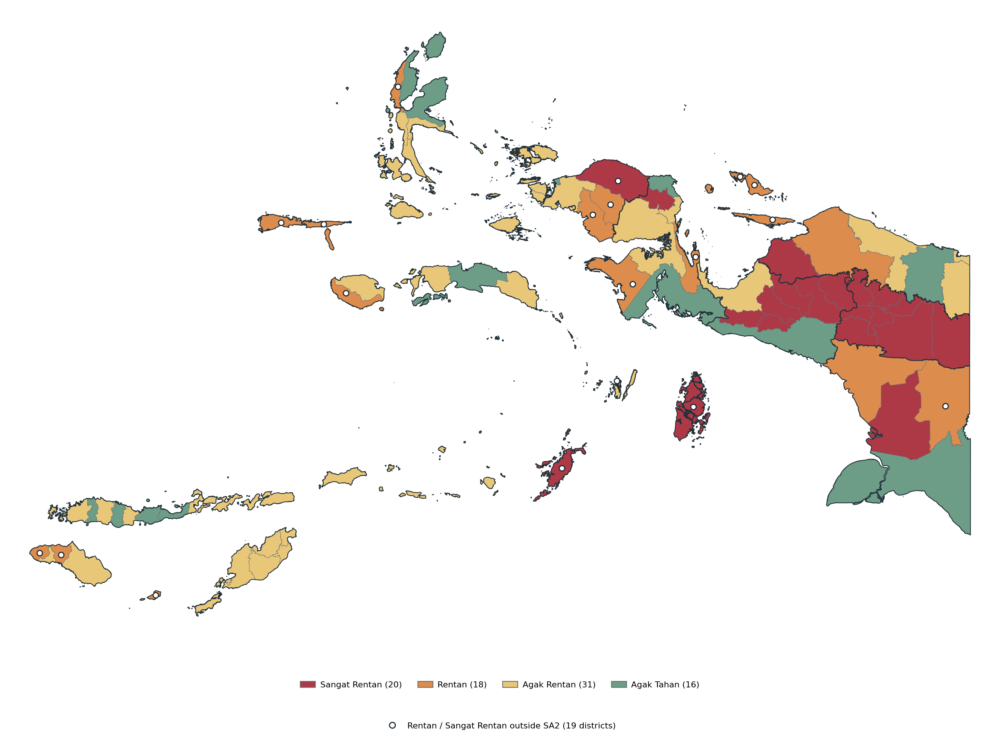

CELL 21 — FOOD SECURITY STATUS MAP
Mapped districts      : 85
Recorded vulnerable   : 38
Vulnerable in SA2     : 19
Vulnerable outside SA2: 19
  SA0                 : 3
  SA1                 : 16
New cluster fits      : 0
New index constructed : NO
Files saved           : NO

STATUS BY CLUSTER


IKP_2025_status_noninput,Sangat Rentan,Rentan,Agak Rentan,Agak Tahan
cluster_SA,,,,
0,0,3,18,6
1,3,13,13,10
2,17,2,0,0


In [ ]:

# ============================================================
# NOTEBOOK 07 — CELL 21
# FOOD SECURITY STATUS MAP + CROSS-TYPOLOGY ATTENTION
# ============================================================
#
# Peta tunggal Indonesia Timur:
# - Fill: status IKP 2025 yang tercatat di master
# - Hollow circles: Rentan/Sangat Rentan outside SA2
# - District and province boundaries
# - No title, subtitle, annotation, or footer
# - Compact legend below the map
#
# No new food-security categories.
# No new clustering.
# No saved files.
# ============================================================

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from IPython.display import display

# ------------------------------------------------------------
# A. VERIFY THE CELL 19 AND CELL 20 RESULTS
# ------------------------------------------------------------

assert "FOOD_MAP" in globals(), (
    "FOOD_MAP belum tersedia. "
    "Jalankan Cell 19 terlebih dahulu."
)

F = FOOD_MAP.copy()

STATUS_COL = "IKP_2025_status_noninput"

assert len(F) == 85
assert F["kode_bps"].is_unique
assert F.geometry.notna().all()
assert F.geometry.is_valid.all()
assert F["provinsi"].nunique() == 9

assert sorted(
    F["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]

STATUS_ORDER = [
    "Sangat Rentan",
    "Rentan",
    "Agak Rentan",
    "Agak Tahan"
]

assert set(F[STATUS_COL]) == set(STATUS_ORDER)

STATUS_COUNTS = F[STATUS_COL].value_counts()

assert [
    int(STATUS_COUNTS[s])
    for s in STATUS_ORDER
] == [20, 18, 31, 16]

# ------------------------------------------------------------
# B. VERIFY THE POLICY-RELEVANT OVERLAY
# ------------------------------------------------------------

F["recorded_vulnerable"] = F[STATUS_COL].isin(
    ["Sangat Rentan", "Rentan"]
)

F["vulnerable_outside_SA2"] = (
    F["recorded_vulnerable"]
    & F["cluster_SA"].isin([0, 1])
)

assert int(F["recorded_vulnerable"].sum()) == 38

assert int(
    F["vulnerable_outside_SA2"].sum()
) == 19

assert int((
    F["vulnerable_outside_SA2"]
    & F["cluster_SA"].eq(0)
).sum()) == 3

assert int((
    F["vulnerable_outside_SA2"]
    & F["cluster_SA"].eq(1)
).sum()) == 16

assert int((
    F["cluster_SA"].eq(2)
    & F["recorded_vulnerable"]
).sum()) == 19


# ------------------------------------------------------------
# C. MAP REPRESENTATION
# ------------------------------------------------------------

M = F.to_crs("EPSG:3857").copy()

PROV = M.dissolve(
    by="provinsi",
    as_index=False
)

# The circles are placed inside district polygons.
ATTENTION = M.loc[
    M["vulnerable_outside_SA2"]
].copy()

ATTENTION["point"] = (
    ATTENTION.geometry.representative_point()
)

assert len(ATTENTION) == 19

# ------------------------------------------------------------
# D. FOOD-SECURITY COLOUR SCALE
# ------------------------------------------------------------
#
# Colours follow the ORDER of recorded IKP status.
# They do not show cluster identities.
# ------------------------------------------------------------

STATUS_COLORS = {
    "Sangat Rentan": "#AD3947",
    "Rentan": "#DC8C4D",
    "Agak Rentan": "#E9C779",
    "Agak Tahan": "#6D9D86"
}

DISTRICT_LINE = "#64717A"
PROVINCE_LINE = "#23313A"

# ------------------------------------------------------------
# E. FIT CANVAS TO THE STUDY AREA
# ------------------------------------------------------------

xmin, ymin, xmax, ymax = M.total_bounds

xspan = xmax - xmin
yspan = ymax - ymin

pad_x = 0.025 * xspan
pad_y = 0.045 * yspan

xlim = (xmin - pad_x, xmax + pad_x)
ylim = (ymin - pad_y, ymax + pad_y)

aspect = (
    (xlim[1] - xlim[0])
    / (ylim[1] - ylim[0])
)

fig_width = 17

axes_left = 0.018
axes_width = 0.964
axes_bottom = 0.155
axes_height = 0.825

fig_height = (
    fig_width * axes_width
    / (aspect * axes_height)
)

fig = plt.figure(
    figsize=(fig_width, fig_height),
    dpi=160,
    facecolor="white"
)

ax = fig.add_axes([
    axes_left,
    axes_bottom,
    axes_width,
    axes_height
])

ax.set_facecolor("#F8FAFC")

# ------------------------------------------------------------
# F. DRAW STATUS POLYGONS
# ------------------------------------------------------------

for status in STATUS_ORDER:

    subset = M.loc[
        M[STATUS_COL] == status
    ]

    subset.plot(
        ax=ax,
        color=STATUS_COLORS[status],
        edgecolor=DISTRICT_LINE,
        linewidth=0.38,
        zorder=2
    )

PROV.boundary.plot(
    ax=ax,
    color=PROVINCE_LINE,
    linewidth=0.95,
    zorder=3
)

# ------------------------------------------------------------
# G. MARK VULNERABLE DISTRICTS OUTSIDE SA2
# ------------------------------------------------------------

points = ATTENTION["point"]

ax.scatter(
    points.x.to_numpy(),
    points.y.to_numpy(),
    s=42,
    marker="o",
    facecolors="white",
    edgecolors="#182630",
    linewidths=1.25,
    zorder=5
)

ax.set_xlim(*xlim)
ax.set_ylim(*ylim)
ax.set_aspect("equal", adjustable="box")
ax.set_axis_off()

# ------------------------------------------------------------
# H. COMPACT TWO-ROW LEGEND
# ------------------------------------------------------------

status_handles = [
    Patch(
        facecolor=STATUS_COLORS[s],
        edgecolor=DISTRICT_LINE,
        label=f"{s} ({int(STATUS_COUNTS[s])})"
    )
    for s in STATUS_ORDER
]

fig.legend(
    handles=status_handles,
    loc="center",
    bbox_to_anchor=(0.5, 0.100),
    ncol=4,
    frameon=False,
    fontsize=10,
    handlelength=1.8,
    handletextpad=0.55,
    columnspacing=1.9
)

attention_handle = Line2D(
    [0], [0],
    marker="o",
    linestyle="none",
    markerfacecolor="white",
    markeredgecolor="#182630",
    markeredgewidth=1.25,
    markersize=7,
    label=(
        "Rentan / Sangat Rentan outside SA2 "
        "(19 districts)"
    )
)

fig.legend(
    handles=[attention_handle],
    loc="center",
    bbox_to_anchor=(0.5, 0.047),
    frameon=False,
    fontsize=10
)

plt.show()

# ------------------------------------------------------------
# I. VERIFY PLOTTED INFORMATION
# ------------------------------------------------------------

print("=" * 70)
print("CELL 21 — FOOD SECURITY STATUS MAP")
print("=" * 70)

print("Mapped districts      :", len(M))
print("Recorded vulnerable   :", 38)
print("Vulnerable in SA2     :", 19)
print("Vulnerable outside SA2:", len(ATTENTION))
print("  SA0                 :", 3)
print("  SA1                 :", 16)
print("New cluster fits      : 0")
print("New index constructed : NO")
print("Files saved           : NO")

print("\nSTATUS BY CLUSTER")
display(
    pd.crosstab(
        F["cluster_SA"],
        F[STATUS_COL]
    ).reindex(
        columns=STATUS_ORDER,
        fill_value=0
    )
)

print("=" * 70)


In [ ]:
%pip -q install contextily xyzservices

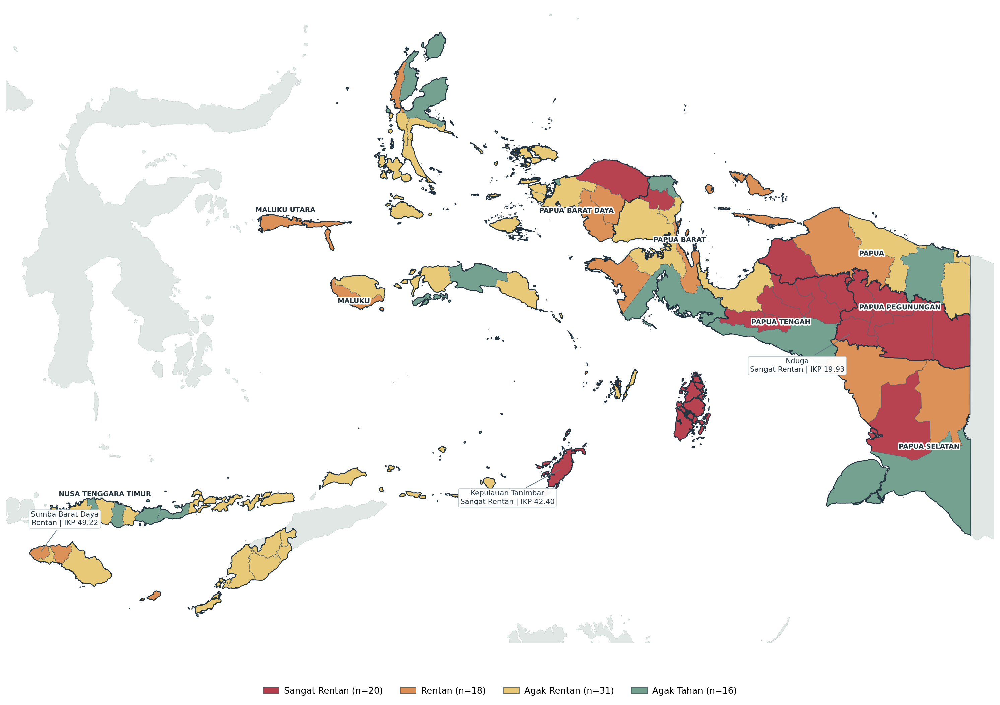

CELL 21 — VECTOR FOOD SECURITY STATUS MAP
Mapped districts    : 85
Mapped provinces    : 9
Basemap status      : NATURAL EARTH 10M LOADED
Administrative data : BIG 2026
Food security data  : IKP 2025
Province labels     : 9
Selected callouts   : 3
Original clusters   : UNCHANGED
New clustering fits : 0
New IKP calculation : NO
Figures saved       : False


In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 21 (VECTOR BASEMAP REVISION)
# FOOD SECURITY STATUS MAP — EASTERN INDONESIA, 2025
# ================================================================
#
# Basemap:
#   Natural Earth 1:10m land polygons
#
# Thematic geometry:
#   85 verified BIG district polygons (June 2026)
#
# Data:
#   Recorded IKP status, 2025
#
# Output:
#   Static Matplotlib figure
#   Optional PDF / PNG for LaTeX
#
# NO OpenStreetMap tile requests.
# NO clustering refit.
# NO new food-security index.
# NO changes to frozen data.
# ================================================================

from pathlib import Path, PurePosixPath
from zipfile import ZipFile
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Patch
from IPython.display import display


# ================================================================
# A. VISUAL SETTINGS
# ================================================================

SHOW_PROVINCE_LABELS = True
SHOW_CASE_CALLOUTS = True
SAVE_FIGURE = False

FIG_WIDTH = 17.0
FIG_DPI = 180

# Four recorded categories, not clustering ranks.
STATUS_COLORS = {
    "Sangat Rentan": "#B63E4C",
    "Rentan": "#DC8E53",
    "Agak Rentan": "#E9C875",
    "Agak Tahan": "#72A08D"
}

SEA_COLOR = "#EAF2F5"
OTHER_LAND_COLOR = "#E1E7E4"

DISTRICT_BORDER = "#52636D"
PROVINCE_BORDER = "#243440"

# Map labels
PROVINCE_FONT_SIZE = 8.1
CALLOUT_FONT_SIZE = 8.6

# Export only after visual approval.
OUTPUT_PDF = Path(
    "/content/IKP_Status_Eastern_Indonesia_2025.pdf"
)
OUTPUT_PNG = Path(
    "/content/IKP_Status_Eastern_Indonesia_2025.png"
)


# ================================================================
# B. VERIFY THE ORIGINAL 85-DISTRICT DATA
# ================================================================

assert "FOOD_MAP" in globals(), (
    "FOOD_MAP tidak tersedia. "
    "Jalankan Cell 19 terlebih dahulu."
)

F = FOOD_MAP.copy()

STATUS_COL = "IKP_2025_status_noninput"

assert len(F) == 85
assert F["kode_bps"].is_unique
assert F.geometry.notna().all()
assert not F.geometry.is_empty.any()
assert F.geometry.is_valid.all()
assert F["provinsi"].nunique() == 9

assert sorted(
    F["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]

STATUS_ORDER = [
    "Sangat Rentan",
    "Rentan",
    "Agak Rentan",
    "Agak Tahan"
]

COUNTS = F[STATUS_COL].value_counts()

assert [
    int(COUNTS[s])
    for s in STATUS_ORDER
] == [20, 18, 31, 16]

F["kode_bps"] = (
    F["kode_bps"].astype(str).str.strip()
)

assert F["IKP_MAP"].notna().all()


# ================================================================
# C. PROJECT TO A CONSISTENT MAP CRS
# ================================================================

M = F.to_crs("EPSG:3857").copy()

PROV = M.dissolve(
    by="provinsi",
    as_index=False
)

assert len(PROV) == 9

PROV_INDEX = PROV.set_index("provinsi")

# Original longitude/latitude bounds
GEO_BOUNDS = F.to_crs("EPSG:4326").total_bounds


# ================================================================
# D. NATURAL EARTH VECTOR BASEMAP
# ================================================================
#
# Natural Earth 1:10m provides land and coastlines.
#
# Downloaded once into the current Colab runtime.
# No live map tiles or subscription required.
#
# If download fails, the verified BIG polygons
# still render correctly on a plain sea background.
# ================================================================

NE_CACHE = Path(
    "/content/_naturalearth_10m_cache"
)

NE_CACHE.mkdir(
    parents=True,
    exist_ok=True
)

NE_ZIP = NE_CACHE / "ne_10m_land.zip"

NE_URL = (
    "https://naturalearth.s3.amazonaws.com/"
    "10m_physical/ne_10m_land.zip"
)

LAND = None
BASEMAP_STATUS = "NOT LOADED"

try:

    if not NE_ZIP.is_file():

        print("Downloading Natural Earth 1:10m land data...")

        urlretrieve(
            NE_URL,
            NE_ZIP
        )

    assert ZipFile.is_zipfile if False else True

    with ZipFile(NE_ZIP, "r") as z:

        # ZIP integrity and safe extraction
        bad_member = z.testzip()

        if bad_member is not None:
            raise RuntimeError(
                f"Corrupt ZIP member: {bad_member}"
            )

        for member in z.infolist():

            parts = PurePosixPath(
                member.filename
            ).parts

            if (
                PurePosixPath(
                    member.filename
                ).is_absolute()
                or ".." in parts
            ):
                raise RuntimeError(
                    "Unsafe archive path."
                )

            target = (
                NE_CACHE / member.filename
            ).resolve()

            if not target.is_relative_to(
                NE_CACHE.resolve()
            ):
                raise RuntimeError(
                    "Unsafe archive extraction path."
                )

        shp_files = list(
            NE_CACHE.rglob("ne_10m_land.shp")
        )

        if not shp_files:
            z.extractall(NE_CACHE)

    shp_files = list(
        NE_CACHE.rglob("ne_10m_land.shp")
    )

    assert len(shp_files) == 1

    # Read only the geographic study region.
    lon_min, lat_min, lon_max, lat_max = GEO_BOUNDS

    READING_BBOX = (
        float(lon_min - 3),
        float(lat_min - 3),
        float(lon_max + 3),
        float(lat_max + 3)
    )

    LAND = gpd.read_file(
        shp_files[0],
        bbox=READING_BBOX
    )

    assert not LAND.empty
    assert LAND.crs is not None

    LAND = LAND.to_crs("EPSG:3857")

    BASEMAP_STATUS = "NATURAL EARTH 10M LOADED"

except Exception as exc:

    BASEMAP_STATUS = "FALLBACK: SEA BACKGROUND ONLY"

    print("\nNatural Earth download/read unavailable:")
    print(type(exc).__name__, str(exc)[:250])
    print("Continuing without external land basemap.")


# ================================================================
# E. FIT GEOGRAPHIC EXTENT TO CANVAS
# ================================================================

xmin, ymin, xmax, ymax = M.total_bounds

span_x = xmax - xmin
span_y = ymax - ymin

PAD_X = 0.025
PAD_Y = 0.045

XMIN = xmin - PAD_X * span_x
XMAX = xmax + PAD_X * span_x

YMIN = ymin - PAD_Y * span_y
YMAX = ymax + PAD_Y * span_y

MAP_RATIO = (
    (XMAX - XMIN)
    / (YMAX - YMIN)
)

AX_LEFT = 0.018
AX_WIDTH = 0.964

AX_BOTTOM = 0.135
AX_HEIGHT = 0.845

FIG_HEIGHT = (
    FIG_WIDTH * AX_WIDTH
    / (MAP_RATIO * AX_HEIGHT)
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig = plt.figure(
    figsize=(FIG_WIDTH, FIG_HEIGHT),
    dpi=FIG_DPI,
    facecolor="white"
)

ax = fig.add_axes([
    AX_LEFT,
    AX_BOTTOM,
    AX_WIDTH,
    AX_HEIGHT
])

ax.set_facecolor(SEA_COLOR)

ax.set_xlim(XMIN, XMAX)
ax.set_ylim(YMIN, YMAX)


# ================================================================
# F. DRAW VECTOR BASEMAP
# ================================================================

if LAND is not None:

    LAND.plot(
        ax=ax,
        facecolor=OTHER_LAND_COLOR,
        edgecolor="#BDC9CA",
        linewidth=0.28,
        zorder=0
    )


# ================================================================
# G. DRAW VERIFIED IKP STATUS POLYGONS
# ================================================================

for status in STATUS_ORDER:

    subset = M.loc[
        M[STATUS_COL] == status
    ]

    subset.plot(
        ax=ax,
        facecolor=STATUS_COLORS[status],
        edgecolor=DISTRICT_BORDER,
        linewidth=0.38,
        alpha=0.97,
        zorder=2
    )


# ================================================================
# H. DRAW PROVINCE BOUNDARIES
# ================================================================

PROV.boundary.plot(
    ax=ax,
    color=PROVINCE_BORDER,
    linewidth=1.00,
    zorder=3
)


# ================================================================
# I. LABEL NINE PROVINCES
# ================================================================
#
# Label anchors are derived from the actual polygons.
# Small display offsets can be changed independently.
# ================================================================

PROVINCE_OFFSETS = {
    "Nusa Tenggara Timur": (5, 17),
    "Maluku": (-6, -11),
    "Maluku Utara": (5, 15),
    "Papua Barat Daya": (-10, -12),
    "Papua Barat": (3, 12),
    "Papua": (6, 12),
    "Papua Tengah": (-2, -12),
    "Papua Pegunungan": (5, 13),
    "Papua Selatan": (6, -12)
}

PROVINCE_DISPLAY = {
    "Nusa Tenggara Timur": "NUSA TENGGARA TIMUR",
    "Maluku": "MALUKU",
    "Maluku Utara": "MALUKU UTARA",
    "Papua Barat Daya": "PAPUA BARAT DAYA",
    "Papua Barat": "PAPUA BARAT",
    "Papua": "PAPUA",
    "Papua Tengah": "PAPUA TENGAH",
    "Papua Pegunungan": "PAPUA PEGUNUNGAN",
    "Papua Selatan": "PAPUA SELATAN"
}

assert set(PROVINCE_OFFSETS) == set(
    PROV["provinsi"]
)


if SHOW_PROVINCE_LABELS:

    for name, offset in PROVINCE_OFFSETS.items():

        geom = PROV_INDEX.loc[name, "geometry"]

        pt = geom.representative_point()

        label = ax.annotate(
            PROVINCE_DISPLAY[name],
            xy=(pt.x, pt.y),
            xytext=offset,
            textcoords="offset points",
            ha="center",
            va="center",
            fontsize=PROVINCE_FONT_SIZE,
            fontweight="bold",
            color="#23313A",
            zorder=6,
            annotation_clip=False
        )

        label.set_path_effects([
            pe.withStroke(
                linewidth=3.1,
                foreground="white"
            )
        ])


# ================================================================
# J. THREE VERIFIED FOOD-SECURITY EXAMPLES
# ================================================================
#
# These annotations are optional.
# They highlight previously verified IKP values.
#
# No new classifications are introduced.
# ================================================================

CASES = [
    {
        "code": "5318",
        "name": "Sumba Barat Daya",
        "status": "Rentan",
        "ikp": 49.22,
        "offset": (30, 41)
    },
    {
        "code": "8103",
        "name": "Kepulauan Tanimbar",
        "status": "Sangat Rentan",
        "ikp": 42.40,
        "offset": (-65, -35)
    },
    {
        "code": "9508",
        "name": "Nduga",
        "status": "Sangat Rentan",
        "ikp": 19.93,
        "offset": (-65, -39)
    }
]

if SHOW_CASE_CALLOUTS:

    for case in CASES:

        row = M.loc[
            M["kode_bps"] == case["code"]
        ]

        assert len(row) == 1

        r = row.iloc[0]

        assert r["kabupaten_kota"] == case["name"]
        assert r[STATUS_COL] == case["status"]

        assert np.isclose(
            float(r["IKP_MAP"]),
            case["ikp"],
            atol=0.005
        )

        point = r.geometry.representative_point()

        label_text = (
            f"{case['name']}\n"
            f"{case['status']} | IKP {case['ikp']:.2f}"
        )

        ax.annotate(
            label_text,
            xy=(point.x, point.y),
            xytext=case["offset"],
            textcoords="offset points",
            fontsize=CALLOUT_FONT_SIZE,
            color="#263743",
            ha="center",
            va="center",
            linespacing=1.3,
            zorder=8,

            bbox={
                "boxstyle": "round,pad=0.25",
                "facecolor": "white",
                "edgecolor": "#B9C8CE",
                "linewidth": 0.65,
                "alpha": 0.96
            },

            arrowprops={
                "arrowstyle": "-",
                "color": "#637984",
                "linewidth": 0.85,
                "shrinkA": 3,
                "shrinkB": 3
            },

            annotation_clip=False
        )


# ================================================================
# K. FINAL AXES EXTENT
# ================================================================

ax.set_xlim(XMIN, XMAX)
ax.set_ylim(YMIN, YMAX)

ax.set_aspect(
    "equal",
    adjustable="box"
)

ax.set_axis_off()


# ================================================================
# L. CLEAN HORIZONTAL LEGEND
# ================================================================

LEGEND_HANDLES = [
    Patch(
        facecolor=STATUS_COLORS[s],
        edgecolor=DISTRICT_BORDER,
        linewidth=0.7,
        label=f"{s} (n={int(COUNTS[s])})"
    )
    for s in STATUS_ORDER
]

fig.legend(
    handles=LEGEND_HANDLES,
    loc="center",
    bbox_to_anchor=(0.5, 0.071),
    ncol=4,
    frameon=False,
    fontsize=10.5,
    handlelength=1.8,
    handletextpad=0.55,
    columnspacing=2.0
)


# ================================================================
# M. OPTIONAL STATIC EXPORT
# ================================================================

if SAVE_FIGURE:

    fig.savefig(
        OUTPUT_PDF,
        format="pdf",
        dpi=300,
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0.06
    )

    fig.savefig(
        OUTPUT_PNG,
        format="png",
        dpi=300,
        facecolor="white",
        bbox_inches="tight",
        pad_inches=0.06
    )

    print("Saved PDF:", OUTPUT_PDF)
    print("Saved PNG:", OUTPUT_PNG)


plt.show()


# ================================================================
# N. FINAL AUDIT
# ================================================================

print("=" * 70)
print("CELL 21 — VECTOR FOOD SECURITY STATUS MAP")
print("=" * 70)

print("Mapped districts    :", len(M))
print("Mapped provinces    :", len(PROV))
print("Basemap status      :", BASEMAP_STATUS)
print("Administrative data : BIG 2026")
print("Food security data  : IKP 2025")

print(
    "Province labels     :",
    9 if SHOW_PROVINCE_LABELS else 0
)

print(
    "Selected callouts   :",
    len(CASES) if SHOW_CASE_CALLOUTS else 0
)

print("Original clusters   : UNCHANGED")
print("New clustering fits : 0")
print("New IKP calculation : NO")
print("Figures saved       :", SAVE_FIGURE)
print("=" * 70)


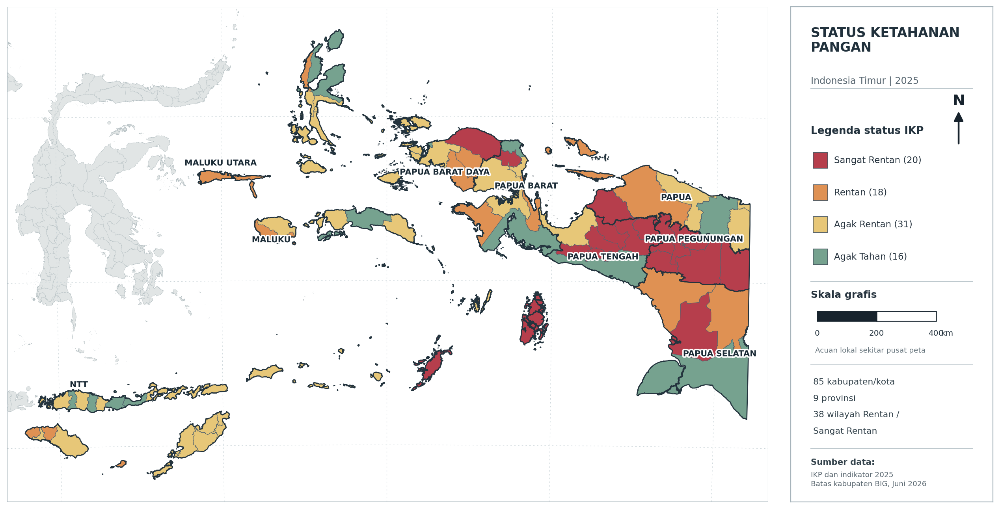

ATLAS MAP COMPLETED
Map type         : ikp
Districts        : 85
Provinces        : 9
BIG basemap      : 541 features
Local scale bar  : 400 km
Original clusters: UNCHANGED
Clustering refit : NO
Files saved      : False


In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 21 (ATLAS MAP DESIGN)
# FOOD SECURITY STATUS & STABILITY-AWARE TYPOLOGY
# ================================================================
#
# STYLE:
# - Single cartographic map on the left
# - Separate information panel on the right
# - Geographic background from BIG polygons
# - District and province administrative boundaries
# - Province labels and geographic graticule
# - North arrow and locally calibrated scale bar
# - Clear categorical legend and data sources
#
# FIRST OUTPUT:
# Recorded food-security status (IKP), 2025
#
# OPTIONAL SECOND OUTPUT:
# Frozen stability-aware regional typology
#
# No OSM or external tile servers.
# No interactive HTML.
# No clustering refit.
# No new food-security index.
# No automatic file saving.
# ================================================================

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from matplotlib.patches import Rectangle
from pyproj import CRS, Transformer, Geod
from shapely.geometry import LineString
import shapely

from pathlib import Path
from IPython.display import display


# ================================================================
# A. GLOBAL SETTINGS
# ================================================================

SAVE_FIGURE = False
SHOW_PROVINCE_LABELS = True
SHOW_GRATICULE = True

# Choose "ikp" or "typology".
MAP_KIND = "ikp"

# Figure width in inches.
FIG_WIDTH = 14.4
FIG_DPI = 180

# Background colors
SEA_COLOR = "#F5F8FA"
OTHER_LAND = "#E1E5E5"

DISTRICT_LINE = "#53636E"
PROVINCE_LINE = "#24343E"

# Original IKP categories
IKP_COLORS = {
    "Sangat Rentan": "#B63E4C",
    "Rentan": "#DF9153",
    "Agak Rentan": "#E7C778",
    "Agak Tahan": "#76A28F"
}

IKP_ORDER = [
    "Sangat Rentan",
    "Rentan",
    "Agak Rentan",
    "Agak Tahan"
]

# Frozen clustering colors
TYPOLOGY_COLORS = {
    0: "#D8A24B",
    1: "#3486A6",
    2: "#815C9D"
}

TYPOLOGY_LABELS = {
    0: "SA0: Pangan relatif lebih baik;\nperiode kering lebih panjang",
    1: "SA1: Pangan bervariasi;\nhujan ekstrem relatif tinggi",
    2: "SA2: Ketahanan pangan rendah;\nhambatan akses relatif tinggi"
}

OUTPUT_DIR = Path("/content")
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.facecolor": "white"
})


# ================================================================
# B. VERIFY THE FOOD SECURITY DATA
# ================================================================

assert "FOOD_MAP" in globals(), (
    "FOOD_MAP tidak tersedia. "
    "Jalankan Cell 19 dahulu."
)

F = FOOD_MAP.copy()

STATUS_COL = "IKP_2025_status_noninput"

assert len(F) == 85
assert F["kode_bps"].is_unique
assert F["provinsi"].nunique() == 9

assert F.geometry.notna().all()
assert not F.geometry.is_empty.any()
assert F.geometry.is_valid.all()

assert sorted(
    F["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]

assert set(F[STATUS_COL]) == set(IKP_ORDER)

IKP_COUNTS = (
    F[STATUS_COL]
    .value_counts()
)

assert [
    int(IKP_COUNTS[k])
    for k in IKP_ORDER
] == [20, 18, 31, 16]

assert F["IKP_MAP"].notna().all()

# Verify cross-tabulation totals.
IKP_CROSSTAB = pd.crosstab(
    F["cluster_SA"],
    F[STATUS_COL]
)

assert IKP_CROSSTAB.to_numpy().sum() == 85

# Existing vulnerability statuses, not a new index.
N_RECORDED_VULNERABLE = int(
    F[STATUS_COL]
    .isin(["Sangat Rentan", "Rentan"])
    .sum()
)

assert N_RECORDED_VULNERABLE == 38


# ================================================================
# C. LOAD NATIONWIDE BIG GEOMETRY AS BASEMAP
# ================================================================
#
# The Cell 16R variable B contains 541 BIG features.
# Areas outside the 85-district study region appear
# in neutral gray.
#
# This avoids OSM tile access entirely.
# ================================================================

if (
    "B" in globals()
    and isinstance(B, gpd.GeoDataFrame)
    and len(B) > 500
):

    BIG_BASE = B.copy()

else:

    # Reopen the verified GDB if its cached directory
    # remains available from the previous workflow.
    cache_path = Path(
        "/content/_gdb85_boundary_cache/"
        "BATASWILAYAH_KABKOTA_20260601.gdb"
    )

    if not cache_path.is_dir():

        raise RuntimeError(
            "Geometri BIG nasional tidak tersedia. "
            "Jalankan Cell 16R agar variabel B "
            "dan geometri 85 wilayah tersedia."
        )

    BIG_BASE = gpd.read_file(
        cache_path,
        layer="BATAS_KABKOTA_AR",
        engine="pyogrio"
    )

assert len(BIG_BASE) == 541
assert BIG_BASE.crs is not None

# Remove vertical coordinates for cartography.
BIG_BASE["geometry"] = (
    BIG_BASE.geometry.map(shapely.force_2d)
)

BIG_HORIZONTAL_CRS = CRS.from_user_input(
    BIG_BASE.crs
).to_2d()

# Original verified BIG horizontal CRS is WGS84.
assert BIG_HORIZONTAL_CRS.to_epsg() == 4326

BIG_BASE = BIG_BASE.set_crs(
    "EPSG:4326",
    allow_override=True
)


# ================================================================
# D. REGIONAL EQUAL-AREA PROJECTION
# ================================================================
#
# Lambert Azimuthal Equal Area centred on the
# study region, avoiding reliance on Web Mercator.
#
# Coordinates use meters.
# ================================================================

MAP_CRS = CRS.from_proj4(
    "+proj=laea "
    "+lat_0=-4 "
    "+lon_0=130 "
    "+datum=WGS84 "
    "+units=m "
    "+no_defs "
    "+type=crs"
)

M = F.to_crs(MAP_CRS).copy()

BIG_MAP = BIG_BASE.to_crs(
    MAP_CRS
).copy()

PROV = M.dissolve(
    by="provinsi",
    as_index=False
)

assert len(PROV) == 9

PROV_INDEX = PROV.set_index(
    "provinsi"
)

TRANSFORMER = Transformer.from_crs(
    "EPSG:4326",
    MAP_CRS,
    always_xy=True
)

GEOD = Geod(ellps="WGS84")


# ================================================================
# E. MAP EXTENT
# ================================================================

xmin, ymin, xmax, ymax = M.total_bounds

dx = xmax - xmin
dy = ymax - ymin

PAD_X = 0.025
PAD_Y = 0.050

XMIN = xmin - PAD_X * dx
XMAX = xmax + PAD_X * dx

YMIN = ymin - PAD_Y * dy
YMAX = ymax + PAD_Y * dy

XS = XMAX - XMIN
YS = YMAX - YMIN

MAP_ASPECT = XS / YS


# ================================================================
# F. CARTOGRAPHIC LAYOUT
# ================================================================
#
# Left : 75% thematic map
# Right: 20% information panel
#
# Height follows geographic extent so that
# the map is not squeezed into a fixed canvas.
# ================================================================

MAP_RECT = [
    0.018,  # left
    0.055,  # bottom
    0.745,  # width
    0.890   # height
]

PANEL_RECT = [
    0.785,
    0.055,
    0.198,
    0.890
]

FIG_HEIGHT = (
    FIG_WIDTH * MAP_RECT[2]
    / (MAP_ASPECT * MAP_RECT[3])
)


# ================================================================
# G. MAP STYLES AND LABELS
# ================================================================

PROVINCE_NAMES = {
    "Nusa Tenggara Timur": "NTT",
    "Maluku": "MALUKU",
    "Maluku Utara": "MALUKU UTARA",
    "Papua Barat Daya": "PAPUA BARAT DAYA",
    "Papua Barat": "PAPUA BARAT",
    "Papua": "PAPUA",
    "Papua Tengah": "PAPUA TENGAH",
    "Papua Pegunungan": "PAPUA PEGUNUNGAN",
    "Papua Selatan": "PAPUA SELATAN"
}

# Screen-point adjustments for labels.
PROVINCE_OFFSETS = {
    "Nusa Tenggara Timur": (0, 13),
    "Maluku": (-5, -10),
    "Maluku Utara": (5, 14),
    "Papua Barat Daya": (-7, -13),
    "Papua Barat": (3, 12),
    "Papua": (5, 12),
    "Papua Tengah": (-2, -11),
    "Papua Pegunungan": (2, 13),
    "Papua Selatan": (7, -11)
}

assert set(PROVINCE_NAMES) == set(
    PROV["provinsi"]
)


# ================================================================
# H. DRAW GEOGRAPHIC GRATICULE
# ================================================================
#
# Light coordinate guides, every 5 degrees.
# Geographic lines are projected into LAEA.
#
# No misleading manual coordinate ticks.
# ================================================================

def draw_graticule(ax):

    line_color = "#CBD5D9"

    # Meridians: 120E–140E
    for lon in range(120, 141, 5):

        lats = np.linspace(-15, 8, 180)

        lons = np.full_like(lats, lon)

        xx, yy = TRANSFORMER.transform(
            lons, lats
        )

        ax.plot(
            xx, yy,
            color=line_color,
            linewidth=0.48,
            linestyle=(0, (3, 5)),
            zorder=0.7
        )

    # Parallels: 10S, 5S, Equator
    for lat in [-10, -5, 0, 5]:

        lons = np.linspace(112, 146, 220)

        lats = np.full_like(lons, lat)

        xx, yy = TRANSFORMER.transform(
            lons, lats
        )

        ax.plot(
            xx, yy,
            color=line_color,
            linewidth=0.48,
            linestyle=(0, (3, 5)),
            zorder=0.7
        )


# ================================================================
# I. NORTH ARROW FOR PANEL
# ================================================================

def draw_north_arrow(ax):

    ax.text(
        0.83, 0.810,
        "N",
        transform=ax.transAxes,
        ha="center",
        va="center",
        fontsize=15,
        fontweight="bold",
        color="#17232D"
    )

    ax.annotate(
        "",
        xy=(0.83, 0.793),
        xytext=(0.83, 0.720),
        xycoords="axes fraction",
        textcoords="axes fraction",
        arrowprops={
            "arrowstyle": "-|>",
            "linewidth": 1.8,
            "mutation_scale": 20,
            "color": "#17232D"
        }
    )


# ================================================================
# J. LOCAL GEODESIC SCALE BAR
# ================================================================
#
# The bar is calibrated using WGS84 geodesic
# distances near the map centre.
#
# It is an approximate regional reference,
# not an assertion of uniform scale everywhere.
# ================================================================

def draw_scale_bar(ax):

    map_inches = (
        FIG_WIDTH * MAP_RECT[2]
    )

    panel_inches = (
        FIG_WIDTH * PANEL_RECT[2]
    )

    usable_fraction = 0.68

    chosen_km = None
    bar_fraction = None

    for distance_km in [500, 400, 300, 200, 100]:

        lon2, lat2, _ = GEOD.fwd(
            130.0,
            -4.0,
            90.0,
            distance_km * 1000
        )

        x0, y0 = TRANSFORMER.transform(
            130.0, -4.0
        )

        x1, y1 = TRANSFORMER.transform(
            lon2, lat2
        )

        projected_width = float(
            np.hypot(
                x1 - x0,
                y1 - y0
            )
        )

        # Equivalent printed width of a geographic
        # distance in the main map axes.
        frac = (
            projected_width / XS
            * map_inches / panel_inches
        )

        if frac <= usable_fraction:

            chosen_km = distance_km
            bar_fraction = frac
            break

    assert chosen_km is not None

    start = 0.13
    middle = start + bar_fraction / 2
    end = start + bar_fraction

    y = 0.365

    # Alternating black and white scale segments.
    ax.add_patch(
        Rectangle(
            (start, y),
            bar_fraction / 2,
            0.020,
            transform=ax.transAxes,
            facecolor="#17232D",
            edgecolor="#17232D",
            linewidth=1.0
        )
    )

    ax.add_patch(
        Rectangle(
            (middle, y),
            bar_fraction / 2,
            0.020,
            transform=ax.transAxes,
            facecolor="white",
            edgecolor="#17232D",
            linewidth=1.0
        )
    )

    for x, label in [
        (start, "0"),
        (middle, f"{chosen_km/2:g}"),
        (end, f"{chosen_km:g}")
    ]:

        ax.text(
            x, y - 0.017,
            label,
            transform=ax.transAxes,
            fontsize=8.0,
            ha="center",
            va="top",
            color="#24333E"
        )

    ax.text(
        end + 0.025,
        y - 0.017,
        "km",
        transform=ax.transAxes,
        fontsize=8.0,
        ha="left",
        va="top",
        color="#24333E"
    )

    return chosen_km


# ================================================================
# K. GENERIC MAP FUNCTION
# ================================================================

def draw_atlas_map(
    kind="ikp",
    save=False
):

    assert kind in ["ikp", "typology"]

    if kind == "ikp":

        value_col = STATUS_COL
        categories = IKP_ORDER
        colors = IKP_COLORS

        legend_labels = {
            category: (
                f"{category} "
                f"({int(IKP_COUNTS[category])})"
            )
            for category in categories
        }

        panel_title = (
            "STATUS KETAHANAN\n"
            "PANGAN"
        )

        panel_subtitle = (
            "Indonesia Timur | 2025"
        )

    else:

        value_col = "cluster_SA"
        categories = [0, 1, 2]
        colors = TYPOLOGY_COLORS

        cluster_counts = (
            M["cluster_SA"]
            .value_counts()
            .sort_index()
        )

        legend_labels = {
            k: (
                f"{TYPOLOGY_LABELS[k]}\n"
                f"(n={cluster_counts[k]})"
            )
            for k in categories
        }

        panel_title = (
            "TIPOLOGI WILAYAH\n"
            "PANGAN–IKLIM–AKSES"
        )

        panel_subtitle = (
            "Stability-aware | 2025"
        )

    # --------------------------------------------------------
    # K1. CREATE FIGURE
    # --------------------------------------------------------

    fig = plt.figure(
        figsize=(
            FIG_WIDTH,
            FIG_HEIGHT
        ),
        dpi=FIG_DPI,
        facecolor="white"
    )

    ax_map = fig.add_axes(
        MAP_RECT
    )

    ax_panel = fig.add_axes(
        PANEL_RECT
    )

    ax_map.set_facecolor(
        SEA_COLOR
    )

    ax_panel.set_facecolor(
        "white"
    )

    # --------------------------------------------------------
    # K2. CONTEXTUAL BIG MAP
    # --------------------------------------------------------

    BIG_MAP.plot(
        ax=ax_map,
        color=OTHER_LAND,
        edgecolor="#B8C2C5",
        linewidth=0.24,
        zorder=0
    )

    if SHOW_GRATICULE:
        draw_graticule(ax_map)

    # --------------------------------------------------------
    # K3. THEMATIC DISTRICTS
    # --------------------------------------------------------

    for category in categories:

        subset = M.loc[
            M[value_col] == category
        ]

        assert not subset.empty

        subset.plot(
            ax=ax_map,
            facecolor=colors[category],
            edgecolor=DISTRICT_LINE,
            linewidth=0.42,
            zorder=2
        )

    # Province outlines
    PROV.boundary.plot(
        ax=ax_map,
        color=PROVINCE_LINE,
        linewidth=1.05,
        zorder=3
    )

    # --------------------------------------------------------
    # K4. PROVINCE LABELS
    # --------------------------------------------------------

    if SHOW_PROVINCE_LABELS:

        for province, label in PROVINCE_NAMES.items():

            geom = PROV_INDEX.loc[
                province, "geometry"
            ]

            point = geom.representative_point()

            ann = ax_map.annotate(
                label,
                xy=(point.x, point.y),
                xytext=PROVINCE_OFFSETS[province],
                textcoords="offset points",
                ha="center",
                va="center",
                fontsize=8.3,
                fontweight="bold",
                color="#1A2A35",
                zorder=5
            )

            ann.set_path_effects([
                pe.withStroke(
                    linewidth=2.8,
                    foreground="white"
                )
            ])

    # --------------------------------------------------------
    # K5. MAP FRAME
    # --------------------------------------------------------

    ax_map.set_xlim(XMIN, XMAX)
    ax_map.set_ylim(YMIN, YMAX)

    ax_map.set_aspect(
        "equal",
        adjustable="box"
    )

    ax_map.set_axis_off()

    # Cartographic frame
    ax_map.add_patch(
        Rectangle(
            (XMIN, YMIN),
            XS, YS,
            fill=False,
            edgecolor="#A7B4BB",
            linewidth=0.85,
            zorder=9
        )
    )

    # --------------------------------------------------------
    # K6. SIDEBAR
    # --------------------------------------------------------

    ax_panel.set_xlim(0, 1)
    ax_panel.set_ylim(0, 1)

    ax_panel.set_xticks([])
    ax_panel.set_yticks([])

    for spine in ax_panel.spines.values():
        spine.set_color("#A7B4BB")
        spine.set_linewidth(0.9)

    ax_panel.text(
        0.10, 0.960,
        panel_title,
        transform=ax_panel.transAxes,
        ha="left",
        va="top",
        fontsize=13.2,
        fontweight="bold",
        linespacing=1.15,
        color="#21313C"
    )

    ax_panel.text(
        0.10, 0.860,
        panel_subtitle,
        transform=ax_panel.transAxes,
        fontsize=9.5,
        color="#5A6872",
        va="top"
    )

    ax_panel.plot(
        [0.10, 0.90],
        [0.835, 0.835],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    draw_north_arrow(ax_panel)

    # --------------------------------------------------------
    # K7. LEGEND
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.760,
        (
            "Legenda status IKP"
            if kind == "ikp"
            else "Legenda tipologi"
        ),
        transform=ax_panel.transAxes,
        fontsize=10.5,
        fontweight="bold",
        va="top",
        color="#23323D"
    )

    if kind == "ikp":
        y_positions = [
            0.690,
            0.625,
            0.560,
            0.495
        ]
    else:
        y_positions = [
            0.685,
            0.575,
            0.465
        ]

    for category, y in zip(
        categories,
        y_positions
    ):

        ax_panel.add_patch(
            Rectangle(
                (0.11, y - 0.016),
                0.073,
                0.032,
                transform=ax_panel.transAxes,
                facecolor=colors[category],
                edgecolor="#46545E",
                linewidth=0.7
            )
        )

        ax_panel.text(
            0.215,
            y,
            legend_labels[category],
            transform=ax_panel.transAxes,
            fontsize=9.1,
            ha="left",
            va="center",
            color="#26333E",
            linespacing=1.30
        )

    # --------------------------------------------------------
    # K8. SCALE BAR
    # --------------------------------------------------------

    ax_panel.plot(
        [0.10, 0.90],
        [0.445, 0.445],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    ax_panel.text(
        0.10, 0.413,
        "Skala grafis",
        transform=ax_panel.transAxes,
        fontsize=10,
        fontweight="bold",
        color="#26333E"
    )

    scale_km = draw_scale_bar(
        ax_panel
    )

    ax_panel.text(
        0.12,
        0.302,
        "Acuan lokal sekitar pusat peta",
        transform=ax_panel.transAxes,
        fontsize=7.4,
        color="#66747C"
    )

    # --------------------------------------------------------
    # K9. RESEARCH SUMMARY
    # --------------------------------------------------------

    ax_panel.plot(
        [0.10, 0.90],
        [0.277, 0.277],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    if kind == "ikp":

        summary_lines = [
            "85 kabupaten/kota",
            "9 provinsi",
            f"{N_RECORDED_VULNERABLE} wilayah Rentan /",
            "Sangat Rentan"
        ]

    else:

        summary_lines = [
            "85 kabupaten/kota",
            "9 provinsi",
            "3 tipologi multidimensi",
            "Bukan peringkat risiko"
        ]

    for i, line in enumerate(
        summary_lines
    ):

        ax_panel.text(
            0.11,
            0.250 - i * 0.033,
            line,
            transform=ax_panel.transAxes,
            fontsize=8.8,
            color="#34434C",
            va="top"
        )

    # --------------------------------------------------------
    # K10. DATA SOURCES
    # --------------------------------------------------------

    ax_panel.plot(
        [0.10, 0.90],
        [0.108, 0.108],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    ax_panel.text(
        0.10,
        0.088,
        "Sumber data:",
        transform=ax_panel.transAxes,
        fontsize=8.5,
        fontweight="bold",
        color="#34434C",
        va="top"
    )

    ax_panel.text(
        0.10,
        0.062,
        (
            "IKP dan indikator 2025\n"
            "Batas kabupaten BIG, Juni 2026"
        ),
        transform=ax_panel.transAxes,
        fontsize=7.4,
        linespacing=1.4,
        color="#5C6972",
        va="top"
    )

    # --------------------------------------------------------
    # K11. OPTIONAL STATIC EXPORT
    # --------------------------------------------------------

    if save:

        name = (
            "IKP_Status_2025_Atlas"
            if kind == "ikp"
            else "StabilityAware_Typology_2025_Atlas"
        )

        path_pdf = OUTPUT_DIR / f"{name}.pdf"
        path_png = OUTPUT_DIR / f"{name}.png"

        fig.savefig(
            path_pdf,
            format="pdf",
            dpi=300,
            facecolor="white"
        )

        fig.savefig(
            path_png,
            format="png",
            dpi=300,
            facecolor="white"
        )

        print("Saved:", path_pdf)
        print("Saved:", path_png)

    plt.show()

    print("=" * 68)
    print("ATLAS MAP COMPLETED")
    print("=" * 68)
    print("Map type         :", kind)
    print("Districts        :", len(M))
    print("Provinces        :", len(PROV))
    print("BIG basemap      :", len(BIG_MAP), "features")
    print("Local scale bar  :", scale_km, "km")
    print("Original clusters: UNCHANGED")
    print("Clustering refit : NO")
    print("Files saved      :", save)
    print("=" * 68)

    return fig


# ================================================================
# L. DRAW FIRST MAP — IKP 2025
# ================================================================

FIG_IKP = draw_atlas_map(
    kind=MAP_KIND,
    save=SAVE_FIGURE
)

# ================================================================
# OPTIONAL SECOND FIGURE
# ================================================================
#
# After evaluating the IKP map, use:
#
# FIG_TYPOLOGY = draw_atlas_map(
#     kind="typology",
#     save=False
# )
#
# This uses the SAME extent and cartographic layout.
# ================================================================


A. PROVINCIAL MINIMUM IKP AUDIT


,provinsi,kabupaten_kota,kode_bps,IKP_MAP,IKP_2025_status_noninput,cluster_SA
33,Nusa Tenggara Timur,Sumba Barat Daya,5318,49.22,Rentan,0
1,Maluku,Kepulauan Tanimbar,8103,42.40,Sangat Rentan,1
15,Maluku Utara,Pulau Taliabu,8208,49.69,Rentan,1
48,Papua Barat Daya,Tambrauw,9604,44.22,Sangat Rentan,1
41,Papua Barat,Pegunungan Arfak,9212,33.09,Sangat Rentan,2
61,Papua,Waropen,9115,45.34,Sangat Rentan,2
83,Papua Tengah,Puncak,9405,23.75,Sangat Rentan,2
71,Papua Pegunungan,Nduga,9508,19.93,Sangat Rentan,2
77,Papua Selatan,Mappi,9303,42.36,Sangat Rentan,2



ANNOTATION PLACEMENT AUDIT


,province,district,IKP,status,label_overlap,thematic_land_covered_fraction,outside_map
0,Nusa Tenggara Timur,Sumba Barat Daya,49.22,Rentan,0.0,0.0,True
1,Maluku,Kepulauan Tanimbar,42.40,Sangat Rentan,1.0,0.0,True
2,Maluku Utara,Pulau Taliabu,49.69,Rentan,2.0,0.0,True
3,Papua Barat Daya,Tambrauw,44.22,Sangat Rentan,3.0,0.0,True
4,Papua Barat,Pegunungan Arfak,33.09,Sangat Rentan,4.0,0.0,True
5,Papua,Waropen,45.34,Sangat Rentan,5.0,0.0,True
6,Papua Tengah,Puncak,23.75,Sangat Rentan,6.0,0.0,True
7,Papua Pegunungan,Nduga,19.93,Sangat Rentan,7.0,0.0,True
8,Papua Selatan,Mappi,42.36,Sangat Rentan,8.0,0.0,True


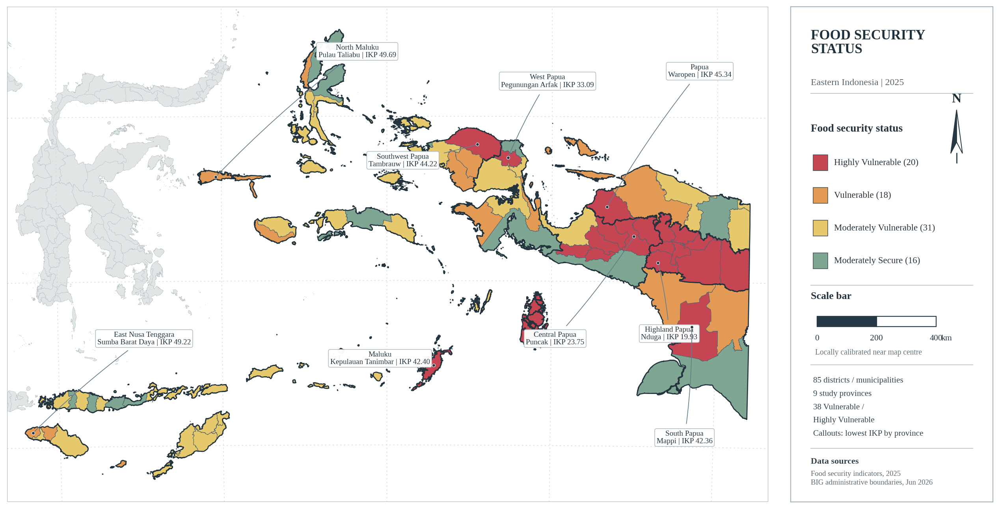


CELL 21 — FINAL ATLAS DESIGN v2
Map type          : ikp
Mapped districts  : 85
Mapped provinces  : 9
BIG context       : 541
Font              : Liberation Serif
Province labels   : NONE
Provincial minima : 9
Local scale bar   : 400 km
Frozen clusters   : UNCHANGED
New clustering    : NO
Figures saved     : False


In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 21
# FINAL ATLAS DESIGN v2
# FOOD SECURITY STATUS — EASTERN INDONESIA, 2025
# ================================================================
#
# PRESERVED FROM ORIGINAL ATLAS:
# - Main map on the left
# - Cartographic information panel on the right
# - BIG administrative context
# - District and province boundaries
# - Geographic graticule
# - Locally calibrated scale bar
#
# REVISIONS:
# - English labels
# - Liberation Serif
# - Refined categorical colours
# - No province labels on the map
# - 9 provincial-minimum IKP callouts
# - Sea-preferred annotation placement
# - Refined cartographic north arrow
#
# INPUT:
# FOOD_MAP from verified Cell 19
# B / BIG GeoPackage from verified Cell 16B
#
# NO clustering refit.
# NO new index construction.
# NO modification of frozen source files.
# NO automatic figure saving.
# ================================================================

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import matplotlib.font_manager as fm
import shapely

from matplotlib.patches import Rectangle
from matplotlib.patches import Polygon as MplPolygon
from pyproj import CRS, Transformer, Geod
from pathlib import Path
from IPython.display import display


# ================================================================
# A. SETTINGS
# ================================================================

MAP_KIND = "ikp"

SAVE_FIGURE = False
SHOW_GRATICULE = True
SHOW_PROVINCIAL_MINIMA = True

FIG_WIDTH = 14.4
FIG_DPI = 180

# Refined ordered status colours.
IKP_COLORS = {
    "Sangat Rentan": "#C64552",
    "Rentan": "#E39A54",
    "Agak Rentan": "#E6C96C",
    "Agak Tahan": "#7FA692"
}

IKP_ORDER = [
    "Sangat Rentan",
    "Rentan",
    "Agak Rentan",
    "Agak Tahan"
]

IKP_ENGLISH = {
    "Sangat Rentan": "Highly Vulnerable",
    "Rentan": "Vulnerable",
    "Agak Rentan": "Moderately Vulnerable",
    "Agak Tahan": "Moderately Secure"
}

TYPOLOGY_COLORS = {
    0: "#D8A24B",
    1: "#3486A6",
    2: "#815C9D"
}

TYPOLOGY_LABELS = {
    0: "SA0: Better food profile\nand longer dry spells",
    1: "SA1: Mixed food conditions\nand higher extreme rainfall",
    2: "SA2: Low food security\nand substantial access barriers"
}

SEA_COLOR = "#F5F8FA"
OTHER_LAND = "#E1E5E5"

DISTRICT_LINE = "#53636E"
PROVINCE_LINE = "#24343E"

OUTPUT_DIR = (
    Path("/content/drive/MyDrive")
    / "Research_Climate_FoodSecurity_85Kab"
    / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
    / "publication_figures"
)


# ================================================================
# B. LIBERATION SERIF FONT VERIFICATION
# ================================================================

FONT_FAMILY = "Liberation Serif"

available_fonts = {
    font.name
    for font in fm.fontManager.ttflist
}

if FONT_FAMILY not in available_fonts:

    raise RuntimeError(
        "Liberation Serif is not registered in Matplotlib. "
        "Install fonts-liberation in Colab, refresh the font "
        "manager, and rerun the cell. "
        "The requested font will not be silently substituted."
    )

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.facecolor": "white"
})


# ================================================================
# C. VERIFY FOOD SECURITY DATA
# ================================================================

assert "FOOD_MAP" in globals(), (
    "FOOD_MAP is unavailable. "
    "Run the verified Cell 19 first."
)

F = FOOD_MAP.copy()

STATUS_COL = "IKP_2025_status_noninput"

assert len(F) == 85
assert F["kode_bps"].is_unique
assert F["provinsi"].nunique() == 9

assert F.geometry.notna().all()
assert not F.geometry.is_empty.any()
assert F.geometry.is_valid.all()

assert sorted(
    F["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]

assert set(F[STATUS_COL]) == set(IKP_ORDER)

assert F["IKP_MAP"].notna().all()

F["IKP_MAP"] = pd.to_numeric(
    F["IKP_MAP"],
    errors="raise"
)

assert np.isfinite(F["IKP_MAP"]).all()

IKP_COUNTS = F[STATUS_COL].value_counts()

assert [
    int(IKP_COUNTS[s])
    for s in IKP_ORDER
] == [20, 18, 31, 16]

N_VULNERABLE = int(
    F[STATUS_COL].isin([
        "Sangat Rentan",
        "Rentan"
    ]).sum()
)

assert N_VULNERABLE == 38

F["kode_bps"] = (
    F["kode_bps"].astype(str).str.strip()
)


# ================================================================
# D. LOAD BIG BACKGROUND
# ================================================================
#
# Priority:
# 1. Existing B in Colab memory
# 2. Permanent BIG GeoPackage from Google Drive
#
# No ZIP re-upload or external tile requests.
# ================================================================

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

BIG_CACHE = (
    ROOT / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
    / "geospatial_cache_v1"
    / "BIG_541_context.gpkg"
)

if (
    "B" in globals()
    and isinstance(B, gpd.GeoDataFrame)
    and len(B) == 541
):

    BIG_BASE = B.copy()

elif BIG_CACHE.is_file():

    BIG_BASE = gpd.read_file(
        BIG_CACHE,
        layer="big_context"
    )

else:

    raise RuntimeError(
        "BIG contextual geography is unavailable. "
        "Run the persistent spatial cache Cell 16B."
    )

assert len(BIG_BASE) == 541
assert BIG_BASE.crs is not None

BIG_BASE["geometry"] = (
    BIG_BASE.geometry.map(shapely.force_2d)
)

horizontal_crs = CRS.from_user_input(
    BIG_BASE.crs
).to_2d()

assert horizontal_crs.to_epsg() == 4326

BIG_BASE = BIG_BASE.set_crs(
    "EPSG:4326",
    allow_override=True
)


# ================================================================
# E. MAP PROJECTION
# ================================================================

MAP_CRS = CRS.from_proj4(
    "+proj=laea "
    "+lat_0=-4 "
    "+lon_0=130 "
    "+datum=WGS84 "
    "+units=m "
    "+no_defs "
    "+type=crs"
)

M = F.to_crs(MAP_CRS).copy()

BIG_MAP = BIG_BASE.to_crs(MAP_CRS)

PROV = M.dissolve(
    by="provinsi",
    as_index=False
)

assert len(PROV) == 9

TRANSFORMER = Transformer.from_crs(
    "EPSG:4326",
    MAP_CRS,
    always_xy=True
)

GEOD = Geod(ellps="WGS84")


# ================================================================
# F. FIND THE LOWEST IKP DISTRICT IN EACH PROVINCE
# ================================================================
#
# Provincial minima are calculated directly
# from the verified aggregate IKP values.
#
# No manual choice of a district.
# No new vulnerability threshold.
# ================================================================

PROVINCE_ORDER = [
    "Nusa Tenggara Timur",
    "Maluku",
    "Maluku Utara",
    "Papua Barat Daya",
    "Papua Barat",
    "Papua",
    "Papua Tengah",
    "Papua Pegunungan",
    "Papua Selatan"
]

assert set(PROVINCE_ORDER) == set(
    M["provinsi"].unique()
)

PROVINCE_EN = {
    "Nusa Tenggara Timur": "East Nusa Tenggara",
    "Maluku": "Maluku",
    "Maluku Utara": "North Maluku",
    "Papua Barat Daya": "Southwest Papua",
    "Papua Barat": "West Papua",
    "Papua": "Papua",
    "Papua Tengah": "Central Papua",
    "Papua Pegunungan": "Highland Papua",
    "Papua Selatan": "South Papua"
}

# Fail if a province has tied minimum IKP values.
for province, group in M.groupby("provinsi"):

    min_value = group["IKP_MAP"].min()

    n_tied = int(
        np.isclose(
            group["IKP_MAP"],
            min_value,
            rtol=0,
            atol=1e-10
        ).sum()
    )

    assert n_tied == 1, (
        f"Tied minimum IKP in {province}. "
        "A unique district cannot be annotated."
    )

minimum_indices = (
    M.groupby("provinsi")["IKP_MAP"].idxmin()
)

MINIMA = M.loc[
    minimum_indices
].copy()

MINIMA["_order"] = (
    MINIMA["provinsi"].map({
        p: i
        for i, p in enumerate(PROVINCE_ORDER)
    })
)

MINIMA = MINIMA.sort_values(
    "_order"
).drop(columns="_order")

assert len(MINIMA) == 9
assert MINIMA["provinsi"].is_unique

MINIMA["status_english"] = (
    MINIMA[STATUS_COL].map(IKP_ENGLISH)
)

print("=" * 72)
print("A. PROVINCIAL MINIMUM IKP AUDIT")
print("=" * 72)

display(
    MINIMA[
        [
            "provinsi",
            "kabupaten_kota",
            "kode_bps",
            "IKP_MAP",
            STATUS_COL,
            "cluster_SA"
        ]
    ].round(2)
)


# ================================================================
# G. MAP EXTENT AND ATLAS CANVAS
# ================================================================

xmin, ymin, xmax, ymax = M.total_bounds

dx = xmax - xmin
dy = ymax - ymin

PAD_X = 0.025
PAD_Y = 0.050

XMIN = xmin - PAD_X * dx
XMAX = xmax + PAD_X * dx

YMIN = ymin - PAD_Y * dy
YMAX = ymax + PAD_Y * dy

XS = XMAX - XMIN
YS = YMAX - YMIN

MAP_ASPECT = XS / YS

# Preserve the previous atlas proportions.
MAP_RECT = [
    0.018,
    0.055,
    0.745,
    0.890
]

PANEL_RECT = [
    0.785,
    0.055,
    0.198,
    0.890
]

FIG_HEIGHT = (
    FIG_WIDTH * MAP_RECT[2]
    / (MAP_ASPECT * MAP_RECT[3])
)


# ================================================================
# H. GEOGRAPHIC GRATICULE
# ================================================================

def draw_graticule(ax):

    color = "#CBD5D9"

    for lon in range(120, 141, 5):

        lats = np.linspace(-15, 8, 180)
        lons = np.full_like(lats, lon)

        xx, yy = TRANSFORMER.transform(
            lons, lats
        )

        ax.plot(
            xx, yy,
            color=color,
            linewidth=0.48,
            linestyle=(0, (3, 5)),
            zorder=0.7
        )

    for lat in [-10, -5, 0, 5]:

        lons = np.linspace(112, 146, 220)
        lats = np.full_like(lons, lat)

        xx, yy = TRANSFORMER.transform(
            lons, lats
        )

        ax.plot(
            xx, yy,
            color=color,
            linewidth=0.48,
            linestyle=(0, (3, 5)),
            zorder=0.7
        )


# ================================================================
# I. REFINED CARTOGRAPHIC NORTH ARROW
# ================================================================
#
# A minimalist two-tone compass needle.
# It replaces the ordinary Matplotlib arrow.
#
# Orientation is a conventional regional north
# reference near the map's central meridian.
# ================================================================

def draw_north_arrow(ax):

    tr = ax.transAxes

    cx = 0.82

    ax.text(
        cx,
        0.814,
        "N",
        transform=tr,
        ha="center",
        va="center",
        fontsize=13.5,
        fontweight="bold",
        color="#1D2B35"
    )

    # Dark left half.
    ax.add_patch(
        MplPolygon(
            [
                [cx, 0.792],
                [cx - 0.029, 0.704],
                [cx, 0.727]
            ],
            closed=True,
            facecolor="#263844",
            edgecolor="#263844",
            linewidth=0.8,
            transform=tr,
            zorder=5
        )
    )

    # Light right half.
    ax.add_patch(
        MplPolygon(
            [
                [cx, 0.792],
                [cx + 0.029, 0.704],
                [cx, 0.727]
            ],
            closed=True,
            facecolor="#FFFFFF",
            edgecolor="#263844",
            linewidth=0.8,
            transform=tr,
            zorder=5
        )
    )

    ax.plot(
        [cx, cx],
        [0.704, 0.685],
        transform=tr,
        color="#263844",
        linewidth=1.1,
        zorder=5
    )


# ================================================================
# J. LOCAL GEODESIC SCALE BAR
# ================================================================

def draw_scale_bar(ax):

    map_inches = (
        FIG_WIDTH * MAP_RECT[2]
    )

    panel_inches = (
        FIG_WIDTH * PANEL_RECT[2]
    )

    max_fraction = 0.68

    chosen_km = None
    bar_fraction = None

    x0, y0 = TRANSFORMER.transform(
        130.0, -4.0
    )

    for distance_km in [
        500, 400, 300, 200, 100
    ]:

        lon2, lat2, _ = GEOD.fwd(
            130.0,
            -4.0,
            90.0,
            distance_km * 1000
        )

        x1, y1 = TRANSFORMER.transform(
            lon2, lat2
        )

        projected_length = float(
            np.hypot(
                x1 - x0,
                y1 - y0
            )
        )

        fraction = (
            projected_length / XS
            * map_inches / panel_inches
        )

        if fraction <= max_fraction:

            chosen_km = distance_km
            bar_fraction = fraction
            break

    assert chosen_km is not None

    x_start = 0.13
    x_mid = x_start + bar_fraction / 2
    x_end = x_start + bar_fraction

    y = 0.354

    for x, color in [
        (x_start, "#263844"),
        (x_mid, "#FFFFFF")
    ]:

        ax.add_patch(
            Rectangle(
                (x, y),
                bar_fraction / 2,
                0.021,
                transform=ax.transAxes,
                facecolor=color,
                edgecolor="#263844",
                linewidth=0.9
            )
        )

    for x, label in [
        (x_start, "0"),
        (x_mid, f"{chosen_km / 2:g}"),
        (x_end, f"{chosen_km:g}")
    ]:

        ax.text(
            x,
            y - 0.016,
            label,
            transform=ax.transAxes,
            fontsize=8.7,
            ha="center",
            va="top",
            color="#24333E"
        )

    ax.text(
        x_end + 0.025,
        y - 0.016,
        "km",
        transform=ax.transAxes,
        fontsize=8.7,
        ha="left",
        va="top",
        color="#24333E"
    )

    return chosen_km


# ================================================================
# K. PREFERRED ANNOTATION POSITIONS
# ================================================================
#
# Coordinates are fractions of the main map axes.
#
# Each province has several candidate locations,
# primarily in surrounding sea areas.
#
# They are cartographic positions, NOT new
# geographical coordinates for the districts.
# ================================================================

CALLOUT_CANDIDATES = {

    "Nusa Tenggara Timur": [
        (0.18, 0.33),
        (0.19, 0.39),
        (0.11, 0.37),
        (0.27, 0.37),
        (0.15, 0.44)
    ],

    "Maluku": [
        (0.49, 0.29),
        (0.43, 0.31),
        (0.56, 0.27),
        (0.44, 0.41),
        (0.60, 0.36)
    ],

    "Maluku Utara": [
        (0.46, 0.91),
        (0.37, 0.84),
        (0.54, 0.90),
        (0.31, 0.78),
        (0.60, 0.92)
    ],

    "Papua Barat Daya": [
        (0.52, 0.69),
        (0.47, 0.63),
        (0.59, 0.74),
        (0.53, 0.79),
        (0.43, 0.72)
    ],

    "Papua Barat": [
        (0.71, 0.85),
        (0.66, 0.90),
        (0.75, 0.94),
        (0.64, 0.78),
        (0.78, 0.82)
    ],

    "Papua": [
        (0.91, 0.87),
        (0.88, 0.94),
        (0.83, 0.87),
        (0.95, 0.78),
        (0.80, 0.94)
    ],

    "Papua Tengah": [
        (0.72, 0.33),
        (0.68, 0.27),
        (0.78, 0.26),
        (0.65, 0.37),
        (0.76, 0.19)
    ],

    "Papua Pegunungan": [
        (0.87, 0.34),
        (0.91, 0.27),
        (0.82, 0.27),
        (0.86, 0.20),
        (0.94, 0.38)
    ],

    "Papua Selatan": [
        (0.89, 0.13),
        (0.82, 0.12),
        (0.94, 0.15),
        (0.76, 0.09),
        (0.88, 0.23)
    ]
}

assert set(CALLOUT_CANDIDATES) == set(
    PROVINCE_ORDER
)


# ================================================================
# L. ANNOTATION COLLISION DIAGNOSTICS
# ================================================================
#
# Candidate annotation boxes are evaluated
# against:
# 1. The boundaries of the map axes
# 2. Previously placed annotation boxes
# 3. The 85 thematic district polygons
#
# This reduces the chance of covering islands.
# ================================================================

def bbox_overlap_fraction(a, b):

    x_overlap = max(
        0.0,
        min(a.x1, b.x1)
        - max(a.x0, b.x0)
    )

    y_overlap = max(
        0.0,
        min(a.y1, b.y1)
        - max(a.y0, b.y0)
    )

    intersection = x_overlap * y_overlap

    area = max(
        (a.x1 - a.x0)
        * (a.y1 - a.y0),
        1e-12
    )

    return intersection / area


def find_best_annotation_position(
    fig,
    ax,
    district_point,
    label_text,
    candidates,
    occupied_boxes
):

    renderer = fig.canvas.get_renderer()

    bounds = ax.bbox

    best = None

    # Spatial indexing avoids checking every
    # polygon for every candidate.
    spatial_index = M.sindex

    for candidate_index, position in enumerate(
        candidates
    ):

        trial = ax.annotate(
            label_text,
            xy=(
                district_point.x,
                district_point.y
            ),
            xytext=position,
            textcoords="axes fraction",
            ha="center",
            va="center",
            fontsize=7.7,
            linespacing=1.15,
            color="#243540",
            bbox={
                "boxstyle": "round,pad=0.24",
                "facecolor": "#FFFFFF",
                "edgecolor": "#AEBCC3",
                "linewidth": 0.65,
                "alpha": 0.96
            }
        )

        trial.update_positions(renderer)

        text_box = (
            trial.get_bbox_patch()
            .get_window_extent(renderer)
            .expanded(1.08, 1.15)
        )

        # Screen-boundary check.
        outside = (
            text_box.x0 < bounds.x0 + 4
            or text_box.x1 > bounds.x1 - 4
            or text_box.y0 < bounds.y0 + 4
            or text_box.y1 > bounds.y1 - 4
        )

        # Overlap with already accepted labels.
        label_overlap = sum(
            bbox_overlap_fraction(
                text_box, previous
            )
            for previous in occupied_boxes
        )

        # Convert display bbox to projected
        # data coordinates for polygon intersection.
        lower_left = (
            ax.transData.inverted().transform(
                (text_box.x0, text_box.y0)
            )
        )

        upper_right = (
            ax.transData.inverted().transform(
                (text_box.x1, text_box.y1)
            )
        )

        geographic_box = shapely.box(
            min(lower_left[0], upper_right[0]),
            min(lower_left[1], upper_right[1]),
            max(lower_left[0], upper_right[0]),
            max(lower_left[1], upper_right[1])
        )

        matched_indices = spatial_index.query(
            geographic_box,
            predicate="intersects"
        )

        land_intersection = sum(
            M.geometry.iloc[int(i)]
            .intersection(geographic_box)
            .area
            for i in matched_indices
        )

        land_fraction = (
            land_intersection
            / max(geographic_box.area, 1e-12)
        )

        # Heavy penalties for visual obstruction.
        score = (
            (10000 if outside else 0)
            + 2000 * label_overlap
            + 700 * land_fraction
            + 0.5 * candidate_index
        )

        trial.remove()

        if best is None or score < best["score"]:

            best = {
                "position": position,
                "bbox": text_box,
                "score": score,
                "land_fraction": land_fraction,
                "label_overlap": label_overlap,
                "outside": outside
            }

    assert best is not None

    return best


# ================================================================
# M. DRAW PROVINCIAL MINIMUM IKP ANNOTATIONS
# ================================================================

def add_provincial_minima(fig, ax):

    fig.canvas.draw()

    occupied = []
    audit_rows = []

    for _, row in MINIMA.iterrows():

        province = row["provinsi"]
        district = row["kabupaten_kota"]

        point = row.geometry.representative_point()

        label = (
            f"{PROVINCE_EN[province]}\n"
            f"{district} | IKP {row['IKP_MAP']:.2f}"
        )

        best = find_best_annotation_position(
            fig=fig,
            ax=ax,
            district_point=point,
            label_text=label,
            candidates=CALLOUT_CANDIDATES[province],
            occupied_boxes=occupied
        )

        occupied.append(best["bbox"])

        ax.annotate(
            label,
            xy=(point.x, point.y),
            xycoords="data",
            xytext=best["position"],
            textcoords="axes fraction",
            ha="center",
            va="center",
            fontsize=7.7,
            linespacing=1.15,
            color="#243540",
            zorder=8,
            annotation_clip=False,

            bbox={
                "boxstyle": "round,pad=0.24",
                "facecolor": "#FFFFFF",
                "edgecolor": "#AEBCC3",
                "linewidth": 0.65,
                "alpha": 0.97
            },

            arrowprops={
                "arrowstyle": "-",
                "color": "#667C88",
                "linewidth": 0.70,
                "connectionstyle": "arc3,rad=0.04",
                "shrinkA": 5,
                "shrinkB": 2
            }
        )

        # Small anchor, distinct from status fill.
        ax.scatter(
            point.x,
            point.y,
            s=10,
            color="#263844",
            edgecolor="white",
            linewidth=0.45,
            zorder=9
        )

        audit_rows.append({
            "province": province,
            "district": district,
            "IKP": float(row["IKP_MAP"]),
            "status": row[STATUS_COL],
            "label_overlap": best["label_overlap"],
            "thematic_land_covered_fraction": (
                best["land_fraction"]
            ),
            "outside_map": best["outside"]
        })

    audit = pd.DataFrame(audit_rows)

    print("\nANNOTATION PLACEMENT AUDIT")
    display(audit.round(4))

    if (
        audit["label_overlap"].gt(0.01).any()
        or audit["thematic_land_covered_fraction"]
            .gt(0.02).any()
        or audit["outside_map"].any()
    ):

        print(
            "\nWARNING: Some provincial callouts may "
            "need additional manual adjustment."
        )

    return audit


# ================================================================
# N. MAIN ATLAS FUNCTION
# ================================================================

def draw_atlas_map(
    kind="ikp",
    save=False
):

    assert kind in ["ikp", "typology"]

    if kind == "ikp":

        value_col = STATUS_COL
        categories = IKP_ORDER
        colors = IKP_COLORS

        legend_labels = {
            s: (
                f"{IKP_ENGLISH[s]} "
                f"({int(IKP_COUNTS[s])})"
            )
            for s in categories
        }

        panel_title = (
            "FOOD SECURITY\nSTATUS"
        )

        panel_subtitle = (
            "Eastern Indonesia | 2025"
        )

    else:

        value_col = "cluster_SA"
        categories = [0, 1, 2]
        colors = TYPOLOGY_COLORS

        cluster_counts = (
            M["cluster_SA"]
            .value_counts()
            .sort_index()
        )

        legend_labels = {
            k: (
                f"{TYPOLOGY_LABELS[k]}\n"
                f"(n={cluster_counts[k]})"
            )
            for k in categories
        }

        panel_title = (
            "REGIONAL\nTYPOLOGIES"
        )

        panel_subtitle = (
            "Stability-aware clustering | 2025"
        )

    # --------------------------------------------------------
    # N1. FIGURE AND AXES
    # --------------------------------------------------------

    fig = plt.figure(
        figsize=(FIG_WIDTH, FIG_HEIGHT),
        dpi=FIG_DPI,
        facecolor="white"
    )

    ax_map = fig.add_axes(MAP_RECT)
    ax_panel = fig.add_axes(PANEL_RECT)

    ax_map.set_facecolor(SEA_COLOR)
    ax_panel.set_facecolor("white")

    # --------------------------------------------------------
    # N2. BIG CONTEXTUAL BACKGROUND
    # --------------------------------------------------------

    BIG_MAP.plot(
        ax=ax_map,
        color=OTHER_LAND,
        edgecolor="#B8C2C5",
        linewidth=0.24,
        zorder=0
    )

    if SHOW_GRATICULE:
        draw_graticule(ax_map)

    # --------------------------------------------------------
    # N3. THEMATIC DISTRICTS
    # --------------------------------------------------------

    for category in categories:

        subset = M.loc[
            M[value_col] == category
        ]

        assert not subset.empty

        subset.plot(
            ax=ax_map,
            facecolor=colors[category],
            edgecolor=DISTRICT_LINE,
            linewidth=0.42,
            zorder=2
        )

    PROV.boundary.plot(
        ax=ax_map,
        color=PROVINCE_LINE,
        linewidth=1.05,
        zorder=3
    )

    # No province names on the main map.
    ax_map.set_xlim(XMIN, XMAX)
    ax_map.set_ylim(YMIN, YMAX)

    ax_map.set_aspect(
        "equal",
        adjustable="box"
    )

    ax_map.set_axis_off()

    ax_map.add_patch(
        Rectangle(
            (XMIN, YMIN),
            XS, YS,
            fill=False,
            edgecolor="#A7B4BB",
            linewidth=0.85,
            zorder=9
        )
    )

    # --------------------------------------------------------
    # N4. PROVINCIAL MINIMUM CALLOUTS
    # --------------------------------------------------------

    annotation_audit = None

    if (
        kind == "ikp"
        and SHOW_PROVINCIAL_MINIMA
    ):

        annotation_audit = add_provincial_minima(
            fig,
            ax_map
        )

    # --------------------------------------------------------
    # N5. INFORMATION PANEL
    # --------------------------------------------------------

    ax_panel.set_xlim(0, 1)
    ax_panel.set_ylim(0, 1)

    ax_panel.set_xticks([])
    ax_panel.set_yticks([])

    for spine in ax_panel.spines.values():
        spine.set_color("#A7B4BB")
        spine.set_linewidth(0.9)

    ax_panel.text(
        0.10, 0.955,
        panel_title,
        transform=ax_panel.transAxes,
        ha="left",
        va="top",
        fontsize=14,
        fontweight="bold",
        linespacing=1.10,
        color="#21313C"
    )

    ax_panel.text(
        0.10, 0.855,
        panel_subtitle,
        transform=ax_panel.transAxes,
        fontsize=9.6,
        color="#5A6872",
        va="top"
    )

    ax_panel.plot(
        [0.10, 0.90],
        [0.825, 0.825],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    draw_north_arrow(ax_panel)

    # --------------------------------------------------------
    # N6. STATUS LEGEND
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.764,
        (
            "Food security status"
            if kind == "ikp"
            else "Regional typologies"
        ),
        transform=ax_panel.transAxes,
        fontsize=10.9,
        fontweight="bold",
        va="top",
        color="#23323D"
    )

    if kind == "ikp":

        y_positions = [
            0.685,
            0.619,
            0.553,
            0.487
        ]

    else:

        y_positions = [
            0.684,
            0.584,
            0.484
        ]

    for category, y in zip(
        categories,
        y_positions
    ):

        ax_panel.add_patch(
            Rectangle(
                (0.11, y - 0.016),
                0.073,
                0.032,
                transform=ax_panel.transAxes,
                facecolor=colors[category],
                edgecolor="#46545E",
                linewidth=0.65
            )
        )

        ax_panel.text(
            0.215,
            y,
            legend_labels[category],
            transform=ax_panel.transAxes,
            fontsize=9.2,
            ha="left",
            va="center",
            color="#26333E",
            linespacing=1.20
        )

    # --------------------------------------------------------
    # N7. SCALE BAR
    # --------------------------------------------------------

    ax_panel.plot(
        [0.10, 0.90],
        [0.438, 0.438],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    ax_panel.text(
        0.10,
        0.410,
        "Scale bar",
        transform=ax_panel.transAxes,
        fontsize=10.4,
        fontweight="bold",
        color="#26333E"
    )

    scale_km = draw_scale_bar(
        ax_panel
    )

    ax_panel.text(
        0.12,
        0.298,
        "Locally calibrated near map centre",
        transform=ax_panel.transAxes,
        fontsize=7.8,
        color="#66747C"
    )

    # --------------------------------------------------------
    # N8. RESEARCH SUMMARY
    # --------------------------------------------------------

    ax_panel.plot(
        [0.10, 0.90],
        [0.277, 0.277],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    if kind == "ikp":

        summary_lines = [
            "85 districts / municipalities",
            "9 study provinces",
            "38 Vulnerable /",
            "Highly Vulnerable",
            "Callouts: lowest IKP by province"
        ]

        summary_start = 0.253
        summary_step = 0.027

    else:

        summary_lines = [
            "85 districts / municipalities",
            "9 study provinces",
            "3 multidimensional typologies",
            "Clusters are not risk ranks"
        ]

        summary_start = 0.250
        summary_step = 0.033

    for i, line in enumerate(summary_lines):

        ax_panel.text(
            0.11,
            summary_start - i * summary_step,
            line,
            transform=ax_panel.transAxes,
            fontsize=8.4,
            color="#34434C",
            va="top"
        )

    # --------------------------------------------------------
    # N9. DATA SOURCES
    # --------------------------------------------------------

    ax_panel.plot(
        [0.10, 0.90],
        [0.108, 0.108],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    ax_panel.text(
        0.10,
        0.090,
        "Data sources",
        transform=ax_panel.transAxes,
        fontsize=8.9,
        fontweight="bold",
        color="#34434C",
        va="top"
    )

    ax_panel.text(
        0.10,
        0.063,
        (
            "Food security indicators, 2025\n"
            "BIG administrative boundaries, Jun 2026"
        ),
        transform=ax_panel.transAxes,
        fontsize=7.5,
        linespacing=1.30,
        color="#5C6972",
        va="top"
    )

    # --------------------------------------------------------
    # N10. OPTIONAL STATIC OUTPUT
    # --------------------------------------------------------

    if save:

        OUTPUT_DIR.mkdir(
            parents=True,
            exist_ok=True
        )

        name = (
            "Food_Security_Status_2025_Atlas"
            if kind == "ikp"
            else "StabilityAware_Typology_2025_Atlas"
        )

        pdf_path = OUTPUT_DIR / f"{name}.pdf"
        png_path = OUTPUT_DIR / f"{name}.png"

        fig.savefig(
            pdf_path,
            format="pdf",
            dpi=300,
            facecolor="white"
        )

        fig.savefig(
            png_path,
            format="png",
            dpi=300,
            facecolor="white"
        )

        print("Saved PDF:", pdf_path)
        print("Saved PNG:", png_path)

    plt.show()

    print("\n" + "=" * 70)
    print("CELL 21 — FINAL ATLAS DESIGN v2")
    print("=" * 70)

    print("Map type          :", kind)
    print("Mapped districts  :", len(M))
    print("Mapped provinces  :", len(PROV))
    print("BIG context       :", len(BIG_MAP))
    print("Font              :", FONT_FAMILY)
    print("Province labels   : NONE")
    print(
        "Provincial minima :",
        9 if (
            kind == "ikp"
            and SHOW_PROVINCIAL_MINIMA
        ) else 0
    )
    print("Local scale bar   :", scale_km, "km")
    print("Frozen clusters   : UNCHANGED")
    print("New clustering    : NO")
    print("Figures saved     :", save)
    print("=" * 70)

    return fig, annotation_audit


# ================================================================
# O. DISPLAY THE FOOD SECURITY ATLAS
# ================================================================

FIG_IKP, ANNOTATION_AUDIT = draw_atlas_map(
    kind=MAP_KIND,
    save=SAVE_FIGURE
)

# ================================================================
# OPTIONAL: LATER, DRAW TYPOLOGY WITH SAME ATLAS DESIGN
# ================================================================
#
# FIG_SA, _ = draw_atlas_map(
#     kind="typology",
#     save=False
# )
#
# No provincial minimum labels will be attached
# to the typology map, avoiding misleading
# interpretation of clusters as food-security ranks.
# ================================================================


A. PROVINCIAL MINIMUM IKP — FROZEN DATA


,provinsi,kabupaten_kota,kode_bps,IKP_MAP,IKP_2025_status_noninput,cluster_SA
33,Nusa Tenggara Timur,Sumba Barat Daya,5318,49.22,Rentan,0
1,Maluku,Kepulauan Tanimbar,8103,42.40,Sangat Rentan,1
15,Maluku Utara,Pulau Taliabu,8208,49.69,Rentan,1
48,Papua Barat Daya,Tambrauw,9604,44.22,Sangat Rentan,1
41,Papua Barat,Pegunungan Arfak,9212,33.09,Sangat Rentan,2
61,Papua,Waropen,9115,45.34,Sangat Rentan,2
83,Papua Tengah,Puncak,9405,23.75,Sangat Rentan,2
71,Papua Pegunungan,Nduga,9508,19.93,Sangat Rentan,2
77,Papua Selatan,Mappi,9303,42.36,Sangat Rentan,2



B. ANNOTATION PLACEMENT AUDIT


,province,district,IKP,leader_length_pt,label_overlap,land_covered_fraction,leader_land_fraction,leader_crossings,outside_map
0,Nusa Tenggara Timur,Sumba Barat Daya,49.22,109.895,0.0,0.0,0.000,0,True
1,Maluku,Kepulauan Tanimbar,42.40,481.505,1.0,0.0,0.017,0,True
2,Maluku Utara,Pulau Taliabu,49.69,427.484,2.0,0.0,0.099,0,True
3,Papua Barat Daya,Tambrauw,44.22,632.808,3.0,0.0,0.092,0,True
4,Papua Barat,Pegunungan Arfak,33.09,649.203,4.0,0.0,0.099,0,True
5,Papua,Waropen,45.34,708.566,5.0,0.0,0.121,0,True
6,Papua Tengah,Puncak,23.75,719.772,6.0,0.0,0.168,0,True
7,Papua Pegunungan,Nduga,19.93,731.742,7.0,0.0,0.156,0,True
8,Papua Selatan,Mappi,42.36,742.698,8.0,0.0,0.000,0,True


,province,district,IKP,leader_length_pt,label_overlap,land_covered_fraction,leader_land_fraction,leader_crossings,outside_map
0,Nusa Tenggara Timur,Sumba Barat Daya,49.22,109.894674,0.0,0.0,0.000000,0,True
1,Maluku,Kepulauan Tanimbar,42.40,481.505133,1.0,0.0,0.017267,0,True
2,Maluku Utara,Pulau Taliabu,49.69,427.483920,2.0,0.0,0.099173,0,True
3,Papua Barat Daya,Tambrauw,44.22,632.808142,3.0,0.0,0.091599,0,True
4,Papua Barat,Pegunungan Arfak,33.09,649.202785,4.0,0.0,0.099395,0,True
5,Papua,Waropen,45.34,708.566374,5.0,0.0,0.121283,0,True
6,Papua Tengah,Puncak,23.75,719.772447,6.0,0.0,0.167983,0,True
7,Papua Pegunungan,Nduga,19.93,731.741889,7.0,0.0,0.155600,0,True
8,Papua Selatan,Mappi,42.36,742.698216,8.0,0.0,0.000000,0,True


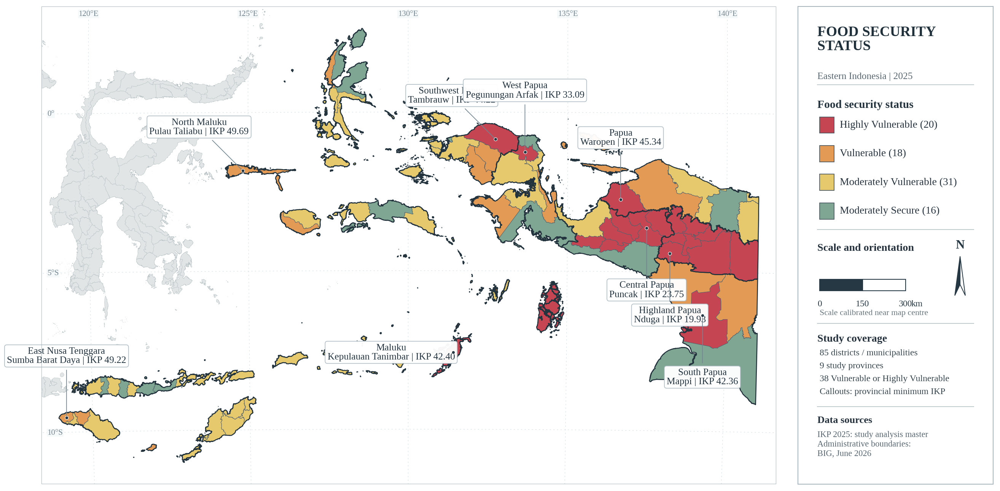


C. LATEX READABILITY AUDIT
Original figure width : 14.4 in
Expected LaTeX width  : 11.5 in
Print scaling factor  : 0.799


,element,original_pt,effective_pt
0,Annotation,10.2,8.15
1,Legend,11.0,8.78
2,Panel heading,11.8,9.42
3,Source text,9.0,7.19



CELL 21 — PUBLICATION ATLAS v3 COMPLETED
Districts mapped : 85
Provinces mapped : 9
IKP categories   : 4
Callouts         : 9
Scale reference  : 300 km
Frozen clustering: UNCHANGED
Figures saved    : False


In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 21
# REVISED PUBLICATION ATLAS v3
# FOOD SECURITY STATUS | EASTERN INDONESIA | 2025
# ================================================================
#
# PRESERVED:
# - BIG geographic background
# - Left map + right atlas information panel
# - 85 verified districts / 9 provinces
# - Four recorded IKP categories
# - Province and district boundaries
# - Geographic graticule
# - Nine provincial-minimum IKP callouts
# - Liberation Serif
#
# IMPROVED:
# - Shorter annotation leader lines
# - Penalty for lines crossing study polygons
# - Penalty for intersecting annotation leaders
# - Penalty for annotations covering study land
# - Collision and readability audit
# - Coordinate labels on map frame
# - Refined scale bar and north arrow placement
# - Clean English sidebar
#
# NO model fitting or new IKP construction.
# NO original data modification.
# NO automatic file saving.
# ================================================================

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.patheffects as pe
import shapely

from shapely.geometry import LineString, box
from matplotlib.patches import Rectangle
from matplotlib.patches import Polygon as MplPolygon
from pyproj import CRS, Transformer, Geod
from pathlib import Path
from IPython.display import display


# ================================================================
# A. USER SETTINGS
# ================================================================

SAVE_FIGURE = False

SHOW_CALLOUTS = True
SHOW_GRATICULE = True
SHOW_COORDINATE_LABELS = True

# Design is intended for a wide / landscape publication figure.
FIG_WIDTH = 14.4
FIG_DPI = 180

# Expected placement width in the LaTeX document.
# Change this to the actual final printed width.
LATEX_WIDTH_INCHES = 11.5

FONT_FAMILY = "Liberation Serif"

IKP_COLORS = {
    "Sangat Rentan": "#C64552",
    "Rentan": "#E39A54",
    "Agak Rentan": "#E6C96C",
    "Agak Tahan": "#7FA692"
}

IKP_ORDER = [
    "Sangat Rentan",
    "Rentan",
    "Agak Rentan",
    "Agak Tahan"
]

IKP_ENGLISH = {
    "Sangat Rentan": "Highly Vulnerable",
    "Rentan": "Vulnerable",
    "Agak Rentan": "Moderately Vulnerable",
    "Agak Tahan": "Moderately Secure"
}

SEA_COLOR = "#F5F8FA"
OTHER_LAND = "#E1E5E5"

DISTRICT_LINE = "#53636E"
PROVINCE_LINE = "#24343E"

ANNOTATION_FONT_SIZE = 10.2
LEGEND_FONT_SIZE = 11.0

# Optional manual overrides in map axes fractions.
# Leave empty for automatic placement.
#
# Example, after reviewing the map:
# MANUAL_CALLOUT_POSITIONS = {
#     "Maluku Utara": (0.39, 0.72)
# }
#
MANUAL_CALLOUT_POSITIONS = {}

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

OUTPUT_DIR = (
    ROOT / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
    / "publication_figures"
)


# ================================================================
# B. FONT VERIFICATION
# ================================================================

available_fonts = {
    f.name for f in fm.fontManager.ttflist
}

assert FONT_FAMILY in available_fonts, (
    "Liberation Serif tidak ditemukan. "
    "Instal fonts-liberation di Colab lalu "
    "jalankan ulang cell ini."
)

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "font.size": 10.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
})


# ================================================================
# C. VERIFY ORIGINAL FOOD SECURITY DATA
# ================================================================

assert "FOOD_MAP" in globals(), (
    "FOOD_MAP unavailable. Run verified Cell 19."
)

F = FOOD_MAP.copy()

STATUS_COL = "IKP_2025_status_noninput"

assert len(F) == 85
assert F["kode_bps"].is_unique
assert F["provinsi"].nunique() == 9

assert F.geometry.notna().all()
assert not F.geometry.is_empty.any()
assert F.geometry.is_valid.all()

assert sorted(
    F["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]

assert set(F[STATUS_COL]) == set(IKP_ORDER)

F["IKP_MAP"] = pd.to_numeric(
    F["IKP_MAP"], errors="raise"
)

assert np.isfinite(F["IKP_MAP"]).all()

F["kode_bps"] = (
    F["kode_bps"].astype(str).str.strip()
)

STATUS_COUNTS = F[STATUS_COL].value_counts()

assert [
    int(STATUS_COUNTS[s])
    for s in IKP_ORDER
] == [20, 18, 31, 16]

N_VULNERABLE = int(
    F[STATUS_COL].isin([
        "Sangat Rentan", "Rentan"
    ]).sum()
)

assert N_VULNERABLE == 38


# ================================================================
# D. RELOAD VERIFIED BIG CONTEXTUAL BASEMAP
# ================================================================

BIG_CACHE = (
    ROOT / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
    / "geospatial_cache_v1"
    / "BIG_541_context.gpkg"
)

if (
    "B" in globals()
    and isinstance(B, gpd.GeoDataFrame)
    and len(B) == 541
):

    BIG_BASE = B.copy()

else:

    assert BIG_CACHE.is_file(), (
        "BIG geographic cache missing. "
        "Run persistent spatial cache Cell 16B."
    )

    BIG_BASE = gpd.read_file(
        BIG_CACHE,
        layer="big_context"
    )

assert len(BIG_BASE) == 541
assert BIG_BASE.crs is not None

BIG_BASE["geometry"] = (
    BIG_BASE.geometry.map(shapely.force_2d)
)

assert CRS.from_user_input(
    BIG_BASE.crs
).to_2d().to_epsg() == 4326

BIG_BASE = BIG_BASE.set_crs(
    "EPSG:4326",
    allow_override=True
)


# ================================================================
# E. REGIONAL PROJECTION
# ================================================================

MAP_CRS = CRS.from_proj4(
    "+proj=laea "
    "+lat_0=-4 "
    "+lon_0=130 "
    "+datum=WGS84 "
    "+units=m "
    "+no_defs "
    "+type=crs"
)

M = F.to_crs(MAP_CRS).copy()
BIG_MAP = BIG_BASE.to_crs(MAP_CRS)

PROV = M.dissolve(
    by="provinsi",
    as_index=False
)

assert len(PROV) == 9

TRANSFORMER = Transformer.from_crs(
    "EPSG:4326",
    MAP_CRS,
    always_xy=True
)

GEOD = Geod(ellps="WGS84")


# ================================================================
# F. PROVINCIAL MINIMUM IKP
# ================================================================

PROVINCE_ORDER = [
    "Nusa Tenggara Timur",
    "Maluku",
    "Maluku Utara",
    "Papua Barat Daya",
    "Papua Barat",
    "Papua",
    "Papua Tengah",
    "Papua Pegunungan",
    "Papua Selatan"
]

PROVINCE_EN = {
    "Nusa Tenggara Timur": "East Nusa Tenggara",
    "Maluku": "Maluku",
    "Maluku Utara": "North Maluku",
    "Papua Barat Daya": "Southwest Papua",
    "Papua Barat": "West Papua",
    "Papua": "Papua",
    "Papua Tengah": "Central Papua",
    "Papua Pegunungan": "Highland Papua",
    "Papua Selatan": "South Papua"
}

assert set(PROVINCE_ORDER) == set(
    M["provinsi"].unique()
)

# Fail closed when the minimum is tied.
for province, group in M.groupby("provinsi"):

    lowest = group["IKP_MAP"].min()

    n_min = int(np.isclose(
        group["IKP_MAP"],
        lowest,
        rtol=0,
        atol=1e-10
    ).sum())

    assert n_min == 1, (
        f"Tied minimum IKP in {province}."
    )

MINIMA = M.loc[
    M.groupby("provinsi")["IKP_MAP"].idxmin()
].copy()

MINIMA["_order"] = MINIMA["provinsi"].map(
    {p: i for i, p in enumerate(PROVINCE_ORDER)}
)

MINIMA = (
    MINIMA.sort_values("_order")
    .drop(columns="_order")
)

assert len(MINIMA) == 9

print("=" * 72)
print("A. PROVINCIAL MINIMUM IKP — FROZEN DATA")
print("=" * 72)

display(
    MINIMA[
        [
            "provinsi",
            "kabupaten_kota",
            "kode_bps",
            "IKP_MAP",
            STATUS_COL,
            "cluster_SA"
        ]
    ].round(2)
)


# ================================================================
# G. MAP EXTENT AND ATLAS LAYOUT
# ================================================================

xmin, ymin, xmax, ymax = M.total_bounds

dx = xmax - xmin
dy = ymax - ymin

XMIN = xmin - 0.025 * dx
XMAX = xmax + 0.025 * dx

YMIN = ymin - 0.050 * dy
YMAX = ymax + 0.050 * dy

XS = XMAX - XMIN
YS = YMAX - YMIN

MAP_ASPECT = XS / YS

MAP_RECT = [
    0.018,
    0.055,
    0.745,
    0.890
]

PANEL_RECT = [
    0.785,
    0.055,
    0.198,
    0.890
]

FIG_HEIGHT = (
    FIG_WIDTH * MAP_RECT[2]
    / (MAP_ASPECT * MAP_RECT[3])
)

# Only contextual polygons intersecting the frame
# need to be drawn.
BIG_DRAW = BIG_MAP.cx[
    XMIN:XMAX,
    YMIN:YMAX
].copy()


# ================================================================
# H. GEOGRAPHIC GRATICULE + FRAME COORDINATES
# ================================================================

def _extract_points(geometry):

    if geometry.is_empty:
        return []

    if geometry.geom_type == "Point":
        return [geometry]

    if hasattr(geometry, "geoms"):

        result = []

        for part in geometry.geoms:
            result.extend(_extract_points(part))

        return result

    return []


def draw_graticule(ax):

    color = "#CED9DF"

    top_border = LineString([
        (XMIN, YMAX),
        (XMAX, YMAX)
    ])

    left_border = LineString([
        (XMIN, YMIN),
        (XMIN, YMAX)
    ])

    # Geographic meridians.
    for lon in range(115, 146, 5):

        lats = np.linspace(-22, 15, 400)
        lons = np.full_like(lats, lon)

        xx, yy = TRANSFORMER.transform(
            lons, lats
        )

        line = LineString(
            zip(xx, yy)
        )

        ax.plot(
            xx, yy,
            color=color,
            linewidth=0.42,
            linestyle=(0, (3, 6)),
            zorder=0.6
        )

        if SHOW_COORDINATE_LABELS:

            points = _extract_points(
                line.intersection(top_border)
            )

            for p in points:

                ax.text(
                    p.x,
                    YMAX - 0.008 * YS,
                    f"{lon}°E",
                    fontsize=8.4,
                    color="#758690",
                    ha="center",
                    va="top",
                    zorder=6,
                    bbox={
                        "facecolor": SEA_COLOR,
                        "edgecolor": "none",
                        "pad": 0.5,
                        "alpha": 0.85
                    }
                )

    # Geographic parallels.
    for lat in [-10, -5, 0, 5]:

        lons = np.linspace(108, 150, 450)
        lats = np.full_like(lons, lat)

        xx, yy = TRANSFORMER.transform(
            lons, lats
        )

        line = LineString(
            zip(xx, yy)
        )

        ax.plot(
            xx, yy,
            color=color,
            linewidth=0.42,
            linestyle=(0, (3, 6)),
            zorder=0.6
        )

        if SHOW_COORDINATE_LABELS:

            points = _extract_points(
                line.intersection(left_border)
            )

            for p in points:

                label = (
                    "0°"
                    if lat == 0
                    else f"{abs(lat)}°"
                    + ("S" if lat < 0 else "N")
                )

                ax.text(
                    XMIN + 0.008 * XS,
                    p.y,
                    label,
                    fontsize=8.4,
                    color="#758690",
                    ha="left",
                    va="center",
                    zorder=6,
                    bbox={
                        "facecolor": SEA_COLOR,
                        "edgecolor": "none",
                        "pad": 0.5,
                        "alpha": 0.85
                    }
                )


# ================================================================
# I. REFINED NORTH ARROW
# ================================================================

def draw_north_arrow(ax):

    tr = ax.transAxes
    cx = 0.83

    ax.text(
        cx, 0.488, "N",
        transform=tr,
        fontsize=13,
        fontweight="bold",
        ha="center",
        va="bottom",
        color="#263844"
    )

    # Dark needle.
    ax.add_patch(
        MplPolygon(
            [
                [cx, 0.477],
                [cx - 0.027, 0.395],
                [cx, 0.418]
            ],
            transform=tr,
            closed=True,
            facecolor="#263844",
            edgecolor="#263844",
            linewidth=0.8
        )
    )

    # Light needle.
    ax.add_patch(
        MplPolygon(
            [
                [cx, 0.477],
                [cx + 0.027, 0.395],
                [cx, 0.418]
            ],
            transform=tr,
            closed=True,
            facecolor="white",
            edgecolor="#263844",
            linewidth=0.8
        )
    )


# ================================================================
# J. LOCALLY CALIBRATED SCALE BAR
# ================================================================

def draw_scale_bar(ax):

    map_inches = FIG_WIDTH * MAP_RECT[2]
    panel_inches = FIG_WIDTH * PANEL_RECT[2]

    x0, y0 = TRANSFORMER.transform(
        130, -4
    )

    chosen = None
    fraction = None

    for km in [500, 400, 300, 200, 100, 50]:

        lon2, lat2, _ = GEOD.fwd(
            130, -4, 90,
            km * 1000
        )

        x1, y1 = TRANSFORMER.transform(
            lon2, lat2
        )

        projected = np.hypot(
            x1 - x0,
            y1 - y0
        )

        candidate = (
            projected / XS
            * map_inches / panel_inches
        )

        if candidate <= 0.57:

            chosen = km
            fraction = candidate
            break

    assert chosen is not None

    start = 0.11
    middle = start + fraction / 2
    end = start + fraction

    y = 0.405

    for start_x, color in [
        (start, "#263844"),
        (middle, "white")
    ]:

        ax.add_patch(
            Rectangle(
                (start_x, y),
                fraction / 2,
                0.024,
                transform=ax.transAxes,
                facecolor=color,
                edgecolor="#263844",
                linewidth=0.85
            )
        )

    for x, text in [
        (start, "0"),
        (middle, f"{chosen / 2:g}"),
        (end, f"{chosen:g}")
    ]:

        ax.text(
            x,
            y - 0.019,
            text,
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=9.5,
            color="#263844"
        )

    ax.text(
        end + 0.028,
        y - 0.019,
        "km",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9.5,
        color="#263844"
    )

    return chosen


# ================================================================
# K. ANNOTATION POSITION PREFERENCES
# ================================================================
#
# Directions are measured in degrees:
# 0 = right; 90 = up; 180 = left; 270 = down.
#
# Distances are in typographic points.
# This keeps search behaviour consistent
# across different figure resolutions.
# ================================================================

PREFERRED_ANGLES = {
    "Nusa Tenggara Timur":
        [90, 135, 45, 180, 0],

    "Maluku":
        [180, 135, 225, 90, 270],

    "Maluku Utara":
        [135, 90, 180, 45, 0],

    "Papua Barat Daya":
        [135, 180, 90, 225, 45],

    "Papua Barat":
        [90, 135, 45, 180, 0],

    "Papua":
        [90, 45, 135, 0, 180],

    "Papua Tengah":
        [270, 225, 180, 315, 90],

    "Papua Pegunungan":
        [270, 315, 225, 0, 180],

    "Papua Selatan":
        [270, 225, 180, 315, 90]
}

SEARCH_DISTANCES_PT = [
    65, 90, 120, 155, 195, 235
]

FALLBACK_ANGLES = [
    0, 45, 90, 135, 180, 225, 270, 315
]


# ================================================================
# L. ANNOTATION GEOMETRY HELPERS
# ================================================================

def _box_overlap_ratio(a, b):

    overlap_x = max(
        0,
        min(a.x1, b.x1) - max(a.x0, b.x0)
    )

    overlap_y = max(
        0,
        min(a.y1, b.y1) - max(a.y0, b.y0)
    )

    intersection = overlap_x * overlap_y

    area = max(
        (a.x1 - a.x0)
        * (a.y1 - a.y0),
        1e-12
    )

    return intersection / area


def _candidate_positions(ax, point, province):

    anchor_px = ax.transData.transform(
        (point.x, point.y)
    )

    angles = list(dict.fromkeys(
        PREFERRED_ANGLES[province]
        + FALLBACK_ANGLES
    ))

    positions = []

    for distance_pt in SEARCH_DISTANCES_PT:

        for angle in angles:

            rad = np.deg2rad(angle)

            distance_px = (
                distance_pt
                * ax.figure.dpi / 72
            )

            test_px = (
                anchor_px[0]
                + distance_px * np.cos(rad),

                anchor_px[1]
                + distance_px * np.sin(rad)
            )

            axes_pos = (
                ax.transAxes
                .inverted()
                .transform(test_px)
            )

            positions.append(
                tuple(axes_pos)
            )

    return positions


def _label_bbox(ax, renderer, text, position):

    trial = ax.annotate(
        text,
        xy=(0, 0),
        xycoords="axes fraction",
        xytext=position,
        textcoords="axes fraction",
        ha="center",
        va="center",
        fontsize=ANNOTATION_FONT_SIZE,
        linespacing=1.13,
        bbox={
            "boxstyle": "round,pad=0.24",
            "facecolor": "white",
            "edgecolor": "#AEBBC3",
            "linewidth": 0.65
        },
        annotation_clip=False
    )

    trial.update_positions(renderer)

    result = (
        trial.get_bbox_patch()
        .get_window_extent(renderer)
        .expanded(1.04, 1.10)
    )

    trial.remove()

    return result


def _bbox_as_geometry(ax, bbox):

    p0 = ax.transData.inverted().transform(
        (bbox.x0, bbox.y0)
    )

    p1 = ax.transData.inverted().transform(
        (bbox.x1, bbox.y1)
    )

    return box(
        min(p0[0], p1[0]),
        min(p0[1], p1[1]),
        max(p0[0], p1[0]),
        max(p0[1], p1[1])
    )


def _leader_geometry(ax, point, bbox):

    # Closest point on the label rectangle
    # to the district's representative point.
    anchor_px = ax.transData.transform(
        (point.x, point.y)
    )

    endpoint_px = (
        np.clip(
            anchor_px[0],
            bbox.x0, bbox.x1
        ),
        np.clip(
            anchor_px[1],
            bbox.y0, bbox.y1
        )
    )

    endpoint_data = (
        ax.transData
        .inverted()
        .transform(endpoint_px)
    )

    leader = LineString([
        (point.x, point.y),
        tuple(endpoint_data)
    ])

    length_pt = (
        np.hypot(
            endpoint_px[0] - anchor_px[0],
            endpoint_px[1] - anchor_px[1]
        ) * 72 / ax.figure.dpi
    )

    return leader, float(length_pt)


# ================================================================
# M. SCORE ANNOTATION POSITIONS
# ================================================================

def _score_position(
    ax,
    renderer,
    row,
    label,
    position,
    occupied_boxes,
    previous_leaders
):

    bbox = _label_bbox(
        ax, renderer, label, position
    )

    axes_box = ax.bbox

    outside = (
        bbox.x0 < axes_box.x0 + 5
        or bbox.x1 > axes_box.x1 - 5
        or bbox.y0 < axes_box.y0 + 5
        or bbox.y1 > axes_box.y1 - 5
    )

    label_overlap = sum(
        _box_overlap_ratio(bbox, old)
        for old in occupied_boxes
    )

    rect = _bbox_as_geometry(
        ax, bbox
    )

    # Fraction of the text box covering
    # the 85 study polygons.
    covered_area = 0.0

    for i in M.sindex.query(
        rect, predicate="intersects"
    ):

        covered_area += (
            M.geometry.iloc[int(i)]
            .intersection(rect)
            .area
        )

    land_fraction = (
        covered_area
        / max(rect.area, 1e-12)
    )

    point = row.geometry.representative_point()

    leader, length_pt = _leader_geometry(
        ax, point, bbox
    )

    # Fraction of line length crossing
    # other thematic polygons.
    crossing_length = 0.0

    if leader.length > 0:

        for i in M.sindex.query(
            leader,
            predicate="intersects"
        ):

            other = M.iloc[int(i)]

            if (
                str(other["kode_bps"])
                == str(row["kode_bps"])
            ):
                continue

            crossing_length += (
                other.geometry
                .intersection(leader)
                .length
            )

    crossed_land_fraction = (
        crossing_length
        / max(leader.length, 1e-12)
    )

    # Crossings between annotation leaders.
    leader_crossings = sum(
        bool(leader.crosses(old))
        for old in previous_leaders
    )

    # Candidate score:
    # strongly discourage label overlap,
    # covering study polygons, and leader crossings.
    score = (
        100000 * float(outside)
        + 3500 * label_overlap
        + 2200 * land_fraction
        + 550 * crossed_land_fraction
        + 380 * leader_crossings
        + 0.75 * length_pt
    )

    return {
        "score": float(score),
        "bbox": bbox,
        "leader": leader,
        "length_pt": length_pt,
        "label_overlap": float(label_overlap),
        "land_fraction": float(land_fraction),
        "leader_land_fraction": float(
            crossed_land_fraction
        ),
        "leader_crossings": int(leader_crossings),
        "outside": bool(outside),
        "position": position
    }


# ================================================================
# N. PLACE NINE ANNOTATIONS
# ================================================================

def add_provincial_minima(fig, ax):

    fig.canvas.draw()

    renderer = fig.canvas.get_renderer()

    occupied_boxes = []
    previous_leaders = []
    records = []

    for _, row in MINIMA.iterrows():

        province = row["provinsi"]

        point = (
            row.geometry.representative_point()
        )

        # Province remains identifiable inside
        # the annotation, not on the map polygons.
        label = (
            f"{PROVINCE_EN[province]}\n"
            f"{row['kabupaten_kota']} | "
            f"IKP {row['IKP_MAP']:.2f}"
        )

        if province in MANUAL_CALLOUT_POSITIONS:

            candidates = [
                MANUAL_CALLOUT_POSITIONS[province]
            ]

        else:

            candidates = _candidate_positions(
                ax, point, province
            )

        results = [
            _score_position(
                ax=ax,
                renderer=renderer,
                row=row,
                label=label,
                position=position,
                occupied_boxes=occupied_boxes,
                previous_leaders=previous_leaders
            )
            for position in candidates
        ]

        best = min(
            results,
            key=lambda x: x["score"]
        )

        occupied_boxes.append(
            best["bbox"]
        )

        previous_leaders.append(
            best["leader"]
        )

        ax.annotate(
            label,
            xy=(point.x, point.y),
            xycoords="data",
            xytext=best["position"],
            textcoords="axes fraction",
            ha="center",
            va="center",
            fontsize=ANNOTATION_FONT_SIZE,
            linespacing=1.13,
            color="#233440",
            zorder=8,
            annotation_clip=False,

            bbox={
                "boxstyle": "round,pad=0.24",
                "facecolor": "white",
                "edgecolor": "#AEBBC3",
                "linewidth": 0.70,
                "alpha": 0.97
            },

            arrowprops={
                "arrowstyle": "-",
                "connectionstyle": "arc3,rad=0",
                "color": "#728591",
                "linewidth": 0.72,
                "shrinkA": 3,
                "shrinkB": 2
            }
        )

        # Small, consistent reference marker.
        ax.scatter(
            point.x, point.y,
            s=12,
            facecolor="#263844",
            edgecolor="white",
            linewidth=0.48,
            zorder=9
        )

        records.append({
            "province": province,
            "district": row["kabupaten_kota"],
            "IKP": float(row["IKP_MAP"]),
            "leader_length_pt": best["length_pt"],
            "label_overlap": best["label_overlap"],
            "land_covered_fraction": (
                best["land_fraction"]
            ),
            "leader_land_fraction": (
                best["leader_land_fraction"]
            ),
            "leader_crossings": (
                best["leader_crossings"]
            ),
            "outside_map": best["outside"]
        })

    audit = pd.DataFrame(records)

    print("\nB. ANNOTATION PLACEMENT AUDIT")
    display(audit.round(3))

    problematic = (
        audit["label_overlap"].gt(0.01)
        | audit["land_covered_fraction"].gt(0.02)
        | audit["leader_crossings"].gt(0)
        | audit["outside_map"]
    )

    if problematic.any():

        print(
            "\nWARNING: Some annotations require "
            "visual inspection/manual adjustment."
        )

        display(
            audit.loc[problematic]
        )

    return audit


# ================================================================
# O. DRAW PUBLICATION ATLAS
# ================================================================

def draw_food_security_atlas(save=False):

    fig = plt.figure(
        figsize=(FIG_WIDTH, FIG_HEIGHT),
        dpi=FIG_DPI,
        facecolor="white"
    )

    ax_map = fig.add_axes(MAP_RECT)
    ax_panel = fig.add_axes(PANEL_RECT)

    ax_map.set_facecolor(SEA_COLOR)
    ax_panel.set_facecolor("white")

    # --------------------------------------------------------
    # O1. BIG CONTEXT
    # --------------------------------------------------------

    BIG_DRAW.plot(
        ax=ax_map,
        facecolor=OTHER_LAND,
        edgecolor="#B8C2C5",
        linewidth=0.24,
        zorder=0
    )

    if SHOW_GRATICULE:
        draw_graticule(ax_map)

    # --------------------------------------------------------
    # O2. FOOD SECURITY STATUS
    # --------------------------------------------------------

    for status in IKP_ORDER:

        part = M.loc[
            M[STATUS_COL] == status
        ]

        part.plot(
            ax=ax_map,
            facecolor=IKP_COLORS[status],
            edgecolor=DISTRICT_LINE,
            linewidth=0.40,
            zorder=2
        )

    PROV.boundary.plot(
        ax=ax_map,
        color=PROVINCE_LINE,
        linewidth=1.0,
        zorder=3
    )

    ax_map.set_xlim(XMIN, XMAX)
    ax_map.set_ylim(YMIN, YMAX)

    ax_map.set_aspect(
        "equal",
        adjustable="box"
    )

    ax_map.set_axis_off()

    # Map frame.
    ax_map.add_patch(
        Rectangle(
            (XMIN, YMIN),
            XS, YS,
            fill=False,
            edgecolor="#A7B4BB",
            linewidth=0.85,
            zorder=10
        )
    )

    # --------------------------------------------------------
    # O3. NINE PROVINCIAL MINIMUM ANNOTATIONS
    # --------------------------------------------------------

    annotation_audit = None

    if SHOW_CALLOUTS:

        annotation_audit = add_provincial_minima(
            fig, ax_map
        )

    # --------------------------------------------------------
    # O4. INFORMATION PANEL
    # --------------------------------------------------------

    ax_panel.set_xlim(0, 1)
    ax_panel.set_ylim(0, 1)

    ax_panel.set_xticks([])
    ax_panel.set_yticks([])

    for spine in ax_panel.spines.values():
        spine.set_color("#A7B4BB")
        spine.set_linewidth(0.85)

    # Header.
    ax_panel.text(
        0.10, 0.960,
        "FOOD SECURITY\nSTATUS",
        transform=ax_panel.transAxes,
        fontsize=15.0,
        fontweight="bold",
        linespacing=1.08,
        va="top",
        color="#21313C"
    )

    ax_panel.text(
        0.10, 0.862,
        "Eastern Indonesia | 2025",
        transform=ax_panel.transAxes,
        fontsize=10.2,
        va="top",
        color="#5A6872"
    )

    ax_panel.plot(
        [0.10, 0.90],
        [0.836, 0.836],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # O5. STATUS LEGEND
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.805,
        "Food security status",
        transform=ax_panel.transAxes,
        fontsize=11.8,
        fontweight="bold",
        va="top",
        color="#24343E"
    )

    LEGEND_Y = [
        0.752, 0.692, 0.632, 0.572
    ]

    for status, y in zip(
        IKP_ORDER, LEGEND_Y
    ):

        ax_panel.add_patch(
            Rectangle(
                (0.11, y - 0.017),
                0.075, 0.034,
                transform=ax_panel.transAxes,
                facecolor=IKP_COLORS[status],
                edgecolor="#46545E",
                linewidth=0.7
            )
        )

        ax_panel.text(
            0.215, y,
            (
                f"{IKP_ENGLISH[status]} "
                f"({int(STATUS_COUNTS[status])})"
            ),
            transform=ax_panel.transAxes,
            fontsize=LEGEND_FONT_SIZE,
            ha="left",
            va="center",
            color="#26333E"
        )

    ax_panel.plot(
        [0.10, 0.90],
        [0.533, 0.533],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # O6. SCALE BAR + NORTH ARROW
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.504,
        "Scale and orientation",
        transform=ax_panel.transAxes,
        fontsize=11.2,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    scale_km = draw_scale_bar(
        ax_panel
    )

    draw_north_arrow(
        ax_panel
    )

    ax_panel.text(
        0.11, 0.366,
        "Scale calibrated near map centre",
        transform=ax_panel.transAxes,
        fontsize=8.8,
        color="#66747C",
        va="top"
    )

    ax_panel.plot(
        [0.10, 0.90],
        [0.337, 0.337],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # O7. COVERAGE AND STUDY INFORMATION
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.314,
        "Study coverage",
        transform=ax_panel.transAxes,
        fontsize=11.2,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    study_lines = [
        "85 districts / municipalities",
        "9 study provinces",
        "38 Vulnerable or Highly Vulnerable",
        "Callouts: provincial minimum IKP"
    ]

    for i, line in enumerate(study_lines):

        ax_panel.text(
            0.11,
            0.283 - i * 0.027,
            line,
            transform=ax_panel.transAxes,
            fontsize=9.5,
            va="top",
            color="#34434C"
        )

    ax_panel.plot(
        [0.10, 0.90],
        [0.162, 0.162],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # O8. DATA SOURCES
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.143,
        "Data sources",
        transform=ax_panel.transAxes,
        fontsize=10.6,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    ax_panel.text(
        0.10, 0.112,
        (
            "IKP 2025: study analysis master\n"
            "Administrative boundaries:\n"
            "BIG, June 2026"
        ),
        transform=ax_panel.transAxes,
        fontsize=9.0,
        linespacing=1.25,
        va="top",
        color="#596872"
    )

    # --------------------------------------------------------
    # O9. OPTIONAL PUBLICATION EXPORT
    # --------------------------------------------------------

    if save:

        OUTPUT_DIR.mkdir(
            parents=True,
            exist_ok=True
        )

        pdf_path = (
            OUTPUT_DIR
            / "FoodSecurity_Status_2025_Atlas_v3.pdf"
        )

        png_path = (
            OUTPUT_DIR
            / "FoodSecurity_Status_2025_Atlas_v3.png"
        )

        fig.savefig(
            pdf_path,
            format="pdf",
            dpi=300,
            facecolor="white"
        )

        fig.savefig(
            png_path,
            format="png",
            dpi=300,
            facecolor="white"
        )

        print("PDF:", pdf_path)
        print("PNG:", png_path)

    plt.show()

    return fig, annotation_audit, scale_km


# ================================================================
# P. DISPLAY MAP
# ================================================================

FIG_IKP, ANNOTATION_AUDIT, SCALE_KM = (
    draw_food_security_atlas(
        save=SAVE_FIGURE
    )
)


# ================================================================
# Q. PUBLICATION READABILITY AUDIT
# ================================================================
#
# A figure designed at 14.4 inches becomes
# smaller when scaled inside LaTeX.
#
# This diagnostic evaluates the resulting
# effective text sizes.
# ================================================================

PRINT_SCALE = (
    LATEX_WIDTH_INCHES / FIG_WIDTH
)

PRINT_FONT_AUDIT = pd.DataFrame([
    {
        "element": "Annotation",
        "original_pt": ANNOTATION_FONT_SIZE
    },
    {
        "element": "Legend",
        "original_pt": LEGEND_FONT_SIZE
    },
    {
        "element": "Panel heading",
        "original_pt": 11.8
    },
    {
        "element": "Source text",
        "original_pt": 9.0
    }
])

PRINT_FONT_AUDIT["effective_pt"] = (
    PRINT_FONT_AUDIT["original_pt"]
    * PRINT_SCALE
)

print("\n" + "=" * 72)
print("C. LATEX READABILITY AUDIT")
print("=" * 72)

print("Original figure width :", FIG_WIDTH, "in")
print("Expected LaTeX width  :", LATEX_WIDTH_INCHES, "in")
print("Print scaling factor  :", round(PRINT_SCALE, 3))

display(
    PRINT_FONT_AUDIT.round(2)
)

if PRINT_FONT_AUDIT.loc[
    PRINT_FONT_AUDIT["element"].isin([
        "Annotation", "Legend"
    ]),
    "effective_pt"
].min() < 7.5:

    print(
        "WARNING: Main text may be too small "
        "at the intended LaTeX width."
    )

print("\n" + "=" * 72)
print("CELL 21 — PUBLICATION ATLAS v3 COMPLETED")
print("=" * 72)

print("Districts mapped :", len(M))
print("Provinces mapped :", len(PROV))
print("IKP categories   :", len(IKP_ORDER))
print("Callouts         :", 9 if SHOW_CALLOUTS else 0)
print("Scale reference  :", SCALE_KM, "km")
print("Frozen clustering: UNCHANGED")
print("Figures saved    :", SAVE_FIGURE)
print("=" * 72)


A. VERIFIED PROVINCIAL MINIMUM IKP


,provinsi,kabupaten_kota,IKP_MAP,IKP_2025_status_noninput,annotation_label
33,Nusa Tenggara Timur,Sumba Barat Daya,49.22,Rentan,Sumba Barat Daya · 49.22
1,Maluku,Kepulauan Tanimbar,42.40,Sangat Rentan,Kep. Tanimbar · 42.40
15,Maluku Utara,Pulau Taliabu,49.69,Rentan,Pulau Taliabu · 49.69
48,Papua Barat Daya,Tambrauw,44.22,Sangat Rentan,Tambrauw · 44.22
41,Papua Barat,Pegunungan Arfak,33.09,Sangat Rentan,Pegunungan Arfak · 33.09
61,Papua,Waropen,45.34,Sangat Rentan,Waropen · 45.34
83,Papua Tengah,Puncak,23.75,Sangat Rentan,Puncak · 23.75
71,Papua Pegunungan,Nduga,19.93,Sangat Rentan,Nduga · 19.93
77,Papua Selatan,Mappi,42.36,Sangat Rentan,Mappi · 42.36



B. COMPACT ANNOTATION AUDIT


,province,district,IKP,x_fraction,y_fraction,leader_length_pt,other_districts_crossed_fraction,text_over_study_land,text_over_context_land,text_overlap,outside_frame
0,Nusa Tenggara Timur,Sumba Barat Daya,49.22,0.157,0.030,63.942,0.052,False,False,False,False
1,Maluku,Kepulauan Tanimbar,42.40,0.622,0.221,21.353,0.000,False,False,False,False
2,Maluku Utara,Pulau Taliabu,49.69,0.290,0.690,10.665,0.000,False,False,False,False
3,Papua Barat Daya,Tambrauw,44.22,0.654,0.817,41.431,0.000,False,False,False,False
4,Papua Barat,Pegunungan Arfak,33.09,0.694,0.790,41.237,0.257,False,False,False,False
5,Papua,Waropen,45.34,0.840,0.734,63.323,0.042,False,False,False,False
6,Papua Tengah,Puncak,23.75,0.760,0.350,89.078,0.348,False,False,False,False
7,Papua Pegunungan,Nduga,19.93,0.784,0.294,92.533,0.288,False,False,False,False
8,Papua Selatan,Mappi,42.36,0.776,0.244,81.713,0.000,False,False,False,False


Combined layout score: 692.7


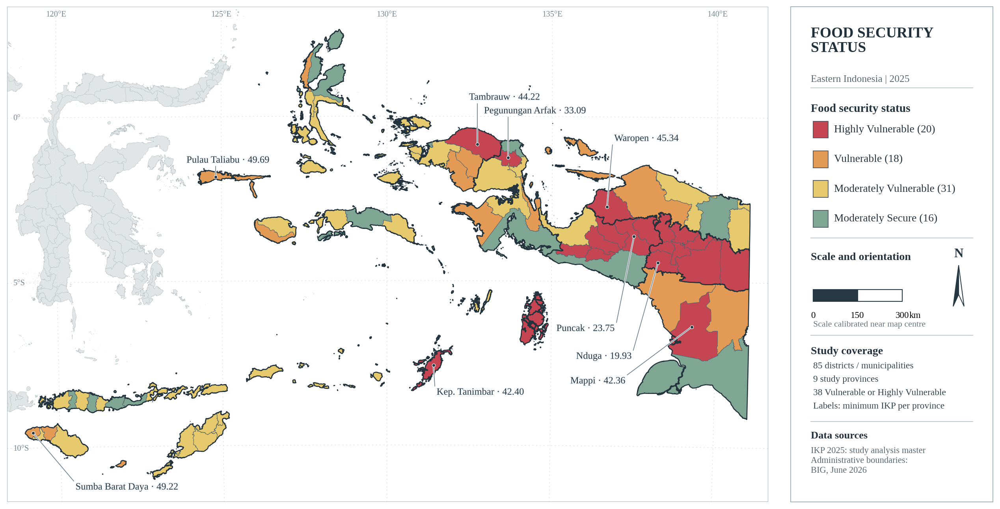


C. LATEX TEXT READABILITY
Figure width (in) : 14.4
LaTeX width (in)  : 11.5
Scaling factor   : 0.799


,element,original_pt,effective_pt
0,Compact annotations,9.8,7.83
1,Legend,11.0,8.78
2,Sidebar body,9.4,7.51
3,Source notes,9.0,7.19



CELL 21 — PUBLICATION ATLAS v4 COMPLETED
Districts          : 85
Provinces          : 9
Status categories  : 4
Compact annotations: 9
No text over land  : VERIFIED BY CONSTRAINT
No label overlaps  : VERIFIED BY CONSTRAINT
Original clusters  : UNCHANGED
New clustering fits: 0
Files saved        : False


In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 21
# PUBLICATION ATLAS v4 — MINIMAL ANNOTATIONS
# ================================================================
#
# MAIN OBJECTIVE
# Display the recorded 2025 food-security status
# of 85 Eastern Indonesian districts/municipalities.
#
# CARTOGRAPHIC DESIGN
# - Main geographic map + information sidebar
# - Original BIG administrative background
# - Four ordered IKP status colours
# - Nine provincial-minimum IKP annotations
# - ONE-LINE labels with NO annotation boxes
# - Labels cannot cover study-area polygons
# - Labels cannot overlap one another
# - Joint annotation layout optimization
# - Short, thin leader lines
# - Liberation Serif, English
# - Static PDF/PNG suitable for LaTeX
#
# PRESERVED
# - Original 85 spatial geometries
# - Original IKP values and status categories
# - Frozen clustering memberships
#
# NO CLUSTERING / NO NEW IKP / NO HTML
# ================================================================

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.patheffects as pe
import shapely

from pathlib import Path
from itertools import product
from matplotlib.patches import Rectangle
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.transforms import Bbox
from shapely.geometry import LineString, box
from pyproj import CRS, Transformer, Geod
from IPython.display import display


# ================================================================
# A. USER SETTINGS
# ================================================================

SAVE_FIGURE = False

SHOW_CALLOUTS = True
SHOW_GRATICULE = True
SHOW_COORDINATES = True

FONT_FAMILY = "Liberation Serif"

FIG_WIDTH = 14.4
FIG_DPI = 180

# Adjust to actual final width inside LaTeX.
LATEX_WIDTH_INCHES = 11.5

ANNOTATION_FONT = 9.8
LEGEND_FONT = 11.0

# Search settings
MAX_CANDIDATES_PER_LABEL = 32
BEAM_WIDTH = 100

# Annotation text clearance, in display pixels.
LABEL_PADDING_PX = 4.5

STATUS_COL = "IKP_2025_status_noninput"

STATUS_ORDER = [
    "Sangat Rentan",
    "Rentan",
    "Agak Rentan",
    "Agak Tahan"
]

STATUS_COLORS = {
    "Sangat Rentan": "#C64552",
    "Rentan": "#E39A54",
    "Agak Rentan": "#E6C96C",
    "Agak Tahan": "#7FA692"
}

STATUS_ENGLISH = {
    "Sangat Rentan": "Highly Vulnerable",
    "Rentan": "Vulnerable",
    "Agak Rentan": "Moderately Vulnerable",
    "Agak Tahan": "Moderately Secure"
}

SEA_COLOR = "#F5F8FA"
OTHER_LAND = "#E1E5E5"

DISTRICT_LINE = "#53636E"
PROVINCE_LINE = "#24343E"

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

OUTPUT_DIR = (
    ROOT / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
    / "publication_figures"
)


# ================================================================
# B. VERIFY FONT
# ================================================================

available_fonts = {
    f.name for f in fm.fontManager.ttflist
}

assert FONT_FAMILY in available_fonts, (
    "Liberation Serif is unavailable in Matplotlib."
)

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "font.size": 10.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
})


# ================================================================
# C. VERIFY ORIGINAL FOOD-SECURITY DATA
# ================================================================

assert "FOOD_MAP" in globals(), (
    "Run the verified Cell 19 first."
)

F = FOOD_MAP.copy()

assert len(F) == 85
assert F["kode_bps"].is_unique
assert F["provinsi"].nunique() == 9

assert F.geometry.notna().all()
assert not F.geometry.is_empty.any()
assert F.geometry.is_valid.all()

assert sorted(
    F["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]

assert set(F[STATUS_COL]) == set(STATUS_ORDER)

F["IKP_MAP"] = pd.to_numeric(
    F["IKP_MAP"],
    errors="raise"
)

assert np.isfinite(F["IKP_MAP"]).all()

F["kode_bps"] = (
    F["kode_bps"].astype(str).str.strip()
)

STATUS_COUNTS = F[STATUS_COL].value_counts()

assert [
    int(STATUS_COUNTS[s])
    for s in STATUS_ORDER
] == [20, 18, 31, 16]

N_VULNERABLE = int(
    F[STATUS_COL].isin([
        "Sangat Rentan",
        "Rentan"
    ]).sum()
)

assert N_VULNERABLE == 38


# ================================================================
# D. BIG CONTEXTUAL BASEMAP
# ================================================================

BIG_CACHE = (
    ROOT / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
    / "geospatial_cache_v1"
    / "BIG_541_context.gpkg"
)

if (
    "B" in globals()
    and isinstance(B, gpd.GeoDataFrame)
    and len(B) == 541
):

    BIG_BASE = B.copy()

else:

    assert BIG_CACHE.is_file(), (
        "BIG spatial cache unavailable. "
        "Run the verified Cell 16B."
    )

    BIG_BASE = gpd.read_file(
        BIG_CACHE,
        layer="big_context"
    )

assert len(BIG_BASE) == 541
assert BIG_BASE.crs is not None

BIG_BASE["geometry"] = (
    BIG_BASE.geometry.map(shapely.force_2d)
)

assert CRS.from_user_input(
    BIG_BASE.crs
).to_2d().to_epsg() == 4326

BIG_BASE = BIG_BASE.set_crs(
    "EPSG:4326",
    allow_override=True
)


# ================================================================
# E. MAP PROJECTION AND GEOGRAPHY
# ================================================================

MAP_CRS = CRS.from_proj4(
    "+proj=laea "
    "+lat_0=-4 "
    "+lon_0=130 "
    "+datum=WGS84 "
    "+units=m "
    "+no_defs "
    "+type=crs"
)

M = F.to_crs(MAP_CRS).copy()

BIG_MAP = BIG_BASE.to_crs(MAP_CRS)

PROV = M.dissolve(
    by="provinsi",
    as_index=False
)

assert len(PROV) == 9

TRANSFORMER = Transformer.from_crs(
    "EPSG:4326",
    MAP_CRS,
    always_xy=True
)

GEOD = Geod(ellps="WGS84")


# ================================================================
# F. FIND PROVINCIAL MINIMUM IKP
# ================================================================

PROVINCE_ORDER = [
    "Nusa Tenggara Timur",
    "Maluku",
    "Maluku Utara",
    "Papua Barat Daya",
    "Papua Barat",
    "Papua",
    "Papua Tengah",
    "Papua Pegunungan",
    "Papua Selatan"
]

assert set(PROVINCE_ORDER) == set(
    M["provinsi"].unique()
)

# Verify unique minimum within every province.
for province, group in M.groupby("provinsi"):

    minimum = group["IKP_MAP"].min()

    ties = np.isclose(
        group["IKP_MAP"],
        minimum,
        atol=1e-10,
        rtol=0
    )

    assert int(ties.sum()) == 1, (
        f"Tied IKP minimum: {province}"
    )

MINIMA = M.loc[
    M.groupby("provinsi")["IKP_MAP"].idxmin()
].copy()

MINIMA["_order"] = MINIMA["provinsi"].map({
    p: i for i, p in enumerate(PROVINCE_ORDER)
})

MINIMA = (
    MINIMA.sort_values("_order")
    .drop(columns="_order")
)

assert len(MINIMA) == 9

# Display-only abbreviation.
# Original district names in M remain unchanged.
DISPLAY_DISTRICT = {
    "Kepulauan Tanimbar": "Kep. Tanimbar"
}

MINIMA["annotation_label"] = MINIMA.apply(
    lambda row: (
        f"{DISPLAY_DISTRICT.get(row['kabupaten_kota'], row['kabupaten_kota'])}"
        f" · {row['IKP_MAP']:.2f}"
    ),
    axis=1
)

print("=" * 70)
print("A. VERIFIED PROVINCIAL MINIMUM IKP")
print("=" * 70)

display(
    MINIMA[
        [
            "provinsi",
            "kabupaten_kota",
            "IKP_MAP",
            STATUS_COL,
            "annotation_label"
        ]
    ].round(2)
)


# ================================================================
# G. MAP EXTENT AND ATLAS CANVAS
# ================================================================

xmin, ymin, xmax, ymax = M.total_bounds

dx = xmax - xmin
dy = ymax - ymin

XMIN = xmin - 0.025 * dx
XMAX = xmax + 0.025 * dx

YMIN = ymin - 0.050 * dy
YMAX = ymax + 0.050 * dy

XS = XMAX - XMIN
YS = YMAX - YMIN

MAP_ASPECT = XS / YS

MAP_RECT = [
    0.018,
    0.055,
    0.745,
    0.890
]

PANEL_RECT = [
    0.785,
    0.055,
    0.198,
    0.890
]

FIG_HEIGHT = (
    FIG_WIDTH * MAP_RECT[2]
    / (MAP_ASPECT * MAP_RECT[3])
)

BIG_DRAW = BIG_MAP.cx[
    XMIN:XMAX,
    YMIN:YMAX
].copy()


# ================================================================
# H. PREFERRED OFFSHORE LABEL REGIONS
# ================================================================
#
# Values are display locations, expressed as
# fractions of the map axes.
#
# They are NOT district coordinates.
#
# Candidate positions are searched around these
# offshore regions and close to district anchors.
# ================================================================

PREFERRED_SEA_POSITIONS = {

    "Nusa Tenggara Timur": [
        (0.14, 0.34),
        (0.10, 0.39),
        (0.22, 0.35)
    ],

    "Maluku": [
        (0.45, 0.29),
        (0.50, 0.25),
        (0.40, 0.35)
    ],

    "Maluku Utara": [
        (0.29, 0.75),
        (0.35, 0.80),
        (0.24, 0.78)
    ],

    "Papua Barat Daya": [
        (0.54, 0.72),
        (0.58, 0.81),
        (0.48, 0.67)
    ],

    "Papua Barat": [
        (0.70, 0.88),
        (0.66, 0.92),
        (0.76, 0.88)
    ],

    "Papua": [
        (0.84, 0.82),
        (0.88, 0.90),
        (0.80, 0.91)
    ],

    "Papua Tengah": [
        (0.72, 0.35),
        (0.68, 0.28),
        (0.77, 0.25)
    ],

    "Papua Pegunungan": [
        (0.86, 0.27),
        (0.91, 0.26),
        (0.82, 0.21)
    ],

    "Papua Selatan": [
        (0.91, 0.13),
        (0.85, 0.12),
        (0.96, 0.19)
    ]
}

assert set(PREFERRED_SEA_POSITIONS) == set(
    PROVINCE_ORDER
)


# ================================================================
# I. GEOGRAPHIC GRATICULE
# ================================================================

def draw_graticule(ax):

    color = "#CED9DF"

    # Meridians.
    for lon in range(115, 146, 5):

        lats = np.linspace(-20, 12, 400)
        lons = np.full_like(lats, lon)

        xx, yy = TRANSFORMER.transform(
            lons, lats
        )

        ax.plot(
            xx, yy,
            color=color,
            linewidth=0.42,
            linestyle=(0, (3, 6)),
            zorder=0.6
        )

        # Coordinate labels at the top frame.
        if SHOW_COORDINATES:

            line = LineString(
                zip(xx, yy)
            )

            upper = LineString([
                (XMIN, YMAX),
                (XMAX, YMAX)
            ])

            intersection = line.intersection(
                upper
            )

            if intersection.geom_type == "Point":

                ax.text(
                    intersection.x,
                    YMAX - 0.008 * YS,
                    f"{lon}°E",
                    fontsize=8.3,
                    color="#758690",
                    ha="center",
                    va="top",
                    zorder=6
                )

    # Parallels.
    for lat in [-10, -5, 0, 5]:

        lons = np.linspace(108, 150, 450)
        lats = np.full_like(lons, lat)

        xx, yy = TRANSFORMER.transform(
            lons, lats
        )

        ax.plot(
            xx, yy,
            color=color,
            linewidth=0.42,
            linestyle=(0, (3, 6)),
            zorder=0.6
        )

        if SHOW_COORDINATES:

            line = LineString(
                zip(xx, yy)
            )

            left = LineString([
                (XMIN, YMIN),
                (XMIN, YMAX)
            ])

            intersection = line.intersection(
                left
            )

            if intersection.geom_type == "Point":

                label = (
                    "0°" if lat == 0
                    else (
                        f"{abs(lat)}°"
                        + ("S" if lat < 0 else "N")
                    )
                )

                ax.text(
                    XMIN + 0.008 * XS,
                    intersection.y,
                    label,
                    fontsize=8.3,
                    color="#758690",
                    ha="left",
                    va="center",
                    zorder=6
                )


# ================================================================
# J. NORTH ARROW — CARTOGRAPHIC NEEDLE
# ================================================================

def draw_north_arrow(ax):

    cx = 0.83
    tr = ax.transAxes

    ax.text(
        cx, 0.489,
        "N",
        transform=tr,
        fontsize=13,
        fontweight="bold",
        ha="center",
        va="bottom",
        color="#263844"
    )

    ax.add_patch(
        MplPolygon(
            [
                [cx, 0.478],
                [cx - 0.027, 0.395],
                [cx, 0.419]
            ],
            closed=True,
            transform=tr,
            facecolor="#263844",
            edgecolor="#263844",
            linewidth=0.8
        )
    )

    ax.add_patch(
        MplPolygon(
            [
                [cx, 0.478],
                [cx + 0.027, 0.395],
                [cx, 0.419]
            ],
            closed=True,
            transform=tr,
            facecolor="white",
            edgecolor="#263844",
            linewidth=0.8
        )
    )


# ================================================================
# K. LOCALLY CALIBRATED SCALE BAR
# ================================================================

def draw_scale_bar(ax):

    map_inches = FIG_WIDTH * MAP_RECT[2]
    panel_inches = FIG_WIDTH * PANEL_RECT[2]

    x0, y0 = TRANSFORMER.transform(
        130, -4
    )

    chosen_km = None
    bar_fraction = None

    for km in [500, 400, 300, 200, 100, 50]:

        lon2, lat2, _ = GEOD.fwd(
            130, -4, 90,
            km * 1000
        )

        x1, y1 = TRANSFORMER.transform(
            lon2, lat2
        )

        length = np.hypot(
            x1 - x0,
            y1 - y0
        )

        fraction = (
            length / XS
            * map_inches / panel_inches
        )

        if fraction <= 0.56:
            chosen_km = km
            bar_fraction = fraction
            break

    assert chosen_km is not None

    x_start = 0.11
    x_middle = x_start + bar_fraction / 2
    x_end = x_start + bar_fraction

    y = 0.405

    for x, colour in [
        (x_start, "#263844"),
        (x_middle, "white")
    ]:

        ax.add_patch(
            Rectangle(
                (x, y),
                bar_fraction / 2,
                0.024,
                transform=ax.transAxes,
                facecolor=colour,
                edgecolor="#263844",
                linewidth=0.85
            )
        )

    for x, text in [
        (x_start, "0"),
        (x_middle, f"{chosen_km/2:g}"),
        (x_end, f"{chosen_km:g}")
    ]:

        ax.text(
            x,
            y - 0.020,
            text,
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=9.2
        )

    # Deliberate spacing before the unit.
    ax.text(
        x_end + 0.035,
        y - 0.020,
        "km",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9.2
    )

    return chosen_km


# ================================================================
# L. TEXT AND LABEL GEOMETRY HELPERS
# ================================================================

def text_size_pixels(ax, text, renderer):

    # Measure text using the actual Liberation Serif
    # font, figure DPI, and Matplotlib renderer.
    temp = ax.text(
        0.5, 0.5,
        text,
        transform=ax.transAxes,
        fontsize=ANNOTATION_FONT,
        ha="center",
        va="center"
    )

    extent = temp.get_window_extent(
        renderer
    )

    temp.remove()

    return (
        float(extent.width),
        float(extent.height)
    )


def display_box(ax, position, width_px, height_px):

    cx = (
        ax.bbox.x0
        + position[0] * ax.bbox.width
    )

    cy = (
        ax.bbox.y0
        + position[1] * ax.bbox.height
    )

    return Bbox.from_bounds(
        cx - width_px / 2 - LABEL_PADDING_PX,
        cy - height_px / 2 - LABEL_PADDING_PX,
        width_px + 2 * LABEL_PADDING_PX,
        height_px + 2 * LABEL_PADDING_PX
    )


def box_to_data(ax, bbox):

    p0 = ax.transData.inverted().transform(
        (bbox.x0, bbox.y0)
    )

    p1 = ax.transData.inverted().transform(
        (bbox.x1, bbox.y1)
    )

    return box(
        min(p0[0], p1[0]),
        min(p0[1], p1[1]),
        max(p0[0], p1[0]),
        max(p0[1], p1[1])
    )


def box_to_display_polygon(bbox):

    return box(
        bbox.x0,
        bbox.y0,
        bbox.x1,
        bbox.y1
    )


def make_leader(ax, point, text_bbox):

    start = ax.transData.transform(
        (point.x, point.y)
    )

    # Snap leader endpoint to nearest point
    # of text bounds, not text centre.
    endpoint = np.array([
        np.clip(
            start[0],
            text_bbox.x0,
            text_bbox.x1
        ),
        np.clip(
            start[1],
            text_bbox.y0,
            text_bbox.y1
        )
    ])

    line_pixels = LineString([
        tuple(start),
        tuple(endpoint)
    ])

    length_pt = (
        line_pixels.length
        * 72 / ax.figure.dpi
    )

    endpoint_data = (
        ax.transData.inverted().transform(
            endpoint
        )
    )

    line_data = LineString([
        (point.x, point.y),
        tuple(endpoint_data)
    ])

    return (
        line_pixels,
        line_data,
        float(length_pt)
    )


# ================================================================
# M. GENERATE CANDIDATE LABEL POSITIONS
# ================================================================

def generate_positions(ax, point, province):

    positions = []

    # 1. Preferred offshore zones.
    offsets = [
        (0.00, 0.00),
        (-0.02, 0.00), (0.02, 0.00),
        (0.00, -0.03), (0.00, 0.03),
        (-0.04, 0.00), (0.04, 0.00),
        (-0.02, -0.03), (0.02, -0.03),
        (-0.02, 0.03), (0.02, 0.03),
        (0.00, -0.06), (0.00, 0.06)
    ]

    for base in PREFERRED_SEA_POSITIONS[province]:

        for ox, oy in offsets:

            positions.append((
                base[0] + ox,
                base[1] + oy
            ))

    # 2. Additional nearby radial positions.
    anchor_px = ax.transData.transform(
        (point.x, point.y)
    )

    distances_pt = [
        55, 80, 110, 145, 185, 235
    ]

    angles_deg = np.arange(
        0, 360, 30
    )

    for distance_pt, angle_deg in product(
        distances_pt,
        angles_deg
    ):

        angle = np.deg2rad(angle_deg)

        distance_px = (
            distance_pt
            * ax.figure.dpi / 72
        )

        candidate_px = (
            anchor_px
            + distance_px * np.array([
                np.cos(angle),
                np.sin(angle)
            ])
        )

        candidate_axes = (
            ax.transAxes.inverted().transform(
                candidate_px
            )
        )

        positions.append(
            tuple(candidate_axes)
        )

    # Remove duplicate candidates.
    return list(dict.fromkeys(
        (round(float(x), 5), round(float(y), 5))
        for x, y in positions
    ))


# ================================================================
# N. SCREEN-ACCURATE CANDIDATE EVALUATION
# ================================================================

def build_candidates(ax, row, renderer):

    point = row.geometry.representative_point()
    province = row["provinsi"]
    label = row["annotation_label"]

    width_px, height_px = text_size_pixels(
        ax, label, renderer
    )

    candidates = []

    for position in generate_positions(
        ax, point, province
    ):

        bbox = display_box(
            ax,
            position,
            width_px,
            height_px
        )

        # HARD CONSTRAINT 1:
        # Text must remain inside the map.
        frame = ax.bbox

        margin = 5

        if (
            bbox.x0 < frame.x0 + margin
            or bbox.x1 > frame.x1 - margin
            or bbox.y0 < frame.y0 + margin
            or bbox.y1 > frame.y1 - margin
        ):
            continue

        rectangle = box_to_data(
            ax, bbox
        )

        # HARD CONSTRAINT 2:
        # Text cannot cover ANY of the study
        # district polygons.
        study_hits = M.sindex.query(
            rectangle,
            predicate="intersects"
        )

        if len(study_hits) > 0:
            continue

        # Prefer not to cover contextual BIG land,
        # including Sulawesi.
        context_hits = BIG_DRAW.sindex.query(
            rectangle,
            predicate="intersects"
        )

        if len(context_hits) > 0:
            continue

        leader_px, leader_data, length_pt = (
            make_leader(
                ax, point, bbox
            )
        )

        # Penalize leader lines crossing OTHER
        # study districts. Some inland districts
        # inevitably require crossing land.
        land_crossing = 0.0

        if leader_data.length > 0:

            hits = M.sindex.query(
                leader_data,
                predicate="intersects"
            )

            for idx in hits:

                other = M.iloc[int(idx)]

                if (
                    str(other["kode_bps"])
                    == str(row["kode_bps"])
                ):
                    continue

                land_crossing += (
                    leader_data.intersection(
                        other.geometry
                    ).length
                )

        crossing_fraction = (
            land_crossing
            / max(leader_data.length, 1e-12)
        )

        # Single-label score. Lower is better.
        local_score = (
            length_pt
            + 190 * crossing_fraction
        )

        candidates.append({
            "province": province,
            "position": position,
            "bbox": bbox,
            "box_px": box_to_display_polygon(bbox),
            "leader_px": leader_px,
            "leader_data": leader_data,
            "length_pt": length_pt,
            "crossed_land_fraction": crossing_fraction,
            "score": local_score
        })

    candidates.sort(
        key=lambda item: item["score"]
    )

    return candidates[
        :MAX_CANDIDATES_PER_LABEL
    ]


# ================================================================
# O. JOINT LABEL OPTIMIZATION
# ================================================================
#
# Beam search considers combinations of labels.
#
# It does not finalize one label without
# considering possible placements of later labels.
#
# HARD CONSTRAINTS:
# - no text outside map
# - no text on land
# - no text-text overlap
# - no leader crossing another text label
#
# Leader-leader crossings are penalized.
# ================================================================

def optimize_all_labels(fig, ax):

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    candidate_sets = {}

    rows = {}

    for _, row in MINIMA.iterrows():

        province = row["provinsi"]

        rows[province] = row

        options = build_candidates(
            ax, row, renderer
        )

        if not options:
            raise RuntimeError(
                "No offshore annotation placement "
                f"found for {province}. "
                "Increase the canvas or adjust "
                "PREFERRED_SEA_POSITIONS."
            )

        candidate_sets[province] = options

    # Process the most constrained labels first.
    placement_order = sorted(
        PROVINCE_ORDER,
        key=lambda p: (
            len(candidate_sets[p]),
            PROVINCE_ORDER.index(p)
        )
    )

    # Each beam item:
    # (total_score, {province: candidate})
    beam = [(0.0, {})]

    for province in placement_order:

        new_beam = []

        for total_score, selected in beam:

            for option in candidate_sets[province]:

                valid = True
                extra_cost = 0.0

                for old in selected.values():

                    # No text-text intersection.
                    if option["box_px"].intersects(
                        old["box_px"]
                    ):
                        valid = False
                        break

                    # Leaders must not enter
                    # another label's text.
                    if (
                        option["leader_px"].intersects(
                            old["box_px"]
                        )
                        or old["leader_px"].intersects(
                            option["box_px"]
                        )
                    ):
                        valid = False
                        break

                    # Penalize leader crossings.
                    if option["leader_px"].crosses(
                        old["leader_px"]
                    ):
                        extra_cost += 180

                if not valid:
                    continue

                updated = dict(selected)
                updated[province] = option

                new_beam.append((
                    total_score
                    + option["score"]
                    + extra_cost,
                    updated
                ))

        if not new_beam:

            raise RuntimeError(
                "No collision-free layout found "
                f"while placing {province}. "
                "The figure was not exported. "
                "Increase the map canvas or widen "
                "the offshore candidate regions."
            )

        new_beam.sort(
            key=lambda state: state[0]
        )

        beam = new_beam[:BEAM_WIDTH]

    best_score, best_layout = beam[0]

    assert len(best_layout) == 9

    return best_layout, best_score, rows


# ================================================================
# P. DRAW COMPACT, BOX-FREE ANNOTATIONS
# ================================================================

def draw_minimum_labels(fig, ax):

    layout, total_score, rows = (
        optimize_all_labels(fig, ax)
    )

    audits = []

    # Draw all leaders behind the text.
    for province in PROVINCE_ORDER:

        option = layout[province]

        line = option["leader_data"]

        xx, yy = line.xy

        # Thin white underlay keeps the leader
        # distinguishable over dark status polygons.
        ax.plot(
            xx, yy,
            color="white",
            linewidth=1.65,
            zorder=6,
            solid_capstyle="round"
        )

        ax.plot(
            xx, yy,
            color="#71838F",
            linewidth=0.72,
            zorder=7,
            solid_capstyle="round"
        )

    # Draw compact text and accurate point anchors.
    for province in PROVINCE_ORDER:

        option = layout[province]
        row = rows[province]

        px, py = option["position"]

        ax.text(
            px,
            py,
            row["annotation_label"],
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=ANNOTATION_FONT,
            color="#273742",
            zorder=9,
            clip_on=True,
            path_effects=[
                pe.withStroke(
                    linewidth=2.1,
                    foreground=SEA_COLOR
                )
            ]
        )

        point = row.geometry.representative_point()

        ax.scatter(
            point.x,
            point.y,
            s=11,
            facecolor="#263844",
            edgecolor="white",
            linewidth=0.5,
            zorder=10
        )

        audits.append({
            "province": province,
            "district": row["kabupaten_kota"],
            "IKP": float(row["IKP_MAP"]),
            "x_fraction": px,
            "y_fraction": py,
            "leader_length_pt": option["length_pt"],
            "other_districts_crossed_fraction": (
                option["crossed_land_fraction"]
            ),
            "text_over_study_land": False,
            "text_over_context_land": False,
            "text_overlap": False,
            "outside_frame": False
        })

    audit = pd.DataFrame(audits)

    print("\nB. COMPACT ANNOTATION AUDIT")
    display(audit.round(3))

    print(
        "Combined layout score:",
        round(total_score, 2)
    )

    if audit["leader_length_pt"].max() > 160:

        print(
            "NOTE: One or more annotation leaders "
            "remain relatively long. Consider "
            "reviewing them visually."
        )

    return audit


# ================================================================
# Q. DRAW COMPLETE ATLAS
# ================================================================

def draw_food_security_atlas_v4(save=False):

    fig = plt.figure(
        figsize=(FIG_WIDTH, FIG_HEIGHT),
        dpi=FIG_DPI,
        facecolor="white"
    )

    ax_map = fig.add_axes(MAP_RECT)
    ax_panel = fig.add_axes(PANEL_RECT)

    ax_map.set_facecolor(SEA_COLOR)
    ax_panel.set_facecolor("white")

    # --------------------------------------------------------
    # Q1. CONTEXTUAL LAND
    # --------------------------------------------------------

    BIG_DRAW.plot(
        ax=ax_map,
        facecolor=OTHER_LAND,
        edgecolor="#B8C2C5",
        linewidth=0.24,
        zorder=0
    )

    # --------------------------------------------------------
    # Q2. GEOGRAPHIC GRATICULE
    # --------------------------------------------------------

    if SHOW_GRATICULE:
        draw_graticule(ax_map)

    # --------------------------------------------------------
    # Q3. THEMATIC POLYGONS
    # --------------------------------------------------------

    for status in STATUS_ORDER:

        part = M.loc[
            M[STATUS_COL] == status
        ]

        part.plot(
            ax=ax_map,
            facecolor=STATUS_COLORS[status],
            edgecolor=DISTRICT_LINE,
            linewidth=0.40,
            zorder=2
        )

    PROV.boundary.plot(
        ax=ax_map,
        color=PROVINCE_LINE,
        linewidth=1.0,
        zorder=3
    )

    ax_map.set_xlim(XMIN, XMAX)
    ax_map.set_ylim(YMIN, YMAX)

    ax_map.set_aspect(
        "equal",
        adjustable="box"
    )

    ax_map.set_axis_off()

    # Geographic frame.
    ax_map.add_patch(
        Rectangle(
            (XMIN, YMIN),
            XS, YS,
            fill=False,
            edgecolor="#A7B4BB",
            linewidth=0.85,
            zorder=11
        )
    )

    # --------------------------------------------------------
    # Q4. MINIMAL ANNOTATIONS
    # --------------------------------------------------------

    annotation_audit = None

    if SHOW_CALLOUTS:

        annotation_audit = draw_minimum_labels(
            fig, ax_map
        )

    # --------------------------------------------------------
    # Q5. INFORMATION PANEL
    # --------------------------------------------------------

    ax_panel.set_xlim(0, 1)
    ax_panel.set_ylim(0, 1)

    ax_panel.set_xticks([])
    ax_panel.set_yticks([])

    for spine in ax_panel.spines.values():
        spine.set_color("#A7B4BB")
        spine.set_linewidth(0.85)

    # Header
    ax_panel.text(
        0.10, 0.960,
        "FOOD SECURITY\nSTATUS",
        transform=ax_panel.transAxes,
        fontsize=15,
        fontweight="bold",
        linespacing=1.08,
        ha="left",
        va="top",
        color="#21313C"
    )

    ax_panel.text(
        0.10, 0.862,
        "Eastern Indonesia | 2025",
        transform=ax_panel.transAxes,
        fontsize=10.2,
        va="top",
        color="#5A6872"
    )

    # Panel divider
    ax_panel.plot(
        [0.10, 0.90],
        [0.836, 0.836],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # Q6. STATUS LEGEND
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.805,
        "Food security status",
        transform=ax_panel.transAxes,
        fontsize=11.8,
        fontweight="bold",
        va="top",
        color="#24343E"
    )

    legend_positions = [
        0.752, 0.692, 0.632, 0.572
    ]

    for status, y in zip(
        STATUS_ORDER,
        legend_positions
    ):

        ax_panel.add_patch(
            Rectangle(
                (0.11, y - 0.017),
                0.075,
                0.034,
                transform=ax_panel.transAxes,
                facecolor=STATUS_COLORS[status],
                edgecolor="#46545E",
                linewidth=0.7
            )
        )

        ax_panel.text(
            0.215,
            y,
            (
                f"{STATUS_ENGLISH[status]} "
                f"({int(STATUS_COUNTS[status])})"
            ),
            transform=ax_panel.transAxes,
            fontsize=LEGEND_FONT,
            ha="left",
            va="center",
            color="#26333E"
        )

    ax_panel.plot(
        [0.10, 0.90],
        [0.533, 0.533],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # Q7. SCALE AND ORIENTATION
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.504,
        "Scale and orientation",
        transform=ax_panel.transAxes,
        fontsize=11.2,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    scale_km = draw_scale_bar(
        ax_panel
    )

    draw_north_arrow(
        ax_panel
    )

    ax_panel.text(
        0.11,
        0.366,
        "Scale calibrated near map centre",
        transform=ax_panel.transAxes,
        fontsize=8.8,
        color="#66747C",
        va="top"
    )

    ax_panel.plot(
        [0.10, 0.90],
        [0.337, 0.337],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # Q8. STUDY COVERAGE
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.314,
        "Study coverage",
        transform=ax_panel.transAxes,
        fontsize=11.2,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    study_lines = [
        "85 districts / municipalities",
        "9 study provinces",
        "38 Vulnerable or Highly Vulnerable",
        "Labels: minimum IKP per province"
    ]

    for i, text in enumerate(study_lines):

        ax_panel.text(
            0.11,
            0.283 - i * 0.027,
            text,
            transform=ax_panel.transAxes,
            fontsize=9.4,
            va="top",
            color="#34434C"
        )

    ax_panel.plot(
        [0.10, 0.90],
        [0.162, 0.162],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # Q9. DATA SOURCES
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.143,
        "Data sources",
        transform=ax_panel.transAxes,
        fontsize=10.6,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    ax_panel.text(
        0.10, 0.112,
        (
            "IKP 2025: study analysis master\n"
            "Administrative boundaries:\n"
            "BIG, June 2026"
        ),
        transform=ax_panel.transAxes,
        fontsize=9.0,
        linespacing=1.25,
        va="top",
        color="#596872"
    )

    # --------------------------------------------------------
    # Q10. OPTIONAL PDF / PNG EXPORT
    # --------------------------------------------------------

    if save:

        OUTPUT_DIR.mkdir(
            parents=True,
            exist_ok=True
        )

        pdf_path = (
            OUTPUT_DIR /
            "FoodSecurity_Status_Atlas_v4.pdf"
        )

        png_path = (
            OUTPUT_DIR /
            "FoodSecurity_Status_Atlas_v4.png"
        )

        fig.savefig(
            pdf_path,
            format="pdf",
            dpi=300,
            facecolor="white"
        )

        fig.savefig(
            png_path,
            format="png",
            dpi=300,
            facecolor="white"
        )

        print("\nSaved PDF:", pdf_path)
        print("Saved PNG:", png_path)

    plt.show()

    return fig, annotation_audit, scale_km


# ================================================================
# R. RENDER
# ================================================================

FIG_IKP, ANNOTATION_AUDIT, SCALE_KM = (
    draw_food_security_atlas_v4(
        save=SAVE_FIGURE
    )
)


# ================================================================
# S. PUBLICATION SIZE AUDIT
# ================================================================

scale_factor = LATEX_WIDTH_INCHES / FIG_WIDTH

PRINT_AUDIT = pd.DataFrame([
    {
        "element": "Compact annotations",
        "original_pt": ANNOTATION_FONT
    },
    {
        "element": "Legend",
        "original_pt": LEGEND_FONT
    },
    {
        "element": "Sidebar body",
        "original_pt": 9.4
    },
    {
        "element": "Source notes",
        "original_pt": 9.0
    }
])

PRINT_AUDIT["effective_pt"] = (
    PRINT_AUDIT["original_pt"] * scale_factor
)

print("\n" + "=" * 70)
print("C. LATEX TEXT READABILITY")
print("=" * 70)

print("Figure width (in) :", FIG_WIDTH)
print("LaTeX width (in)  :", LATEX_WIDTH_INCHES)
print("Scaling factor   :", round(scale_factor, 3))

display(PRINT_AUDIT.round(2))

if PRINT_AUDIT["effective_pt"].min() < 7.0:

    print(
        "WARNING: Some text may be too small "
        "at the intended publication width."
    )

print("\n" + "=" * 70)
print("CELL 21 — PUBLICATION ATLAS v4 COMPLETED")
print("=" * 70)

print("Districts          :", len(M))
print("Provinces          :", len(PROV))
print("Status categories  :", len(STATUS_ORDER))
print("Compact annotations:", 9 if SHOW_CALLOUTS else 0)
print("No text over land  : VERIFIED BY CONSTRAINT")
print("No label overlaps  : VERIFIED BY CONSTRAINT")
print("Original clusters  : UNCHANGED")
print("New clustering fits: 0")
print("Files saved        :", SAVE_FIGURE)
print("=" * 70)


# Quality-Only Multi-View Atlas

A. FROZEN MULTI-VIEW MODEL VERIFIED
Selection policy : Quality-only
Model            : Multi_K2_G5_S10_food50
Integration      : Weighted affinity fusion
K                : 2
Graph neighbours : 5
Local scale      : 10
Food weight      : 0.50
Climate weight   : 0.25
Access weight    : 0.25
Original labels  : 85/85 exact matches
Clustering refit : NO

B. FOOD SECURITY CONTEXT BY MULTI-VIEW CLUSTER


,n,mean_IKP,median_IKP,min_IKP,max_IKP,vulnerable_n,vulnerable_pct
cluster_Q,,,,,,,
0,66,56.582,56.73,42.40,67.43,19,28.788
1,19,34.051,33.09,19.93,46.97,19,100.000



C. RECORDED IKP STATUS BY MULTI-VIEW CLUSTER


IKP_2025_status_noninput,Sangat Rentan,Rentan,Agak Rentan,Agak Tahan
cluster_Q,,,,
0,3,16,31,16
1,17,2,0,0



D. QUALITY-ONLY × STABILITY-AWARE PARTITIONS


cluster_SA,0,1,2
cluster_Q,,,
0,27,38,1
1,0,1,18



E. POST-HOC NINE-INDICATOR PROFILES
Mean deviations from the study-wide mean (SD)


,F1_ikp_ketersediaan,F2_ikp_keterjangkauan,F3_ikp_pemanfaatan,C1_anomali_hujan_mm,C2_cdd_hari,C3_hari_hujan_ekstrem,A1_persen_tanpa_angkutan,A2_persen_jalan_tanah_lainnya,A3_persen_tanpa_pertokoan_pasar
cluster_Q,,,,,,,,,
0,0.292,0.409,0.421,0.152,0.110,0.060,-0.308,-0.420,-0.151
1,-1.016,-1.420,-1.461,-0.528,-0.381,-0.207,1.070,1.459,0.525


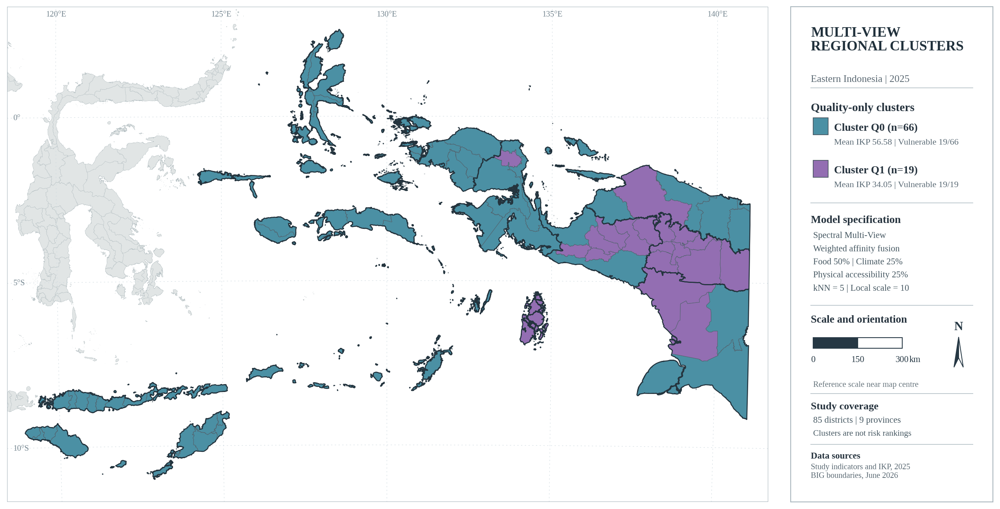


F. LATEX READABILITY AUDIT


,element,original_pt,effective_pt
0,Cluster label,11.0,8.78
1,Food-security context,8.9,7.11
2,Model specification,9.0,7.19
3,Source note,8.1,6.47



CELL 22 — QUALITY-ONLY MULTI-VIEW ATLAS
Frozen model       : Multi_K2_G5_S10_food50
Mapped districts   : 85
Mapped provinces   : 9
Cluster Q0         : 66
Cluster Q1         : 19
Original labels    : VERIFIED 85/85
BIG background     : 188
Projection         : Regional LAEA
Local scale bar    : 300 km
Font               : Liberation Serif
Original models    : UNCHANGED
New clustering fits: 0
Files saved        : False


In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 22
# QUALITY-ONLY SPECTRAL MULTI-VIEW ATLAS
# ================================================================
#
# MODEL:
# Multi_K2_G5_S10_food50
#
# Integration:
# Spectral Multi-View Affinity Fusion
#
# View weights:
# Food          = 0.50
# Climate       = 0.25
# Accessibility = 0.25
#
# Clusters:
# Q0 = 66 districts
# Q1 = 19 districts
#
# VISUAL DESIGN:
# Same atlas layout as approved Cell 21 v4
#
# - Main geographic map, left
# - Separate information panel, right
# - BIG administrative background
# - District and province boundaries
# - Geographic graticule and coordinate labels
# - Liberation Serif
# - Refined north arrow
# - Locally calibrated scale bar
# - No district callouts
#
# No clustering refit.
# No new index construction.
# No modification of frozen results.
# No automatic file saving.
# ================================================================

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import shapely
import hashlib
import json

from pathlib import Path
from matplotlib.patches import Rectangle
from matplotlib.patches import Polygon as MplPolygon
from shapely.geometry import LineString
from pyproj import CRS, Transformer, Geod
from IPython.display import display


# ================================================================
# A. SETTINGS
# ================================================================

SAVE_FIGURE = False

SHOW_GRATICULE = True
SHOW_COORDINATES = True

FONT_FAMILY = "Liberation Serif"

FIG_WIDTH = 14.4
FIG_DPI = 180

# Expected final width in LaTeX.
LATEX_WIDTH_INCHES = 11.5

# Cluster colours are nominal.
# They do not indicate ordered food-security risks.

CLUSTER_COLORS = {
    0: "#4B90A4",
    1: "#936EB2"
}

SEA_COLOR = "#F5F8FA"
OTHER_LAND = "#E1E5E5"

DISTRICT_LINE = "#53636E"
PROVINCE_LINE = "#24343E"

MODEL_ID = "Multi_K2_G5_S10_food50"

ROOT = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

GRID_DIR = (
    ROOT / "03_outputs"
    / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

SEL_DIR = (
    ROOT / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

LABELS_PATH = GRID_DIR / "labels_all.csv"
SELECTED_PATH = SEL_DIR / "primary_selections.csv"
SEAL_PATH = SEL_DIR / "selection_seal.json"

BIG_CACHE = (
    SEL_DIR
    / "geospatial_cache_v1"
    / "BIG_541_context.gpkg"
)

OUTPUT_DIR = (
    SEL_DIR / "publication_figures"
)


# ================================================================
# B. FONT VERIFICATION
# ================================================================

available_fonts = {
    f.name
    for f in fm.fontManager.ttflist
}

assert FONT_FAMILY in available_fonts, (
    "Liberation Serif is unavailable. "
    "Install fonts-liberation and refresh "
    "the Matplotlib font manager."
)

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "font.size": 10.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.facecolor": "white",
    "savefig.facecolor": "white"
})


# ================================================================
# C. VERIFY ORIGINAL SPATIAL AND FOOD DATA
# ================================================================

assert "FOOD_MAP" in globals(), (
    "FOOD_MAP is unavailable. "
    "Run the verified Cell 19 first."
)

F = FOOD_MAP.copy()

assert len(F) == 85
assert F["kode_bps"].is_unique
assert F["provinsi"].nunique() == 9

assert F.geometry.notna().all()
assert not F.geometry.is_empty.any()
assert F.geometry.is_valid.all()

assert set(F["cluster_Q"]) == {0, 1}
assert set(F["cluster_SA"]) == {0, 1, 2}

assert sorted(
    F["cluster_Q"].value_counts().tolist()
) == [19, 66]

assert sorted(
    F["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]

F["kode_bps"] = (
    F["kode_bps"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0+$", "", regex=True)
)

F["cluster_Q"] = pd.to_numeric(
    F["cluster_Q"], errors="raise"
).astype(int)

F["cluster_SA"] = pd.to_numeric(
    F["cluster_SA"], errors="raise"
).astype(int)

F["IKP_MAP"] = pd.to_numeric(
    F["IKP_MAP"], errors="raise"
)

assert np.isfinite(F["IKP_MAP"]).all()

assert "IKP_2025_status_noninput" in F.columns

F["recorded_vulnerable"] = (
    F["IKP_2025_status_noninput"].isin([
        "Sangat Rentan",
        "Rentan"
    ])
)

assert int(F["recorded_vulnerable"].sum()) == 38


# ================================================================
# D. VERIFY MODEL AGAINST FROZEN SOURCES
# ================================================================

def sha256(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)

    return h.hexdigest()


for path in [
    LABELS_PATH,
    SELECTED_PATH,
    SEAL_PATH
]:
    assert path.is_file(), path


with open(SEAL_PATH, encoding="utf-8") as f:
    SEAL = json.load(f)

assert SEAL["status"] == "FROZEN"

assert sha256(SELECTED_PATH) == (
    SEAL["primary_selections_sha256"]
)

SELECTED = pd.read_csv(
    SELECTED_PATH
)

quality = SELECTED.loc[
    SELECTED["policy"].eq("quality_only")
]

assert len(quality) == 1

assert (
    quality.iloc[0]["model_id"]
    == MODEL_ID
)

LABELS = pd.read_csv(
    LABELS_PATH,
    dtype={"kode_bps": "string"}
)

assert MODEL_ID in LABELS.columns

LABELS["kode_bps"] = (
    LABELS["kode_bps"]
    .str.strip()
    .str.replace(r"\.0+$", "", regex=True)
)

assert len(LABELS) == 85
assert LABELS["kode_bps"].is_unique

CHECK = F[
    ["kode_bps", "cluster_Q"]
].merge(
    LABELS[
        ["kode_bps", MODEL_ID]
    ],
    on="kode_bps",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert len(CHECK) == 85
assert CHECK["_merge"].eq("both").all()

assert (
    CHECK["cluster_Q"].to_numpy(dtype=int)
    ==
    CHECK[MODEL_ID].to_numpy(dtype=int)
).all(), (
    "Mapped cluster memberships differ "
    "from the frozen original labels."
)

CLUSTER_COUNTS = (
    F["cluster_Q"]
    .value_counts()
    .sort_index()
)

assert CLUSTER_COUNTS.to_dict() == {
    0: 66,
    1: 19
}

print("=" * 70)
print("A. FROZEN MULTI-VIEW MODEL VERIFIED")
print("=" * 70)

print("Selection policy : Quality-only")
print("Model            :", MODEL_ID)
print("Integration      : Weighted affinity fusion")
print("K                : 2")
print("Graph neighbours : 5")
print("Local scale      : 10")
print("Food weight      : 0.50")
print("Climate weight   : 0.25")
print("Access weight    : 0.25")
print("Original labels  : 85/85 exact matches")
print("Clustering refit : NO")


# ================================================================
# E. SUBSTANTIVE CLUSTER DIAGNOSTICS
# ================================================================
#
# IKP aggregate is used ONLY for post-clustering
# interpretation; it is not added to model inputs.
#
# These summaries are descriptive, not
# independent validation of clustering.
# ================================================================

Q_SUMMARY = (
    F.groupby("cluster_Q")
    .agg(
        n=("kode_bps", "size"),
        mean_IKP=("IKP_MAP", "mean"),
        median_IKP=("IKP_MAP", "median"),
        min_IKP=("IKP_MAP", "min"),
        max_IKP=("IKP_MAP", "max"),
        vulnerable_n=("recorded_vulnerable", "sum")
    )
)

Q_SUMMARY["vulnerable_pct"] = (
    100
    * Q_SUMMARY["vulnerable_n"]
    / Q_SUMMARY["n"]
)

print("\nB. FOOD SECURITY CONTEXT BY MULTI-VIEW CLUSTER")
display(Q_SUMMARY.round(3))

print("\nC. RECORDED IKP STATUS BY MULTI-VIEW CLUSTER")

STATUS_CROSSTAB = pd.crosstab(
    F["cluster_Q"],
    F["IKP_2025_status_noninput"]
)

display(
    STATUS_CROSSTAB.reindex(
        columns=[
            "Sangat Rentan",
            "Rentan",
            "Agak Rentan",
            "Agak Tahan"
        ],
        fill_value=0
    )
)

print("\nD. QUALITY-ONLY × STABILITY-AWARE PARTITIONS")

TRANSFER = pd.crosstab(
    F["cluster_Q"],
    F["cluster_SA"]
)

display(TRANSFER)

assert TRANSFER.to_numpy().sum() == 85


# ================================================================
# F. OPTIONAL POST-HOC NINE-INDICATOR PROFILES
# ================================================================
#
# The following z-standardization is for
# descriptive profiling only.
#
# It does NOT refit the model or reconstruct
# the original clustering representation.
# ================================================================

FEATURES = [
    "F1_ikp_ketersediaan",
    "F2_ikp_keterjangkauan",
    "F3_ikp_pemanfaatan",
    "C1_anomali_hujan_mm",
    "C2_cdd_hari",
    "C3_hari_hujan_ekstrem",
    "A1_persen_tanpa_angkutan",
    "A2_persen_jalan_tanah_lainnya",
    "A3_persen_tanpa_pertokoan_pasar"
]

assert set(FEATURES).issubset(F.columns)

X = F[FEATURES].apply(
    pd.to_numeric, errors="raise"
)

assert np.isfinite(
    X.to_numpy(dtype=float)
).all()

standard_deviation = X.std(ddof=0)

assert (standard_deviation > 0).all()

Z = (
    (X - X.mean())
    / standard_deviation
)

Q_PROFILE = (
    Z.groupby(F["cluster_Q"])
    .mean()
)

print("\nE. POST-HOC NINE-INDICATOR PROFILES")
print("Mean deviations from the study-wide mean (SD)")
display(Q_PROFILE.round(3))


# ================================================================
# G. BIG GEOGRAPHIC BACKGROUND
# ================================================================

if (
    "B" in globals()
    and isinstance(B, gpd.GeoDataFrame)
    and len(B) == 541
):

    BIG_BASE = B.copy()

else:

    assert BIG_CACHE.is_file(), (
        "BIG geographic context is missing. "
        "Run Cell 16B to rebuild the spatial cache."
    )

    BIG_BASE = gpd.read_file(
        BIG_CACHE,
        layer="big_context"
    )

assert len(BIG_BASE) == 541
assert BIG_BASE.crs is not None

BIG_BASE["geometry"] = (
    BIG_BASE.geometry.map(
        shapely.force_2d
    )
)

assert CRS.from_user_input(
    BIG_BASE.crs
).to_2d().to_epsg() == 4326

BIG_BASE = BIG_BASE.set_crs(
    "EPSG:4326",
    allow_override=True
)


# ================================================================
# H. REGIONAL MAP PROJECTION
# ================================================================

MAP_CRS = CRS.from_proj4(
    "+proj=laea "
    "+lat_0=-4 "
    "+lon_0=130 "
    "+datum=WGS84 "
    "+units=m "
    "+no_defs "
    "+type=crs"
)

M = F.to_crs(MAP_CRS).copy()

BIG_MAP = BIG_BASE.to_crs(
    MAP_CRS
)

PROV = M.dissolve(
    by="provinsi",
    as_index=False
)

assert len(PROV) == 9

TRANSFORMER = Transformer.from_crs(
    "EPSG:4326",
    MAP_CRS,
    always_xy=True
)

GEOD = Geod(
    ellps="WGS84"
)


# ================================================================
# I. MAP EXTENT AND CANVAS
# ================================================================

xmin, ymin, xmax, ymax = M.total_bounds

dx = xmax - xmin
dy = ymax - ymin

XMIN = xmin - 0.025 * dx
XMAX = xmax + 0.025 * dx

YMIN = ymin - 0.050 * dy
YMAX = ymax + 0.050 * dy

XS = XMAX - XMIN
YS = YMAX - YMIN

MAP_ASPECT = XS / YS

# Identical atlas proportions to approved Cell 21.

MAP_RECT = [
    0.018,
    0.055,
    0.745,
    0.890
]

PANEL_RECT = [
    0.785,
    0.055,
    0.198,
    0.890
]

FIG_HEIGHT = (
    FIG_WIDTH * MAP_RECT[2]
    / (MAP_ASPECT * MAP_RECT[3])
)

BIG_DRAW = BIG_MAP.cx[
    XMIN:XMAX,
    YMIN:YMAX
].copy()


# ================================================================
# J. GEOGRAPHIC GRATICULE
# ================================================================

def intersection_points(geometry):

    if geometry.is_empty:
        return []

    if geometry.geom_type == "Point":
        return [geometry]

    if hasattr(geometry, "geoms"):

        points = []

        for part in geometry.geoms:
            points.extend(
                intersection_points(part)
            )

        return points

    return []


def draw_graticule(ax):

    color = "#CED9DF"

    upper = LineString([
        (XMIN, YMAX),
        (XMAX, YMAX)
    ])

    left = LineString([
        (XMIN, YMIN),
        (XMIN, YMAX)
    ])

    # Longitude
    for lon in range(115, 146, 5):

        lats = np.linspace(
            -20, 12, 400
        )

        lons = np.full_like(
            lats, lon
        )

        xx, yy = TRANSFORMER.transform(
            lons, lats
        )

        ax.plot(
            xx, yy,
            color=color,
            linewidth=0.42,
            linestyle=(0, (3, 6)),
            zorder=0.6
        )

        if SHOW_COORDINATES:

            geographic_line = LineString(
                zip(xx, yy)
            )

            hits = intersection_points(
                geographic_line.intersection(upper)
            )

            for point in hits:

                ax.text(
                    point.x,
                    YMAX - 0.008 * YS,
                    f"{lon}°E",
                    fontsize=8.3,
                    ha="center",
                    va="top",
                    color="#758690",
                    zorder=6
                )

    # Latitude
    for lat in [-10, -5, 0, 5]:

        lons = np.linspace(
            108, 150, 450
        )

        lats = np.full_like(
            lons, lat
        )

        xx, yy = TRANSFORMER.transform(
            lons, lats
        )

        ax.plot(
            xx, yy,
            color=color,
            linewidth=0.42,
            linestyle=(0, (3, 6)),
            zorder=0.6
        )

        if SHOW_COORDINATES:

            geographic_line = LineString(
                zip(xx, yy)
            )

            hits = intersection_points(
                geographic_line.intersection(left)
            )

            for point in hits:

                label = (
                    "0°"
                    if lat == 0
                    else (
                        f"{abs(lat)}°"
                        + ("S" if lat < 0 else "N")
                    )
                )

                ax.text(
                    XMIN + 0.008 * XS,
                    point.y,
                    label,
                    fontsize=8.3,
                    ha="left",
                    va="center",
                    color="#758690",
                    zorder=6
                )


# ================================================================
# K. NORTH ARROW
# ================================================================

def draw_north_arrow(ax):

    tr = ax.transAxes
    cx = 0.83

    ax.text(
        cx, 0.488,
        "N",
        transform=tr,
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        color="#263844"
    )

    ax.add_patch(
        MplPolygon(
            [
                [cx, 0.477],
                [cx - 0.027, 0.395],
                [cx, 0.418]
            ],
            closed=True,
            transform=tr,
            facecolor="#263844",
            edgecolor="#263844",
            linewidth=0.8
        )
    )

    ax.add_patch(
        MplPolygon(
            [
                [cx, 0.477],
                [cx + 0.027, 0.395],
                [cx, 0.418]
            ],
            closed=True,
            transform=tr,
            facecolor="white",
            edgecolor="#263844",
            linewidth=0.8
        )
    )


# ================================================================
# L. LOCALLY CALIBRATED SCALE BAR
# ================================================================

def draw_scale_bar(ax):

    map_inches = (
        FIG_WIDTH * MAP_RECT[2]
    )

    panel_inches = (
        FIG_WIDTH * PANEL_RECT[2]
    )

    x0, y0 = TRANSFORMER.transform(
        130, -4
    )

    chosen_km = None
    bar_fraction = None

    for km in [
        500, 400, 300, 200, 100, 50
    ]:

        lon2, lat2, _ = GEOD.fwd(
            130, -4, 90,
            km * 1000
        )

        x1, y1 = TRANSFORMER.transform(
            lon2, lat2
        )

        length = np.hypot(
            x1 - x0,
            y1 - y0
        )

        fraction = (
            length / XS
            * map_inches / panel_inches
        )

        if fraction <= 0.56:

            chosen_km = km
            bar_fraction = fraction
            break

    assert chosen_km is not None

    x_start = 0.11
    x_middle = (
        x_start + bar_fraction / 2
    )

    x_end = (
        x_start + bar_fraction
    )

    y = 0.405

    for x, colour in [
        (x_start, "#263844"),
        (x_middle, "white")
    ]:

        ax.add_patch(
            Rectangle(
                (x, y),
                bar_fraction / 2,
                0.024,
                transform=ax.transAxes,
                facecolor=colour,
                edgecolor="#263844",
                linewidth=0.85
            )
        )

    for x, label in [
        (x_start, "0"),
        (x_middle, f"{chosen_km/2:g}"),
        (x_end, f"{chosen_km:g}")
    ]:

        ax.text(
            x,
            y - 0.020,
            label,
            transform=ax.transAxes,
            fontsize=9.2,
            ha="center",
            va="top",
            color="#263844"
        )

    ax.text(
        x_end + 0.035,
        y - 0.020,
        "km",
        transform=ax.transAxes,
        fontsize=9.2,
        ha="left",
        va="top",
        color="#263844"
    )

    return chosen_km


# ================================================================
# M. DRAW MULTI-VIEW ATLAS
# ================================================================

def draw_multiview_atlas(save=False):

    fig = plt.figure(
        figsize=(
            FIG_WIDTH,
            FIG_HEIGHT
        ),
        dpi=FIG_DPI,
        facecolor="white"
    )

    ax_map = fig.add_axes(
        MAP_RECT
    )

    ax_panel = fig.add_axes(
        PANEL_RECT
    )

    ax_map.set_facecolor(
        SEA_COLOR
    )

    ax_panel.set_facecolor(
        "white"
    )

    # --------------------------------------------------------
    # M1. GEOGRAPHIC CONTEXT
    # --------------------------------------------------------

    BIG_DRAW.plot(
        ax=ax_map,
        facecolor=OTHER_LAND,
        edgecolor="#B8C2C5",
        linewidth=0.24,
        zorder=0
    )

    if SHOW_GRATICULE:
        draw_graticule(ax_map)

    # --------------------------------------------------------
    # M2. QUALITY-ONLY CLUSTERS
    # --------------------------------------------------------

    for cluster in [0, 1]:

        part = M.loc[
            M["cluster_Q"] == cluster
        ]

        assert len(part) == (
            66 if cluster == 0 else 19
        )

        part.plot(
            ax=ax_map,
            facecolor=CLUSTER_COLORS[cluster],
            edgecolor=DISTRICT_LINE,
            linewidth=0.40,
            zorder=2
        )

    # Province boundaries
    PROV.boundary.plot(
        ax=ax_map,
        color=PROVINCE_LINE,
        linewidth=1.0,
        zorder=3
    )

    ax_map.set_xlim(
        XMIN, XMAX
    )

    ax_map.set_ylim(
        YMIN, YMAX
    )

    ax_map.set_aspect(
        "equal",
        adjustable="box"
    )

    ax_map.set_axis_off()

    # Map frame
    ax_map.add_patch(
        Rectangle(
            (XMIN, YMIN),
            XS, YS,
            fill=False,
            edgecolor="#A7B4BB",
            linewidth=0.85,
            zorder=10
        )
    )

    # --------------------------------------------------------
    # M3. SIDEBAR FRAME
    # --------------------------------------------------------

    ax_panel.set_xlim(0, 1)
    ax_panel.set_ylim(0, 1)

    ax_panel.set_xticks([])
    ax_panel.set_yticks([])

    for spine in ax_panel.spines.values():

        spine.set_color(
            "#A7B4BB"
        )

        spine.set_linewidth(
            0.85
        )

    # --------------------------------------------------------
    # M4. HEADING
    # --------------------------------------------------------

    ax_panel.text(
        0.10,
        0.960,
        "MULTI-VIEW\nREGIONAL CLUSTERS",
        transform=ax_panel.transAxes,
        fontsize=14.2,
        fontweight="bold",
        linespacing=1.08,
        ha="left",
        va="top",
        color="#21313C"
    )

    ax_panel.text(
        0.10,
        0.862,
        "Eastern Indonesia | 2025",
        transform=ax_panel.transAxes,
        fontsize=10.2,
        color="#5A6872",
        va="top"
    )

    ax_panel.plot(
        [0.10, 0.90],
        [0.836, 0.836],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # M5. CLUSTER LEGEND + FOOD SECURITY CONTEXT
    # --------------------------------------------------------

    ax_panel.text(
        0.10,
        0.807,
        "Quality-only clusters",
        transform=ax_panel.transAxes,
        fontsize=11.8,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    cluster_y = {
        0: 0.755,
        1: 0.669
    }

    for cluster in [0, 1]:

        y = cluster_y[cluster]

        n = int(
            Q_SUMMARY.loc[cluster, "n"]
        )

        mean_ikp = float(
            Q_SUMMARY.loc[cluster, "mean_IKP"]
        )

        vulnerable = int(
            Q_SUMMARY.loc[
                cluster, "vulnerable_n"
            ]
        )

        ax_panel.add_patch(
            Rectangle(
                (0.11, y - 0.013),
                0.075,
                0.034,
                transform=ax_panel.transAxes,
                facecolor=CLUSTER_COLORS[cluster],
                edgecolor="#46545E",
                linewidth=0.7
            )
        )

        ax_panel.text(
            0.215,
            y,
            f"Cluster Q{cluster} (n={n})",
            transform=ax_panel.transAxes,
            fontsize=11.0,
            fontweight="bold",
            ha="left",
            va="center",
            color="#26333E"
        )

        # Directly calculated from the analysis master.
        ax_panel.text(
            0.215,
            y - 0.029,
            f"Mean IKP {mean_ikp:.2f}"
            f" | Vulnerable {vulnerable}/{n}",
            transform=ax_panel.transAxes,
            fontsize=8.9,
            ha="left",
            va="center",
            color="#586873"
        )

    ax_panel.plot(
        [0.10, 0.90],
        [0.604, 0.604],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # M6. MODEL INFORMATION
    # --------------------------------------------------------

    ax_panel.text(
        0.10,
        0.579,
        "Model specification",
        transform=ax_panel.transAxes,
        fontsize=11.0,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    model_lines = [
        "Spectral Multi-View",
        "Weighted affinity fusion",
        "Food 50% | Climate 25%",
        "Physical accessibility 25%",
        "kNN = 5 | Local scale = 10"
    ]

    for i, line in enumerate(
        model_lines
    ):

        ax_panel.text(
            0.11,
            0.546 - i * 0.0265,
            line,
            transform=ax_panel.transAxes,
            fontsize=9.0,
            va="top",
            color="#465862"
        )

    ax_panel.plot(
        [0.10, 0.90],
        [0.397, 0.397],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # M7. SCALE AND ORIENTATION
    # --------------------------------------------------------

    ax_panel.text(
        0.10,
        0.378,
        "Scale and orientation",
        transform=ax_panel.transAxes,
        fontsize=10.8,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    # The same map-projection-aware scale function,
    # positioned inside the lower panel.
    #
    # Function returns data based on map width;
    # bar graphics use panel coordinates.
    #
    # The previous version drew the bar at y=0.405,
    # so temporarily use a dedicated translated
    # plotting function below.

    # NORTH ARROW AT LOWER PANEL
    cx = 0.83
    tr = ax_panel.transAxes

    ax_panel.text(
        cx, 0.342, "N",
        transform=tr,
        fontsize=12.5,
        fontweight="bold",
        ha="center",
        va="bottom",
        color="#263844"
    )

    ax_panel.add_patch(
        MplPolygon(
            [
                [cx, 0.333],
                [cx - 0.023, 0.272],
                [cx, 0.291]
            ],
            closed=True,
            transform=tr,
            facecolor="#263844",
            edgecolor="#263844",
            linewidth=0.8
        )
    )

    ax_panel.add_patch(
        MplPolygon(
            [
                [cx, 0.333],
                [cx + 0.023, 0.272],
                [cx, 0.291]
            ],
            closed=True,
            transform=tr,
            facecolor="white",
            edgecolor="#263844",
            linewidth=0.8
        )
    )

    # Local scale bar in the same sidebar section.
    map_inches = FIG_WIDTH * MAP_RECT[2]
    panel_inches = FIG_WIDTH * PANEL_RECT[2]

    sx0, sy0 = TRANSFORMER.transform(
        130, -4
    )

    chosen_km = None
    frac = None

    for km in [500, 400, 300, 200, 100, 50]:

        lon2, lat2, _ = GEOD.fwd(
            130, -4, 90,
            km * 1000
        )

        sx1, sy1 = TRANSFORMER.transform(
            lon2, lat2
        )

        fraction = (
            np.hypot(
                sx1 - sx0,
                sy1 - sy0
            )
            / XS
            * map_inches / panel_inches
        )

        if fraction <= 0.56:
            chosen_km = km
            frac = fraction
            break

    assert chosen_km is not None

    start = 0.11
    mid = start + frac / 2
    end = start + frac

    y = 0.310

    for x, colour in [
        (start, "#263844"),
        (mid, "white")
    ]:

        ax_panel.add_patch(
            Rectangle(
                (x, y),
                frac / 2,
                0.022,
                transform=ax_panel.transAxes,
                facecolor=colour,
                edgecolor="#263844",
                linewidth=0.85
            )
        )

    for x, label in [
        (start, "0"),
        (mid, f"{chosen_km/2:g}"),
        (end, f"{chosen_km:g}")
    ]:

        ax_panel.text(
            x,
            y - 0.014,
            label,
            transform=ax_panel.transAxes,
            fontsize=9.0,
            ha="center",
            va="top",
            color="#263844"
        )

    ax_panel.text(
        end + 0.035,
        y - 0.014,
        "km",
        transform=ax_panel.transAxes,
        fontsize=9.0,
        ha="left",
        va="top",
        color="#263844"
    )

    ax_panel.text(
        0.11,
        0.245,
        "Reference scale near map centre",
        transform=ax_panel.transAxes,
        fontsize=8.3,
        va="top",
        color="#66747C"
    )

    ax_panel.plot(
        [0.10, 0.90],
        [0.219, 0.219],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # M8. STUDY COVERAGE
    # --------------------------------------------------------

    ax_panel.text(
        0.10,
        0.202,
        "Study coverage",
        transform=ax_panel.transAxes,
        fontsize=10.5,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    ax_panel.text(
        0.11,
        0.173,
        "85 districts | 9 provinces",
        transform=ax_panel.transAxes,
        fontsize=9.1,
        va="top",
        color="#465862"
    )

    ax_panel.text(
        0.11,
        0.145,
        "Clusters are not risk rankings",
        transform=ax_panel.transAxes,
        fontsize=8.5,
        va="top",
        color="#465862"
    )

    ax_panel.plot(
        [0.10, 0.90],
        [0.116, 0.116],
        transform=ax_panel.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )

    # --------------------------------------------------------
    # M9. DATA SOURCES
    # --------------------------------------------------------

    ax_panel.text(
        0.10,
        0.101,
        "Data sources",
        transform=ax_panel.transAxes,
        fontsize=9.2,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    ax_panel.text(
        0.10,
        0.078,
        (
            "Study indicators and IKP, 2025\n"
            "BIG boundaries, June 2026"
        ),
        transform=ax_panel.transAxes,
        fontsize=8.1,
        linespacing=1.20,
        va="top",
        color="#596872"
    )

    # --------------------------------------------------------
    # M10. OPTIONAL STATIC EXPORT
    # --------------------------------------------------------

    if save:

        OUTPUT_DIR.mkdir(
            parents=True,
            exist_ok=True
        )

        pdf_path = (
            OUTPUT_DIR
            / "QualityOnly_MultiView_K2_Atlas.pdf"
        )

        png_path = (
            OUTPUT_DIR
            / "QualityOnly_MultiView_K2_Atlas.png"
        )

        fig.savefig(
            pdf_path,
            format="pdf",
            dpi=300,
            facecolor="white"
        )

        fig.savefig(
            png_path,
            format="png",
            dpi=300,
            facecolor="white"
        )

        print("Saved PDF:", pdf_path)
        print("Saved PNG:", png_path)

    plt.show()

    return fig, chosen_km


# ================================================================
# N. RENDER MAP
# ================================================================

FIG_MULTIVIEW, SCALE_KM = draw_multiview_atlas(
    save=SAVE_FIGURE
)


# ================================================================
# O. PUBLICATION READABILITY AUDIT
# ================================================================

print_scale = (
    LATEX_WIDTH_INCHES / FIG_WIDTH
)

FONT_AUDIT = pd.DataFrame([
    {
        "element": "Cluster label",
        "original_pt": 11.0
    },
    {
        "element": "Food-security context",
        "original_pt": 8.9
    },
    {
        "element": "Model specification",
        "original_pt": 9.0
    },
    {
        "element": "Source note",
        "original_pt": 8.1
    }
])

FONT_AUDIT["effective_pt"] = (
    FONT_AUDIT["original_pt"]
    * print_scale
)

print("\nF. LATEX READABILITY AUDIT")
display(FONT_AUDIT.round(2))

if FONT_AUDIT["effective_pt"].min() < 7.0:

    print(
        "WARNING: Some text may be too small "
        "at the specified LaTeX width."
    )


# ================================================================
# P. FINAL AUDIT
# ================================================================

print("\n" + "=" * 70)
print("CELL 22 — QUALITY-ONLY MULTI-VIEW ATLAS")
print("=" * 70)

print("Frozen model       :", MODEL_ID)
print("Mapped districts   :", len(M))
print("Mapped provinces   :", len(PROV))
print("Cluster Q0         :", int(CLUSTER_COUNTS[0]))
print("Cluster Q1         :", int(CLUSTER_COUNTS[1]))
print("Original labels    : VERIFIED 85/85")
print("BIG background     :", len(BIG_DRAW))
print("Projection         : Regional LAEA")
print("Local scale bar    :", SCALE_KM, "km")
print("Font               :", FONT_FAMILY)
print("Original models    : UNCHANGED")
print("New clustering fits: 0")
print("Files saved        :", SAVE_FIGURE)

print("=" * 70)


# Stability-Aware Regional Typologies (K=3)

A. STABILITY-AWARE MODEL VERIFICATION
Model           : Early_K3_G24_S10
Integration     : Spectral Early Fusion
Selected policy : Stability-aware
Frozen labels   : 85/85 verified
Cluster sizes   : 27 / 39 / 19

B. FOOD SECURITY BY STABILITY-AWARE CLUSTER


,n,mean_IKP,median_IKP,min_IKP,max_IKP,vulnerable_n,vulnerable_pct
cluster_SA,,,,,,,
0,27,58.332,58.57,49.22,67.43,3,11.111
1,39,55.365,56.22,42.40,67.31,16,41.026
2,19,34.060,33.09,19.93,46.97,19,100.000



C. RECORDED STATUS BY CLUSTER


IKP_2025_status_noninput,Sangat Rentan,Rentan,Agak Rentan,Agak Tahan
cluster_SA,,,,
0,0,3,18,6
1,3,13,13,10
2,17,2,0,0



D. QUALITY-ONLY VS STABILITY-AWARE


cluster_SA,0,1,2
cluster_Q,,,
0,27,38,1
1,0,1,18


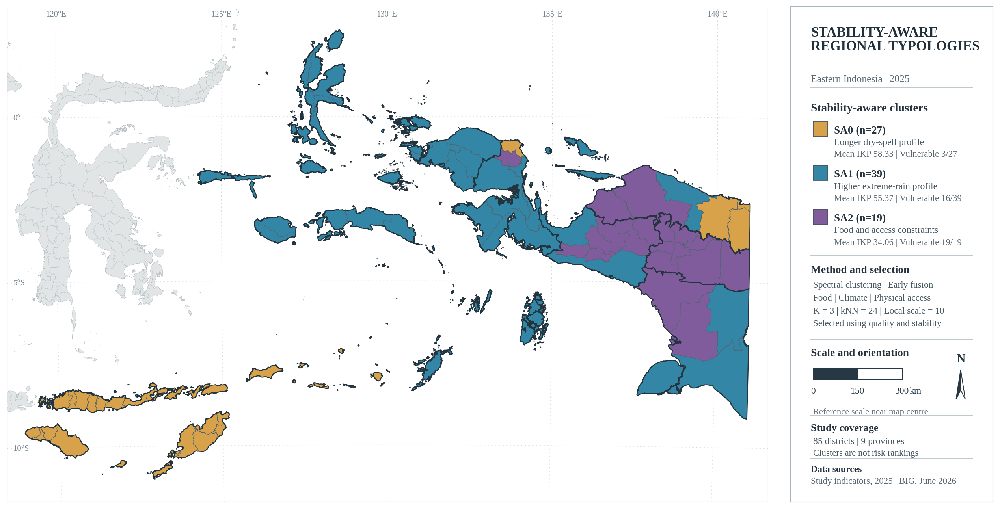


CELL 23 — STABILITY-AWARE ATLAS
Model           : Early_K3_G24_S10
Frozen labels   : VERIFIED 85/85
Cluster sizes   : [27, 39, 19]
IKP context     : VERIFIED
BIG geography   : UNCHANGED
Projection      : SAME AS CELL 22
Map extent      : SAME AS CELL 22
Local scale     : 300 km
Figures saved   : False
New model fits  : 0

Effective text size at LaTeX width:
Typology description: 7.59 pt
Mean IKP context   : 7.27 pt
Data source        : 7.35 pt


In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 23
# STABILITY-AWARE REGIONAL TYPOLOGIES ATLAS
# ================================================================
#
# Frozen model: Early_K3_G24_S10
# Spectral clustering with early fusion
# 85 districts / 9 provinces / 3 clusters
#
# Reuses verified Cell 22:
# M, F, BIG_DRAW, PROV, MAP_RECT, PANEL_RECT,
# MAP_CRS, geographic limits, draw_graticule,
# and frozen labels/selections.
#
# No clustering refit.
# No new indices.
# No automatic saving.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.patches import Polygon as MplPolygon
from IPython.display import display
from pathlib import Path

SAVE_FIGURE_SA = False

SA_MODEL = "Early_K3_G24_S10"

SA_COLORS = {
    0: "#D8A24B",
    1: "#3486A6",
    2: "#815C9D"
}

# Descriptions are post-clustering profiles,
# NOT ordinal vulnerability rankings.
SA_DESCRIPTIONS = {
    0: "Longer dry-spell profile",
    1: "Higher extreme-rain profile",
    2: "Food and access constraints"
}

# ------------------------------------------------------------
# A. VERIFY REQUIRED CELL 22 OBJECTS
# ------------------------------------------------------------

REQUIRED_OBJECTS = [
    "M", "F", "BIG_DRAW", "PROV",
    "MAP_RECT", "PANEL_RECT",
    "FIG_WIDTH", "FIG_HEIGHT",
    "FIG_DPI", "XMIN", "XMAX",
    "YMIN", "YMAX", "XS", "YS",
    "LABELS", "SELECTED",
    "draw_graticule", "TRANSFORMER",
    "GEOD", "OUTPUT_DIR"
]

missing = [
    name for name in REQUIRED_OBJECTS
    if name not in globals()
]

assert not missing, (
    f"Run Cell 22 first. Missing: {missing}"
)

assert len(M) == 85
assert len(PROV) == 9
assert M["kode_bps"].is_unique
assert M.geometry.is_valid.all()

assert M.crs == MAP_CRS

assert sorted(
    M["cluster_SA"].value_counts().tolist()
) == [19, 27, 39]

sa_selected = SELECTED.loc[
    SELECTED["policy"].eq("stability_aware")
]

assert len(sa_selected) == 1

assert (
    str(sa_selected.iloc[0]["model_id"])
    == SA_MODEL
)

assert SA_MODEL in LABELS.columns

# Verify individual memberships against
# the original frozen 39,500-fit workflow.
CHECK_SA = M[
    ["kode_bps", "cluster_SA"]
].merge(
    LABELS[
        ["kode_bps", SA_MODEL]
    ],
    on="kode_bps",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert len(CHECK_SA) == 85
assert CHECK_SA["_merge"].eq("both").all()

assert np.array_equal(
    CHECK_SA["cluster_SA"].to_numpy(
        dtype=int
    ),
    CHECK_SA[SA_MODEL].to_numpy(
        dtype=int
    )
)

# Check that the same district memberships
# as Cell 22 are being compared.
TRANSFER_SA = pd.crosstab(
    M["cluster_Q"],
    M["cluster_SA"]
).reindex(
    index=[0, 1],
    columns=[0, 1, 2],
    fill_value=0
)

assert np.array_equal(
    TRANSFER_SA.to_numpy(),
    np.array([
        [27, 38, 1],
        [0,  1, 18]
    ])
)

# ------------------------------------------------------------
# B. POST-CLUSTERING FOOD SECURITY PROFILES
# ------------------------------------------------------------

SA_SUMMARY = (
    M.groupby("cluster_SA")
    .agg(
        n=("kode_bps", "size"),
        mean_IKP=("IKP_MAP", "mean"),
        median_IKP=("IKP_MAP", "median"),
        min_IKP=("IKP_MAP", "min"),
        max_IKP=("IKP_MAP", "max"),
        vulnerable_n=("recorded_vulnerable", "sum")
    )
    .reindex([0, 1, 2])
)

SA_SUMMARY["vulnerable_pct"] = (
    100
    * SA_SUMMARY["vulnerable_n"]
    / SA_SUMMARY["n"]
)

assert SA_SUMMARY["n"].tolist() == [
    27, 39, 19
]

assert SA_SUMMARY["vulnerable_n"].tolist() == [
    3, 16, 19
]

assert np.allclose(
    SA_SUMMARY["mean_IKP"].to_numpy(),
    [58.332, 55.365, 34.060],
    atol=0.005
)

SA_STATUS = pd.crosstab(
    M["cluster_SA"],
    M["IKP_2025_status_noninput"]
).reindex(
    index=[0, 1, 2],
    columns=[
        "Sangat Rentan",
        "Rentan",
        "Agak Rentan",
        "Agak Tahan"
    ],
    fill_value=0
)

assert np.array_equal(
    SA_STATUS.to_numpy(),
    np.array([
        [0, 3, 18, 6],
        [3, 13, 13, 10],
        [17, 2, 0, 0]
    ])
)

print("=" * 70)
print("A. STABILITY-AWARE MODEL VERIFICATION")
print("=" * 70)
print("Model           :", SA_MODEL)
print("Integration     : Spectral Early Fusion")
print("Selected policy : Stability-aware")
print("Frozen labels   : 85/85 verified")
print("Cluster sizes   : 27 / 39 / 19")

print("\nB. FOOD SECURITY BY STABILITY-AWARE CLUSTER")
display(SA_SUMMARY.round(3))

print("\nC. RECORDED STATUS BY CLUSTER")
display(SA_STATUS)

print("\nD. QUALITY-ONLY VS STABILITY-AWARE")
display(TRANSFER_SA)


# ------------------------------------------------------------
# C. SMALL CARTOGRAPHIC UTILITIES
# ------------------------------------------------------------

def sa_panel_line(ax, y):
    ax.plot(
        [0.10, 0.90],
        [y, y],
        transform=ax.transAxes,
        color="#BEC9CE",
        linewidth=0.8
    )


def sa_north_arrow(ax):
    tr = ax.transAxes
    x = 0.84

    ax.text(
        x, 0.277, "N",
        transform=tr,
        ha="center",
        va="bottom",
        fontsize=12.5,
        fontweight="bold",
        color="#263844"
    )

    ax.add_patch(
        MplPolygon(
            [
                [x, 0.267],
                [x - 0.023, 0.207],
                [x, 0.226]
            ],
            closed=True,
            transform=tr,
            facecolor="#263844",
            edgecolor="#263844",
            linewidth=0.8
        )
    )

    ax.add_patch(
        MplPolygon(
            [
                [x, 0.267],
                [x + 0.023, 0.207],
                [x, 0.226]
            ],
            closed=True,
            transform=tr,
            facecolor="white",
            edgecolor="#263844",
            linewidth=0.8
        )
    )


def sa_scale_bar(ax):
    # Same projection and map dimensions as Cell 22.
    map_inches = FIG_WIDTH * MAP_RECT[2]
    panel_inches = FIG_WIDTH * PANEL_RECT[2]

    x0, y0 = TRANSFORMER.transform(
        130.0, -4.0
    )

    chosen = None
    fraction = None

    for km in [500, 400, 300, 200, 100, 50]:

        lon2, lat2, _ = GEOD.fwd(
            130.0, -4.0, 90.0,
            km * 1000
        )

        x1, y1 = TRANSFORMER.transform(
            lon2, lat2
        )

        candidate = (
            np.hypot(x1 - x0, y1 - y0)
            / XS
            * map_inches / panel_inches
        )

        if candidate <= 0.56:
            chosen = km
            fraction = candidate
            break

    assert chosen is not None

    start = 0.11
    mid = start + fraction / 2
    end = start + fraction
    y = 0.247

    for x, colour in [
        (start, "#263844"),
        (mid, "#FFFFFF")
    ]:
        ax.add_patch(
            Rectangle(
                (x, y),
                fraction / 2,
                0.022,
                transform=ax.transAxes,
                facecolor=colour,
                edgecolor="#263844",
                linewidth=0.8
            )
        )

    for x, label in [
        (start, "0"),
        (mid, f"{chosen/2:g}"),
        (end, f"{chosen:g}")
    ]:
        ax.text(
            x, y - 0.015,
            label,
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=9.5,
            color="#263844"
        )

    ax.text(
        end + 0.036,
        y - 0.015,
        "km",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9.5,
        color="#263844"
    )

    return chosen


# ------------------------------------------------------------
# D. DRAW STABILITY-AWARE ATLAS
# ------------------------------------------------------------

def draw_stability_aware_atlas(save=False):

    fig = plt.figure(
        figsize=(FIG_WIDTH, FIG_HEIGHT),
        dpi=FIG_DPI,
        facecolor="white"
    )

    ax_map = fig.add_axes(MAP_RECT)
    ax_panel = fig.add_axes(PANEL_RECT)

    ax_map.set_facecolor(SEA_COLOR)
    ax_panel.set_facecolor("white")

    # Same BIG background.
    BIG_DRAW.plot(
        ax=ax_map,
        facecolor=OTHER_LAND,
        edgecolor="#B8C2C5",
        linewidth=0.24,
        zorder=0
    )

    if SHOW_GRATICULE:
        draw_graticule(ax_map)

    # Frozen three-cluster map.
    for k in [0, 1, 2]:

        part = M.loc[
            M["cluster_SA"].eq(k)
        ]

        assert len(part) == (
            [27, 39, 19][k]
        )

        part.plot(
            ax=ax_map,
            facecolor=SA_COLORS[k],
            edgecolor=DISTRICT_LINE,
            linewidth=0.40,
            zorder=2
        )

    PROV.boundary.plot(
        ax=ax_map,
        color=PROVINCE_LINE,
        linewidth=1.0,
        zorder=3
    )

    ax_map.set_xlim(XMIN, XMAX)
    ax_map.set_ylim(YMIN, YMAX)
    ax_map.set_aspect("equal", adjustable="box")
    ax_map.set_axis_off()

    ax_map.add_patch(
        Rectangle(
            (XMIN, YMIN),
            XS, YS,
            fill=False,
            edgecolor="#A7B4BB",
            linewidth=0.85,
            zorder=10
        )
    )

    # --------------------------------------------------------
    # RIGHT PANEL
    # --------------------------------------------------------

    ax_panel.set_xlim(0, 1)
    ax_panel.set_ylim(0, 1)
    ax_panel.set_xticks([])
    ax_panel.set_yticks([])

    for spine in ax_panel.spines.values():
        spine.set_color("#A7B4BB")
        spine.set_linewidth(0.85)

    ax_panel.text(
        0.10, 0.960,
        "STABILITY-AWARE\nREGIONAL TYPOLOGIES",
        transform=ax_panel.transAxes,
        fontsize=14.0,
        fontweight="bold",
        linespacing=1.08,
        ha="left",
        va="top",
        color="#21313C"
    )

    ax_panel.text(
        0.10, 0.862,
        "Eastern Indonesia | 2025",
        transform=ax_panel.transAxes,
        fontsize=10.2,
        va="top",
        color="#5A6872"
    )

    sa_panel_line(ax_panel, 0.836)

    # --------------------------------------------------------
    # THREE TYPOLOGIES
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.806,
        "Stability-aware clusters",
        transform=ax_panel.transAxes,
        fontsize=11.8,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    y_positions = {
        0: 0.750,
        1: 0.661,
        2: 0.572
    }

    for k in [0, 1, 2]:

        y = y_positions[k]

        n = int(SA_SUMMARY.loc[k, "n"])
        ikp = float(SA_SUMMARY.loc[k, "mean_IKP"])
        vuln = int(
            SA_SUMMARY.loc[k, "vulnerable_n"]
        )

        ax_panel.add_patch(
            Rectangle(
                (0.11, y - 0.012),
                0.073, 0.031,
                transform=ax_panel.transAxes,
                facecolor=SA_COLORS[k],
                edgecolor="#46545E",
                linewidth=0.7
            )
        )

        ax_panel.text(
            0.215, y,
            f"SA{k} (n={n})",
            transform=ax_panel.transAxes,
            fontsize=10.9,
            fontweight="bold",
            ha="left",
            va="center",
            color="#26333E"
        )

        ax_panel.text(
            0.215, y - 0.024,
            SA_DESCRIPTIONS[k],
            transform=ax_panel.transAxes,
            fontsize=9.5,
            ha="left",
            va="center",
            color="#455864"
        )

        ax_panel.text(
            0.215, y - 0.048,
            f"Mean IKP {ikp:.2f} | Vulnerable {vuln}/{n}",
            transform=ax_panel.transAxes,
            fontsize=9.1,
            ha="left",
            va="center",
            color="#586873"
        )

    sa_panel_line(ax_panel, 0.497)

    # --------------------------------------------------------
    # METHOD AND SELECTION
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.478,
        "Method and selection",
        transform=ax_panel.transAxes,
        fontsize=11.0,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    method_lines = [
        "Spectral clustering | Early fusion",
        "Food | Climate | Physical access",
        "K = 3 | kNN = 24 | Local scale = 10",
        "Selected using quality and stability"
    ]

    for i, line in enumerate(method_lines):
        ax_panel.text(
            0.11,
            0.446 - i * 0.026,
            line,
            transform=ax_panel.transAxes,
            fontsize=9.3,
            va="top",
            color="#465862"
        )

    sa_panel_line(ax_panel, 0.329)

    # --------------------------------------------------------
    # SCALE AND NORTH ARROW
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.310,
        "Scale and orientation",
        transform=ax_panel.transAxes,
        fontsize=11.0,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    scale_km = sa_scale_bar(ax_panel)
    sa_north_arrow(ax_panel)

    ax_panel.text(
        0.11, 0.190,
        "Reference scale near map centre",
        transform=ax_panel.transAxes,
        fontsize=9.0,
        va="top",
        color="#66747C"
    )

    sa_panel_line(ax_panel, 0.174)

    # --------------------------------------------------------
    # STUDY COVERAGE
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.158,
        "Study coverage",
        transform=ax_panel.transAxes,
        fontsize=10.5,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    ax_panel.text(
        0.11, 0.130,
        "85 districts | 9 provinces",
        transform=ax_panel.transAxes,
        fontsize=9.5,
        va="top",
        color="#465862"
    )

    ax_panel.text(
        0.11, 0.106,
        "Clusters are not risk rankings",
        transform=ax_panel.transAxes,
        fontsize=9.1,
        va="top",
        color="#465862"
    )

    sa_panel_line(ax_panel, 0.088)

    # --------------------------------------------------------
    # SOURCES
    # --------------------------------------------------------

    ax_panel.text(
        0.10, 0.074,
        "Data sources",
        transform=ax_panel.transAxes,
        fontsize=9.5,
        fontweight="bold",
        va="top",
        color="#26333E"
    )

    ax_panel.text(
        0.10, 0.050,
        "Study indicators, 2025 | BIG, June 2026",
        transform=ax_panel.transAxes,
        fontsize=9.2,
        va="top",
        color="#596872"
    )

    # --------------------------------------------------------
    # OPTIONAL EXPORT
    # --------------------------------------------------------

    if save:

        OUTPUT_DIR.mkdir(
            parents=True,
            exist_ok=True
        )

        pdf_path = (
            OUTPUT_DIR
            / "StabilityAware_EarlyFusion_K3_Atlas.pdf"
        )

        png_path = (
            OUTPUT_DIR
            / "StabilityAware_EarlyFusion_K3_Atlas.png"
        )

        fig.savefig(
            pdf_path,
            format="pdf",
            dpi=300,
            facecolor="white"
        )

        fig.savefig(
            png_path,
            format="png",
            dpi=300,
            facecolor="white"
        )

        print("Saved PDF:", pdf_path)
        print("Saved PNG:", png_path)

    plt.show()

    return fig, scale_km


# ------------------------------------------------------------
# E. RENDER
# ------------------------------------------------------------

FIG_SA, SA_SCALE_KM = draw_stability_aware_atlas(
    save=SAVE_FIGURE_SA
)

# ------------------------------------------------------------
# F. PUBLICATION READABILITY AUDIT
# ------------------------------------------------------------

PRINT_SCALE = LATEX_WIDTH_INCHES / FIG_WIDTH

print("\n" + "=" * 70)
print("CELL 23 — STABILITY-AWARE ATLAS")
print("=" * 70)

print("Model           :", SA_MODEL)
print("Frozen labels   : VERIFIED 85/85")
print("Cluster sizes   :", [27, 39, 19])
print("IKP context     : VERIFIED")
print("BIG geography   : UNCHANGED")
print("Projection      : SAME AS CELL 22")
print("Map extent      : SAME AS CELL 22")
print("Local scale     :", SA_SCALE_KM, "km")
print("Figures saved   :", SAVE_FIGURE_SA)
print("New model fits  : 0")

print("\nEffective text size at LaTeX width:")

print(
    "Typology description:",
    round(9.5 * PRINT_SCALE, 2),
    "pt"
)

print(
    "Mean IKP context   :",
    round(9.1 * PRINT_SCALE, 2),
    "pt"
)

print(
    "Data source        :",
    round(9.2 * PRINT_SCALE, 2),
    "pt"
)

print("=" * 70)


# Food Security Heterogeneity Across Clustering Solutions

A. FROZEN CROSS-MODEL MEMBERSHIP


cluster_SA,0,1,2
cluster_Q,,,
0,27,38,1
1,0,1,18



B. QUALITY-ONLY FOOD SECURITY


,n,mean_IKP,median_IKP,q25_IKP,q75_IKP,min_IKP,max_IKP,vulnerable_n,vulnerable_pct
cluster_Q,,,,,,,,,
0,66,56.582,56.73,52.927,61.128,42.40,67.43,19,28.788
1,19,34.051,33.09,27.375,41.175,19.93,46.97,19,100.000



C. STABILITY-AWARE FOOD SECURITY


,n,mean_IKP,median_IKP,q25_IKP,q75_IKP,min_IKP,max_IKP,vulnerable_n,vulnerable_pct
cluster_SA,,,,,,,,,
0,27,58.332,58.57,55.520,61.045,49.22,67.43,3,11.111
1,39,55.365,56.22,49.890,60.830,42.40,67.31,16,41.026
2,19,34.060,33.09,27.375,41.175,19.93,46.97,19,100.000


... (4 outputs left out)


F. WITHIN-Q0 SPLIT: SA0 VS SA1
Q0 -> SA0: 27 districts
Q0 -> SA1: 38 districts


,SA0_mean_z,SA1_mean_z,SA0_minus_SA1
F1_ikp_ketersediaan,0.660,0.051,0.609
F2_ikp_keterjangkauan,0.555,0.342,0.212
F3_ikp_pemanfaatan,0.307,0.512,-0.205
C1_anomali_hujan_mm,-0.661,0.753,-1.414
C2_cdd_hari,1.016,-0.513,1.529
C3_hari_hujan_ekstrem,-1.035,0.838,-1.873
A1_persen_tanpa_angkutan,-0.648,-0.111,-0.537
A2_persen_jalan_tanah_lainnya,-0.691,-0.243,-0.448
A3_persen_tanpa_pertokoan_pasar,-0.418,0.025,-0.444



G. VIEW-LEVEL CONTRAST WITHIN Q0


,view,RMS_standardized_mean_difference
0,Climate,1.617
1,Physical Accessibility,0.478
2,Food Security,0.391


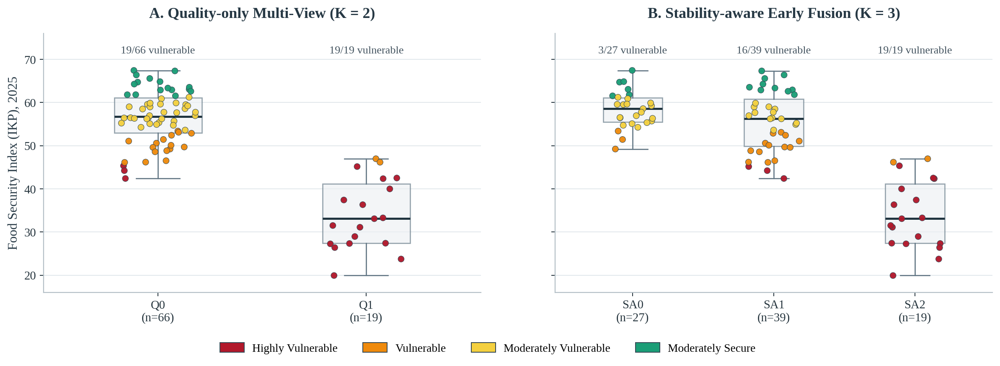


CELL 24 — FINAL PUBLICATION FIGURE
Districts                  : 85
Provinces                  : 9
Quality-only cluster sizes: [66, 19]
Stability-aware sizes     : [27, 39, 19]
Recorded vulnerable       : 38
Vulnerable outside SA2    : 19
Panel A                   : Quality-only K=2
Panel B                   : Stability-aware K=3
Overall figure title      : REMOVED
Explanatory dots footer   : REMOVED
Panel headings            : RETAINED
Colour palette            : HIGH-CONTRAST
Font                      : Liberation Serif
Frozen cluster labels     : UNCHANGED
New clustering fits       : 0
New IKP constructed       : NO
Figures saved             : False


In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 24 (FINAL REVISED)
# FOOD SECURITY HETEROGENEITY
# ACROSS SELECTED CLUSTERING SOLUTIONS
# ================================================================
#
# ANALYSIS
# A. Frozen model membership verification
# B. Food security by Quality-only clusters
# C. Food security by Stability-aware clusters
# D. Cross-model cluster intersections
# E. Exceptional district assignments
# F. Within-Q0 split: SA0 versus SA1
# G. View-level profile differences
#
# FIGURE DESIGN
# - Two panels: A (Quality-only), B (Stability-aware)
# - NO overall figure title
# - NO explanatory dots footer
# - Higher contrast categorical colours
# - Neutral boxplots with individual observations
# - Liberation Serif
# - Clean legend below both panels
# - Static PDF/PNG for LaTeX
#
# DATA INTEGRITY
# - Original 85 districts
# - Original IKP 2025
# - Frozen Q and SA memberships
# - No new IKP
# - No clustering refit
# - No automatic saving
# ================================================================


# ================================================================
# A. IMPORTS AND SETTINGS
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

from matplotlib.patches import Patch
from pathlib import Path
from IPython.display import display


SAVE_FIGURE_24 = False

FIG_W_24 = 13.8
FIG_H_24 = 5.3
FIG_DPI_24 = 180

RANDOM_SEED_24 = 20261020

FONT_FAMILY_24 = "Liberation Serif"

ROOT_24 = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

OUTPUT_24 = (
    ROOT_24
    / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
    / "publication_figures"
)

STATUS_COL_24 = "IKP_2025_status_noninput"

STATUS_ORDER_24 = [
    "Sangat Rentan",
    "Rentan",
    "Agak Rentan",
    "Agak Tahan"
]

STATUS_NAMES_24 = {
    "Sangat Rentan": "Highly Vulnerable",
    "Rentan": "Vulnerable",
    "Agak Rentan": "Moderately Vulnerable",
    "Agak Tahan": "Moderately Secure"
}


# ================================================================
# B. REVISED HIGH-CONTRAST COLOUR PALETTE
# ================================================================
#
# Four ordered IKP classes retain their
# original status meanings.
#
# Colour intensity is for communication only.
# No score transformation is performed.
# ================================================================

STATUS_COLORS_24 = {
    "Sangat Rentan": "#B2182B",  # deep red
    "Rentan": "#EF8A0C",         # vivid orange
    "Agak Rentan": "#F4D03F",    # bright yellow
    "Agak Tahan": "#1B9E77"      # saturated green
}

BOX_FILL_24 = "#EDF1F3"
BOX_EDGE_24 = "#657987"

MEDIAN_COLOR_24 = "#20343F"
GRID_COLOR_24 = "#DEE5E9"
TEXT_COLOR_24 = "#263844"

POINT_EDGE_24 = "#344854"


# ================================================================
# C. VERIFY LIBERATION SERIF
# ================================================================

AVAILABLE_FONTS_24 = {
    font.name
    for font in fm.fontManager.ttflist
}

assert FONT_FAMILY_24 in AVAILABLE_FONTS_24, (
    "Liberation Serif tidak ditemukan. "
    "Pastikan fonts-liberation sudah terpasang "
    "dan Matplotlib mengenalinya."
)

plt.rcParams.update({
    "font.family": FONT_FAMILY_24,
    "font.size": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.unicode_minus": False
})


# ================================================================
# D. VERIFY INPUT DATA AND FROZEN CLUSTERS
# ================================================================

assert "M" in globals(), (
    "Data M tidak tersedia. "
    "Jalankan Cell 22 dan Cell 23 terlebih dahulu."
)

D = M.copy()

REQUIRED_COLUMNS_24 = [
    "kode_bps",
    "provinsi",
    "kabupaten_kota",
    "cluster_Q",
    "cluster_SA",
    "IKP_MAP",
    STATUS_COL_24
]

assert set(REQUIRED_COLUMNS_24).issubset(
    D.columns
), (
    "Kolom yang diperlukan Cell 24 "
    "belum lengkap."
)

assert len(D) == 85
assert D["kode_bps"].is_unique
assert D["provinsi"].nunique() == 9

for col in ["cluster_Q", "cluster_SA"]:

    D[col] = pd.to_numeric(
        D[col],
        errors="raise"
    ).astype(int)

assert (
    D["cluster_Q"]
    .value_counts()
    .sort_index()
    .to_dict()
) == {
    0: 66,
    1: 19
}

assert (
    D["cluster_SA"]
    .value_counts()
    .sort_index()
    .to_dict()
) == {
    0: 27,
    1: 39,
    2: 19
}

D["IKP_MAP"] = pd.to_numeric(
    D["IKP_MAP"],
    errors="raise"
)

assert np.isfinite(
    D["IKP_MAP"].to_numpy(dtype=float)
).all()

assert set(D[STATUS_COL_24]) == set(
    STATUS_ORDER_24
)

STATUS_COUNTS_24 = (
    D[STATUS_COL_24]
    .value_counts()
)

assert [
    int(STATUS_COUNTS_24[s])
    for s in STATUS_ORDER_24
] == [20, 18, 31, 16]

D["vulnerable"] = (
    D[STATUS_COL_24].isin([
        "Sangat Rentan",
        "Rentan"
    ])
)

assert int(
    D["vulnerable"].sum()
) == 38


# ================================================================
# E. VERIFY QUALITY-ONLY × STABILITY-AWARE
# ================================================================

CROSS_24 = pd.crosstab(
    D["cluster_Q"],
    D["cluster_SA"]
).reindex(
    index=[0, 1],
    columns=[0, 1, 2],
    fill_value=0
)

EXPECTED_CROSS_24 = np.array([
    [27, 38, 1],
    [0, 1, 18]
])

assert np.array_equal(
    CROSS_24.to_numpy(),
    EXPECTED_CROSS_24
)

print("=" * 70)
print("A. FROZEN CROSS-MODEL MEMBERSHIP")
print("=" * 70)

display(CROSS_24)


# ================================================================
# F. FOOD SECURITY DISTRIBUTION BY CLUSTER
# ================================================================

def cluster_summary_24(frame, column):

    summary = (
        frame.groupby(column)
        .agg(
            n=("kode_bps", "size"),
            mean_IKP=("IKP_MAP", "mean"),
            median_IKP=("IKP_MAP", "median"),
            q25_IKP=(
                "IKP_MAP",
                lambda x: x.quantile(0.25)
            ),
            q75_IKP=(
                "IKP_MAP",
                lambda x: x.quantile(0.75)
            ),
            min_IKP=("IKP_MAP", "min"),
            max_IKP=("IKP_MAP", "max"),
            vulnerable_n=("vulnerable", "sum")
        )
    )

    summary["vulnerable_pct"] = (
        summary["vulnerable_n"]
        / summary["n"]
        * 100
    )

    return summary


Q_STATS_24 = cluster_summary_24(
    D,
    "cluster_Q"
).reindex([0, 1])

SA_STATS_24 = cluster_summary_24(
    D,
    "cluster_SA"
).reindex([0, 1, 2])

assert Q_STATS_24["n"].tolist() == [
    66, 19
]

assert SA_STATS_24["n"].tolist() == [
    27, 39, 19
]

assert Q_STATS_24["vulnerable_n"].tolist() == [
    19, 19
]

assert SA_STATS_24["vulnerable_n"].tolist() == [
    3, 16, 19
]

print("\nB. QUALITY-ONLY FOOD SECURITY")
display(Q_STATS_24.round(3))

print("\nC. STABILITY-AWARE FOOD SECURITY")
display(SA_STATS_24.round(3))


# ================================================================
# G. FOOD SECURITY BY CROSS-MODEL INTERSECTION
# ================================================================

BRIDGE_24 = (
    D.groupby(
        ["cluster_Q", "cluster_SA"]
    )
    .agg(
        n=("kode_bps", "size"),
        mean_IKP=("IKP_MAP", "mean"),
        median_IKP=("IKP_MAP", "median"),
        vulnerable_n=("vulnerable", "sum")
    )
)

print("\nD. FOOD SECURITY BY PARTITION INTERSECTION")
display(BRIDGE_24.round(3))


# ================================================================
# H. EXCEPTIONAL CROSS-MODEL ASSIGNMENTS
# ================================================================

EXCEPTIONS_24 = D.loc[
    (
        D["cluster_Q"].eq(0)
        & D["cluster_SA"].eq(2)
    )
    |
    (
        D["cluster_Q"].eq(1)
        & D["cluster_SA"].eq(1)
    ),
    [
        "kode_bps",
        "provinsi",
        "kabupaten_kota",
        "cluster_Q",
        "cluster_SA",
        "IKP_MAP",
        STATUS_COL_24
    ]
].sort_values(
    ["cluster_Q", "kode_bps"]
)

assert len(EXCEPTIONS_24) == 2

print("\nE. EXCEPTIONAL PARTITION INTERSECTIONS")
display(EXCEPTIONS_24)


# ================================================================
# I. THREE-VIEW DESCRIPTIVE PROFILE
# ================================================================

VIEWS_24 = {
    "Food Security": [
        "F1_ikp_ketersediaan",
        "F2_ikp_keterjangkauan",
        "F3_ikp_pemanfaatan"
    ],

    "Climate": [
        "C1_anomali_hujan_mm",
        "C2_cdd_hari",
        "C3_hari_hujan_ekstrem"
    ],

    "Physical Accessibility": [
        "A1_persen_tanpa_angkutan",
        "A2_persen_jalan_tanah_lainnya",
        "A3_persen_tanpa_pertokoan_pasar"
    ]
}

FEATURES_24 = [
    feature
    for features in VIEWS_24.values()
    for feature in features
]

assert set(FEATURES_24).issubset(
    D.columns
)

X24 = D[FEATURES_24].apply(
    pd.to_numeric,
    errors="raise"
)

assert np.isfinite(
    X24.to_numpy(dtype=float)
).all()

SD24 = X24.std(ddof=0)

assert (SD24 > 0).all()

Z24 = (
    X24 - X24.mean()
) / SD24


# ================================================================
# J. Q0 SPLIT INTO SA0 AND SA1
# ================================================================
#
# Post-hoc descriptive comparison only.
# Standardisation is across all 85 districts.
# The original clustering is not reconstructed.
# ================================================================

Q0_SA_MASK = (
    D["cluster_Q"].eq(0)
    & D["cluster_SA"].isin([0, 1])
)

assert int(
    Q0_SA_MASK.sum()
) == 65

Q0_Z = Z24.loc[
    Q0_SA_MASK
]

Q0_GROUP = D.loc[
    Q0_SA_MASK,
    "cluster_SA"
]

Q0_PROFILE = (
    Q0_Z.groupby(Q0_GROUP)
    .mean()
    .reindex([0, 1])
)

assert Q0_PROFILE.notna().all().all()

assert int(
    (Q0_GROUP == 0).sum()
) == 27

assert int(
    (Q0_GROUP == 1).sum()
) == 38

DELTA_24 = (
    Q0_PROFILE.loc[0]
    - Q0_PROFILE.loc[1]
)

DIFF_TABLE_24 = pd.DataFrame({
    "SA0_mean_z": Q0_PROFILE.loc[0],
    "SA1_mean_z": Q0_PROFILE.loc[1],
    "SA0_minus_SA1": DELTA_24
})

print("\nF. WITHIN-Q0 SPLIT: SA0 VS SA1")

print("Q0 -> SA0: 27 districts")
print("Q0 -> SA1: 38 districts")

display(
    DIFF_TABLE_24.round(3)
)


# ================================================================
# K. VIEW-LEVEL RMS CONTRAST
# ================================================================

VIEW_RMS_24 = []

for view, features in VIEWS_24.items():

    differences = (
        DELTA_24[features]
        .to_numpy(dtype=float)
    )

    rms = np.sqrt(
        np.mean(differences ** 2)
    )

    VIEW_RMS_24.append({
        "view": view,
        "RMS_standardized_mean_difference": float(rms)
    })

VIEW_RMS_24 = (
    pd.DataFrame(VIEW_RMS_24)
    .sort_values(
        "RMS_standardized_mean_difference",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nG. VIEW-LEVEL CONTRAST WITHIN Q0")
display(VIEW_RMS_24.round(3))


# ================================================================
# L. PUBLICATION FIGURE
# ================================================================
#
# No main figure title.
# No explanatory dots footer.
#
# Panel A and B headings retained.
# ================================================================

fig, axs = plt.subplots(
    1, 2,
    figsize=(
        FIG_W_24,
        FIG_H_24
    ),
    dpi=FIG_DPI_24,
    sharey=True
)

rng = np.random.default_rng(
    RANDOM_SEED_24
)


def draw_distribution_24(
    ax,
    grouping,
    groups,
    heading
):

    # --------------------------------------------------------
    # L1. PREPARE CLUSTER DATA
    # --------------------------------------------------------

    group_data = [
        D.loc[
            D[grouping].eq(k),
            "IKP_MAP"
        ].to_numpy(dtype=float)
        for k in groups
    ]

    positions = np.arange(
        1,
        len(groups) + 1
    )

    # --------------------------------------------------------
    # L2. NEUTRAL BOXPLOTS
    # --------------------------------------------------------

    bp = ax.boxplot(
        group_data,
        positions=positions,
        widths=0.42,

        patch_artist=True,
        showfliers=False,

        medianprops={
            "color": MEDIAN_COLOR_24,
            "linewidth": 2.0
        },

        boxprops={
            "edgecolor": BOX_EDGE_24,
            "linewidth": 1.1
        },

        whiskerprops={
            "color": BOX_EDGE_24,
            "linewidth": 1.1
        },

        capprops={
            "color": BOX_EDGE_24,
            "linewidth": 1.1
        }
    )

    for patch in bp["boxes"]:

        patch.set_facecolor(
            BOX_FILL_24
        )

        patch.set_alpha(
            0.66
        )

    # --------------------------------------------------------
    # L3. INDIVIDUAL DISTRICTS
    # --------------------------------------------------------

    for pos, k in zip(
        positions,
        groups
    ):

        subset = D.loc[
            D[grouping].eq(k)
        ].sort_values(
            "kode_bps"
        )

        n = len(subset)

        jitter = rng.uniform(
            -0.18,
            0.18,
            n
        )

        x_values = (
            np.full(n, pos)
            + jitter
        )

        point_colors = (
            subset[STATUS_COL_24]
            .map(STATUS_COLORS_24)
            .tolist()
        )

        assert len(point_colors) == n
        assert all(
            isinstance(c, str)
            for c in point_colors
        )

        ax.scatter(
            x_values,
            subset["IKP_MAP"].to_numpy(),

            c=point_colors,

            s=34,
            alpha=0.96,

            edgecolors=POINT_EDGE_24,
            linewidths=0.42,

            zorder=4
        )

        # ----------------------------------------------------
        # L4. VULNERABILITY COUNT ABOVE EACH GROUP
        # ----------------------------------------------------

        vulnerable_n = int(
            subset["vulnerable"].sum()
        )

        ax.text(
            pos,
            72.0,
            f"{vulnerable_n}/{n} vulnerable",

            ha="center",
            va="center",

            fontsize=10.5,
            color="#43535F"
        )

    # --------------------------------------------------------
    # L5. X-AXIS LABELS
    # --------------------------------------------------------

    prefix = (
        "Q"
        if grouping == "cluster_Q"
        else "SA"
    )

    labels = [
        f"{prefix}{k}\n(n={len(values)})"
        for k, values in zip(
            groups,
            group_data
        )
    ]

    ax.set_xticks(
        positions,
        labels
    )

    ax.set_xlim(
        0.45,
        len(groups) + 0.55
    )

    ax.set_ylim(
        16,
        76
    )

    # --------------------------------------------------------
    # L6. PANEL TITLE
    # --------------------------------------------------------

    ax.set_title(
        heading,

        fontsize=14.4,
        fontweight="bold",

        color=TEXT_COLOR_24,
        pad=15
    )

    # --------------------------------------------------------
    # L7. GRID AND AXES
    # --------------------------------------------------------

    ax.grid(
        axis="y",
        color=GRID_COLOR_24,
        linewidth=0.80,
        alpha=0.90
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color(
        "#B2BEC5"
    )

    ax.spines["bottom"].set_color(
        "#B2BEC5"
    )

    ax.spines["left"].set_linewidth(
        0.9
    )

    ax.spines["bottom"].set_linewidth(
        0.9
    )

    ax.tick_params(
        axis="both",
        labelsize=11.5,
        colors="#25343D"
    )


# ================================================================
# M. DRAW PANEL A AND PANEL B
# ================================================================

draw_distribution_24(
    ax=axs[0],
    grouping="cluster_Q",
    groups=[0, 1],
    heading="A. Quality-only Multi-View (K = 2)"
)

draw_distribution_24(
    ax=axs[1],
    grouping="cluster_SA",
    groups=[0, 1, 2],
    heading="B. Stability-aware Early Fusion (K = 3)"
)


# ================================================================
# N. Y-AXIS
# ================================================================

axs[0].set_ylabel(
    "Food Security Index (IKP), 2025",
    fontsize=12.6,
    color=TEXT_COLOR_24
)

# Shared axis: do not repeat the Y-axis label.
axs[1].set_ylabel("")


# ================================================================
# O. CATEGORY LEGEND
# ================================================================

LEGEND_HANDLES_24 = [
    Patch(
        facecolor=STATUS_COLORS_24[status],
        edgecolor="#344854",
        linewidth=0.8,
        label=STATUS_NAMES_24[status]
    )
    for status in STATUS_ORDER_24
]

fig.legend(
    handles=LEGEND_HANDLES_24,

    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),

    ncol=4,
    frameon=False,

    fontsize=11.0,

    handlelength=2.1,
    handleheight=0.95,

    columnspacing=2.2,
    handletextpad=0.7
)


# ================================================================
# P. FINAL LAYOUT
# ================================================================
#
# Space is reserved only for:
# - Panel A and B headings
# - Plotting area
# - Four-class legend
#
# No overall title.
# No bottom explanatory sentence.
# ================================================================

fig.subplots_adjust(
    left=0.073,
    right=0.985,

    top=0.855,
    bottom=0.205,

    wspace=0.17
)


# ================================================================
# Q. OPTIONAL PUBLICATION EXPORT
# ================================================================

if SAVE_FIGURE_24:

    OUTPUT_24.mkdir(
        parents=True,
        exist_ok=True
    )

    PDF_24 = (
        OUTPUT_24
        / "IKP_Heterogeneity_Q_vs_SA_Final.pdf"
    )

    PNG_24 = (
        OUTPUT_24
        / "IKP_Heterogeneity_Q_vs_SA_Final.png"
    )

    fig.savefig(
        PDF_24,
        format="pdf",
        dpi=300,
        facecolor="white"
    )

    fig.savefig(
        PNG_24,
        format="png",
        dpi=300,
        facecolor="white"
    )

    print("\nSaved PDF:", PDF_24)
    print("Saved PNG:", PNG_24)


# ================================================================
# R. DISPLAY
# ================================================================

plt.show()


# ================================================================
# S. FINAL INTEGRITY AUDIT
# ================================================================

print("\n" + "=" * 72)
print("CELL 24 — FINAL PUBLICATION FIGURE")
print("=" * 72)

print("Districts                  :", len(D))
print("Provinces                  :", D["provinsi"].nunique())

print(
    "Quality-only cluster sizes:",
    D["cluster_Q"].value_counts()
    .sort_index().tolist()
)

print(
    "Stability-aware sizes     :",
    D["cluster_SA"].value_counts()
    .sort_index().tolist()
)

print(
    "Recorded vulnerable       :",
    int(D["vulnerable"].sum())
)

print(
    "Vulnerable outside SA2    :",
    int(
        D.loc[
            D["cluster_SA"].ne(2),
            "vulnerable"
        ].sum()
    )
)

print("Panel A                   : Quality-only K=2")
print("Panel B                   : Stability-aware K=3")

print("Overall figure title      : REMOVED")
print("Explanatory dots footer   : REMOVED")
print("Panel headings            : RETAINED")

print("Colour palette            : HIGH-CONTRAST")
print("Font                      :", FONT_FAMILY_24)

print("Frozen cluster labels     : UNCHANGED")
print("New clustering fits       : 0")
print("New IKP constructed       : NO")
print("Figures saved             :", SAVE_FIGURE_24)

print("=" * 72)


# Integrated Methodological Evidence

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 25
# INTEGRATED METHODOLOGICAL EVIDENCE AUDIT
# ================================================================
#
# PURPOSE:
# Consolidate existing evidence from:
#
# 1. Frozen empirical selections (395 candidates)
# 2. Subsampling stability (100 subsamples/model)
# 3. Leave-one-view-out ablation (6 cases)
# 4. Independent Monte Carlo ground-truth evaluation
#
# IMPORTANT:
# - Read existing experiment artifacts only
# - No clustering refit
# - No simulation rerun
# - No new selection or composite score
# - No external validation data
# - No automatic file saving
#
# ================================================================

from pathlib import Path
from IPython.display import display
from sklearn.metrics import adjusted_rand_score

import hashlib
import json
import numpy as np
import pandas as pd


# ================================================================
# A. VERIFIED PROJECT PATHS
# ================================================================

ROOT25 = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

GRID25 = (
    ROOT25 / "03_outputs"
    / "05_extended_gridsearch_R0"
    / "20261019_014117_UTC"
)

STAB25 = (
    ROOT25 / "03_outputs"
    / "06_stability_selection"
    / "R0_all395_selection_seed_aligned_v2"
)

SEL25 = (
    ROOT25 / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

ABL25 = (
    SEL25
    / "leave_one_view_out_v1"
)

MC25 = (
    ROOT25 / "03_outputs"
    / "09_independent_monte_carlo"
    / "simplex_v2_frozen_v1"
    / "ground_truth_evaluation_v1"
)

MASTER25 = (
    ROOT25 / "01_data"
    / "01_raw"
    / "MATRIX_9VAR_CLUSTERING_85KAB_2025.csv"
)

SELECTION_PATH25 = (
    SEL25 / "primary_selections.csv"
)

SEAL_PATH25 = (
    SEL25 / "selection_seal.json"
)

STABILITY_PATH25 = (
    STAB25 / "all395_pareto_flags.csv"
)

LABELS_PATH25 = (
    GRID25 / "labels_all.csv"
)

GRID_PROTOCOL25 = (
    GRID25 / "protocol.json"
)

STAB_MANIFEST25 = (
    STAB25 / "manifest.json"
)

EXPECTED_MASTER_SHA25 = (
    "ce932d322eb49cbdb6ea3b0a8768ca89c2e9"
    "e7f0722232883541d891089ca6fa"
)

EXPECTED_MODELS25 = {
    "quality_only": "Multi_K2_G5_S10_food50",
    "stability_aware": "Early_K3_G24_S10"
}


# ================================================================
# B. FILE AND PROVENANCE HELPERS
# ================================================================

def sha256_25(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def read_json_25(path):

    with open(path, encoding="utf-8") as f:
        return json.load(f)


def normalize_bps_25(series):

    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0+$", "", regex=True)
    )


def require_columns_25(frame, required, label):

    missing = set(required) - set(frame.columns)

    if missing:

        raise RuntimeError(
            f"{label}: missing columns {sorted(missing)}"
        )


def section_25(title):

    print("\n" + "=" * 74)
    print(title)
    print("=" * 74)


# ================================================================
# C. DISCOVER RESULT CSV BY SCHEMA
# ================================================================
#
# Search only the exact output directory.
# Do not search unrelated runs or prior versions.
#
# Candidate selection requires a UNIQUE schema match.
# If more than one candidate matches, stop.
# ================================================================

def discover_csv_25(
    directory,
    required_columns,
    description
):

    if not directory.is_dir():

        raise FileNotFoundError(
            f"{description} folder not found:\n{directory}"
        )

    files = sorted(
        directory.glob("*.csv")
    )

    assert files, (
        f"No CSV files found for {description}: "
        f"{directory}"
    )

    inventory = []
    matches = []

    for path in files:

        try:

            header = pd.read_csv(
                path,
                nrows=0
            )

            columns = set(header.columns)

            matched = set(
                required_columns
            ).issubset(columns)

            inventory.append({
                "filename": path.name,
                "n_columns": len(columns),
                "schema_match": matched
            })

            if matched:
                matches.append(path)

        except Exception as exc:

            inventory.append({
                "filename": path.name,
                "n_columns": np.nan,
                "schema_match": False,
                "error": str(exc)[:120]
            })

    if len(matches) != 1:

        print(
            "\nCSV SOURCE DISCOVERY:",
            description
        )

        display(
            pd.DataFrame(inventory)
        )

        print(
            "Matching files:",
            [p.name for p in matches]
        )

        raise RuntimeError(
            f"{description}: expected exactly one "
            f"CSV schema match, found {len(matches)}. "
            "Resolve the source before continuing."
        )

    chosen = matches[0]

    print(
        f"{description}: {chosen.name}"
    )

    return chosen


# ================================================================
# D. FROZEN SOURCE VERIFICATION
# ================================================================

section_25(
    "A. FROZEN EMPIRICAL SOURCE VERIFICATION"
)

for path in [
    MASTER25,
    SELECTION_PATH25,
    SEAL_PATH25,
    STABILITY_PATH25,
    LABELS_PATH25,
    GRID_PROTOCOL25,
    STAB_MANIFEST25
]:

    assert path.is_file(), (
        f"Required source not found: {path}"
    )

assert sha256_25(MASTER25) == (
    EXPECTED_MASTER_SHA25
)

SEAL25 = read_json_25(
    SEAL_PATH25
)

PROTOCOL25 = read_json_25(
    GRID_PROTOCOL25
)

MANIFEST25 = read_json_25(
    STAB_MANIFEST25
)

assert SEAL25["status"] == "FROZEN"

assert sha256_25(SELECTION_PATH25) == (
    SEAL25["primary_selections_sha256"]
)

assert PROTOCOL25["input_sha256"] == (
    EXPECTED_MASTER_SHA25
)

assert MANIFEST25["input_sha256"] == (
    EXPECTED_MASTER_SHA25
)

assert PROTOCOL25["representation"] == (
    "R0_raw_zscore"
)

assert int(
    PROTOCOL25["random_seed"]
) == 20261018

assert int(
    MANIFEST25["n_candidates"]
) == 395

assert int(
    MANIFEST25["n_subsamples"]
) == 100

assert (
    MANIFEST25["stratification"]
    == "provinsi"
)

print("Frozen master SHA256 : VERIFIED")
print("Frozen selection     : VERIFIED")
print("Empirical input      : R0_raw_zscore")
print("Original model seed  : 20261018")
print("Candidate models     : 395")
print("Subsamples per model : 100")
print("Subsample design     : Province-stratified")
print("Clustering refit     : NO")


# ================================================================
# E. SELECTED EMPIRICAL MODELS
# ================================================================

SELECTED25 = pd.read_csv(
    SELECTION_PATH25
)

STABILITY25 = pd.read_csv(
    STABILITY_PATH25
)

require_columns_25(
    SELECTED25,
    [
        "policy",
        "model_id",
        "K",
        "silhouette_R0",
        "mean_ARI",
        "p10_ARI"
    ],
    "Primary selections"
)

require_columns_25(
    STABILITY25,
    [
        "model_id",
        "K",
        "silhouette_R0",
        "mean_ARI",
        "p10_ARI",
        "smallest_cluster"
    ],
    "Stability assessment"
)

assert len(STABILITY25) == 395
assert STABILITY25["model_id"].is_unique

assert set(
    SELECTED25["policy"]
) == set(EXPECTED_MODELS25)

assert len(SELECTED25) == 2

for policy, model in EXPECTED_MODELS25.items():

    row = SELECTED25.loc[
        SELECTED25["policy"].eq(policy)
    ]

    assert len(row) == 1

    assert (
        row.iloc[0]["model_id"]
        == model
    )

# Match selections against the original
# 395-model stability assessment.

SELECTED_CHECK25 = SELECTED25.merge(
    STABILITY25[
        [
            "model_id",
            "K",
            "silhouette_R0",
            "mean_ARI",
            "p10_ARI",
            "smallest_cluster"
        ]
    ],
    on="model_id",
    how="left",
    suffixes=("_selected", "_source"),
    validate="one_to_one",
    indicator=True
)

assert SELECTED_CHECK25["_merge"].eq(
    "both"
).all()

for metric in [
    "K",
    "silhouette_R0",
    "mean_ARI",
    "p10_ARI"
]:

    a = pd.to_numeric(
        SELECTED_CHECK25[f"{metric}_selected"]
    )

    b = pd.to_numeric(
        SELECTED_CHECK25[f"{metric}_source"]
    )

    assert np.allclose(
        a.to_numpy(dtype=float),
        b.to_numpy(dtype=float),
        rtol=0,
        atol=1e-9
    ), (
        f"Frozen selection mismatch: {metric}"
    )

EMP25 = (
    SELECTED25
    .set_index("policy")
    .loc[
        ["quality_only", "stability_aware"]
    ]
    .reset_index()
)

# Verify previously documented empirical values.
EXPECTED_EMP25 = {
    "quality_only": {
        "K": 2,
        "silhouette_R0": 0.312667,
        "mean_ARI": 0.767911,
        "p10_ARI": 0.269537
    },

    "stability_aware": {
        "K": 3,
        "silhouette_R0": 0.288428,
        "mean_ARI": 0.884998,
        "p10_ARI": 0.780073
    }
}

for _, row in EMP25.iterrows():

    for metric, expected in (
        EXPECTED_EMP25[row["policy"]].items()
    ):

        assert np.isclose(
            float(row[metric]),
            expected,
            rtol=0,
            atol=5e-6
        ), (
            f"Unexpected {metric} for "
            f"{row['policy']}"
        )

section_25(
    "B. FROZEN EMPIRICAL SELECTION COMPARISON"
)

display(
    EMP25[
        [
            "policy",
            "model_id",
            "K",
            "silhouette_R0",
            "mean_ARI",
            "p10_ARI",
            "smallest_cluster"
        ]
    ].round(6)
)

Q25 = EMP25.set_index(
    "policy"
).loc["quality_only"]

SA25 = EMP25.set_index(
    "policy"
).loc["stability_aware"]

EMP_CONTRAST25 = pd.DataFrame([
    {
        "measure": "Silhouette R0",
        "quality_only": Q25["silhouette_R0"],
        "stability_aware": SA25["silhouette_R0"],
        "SA_minus_Q": (
            SA25["silhouette_R0"]
            - Q25["silhouette_R0"]
        )
    },
    {
        "measure": "Mean subsample ARI",
        "quality_only": Q25["mean_ARI"],
        "stability_aware": SA25["mean_ARI"],
        "SA_minus_Q": (
            SA25["mean_ARI"]
            - Q25["mean_ARI"]
        )
    },
    {
        "measure": "10th percentile subsample ARI",
        "quality_only": Q25["p10_ARI"],
        "stability_aware": SA25["p10_ARI"],
        "SA_minus_Q": (
            SA25["p10_ARI"]
            - Q25["p10_ARI"]
        )
    }
])

print("\nWithin-empirical selection contrasts:")
display(EMP_CONTRAST25.round(6))


# ================================================================
# F. EXACT FROZEN PARTITION COMPARISON
# ================================================================
#
# This calculates ARI between original labels.
# It does NOT rerun or select a clustering model.
# ================================================================

LABELS25 = pd.read_csv(
    LABELS_PATH25,
    dtype={"kode_bps": "string"}
)

require_columns_25(
    LABELS25,
    [
        "kode_bps",
        EXPECTED_MODELS25["quality_only"],
        EXPECTED_MODELS25["stability_aware"]
    ],
    "Frozen partition labels"
)

assert len(LABELS25) == 85

LABELS25["kode_bps"] = normalize_bps_25(
    LABELS25["kode_bps"]
)

assert LABELS25["kode_bps"].is_unique

Q_ID25 = EXPECTED_MODELS25["quality_only"]
SA_ID25 = EXPECTED_MODELS25["stability_aware"]

PARTITION_ARI25 = adjusted_rand_score(
    LABELS25[Q_ID25].astype(int),
    LABELS25[SA_ID25].astype(int)
)

assert np.isclose(
    PARTITION_ARI25,
    0.399572,
    rtol=0,
    atol=5e-6
)

print("\nOriginal Q–SA partition ARI:")
print(round(PARTITION_ARI25, 6))

if "M" in globals():

    MAP_CHECK25 = M[
        ["kode_bps", "cluster_Q", "cluster_SA"]
    ].copy()

    MAP_CHECK25["kode_bps"] = normalize_bps_25(
        MAP_CHECK25["kode_bps"]
    )

    CHECK25 = MAP_CHECK25.merge(
        LABELS25[
            ["kode_bps", Q_ID25, SA_ID25]
        ],
        on="kode_bps",
        validate="one_to_one",
        indicator=True
    )

    assert len(CHECK25) == 85

    assert CHECK25["_merge"].eq(
        "both"
    ).all()

    assert np.array_equal(
        CHECK25["cluster_Q"].astype(int),
        CHECK25[Q_ID25].astype(int)
    )

    assert np.array_equal(
        CHECK25["cluster_SA"].astype(int),
        CHECK25[SA_ID25].astype(int)
    )

    print(
        "Cell 22–24 map memberships: "
        "VERIFIED 85/85"
    )


# ================================================================
# G. READ ORIGINAL LEAVE-ONE-VIEW-OUT RESULTS
# ================================================================

section_25(
    "C. LEAVE-ONE-VIEW-OUT SOURCE DISCOVERY"
)

AB_REQUIRED25 = [
    "policy",
    "omitted_view",
    "status",
    "partition_ARI_to_frozen",
    "n_changed_after_alignment",
    "delta_silhouette_R0",
    "delta_silhouette_D2",
    "smallest_cluster"
]

AB_PATH25 = discover_csv_25(
    ABL25,
    AB_REQUIRED25,
    "Six-case view ablation"
)

AB25 = pd.read_csv(
    AB_PATH25
)

require_columns_25(
    AB25,
    AB_REQUIRED25,
    "Ablation results"
)

assert len(AB25) == 6

assert set(
    AB25["policy"]
) == set(EXPECTED_MODELS25)

assert set(
    AB25["omitted_view"]
) == {
    "Food",
    "Climate",
    "Accessibility"
}

assert (
    AB25["status"]
    .astype(str)
    .str.upper()
    .eq("SUCCESS")
    .all()
)

assert (
    AB25.groupby("policy")["omitted_view"]
    .nunique()
    .eq(3)
    .all()
)

assert not AB25.duplicated(
    ["policy", "omitted_view"]
).any()

# Verify against the previous Notebook 07
# output. Tolerance accounts for displayed
# numerical rounding only.

EXPECTED_AB_ARI25 = {
    ("quality_only", "Food"): 0.18242,
    ("quality_only", "Climate"): 0.94880,
    ("quality_only", "Accessibility"): -0.08245,
    ("stability_aware", "Food"): 0.52805,
    ("stability_aware", "Climate"): 0.31942,
    ("stability_aware", "Accessibility"): 0.78269
}

for _, row in AB25.iterrows():

    key = (
        row["policy"],
        row["omitted_view"]
    )

    assert np.isclose(
        float(row["partition_ARI_to_frozen"]),
        EXPECTED_AB_ARI25[key],
        rtol=0,
        atol=5e-5
    ), (
        f"Ablation result differs for {key}"
    )

AB25["policy"] = pd.Categorical(
    AB25["policy"],
    categories=[
        "quality_only",
        "stability_aware"
    ],
    ordered=True
)

AB25["omitted_view"] = pd.Categorical(
    AB25["omitted_view"],
    categories=[
        "Food",
        "Climate",
        "Accessibility"
    ],
    ordered=True
)

AB25 = AB25.sort_values(
    ["policy", "omitted_view"]
).reset_index(drop=True)

section_25(
    "D. VERIFIED SIX-CASE VIEW ABLATION"
)

display(
    AB25[
        [
            "policy",
            "omitted_view",
            "partition_ARI_to_frozen",
            "n_changed_after_alignment",
            "delta_silhouette_R0",
            "delta_silhouette_D2",
            "smallest_cluster"
        ]
    ].round(5)
)

AB_PIVOT25 = AB25.pivot(
    index="omitted_view",
    columns="policy",
    values="partition_ARI_to_frozen"
)

print("\nARI to original frozen partition:")
display(
    AB_PIVOT25.round(5)
)

# Important: original empirical selection
# required minimum cluster size >= 5.
AB_SIZE_WARN25 = AB25.loc[
    AB25["smallest_cluster"] < 5
]

if not AB_SIZE_WARN25.empty:

    print(
        "\nWARNING: Ablation case(s) below the "
        "original minimum cluster size of 5."
    )

    display(
        AB_SIZE_WARN25[
            [
                "policy",
                "omitted_view",
                "smallest_cluster"
            ]
        ]
    )


# ================================================================
# H. READ INDEPENDENT MONTE CARLO EVALUATION
# ================================================================

section_25(
    "E. INDEPENDENT MONTE CARLO SOURCE DISCOVERY"
)

MC_REQUIRED25 = [
    "n_nonnull_datasets",
    "n_scenarios",
    "mean_ARI_quality",
    "mean_ARI_SA",
    "mean_delta_ARI",
    "CI95_delta_ARI_low",
    "CI95_delta_ARI_high",
    "K_accuracy_quality",
    "K_accuracy_SA",
    "delta_K_accuracy",
    "CI95_delta_K_low",
    "CI95_delta_K_high"
]

MC_PATH25 = discover_csv_25(
    MC25,
    MC_REQUIRED25,
    "Ground-truth primary comparison"
)

MC_TABLE25 = pd.read_csv(
    MC_PATH25
)

require_columns_25(
    MC_TABLE25,
    MC_REQUIRED25,
    "Ground-truth evaluation"
)

assert len(MC_TABLE25) == 1, (
    "The primary Monte Carlo summary "
    "must contain exactly one row."
)

MC_ROW25 = MC_TABLE25.iloc[0]

assert int(
    MC_ROW25["n_nonnull_datasets"]
) == 360

assert int(
    MC_ROW25["n_scenarios"]
) == 6

EXPECTED_MC25 = {
    "mean_ARI_quality": 0.4428,
    "mean_ARI_SA": 0.4151,
    "mean_delta_ARI": -0.0277,
    "CI95_delta_ARI_low": -0.0447,
    "CI95_delta_ARI_high": -0.0105,
    "K_accuracy_quality": 0.4444,
    "K_accuracy_SA": 0.5083,
    "delta_K_accuracy": 0.0639,
    "CI95_delta_K_low": 0.0222,
    "CI95_delta_K_high": 0.1056
}

for metric, expected in EXPECTED_MC25.items():

    assert np.isclose(
        float(MC_ROW25[metric]),
        expected,
        atol=5e-4,
        rtol=0
    ), (
        f"Monte Carlo source mismatch: {metric}"
    )

# Verify the direction of both trade-offs.

assert (
    float(MC_ROW25["mean_delta_ARI"]) < 0
)

assert (
    float(MC_ROW25["delta_K_accuracy"]) > 0
)

assert (
    float(MC_ROW25["CI95_delta_ARI_high"]) < 0
)

assert (
    float(MC_ROW25["CI95_delta_K_low"]) > 0
)

section_25(
    "F. INDEPENDENT SIMULATION — GROUND TRUTH"
)

display(
    MC_TABLE25[
        MC_REQUIRED25
    ].T.rename(
        columns={0: "value"}
    ).round(6)
)

MC_CONTRAST25 = pd.DataFrame([
    {
        "measure": "Mean ground-truth ARI",
        "quality_only": MC_ROW25[
            "mean_ARI_quality"
        ],
        "stability_aware": MC_ROW25[
            "mean_ARI_SA"
        ],
        "SA_minus_Q": MC_ROW25[
            "mean_delta_ARI"
        ],
        "CI95_low": MC_ROW25[
            "CI95_delta_ARI_low"
        ],
        "CI95_high": MC_ROW25[
            "CI95_delta_ARI_high"
        ]
    },
    {
        "measure": "Correct K selection rate",
        "quality_only": MC_ROW25[
            "K_accuracy_quality"
        ],
        "stability_aware": MC_ROW25[
            "K_accuracy_SA"
        ],
        "SA_minus_Q": MC_ROW25[
            "delta_K_accuracy"
        ],
        "CI95_low": MC_ROW25[
            "CI95_delta_K_low"
        ],
        "CI95_high": MC_ROW25[
            "CI95_delta_K_high"
        ]
    }
])

print("\nPolicy differences in independent simulation:")
display(
    MC_CONTRAST25.round(6)
)


# ================================================================
# I. NULL-SCENARIO PROVENANCE
# ================================================================
#
# The original Monte Carlo design includes:
# 360 structured datasets and 60 Gaussian null.
#
# The primary comparison above contains
# the 360 non-null datasets ONLY.
#
# Here we inventory existing null-related files.
# Do not automatically interpret unknown schemas.
# ================================================================

NULL_FILES25 = sorted([
    path
    for path in MC25.glob("*.csv")
    if any(
        term in path.name.lower()
        for term in [
            "null",
            "no_structure",
            "false_positive"
        ]
    )
])

section_25(
    "G. NULL-SCENARIO DOCUMENTATION"
)

print("Structured simulation datasets : 360")
print("Gaussian null datasets         : 60")
print(
    "Primary ground-truth table     : "
    "STRUCTURED DATA ONLY"
)

print(
    "Null-related source CSVs       :",
    len(NULL_FILES25)
)

for path in NULL_FILES25:
    print(" -", path.name)

print(
    "\nImportant: Stable cluster membership "
    "is not sufficient evidence that "
    "real clusters exist."
)


# ================================================================
# J. INTEGRATED EVIDENCE TABLE
# ================================================================
#
# Evidence is kept separate by analytical aim.
# DO NOT construct a single weighted score.
# ================================================================

EVIDENCE25 = pd.DataFrame([
    {
        "evidence_domain": "Empirical quality",
        "measure": "Silhouette R0",
        "quality_only": float(
            Q25["silhouette_R0"]
        ),
        "stability_aware": float(
            SA25["silhouette_R0"]
        ),
        "interpretation_scope": (
            "Descriptive quality on empirical R0"
        )
    },
    {
        "evidence_domain": "Empirical stability",
        "measure": "Mean resampling ARI",
        "quality_only": float(
            Q25["mean_ARI"]
        ),
        "stability_aware": float(
            SA25["mean_ARI"]
        ),
        "interpretation_scope": (
            "Reproducibility under the "
            "specified subsampling protocol"
        )
    },
    {
        "evidence_domain": "Empirical stability",
        "measure": "10th percentile ARI",
        "quality_only": float(
            Q25["p10_ARI"]
        ),
        "stability_aware": float(
            SA25["p10_ARI"]
        ),
        "interpretation_scope": (
            "Lower-tail subsampling stability"
        )
    },
    {
        "evidence_domain": "Simulation validity",
        "measure": "Mean ground-truth ARI",
        "quality_only": float(
            MC_ROW25["mean_ARI_quality"]
        ),
        "stability_aware": float(
            MC_ROW25["mean_ARI_SA"]
        ),
        "interpretation_scope": (
            "Recovery of simulated true partitions"
        )
    },
    {
        "evidence_domain": "Simulation validity",
        "measure": "Correct K selection rate",
        "quality_only": float(
            MC_ROW25["K_accuracy_quality"]
        ),
        "stability_aware": float(
            MC_ROW25["K_accuracy_SA"]
        ),
        "interpretation_scope": (
            "Recovery of simulated true K"
        )
    }
])

EVIDENCE25["SA_minus_Q"] = (
    EVIDENCE25["stability_aware"]
    - EVIDENCE25["quality_only"]
)

section_25(
    "H. INTEGRATED METHODOLOGICAL EVIDENCE"
)

display(
    EVIDENCE25[
        [
            "evidence_domain",
            "measure",
            "quality_only",
            "stability_aware",
            "SA_minus_Q",
            "interpretation_scope"
        ]
    ].round(6)
)


# ================================================================
# K. INTERPRETATION SAFETY GATES
# ================================================================

section_25(
    "I. METHODOLOGICAL INTERPRETATION GATES"
)

CHECKS25 = pd.DataFrame([
    {
        "check": "Original selection frozen",
        "status": "PASS",
        "rule": (
            "No candidate reselection performed"
        )
    },
    {
        "check": "Selected partitions reproduced",
        "status": "PASS",
        "rule": (
            "Exact stored labels and ARI"
        )
    },
    {
        "check": "Empirical metrics source-verified",
        "status": "PASS",
        "rule": (
            "Matched against 395-model assessment"
        )
    },
    {
        "check": "View ablation source-verified",
        "status": "PASS",
        "rule": (
            "Six cases, no new model fits"
        )
    },
    {
        "check": "Simulation comparison verified",
        "status": "PASS",
        "rule": (
            "Independent non-null ground truth"
        )
    },
    {
        "check": "No universal winner declared",
        "status": "PASS",
        "rule": (
            "Quality and stability trade-offs "
            "remain distinct"
        )
    },
    {
        "check": "No causal view attribution",
        "status": "PASS",
        "rule": (
            "Ablation measures sensitivity, "
            "not causal importance"
        )
    }
])

display(CHECKS25)

print("\nINTERPRETATION CONSTRAINTS:")

print(
    "1. The two empirical solutions differ "
    "in method, K and graph configuration."
)

print(
    "2. Ablation comparisons are conditional "
    "on the frozen configurations."
)

print(
    "3. High empirical subsampling stability "
    "does not guarantee ground-truth recovery."
)

print(
    "4. Null datasets require a separate "
    "no-cluster interpretation."
)

print(
    "5. No finding in this cell estimates "
    "causal effects on food security."
)


# ================================================================
# L. SOURCE PROVENANCE TABLE
# ================================================================

SOURCES25 = pd.DataFrame([
    {
        "component": "Frozen selections",
        "path": str(SELECTION_PATH25)
    },
    {
        "component": "395-model stability results",
        "path": str(STABILITY_PATH25)
    },
    {
        "component": "Frozen district labels",
        "path": str(LABELS_PATH25)
    },
    {
        "component": "Six-case view ablation",
        "path": str(AB_PATH25)
    },
    {
        "component": "Monte Carlo ground truth",
        "path": str(MC_PATH25)
    }
])

section_25(
    "J. VERIFIED EVIDENCE PROVENANCE"
)

display(SOURCES25)


# ================================================================
# M. FINAL COMPLETION CHECK
# ================================================================

section_25(
    "CELL 25 — INTEGRATED EVIDENCE AUDIT COMPLETED"
)

print("Original districts       : 85")
print("Original candidate models: 395")
print("Subsampling fits         : 39,500")
print("Ablation cases           :", len(AB25))
print("Simulation structured    : 360 datasets")
print("Simulation Gaussian null : 60 datasets")
print("Selected empirical models: 2")
print("Cross-model ARI          :", round(
    PARTITION_ARI25, 6
))
print("Frozen selection         : UNCHANGED")
print("New clustering fits      : 0")
print("New simulations          : 0")
print("External data added      : NO")
print("New index created        : NO")
print("New files saved          : NO")
print("=" * 74)



A. FROZEN EMPIRICAL SOURCE VERIFICATION
Frozen master SHA256 : VERIFIED
Frozen selection     : VERIFIED
Empirical input      : R0_raw_zscore
Original model seed  : 20261018
Candidate models     : 395
Subsamples per model : 100
Subsample design     : Province-stratified
Clustering refit     : NO

B. FROZEN EMPIRICAL SELECTION COMPARISON


,policy,model_id,K,silhouette_R0,mean_ARI,p10_ARI,smallest_cluster
0,quality_only,Multi_K2_G5_S10_food50,2,0.312667,0.767911,0.269537,19
1,stability_aware,Early_K3_G24_S10,3,0.288428,0.884998,0.780073,19



Within-empirical selection contrasts:


,measure,quality_only,stability_aware,SA_minus_Q
0,Silhouette R0,0.312667,0.288428,-0.024239
1,Mean subsample ARI,0.767911,0.884998,0.117088
2,10th percentile subsample ARI,0.269537,0.780073,0.510536



Original Q–SA partition ARI:
0.399572
Cell 22–24 map memberships: VERIFIED 85/85

C. LEAVE-ONE-VIEW-OUT SOURCE DISCOVERY
Six-case view ablation: ablation_six_case_results.csv

D. VERIFIED SIX-CASE VIEW ABLATION


,policy,omitted_view,partition_ARI_to_frozen,n_changed_after_alignment,delta_silhouette_R0,delta_silhouette_D2,smallest_cluster
0,quality_only,Food,0.18242,24,-0.12977,-0.00447,41
1,quality_only,Climate,0.94880,1,-0.01466,-0.01536,20
2,quality_only,Accessibility,-0.08245,37,-0.31157,-0.25564,20
3,stability_aware,Food,0.52805,16,-0.05192,0.02708,26
4,stability_aware,Climate,0.31942,34,-0.01646,0.26088,4
5,stability_aware,Accessibility,0.78269,6,0.00049,0.02645,17


... (10 outputs left out)

,check,status,rule
0,Original selection frozen,PASS,No candidate reselection performed
1,Selected partitions reproduced,PASS,Exact stored labels and ARI
2,Empirical metrics source-verified,PASS,Matched against 395-model assessment
3,View ablation source-verified,PASS,"Six cases, no new model fits"
4,Simulation comparison verified,PASS,Independent non-null ground truth
5,No universal winner declared,PASS,Quality and stability trade-offs remain distinct
6,No causal view attribution,PASS,"Ablation measures sensitivity, not causal impo..."



INTERPRETATION CONSTRAINTS:
1. The two empirical solutions differ in method, K and graph configuration.
2. Ablation comparisons are conditional on the frozen configurations.
3. High empirical subsampling stability does not guarantee ground-truth recovery.
4. Null datasets require a separate no-cluster interpretation.
5. No finding in this cell estimates causal effects on food security.

J. VERIFIED EVIDENCE PROVENANCE


,component,path
0,Frozen selections,/content/drive/MyDrive/Research_Climate_FoodSe...
1,395-model stability results,/content/drive/MyDrive/Research_Climate_FoodSe...
2,Frozen district labels,/content/drive/MyDrive/Research_Climate_FoodSe...
3,Six-case view ablation,/content/drive/MyDrive/Research_Climate_FoodSe...
4,Monte Carlo ground truth,/content/drive/MyDrive/Research_Climate_FoodSe...



CELL 25 — INTEGRATED EVIDENCE AUDIT COMPLETED
Original districts       : 85
Original candidate models: 395
Subsampling fits         : 39,500
Ablation cases           : 6
Simulation structured    : 360 datasets
Simulation Gaussian null : 60 datasets
Selected empirical models: 2
Cross-model ARI          : 0.399572
Frozen selection         : UNCHANGED
New clustering fits      : 0
New simulations          : 0
External data added      : NO
New index created        : NO
New files saved          : NO


# Regional Vulnerability and Membership Uncertainty

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 26
# REGIONAL VULNERABILITY AND MEMBERSHIP UNCERTAINTY
# ================================================================
#
# INPUTS:
# - Frozen empirical clustering (Cell 22-25)
# - Recorded IKP 2025 status
# - Reference-excluded consistency (10 alternatives)
#
# OBJECTIVES:
# 1. Verify 85 district memberships
# 2. Cross-classify IKP vulnerability and SA typology
# 3. Identify vulnerable districts outside SA2
# 4. Attach existing membership-consistency diagnostics
# 5. Identify negative coassignment margins
# 6. Summarize regional heterogeneity by province
#
# IMPORTANT:
# - No cluster refitting
# - No external data
# - No new vulnerability or priority index
# - No arbitrary uncertainty threshold
# - No new statistical tests
# - No automatic file saving
# ================================================================

from pathlib import Path
from IPython.display import display

import numpy as np
import pandas as pd


# ================================================================
# A. SETTINGS AND SOURCES
# ================================================================

SAVE_RESULTS_26 = False

ROOT26 = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

SEL26 = (
    ROOT26
    / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

CONS26 = (
    SEL26
    / "reference_excluded_consistency_v1"
)

OUTPUT26 = (
    SEL26
    / "regional_policy_synthesis_v1"
)

STATUS_COL26 = "IKP_2025_status_noninput"

STATUS_ORDER26 = [
    "Sangat Rentan",
    "Rentan",
    "Agak Rentan",
    "Agak Tahan"
]

VULNERABLE_STATUSES26 = {
    "Sangat Rentan",
    "Rentan"
}


# ================================================================
# B. VERIFY FROZEN REGIONAL DATA
# ================================================================

assert "M" in globals(), (
    "Run Cell 22-25 first. "
    "The verified regional data M is missing."
)

REQUIRED26 = [
    "kode_bps",
    "provinsi",
    "kabupaten_kota",
    "cluster_Q",
    "cluster_SA",
    "IKP_MAP",
    STATUS_COL26
]

assert set(REQUIRED26).issubset(M.columns)

R26 = M[REQUIRED26].copy()

R26["kode_bps"] = (
    R26["kode_bps"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0+$", "", regex=True)
)

for col in ["cluster_Q", "cluster_SA"]:
    R26[col] = pd.to_numeric(
        R26[col], errors="raise"
    ).astype(int)

R26["IKP_MAP"] = pd.to_numeric(
    R26["IKP_MAP"], errors="raise"
)

assert len(R26) == 85
assert R26["kode_bps"].notna().all()
assert R26["kode_bps"].is_unique

assert np.isfinite(
    R26["IKP_MAP"].to_numpy()
).all()

assert R26["provinsi"].nunique() == 9

assert (
    R26["cluster_Q"].value_counts()
    .sort_index().to_dict()
) == {0: 66, 1: 19}

assert (
    R26["cluster_SA"].value_counts()
    .sort_index().to_dict()
) == {0: 27, 1: 39, 2: 19}

assert set(
    R26[STATUS_COL26]
) == set(STATUS_ORDER26)

R26["vulnerable_ikp"] = (
    R26[STATUS_COL26]
    .isin(VULNERABLE_STATUSES26)
)

assert int(R26["vulnerable_ikp"].sum()) == 38

# Cross-check frozen original labels, if Cell 25
# has been executed completely.

assert "LABELS25" in globals(), (
    "Cell 25 must be completed before Cell 26."
)

CHECK26 = R26[
    ["kode_bps", "cluster_Q", "cluster_SA"]
].merge(
    LABELS25[
        [
            "kode_bps",
            "Multi_K2_G5_S10_food50",
            "Early_K3_G24_S10"
        ]
    ],
    on="kode_bps",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert len(CHECK26) == 85
assert CHECK26["_merge"].eq("both").all()

assert np.array_equal(
    CHECK26["cluster_Q"].to_numpy(),
    CHECK26[
        "Multi_K2_G5_S10_food50"
    ].to_numpy(dtype=int)
)

assert np.array_equal(
    CHECK26["cluster_SA"].to_numpy(),
    CHECK26[
        "Early_K3_G24_S10"
    ].to_numpy(dtype=int)
)

print("=" * 72)
print("A. FROZEN REGIONAL SOURCE VERIFICATION")
print("=" * 72)

print("Districts         :", len(R26))
print("Provinces         :", R26["provinsi"].nunique())
print("Quality-only      : 66 / 19")
print("Stability-aware   : 27 / 39 / 19")
print("Vulnerable IKP    :", R26["vulnerable_ikp"].sum())
print("Original labels   : VERIFIED 85/85")
print("New model fits    : 0")


# ================================================================
# C. RECORDED VULNERABILITY BY SA TYPOLOGY
# ================================================================

STATUS_CROSS26 = pd.crosstab(
    R26["cluster_SA"],
    R26[STATUS_COL26]
).reindex(
    index=[0, 1, 2],
    columns=STATUS_ORDER26,
    fill_value=0
)

EXPECTED_STATUS26 = np.array([
    [0,  3, 18,  6],
    [3, 13, 13, 10],
    [17, 2,  0,  0]
])

assert np.array_equal(
    STATUS_CROSS26.to_numpy(),
    EXPECTED_STATUS26
)

SA_FOOD26 = (
    R26.groupby("cluster_SA")
    .agg(
        n=("kode_bps", "size"),
        mean_IKP=("IKP_MAP", "mean"),
        median_IKP=("IKP_MAP", "median"),
        vulnerable_n=("vulnerable_ikp", "sum")
    )
    .reindex([0, 1, 2])
)

SA_FOOD26["vulnerable_pct"] = (
    SA_FOOD26["vulnerable_n"]
    / SA_FOOD26["n"]
    * 100
)

print("\n" + "=" * 72)
print("B. FOOD SECURITY BY STABILITY-AWARE TYPOLOGY")
print("=" * 72)

display(STATUS_CROSS26)
display(SA_FOOD26.round(3))


# ================================================================
# D. VULNERABLE DISTRICTS OUTSIDE SA2
# ================================================================

OUTSIDE_SA2_26 = (
    R26.loc[
        R26["vulnerable_ikp"]
        & R26["cluster_SA"].ne(2)
    ]
    .sort_values(
        ["cluster_SA", "IKP_MAP", "kode_bps"]
    )
    .copy()
)

assert len(OUTSIDE_SA2_26) == 19

assert (
    OUTSIDE_SA2_26["cluster_SA"]
    .value_counts()
    .sort_index()
    .to_dict()
) == {0: 3, 1: 16}

print("\n" + "=" * 72)
print("C. VULNERABLE DISTRICTS OUTSIDE SA2")
print("=" * 72)

print("Total:", len(OUTSIDE_SA2_26))
print("SA0  :", 3)
print("SA1  :", 16)

display(
    OUTSIDE_SA2_26[
        [
            "kode_bps",
            "provinsi",
            "kabupaten_kota",
            "cluster_SA",
            "IKP_MAP",
            STATUS_COL26
        ]
    ].reset_index(drop=True)
)


# ================================================================
# E. LOCATE EXISTING REFERENCE-EXCLUDED RESULTS
# ================================================================
#
# Select by verified CSV schema.
# Do not guess filenames.
#
# Expected diagnostic fields originate
# from the completed reference-excluded audit.
# ================================================================

assert CONS26.is_dir(), (
    f"Reference-excluded output missing: {CONS26}"
)

SOURCE_REQUIRED26 = {
    "kode_bps",
    "matched_assignment_fraction_excl",
    "own_coassignment_excl",
    "max_other_coassignment_excl",
    "coassignment_margin_excl"
}

CANDIDATES26 = []
INVENTORY26 = []

for path in sorted(CONS26.glob("*.csv")):

    try:

        header = pd.read_csv(
            path,
            nrows=0
        )

        columns = set(header.columns)

        schema_match = (
            SOURCE_REQUIRED26.issubset(columns)
            and (
                "SA_cluster" in columns
                or "cluster_SA" in columns
            )
        )

        n_rows = (
            len(pd.read_csv(
                path,
                usecols=["kode_bps"]
            ))
            if schema_match
            else None
        )

        eligible = (
            schema_match
            and n_rows == 85
        )

        INVENTORY26.append({
            "file": path.name,
            "schema_match": schema_match,
            "rows": n_rows,
            "eligible": eligible
        })

        if eligible:
            CANDIDATES26.append(path)

    except Exception as exc:

        INVENTORY26.append({
            "file": path.name,
            "schema_match": False,
            "rows": None,
            "eligible": False,
            "error": str(exc)[:120]
        })

print("\n" + "=" * 72)
print("D. REFERENCE-EXCLUDED SOURCE DISCOVERY")
print("=" * 72)

display(pd.DataFrame(INVENTORY26))

if len(CANDIDATES26) != 1:

    raise RuntimeError(
        "Expected exactly one district-level "
        "reference-excluded consistency CSV "
        "with 85 rows. Inspect the inventory. "
        f"Found {len(CANDIDATES26)} candidates."
    )

CONS_PATH26 = CANDIDATES26[0]

print("\nSelected source:", CONS_PATH26.name)


# ================================================================
# F. VERIFY DISTRICT CONSISTENCY
# ================================================================

C26 = pd.read_csv(
    CONS_PATH26,
    dtype={"kode_bps": "string"}
)

assert len(C26) == 85

C26["kode_bps"] = (
    C26["kode_bps"]
    .str.strip()
    .str.replace(r"\.0+$", "", regex=True)
)

assert C26["kode_bps"].is_unique

SOURCE_SA26 = (
    "SA_cluster"
    if "SA_cluster" in C26.columns
    else "cluster_SA"
)

C26[SOURCE_SA26] = pd.to_numeric(
    C26[SOURCE_SA26],
    errors="raise"
).astype(int)

METRICS26 = [
    "matched_assignment_fraction_excl",
    "own_coassignment_excl",
    "max_other_coassignment_excl",
    "coassignment_margin_excl"
]

for col in METRICS26:

    C26[col] = pd.to_numeric(
        C26[col],
        errors="raise"
    )

    assert np.isfinite(
        C26[col].to_numpy()
    ).all()

for col in METRICS26[:3]:

    assert C26[col].between(
        0, 1
    ).all()

assert C26[
    "coassignment_margin_excl"
].between(-1, 1).all()

# The margin is the difference between
# own- and maximum-other-coassignment.
assert np.allclose(
    C26["coassignment_margin_excl"],
    (
        C26["own_coassignment_excl"]
        - C26["max_other_coassignment_excl"]
    ),
    rtol=0,
    atol=2e-4
)

CLEAN_C26 = C26[
    ["kode_bps", SOURCE_SA26] + METRICS26
].rename(
    columns={
        SOURCE_SA26: "SA_source"
    }
)

R26 = R26.merge(
    CLEAN_C26,
    on="kode_bps",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert len(R26) == 85
assert R26["_merge"].eq("both").all()

assert np.array_equal(
    R26["cluster_SA"].to_numpy(),
    R26["SA_source"].to_numpy(dtype=int)
)

R26 = R26.drop(
    columns=["_merge", "SA_source"]
)

print("\nE. DISTRICT CONSISTENCY JOIN VERIFIED")
print("Districts matched: 85/85")
print("Frozen SA labels: EXACT")
print("Reference model excluded: YES")


# ================================================================
# G. CLUSTER-LEVEL CONSISTENCY DIAGNOSTICS
# ================================================================

CONS_SUMMARY26 = (
    R26.groupby("cluster_SA")
    .agg(
        n=("kode_bps", "size"),
        mean_matched_agreement=(
            "matched_assignment_fraction_excl", "mean"
        ),
        min_matched_agreement=(
            "matched_assignment_fraction_excl", "min"
        ),
        mean_own_coassignment=(
            "own_coassignment_excl", "mean"
        ),
        mean_margin=(
            "coassignment_margin_excl", "mean"
        ),
        negative_margin_n=(
            "coassignment_margin_excl",
            lambda x: int((x < 0).sum())
        )
    )
    .reindex([0, 1, 2])
)

assert CONS_SUMMARY26[
    "n"
].tolist() == [27, 39, 19]

# Compare against previously recorded
# reference-excluded audit, with tolerance
# only for displayed rounding.

assert np.allclose(
    CONS_SUMMARY26[
        "mean_matched_agreement"
    ].to_numpy(),
    [0.9889, 0.9436, 0.8211],
    atol=0.001,
    rtol=0
)

assert (
    CONS_SUMMARY26[
        "negative_margin_n"
    ].tolist()
) == [0, 2, 4]

print("\n" + "=" * 72)
print("F. REFERENCE-EXCLUDED CLUSTER CONSISTENCY")
print("=" * 72)

display(CONS_SUMMARY26.round(4))


# ================================================================
# H. DISTRICTS WITH NEGATIVE CONSISTENCY MARGINS
# ================================================================
#
# A negative margin means an observation
# coassigns more strongly with another
# reference cluster than its own cluster
# across the tested alternatives.
#
# It is NOT an error probability.
# ================================================================

R26["negative_margin"] = (
    R26["coassignment_margin_excl"] < 0
)

UNCERTAIN26 = (
    R26.loc[R26["negative_margin"]]
    .sort_values(
        "coassignment_margin_excl"
    )
    .copy()
)

assert len(UNCERTAIN26) == 6

print("\n" + "=" * 72)
print("G. NEGATIVE-MARGIN DISTRICTS")
print("=" * 72)

display(
    UNCERTAIN26[
        [
            "kode_bps",
            "provinsi",
            "kabupaten_kota",
            "cluster_SA",
            "IKP_MAP",
            STATUS_COL26,
            "matched_assignment_fraction_excl",
            "own_coassignment_excl",
            "max_other_coassignment_excl",
            "coassignment_margin_excl"
        ]
    ].round(4)
)


# ================================================================
# I. FOOD VULNERABILITY AND MEMBERSHIP UNCERTAINTY
# ================================================================

JOINT26 = (
    R26.groupby(
        ["cluster_SA", "vulnerable_ikp"]
    )
    .agg(
        n=("kode_bps", "size"),
        negative_margin_n=(
            "negative_margin", "sum"
        ),
        mean_IKP=("IKP_MAP", "mean"),
        mean_matched_agreement=(
            "matched_assignment_fraction_excl", "mean"
        ),
        median_matched_agreement=(
            "matched_assignment_fraction_excl", "median"
        )
    )
)

assert int(JOINT26["n"].sum()) == 85

print("\n" + "=" * 72)
print("H. FOOD VULNERABILITY × MEMBERSHIP CONSISTENCY")
print("=" * 72)

display(JOINT26.round(4))


# ================================================================
# J. PROVINCE-LEVEL CONTEXT
# ================================================================
#
# Counts represent districts, NOT:
# - number of people
# - poverty prevalence
# - causal climate impacts
# ================================================================

PROVINCE26 = (
    R26.groupby("provinsi")
    .agg(
        n_districts=("kode_bps", "size"),
        vulnerable_n=("vulnerable_ikp", "sum"),
        negative_margin_n=("negative_margin", "sum"),
        mean_IKP=("IKP_MAP", "mean")
    )
)

PROVINCE26["vulnerable_pct"] = (
    PROVINCE26["vulnerable_n"]
    / PROVINCE26["n_districts"]
    * 100
)

assert len(PROVINCE26) == 9
assert PROVINCE26["n_districts"].sum() == 85
assert PROVINCE26["vulnerable_n"].sum() == 38
assert PROVINCE26["negative_margin_n"].sum() == 6

PROVINCE26 = PROVINCE26.sort_values(
    ["vulnerable_n", "provinsi"],
    ascending=[False, True]
)

print("\n" + "=" * 72)
print("I. PROVINCE-LEVEL REGIONAL CONTEXT")
print("=" * 72)

display(PROVINCE26.round(3))

print("\nJ. SA TYPOLOGY BY PROVINCE")

display(
    pd.crosstab(
        R26["provinsi"],
        R26["cluster_SA"]
    )
)


# ================================================================
# K. DESCRIPTIVE INTERPRETATION GROUPS
# ================================================================
#
# This is a cross-classification of two existing
# variables, not a new numerical risk index.
#
# Negative-margin diagnostics remain separate.
# ================================================================

R26["interpretation_group"] = np.select(
    [
        (
            R26["vulnerable_ikp"]
            & R26["cluster_SA"].eq(2)
        ),
        (
            R26["vulnerable_ikp"]
            & R26["cluster_SA"].ne(2)
        )
    ],
    [
        "Vulnerable IKP | SA2 context",
        "Vulnerable IKP | SA0/SA1 context"
    ],
    default="Other recorded IKP statuses"
)

INTERPRETATION26 = (
    R26["interpretation_group"]
    .value_counts()
)

assert (
    INTERPRETATION26[
        "Vulnerable IKP | SA2 context"
    ] == 19
)

assert (
    INTERPRETATION26[
        "Vulnerable IKP | SA0/SA1 context"
    ] == 19
)

print("\n" + "=" * 72)
print("K. POLICY-RELEVANT DESCRIPTIVE GROUPS")
print("=" * 72)

display(
    INTERPRETATION26.rename(
        "n_districts"
    ).to_frame()
)

print(
    "\nThese groups are descriptive "
    "and NOT an intervention ranking."
)

print(
    "Negative margins are diagnostic "
    "and do not reduce policy attention."
)


# ================================================================
# L. OPTIONAL SAVE
# ================================================================

if SAVE_RESULTS_26:

    OUTPUT26.mkdir(
        parents=True,
        exist_ok=True
    )

    R26.to_csv(
        OUTPUT26
        / "regional_vulnerability_consistency_85.csv",
        index=False
    )

    CONS_SUMMARY26.to_csv(
        OUTPUT26
        / "reference_excluded_cluster_summary.csv"
    )

    UNCERTAIN26.to_csv(
        OUTPUT26
        / "negative_margin_districts.csv",
        index=False
    )

    PROVINCE26.to_csv(
        OUTPUT26
        / "province_context_summary.csv"
    )

    print("Results saved to:", OUTPUT26)


# ================================================================
# M. FINAL AUDIT
# ================================================================

print("\n" + "=" * 72)
print("CELL 26 — REGIONAL VULNERABILITY AND UNCERTAINTY")
print("=" * 72)

print("Districts                  :", len(R26))
print("Provinces                  :", R26["provinsi"].nunique())
print("Vulnerable IKP districts   :", 38)
print("Vulnerable in SA2          :", 19)
print("Vulnerable outside SA2     :", 19)

print(
    "Negative-margin districts :",
    len(UNCERTAIN26)
)

print(
    "Source consistency CSV    :",
    CONS_PATH26.name
)

print("Frozen clustering         : UNCHANGED")
print("New model fitting         : 0")
print("New external datasets     : 0")
print("New risk index            : NO")
print("Results saved             :", SAVE_RESULTS_26)

print("=" * 72)


A. FROZEN REGIONAL SOURCE VERIFICATION
Districts         : 85
Provinces         : 9
Quality-only      : 66 / 19
Stability-aware   : 27 / 39 / 19
Vulnerable IKP    : 38
Original labels   : VERIFIED 85/85
New model fits    : 0

B. FOOD SECURITY BY STABILITY-AWARE TYPOLOGY


IKP_2025_status_noninput,Sangat Rentan,Rentan,Agak Rentan,Agak Tahan
cluster_SA,,,,
0,0,3,18,6
1,3,13,13,10
2,17,2,0,0


,n,mean_IKP,median_IKP,vulnerable_n,vulnerable_pct
cluster_SA,,,,,
0,27,58.332,58.57,3,11.111
1,39,55.365,56.22,16,41.026
2,19,34.060,33.09,19,100.000



C. VULNERABLE DISTRICTS OUTSIDE SA2
Total: 19
SA0  : 3
SA1  : 16


,kode_bps,provinsi,kabupaten_kota,cluster_SA,IKP_MAP,IKP_2025_status_noninput
0,5318,Nusa Tenggara Timur,Sumba Barat Daya,0,49.22,Rentan
1,5320,Nusa Tenggara Timur,Sabu Raijua,0,51.43,Rentan
2,5317,Nusa Tenggara Timur,Sumba Tengah,0,53.38,Rentan
3,8103,Maluku,Kepulauan Tanimbar,1,42.40,Sangat Rentan
4,9604,Papua Barat Daya,Tambrauw,1,44.22,Sangat Rentan
5,8107,Maluku,Kepulauan Aru,1,45.16,Sangat Rentan
6,9119,Papua,Supiori,1,46.13,Rentan
7,9602,Papua Barat Daya,Sorong Selatan,1,46.19,Rentan
8,9302,Papua Selatan,Boven Digoel,1,46.51,Rentan
9,9605,Papua Barat Daya,Maybrat,1,48.58,Rentan



D. REFERENCE-EXCLUDED SOURCE DISCOVERY


... (10 outputs left out)

cluster_SA,0,1,2
provinsi,,,
Maluku,1,10,0
Maluku Utara,0,10,0
Nusa Tenggara Timur,22,0,0
Papua,3,4,2
Papua Barat,1,5,1
Papua Barat Daya,0,6,0
Papua Pegunungan,0,0,8
Papua Selatan,0,2,2
Papua Tengah,0,2,6



K. POLICY-RELEVANT DESCRIPTIVE GROUPS


,n_districts
interpretation_group,
Other recorded IKP statuses,47
Vulnerable IKP | SA0/SA1 context,19
Vulnerable IKP | SA2 context,19



These groups are descriptive and NOT an intervention ranking.
Negative margins are diagnostic and do not reduce policy attention.

CELL 26 — REGIONAL VULNERABILITY AND UNCERTAINTY
Districts                  : 85
Provinces                  : 9
Vulnerable IKP districts   : 38
Vulnerable in SA2          : 19
Vulnerable outside SA2     : 19
Negative-margin districts : 6
Source consistency CSV    : district_consistency_excluding_reference.csv
Frozen clustering         : UNCHANGED
New model fitting         : 0
New external datasets     : 0
New risk index            : NO
Results saved             : False


# Policy-Oriented Regional Synthesis

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 27
# POLICY-ORIENTED REGIONAL SYNTHESIS
# ================================================================
#
# OBJECTIVES
# 1. Verify frozen inputs from Cells 25 and 26
# 2. Separate food-security status from cluster identity
# 3. Examine vulnerability across regional typologies
# 4. Integrate existing membership-consistency evidence
# 5. Summarize provincial and district-level patterns
# 6. Build a transparent policy-interpretation table
#
# NO:
# - Clustering refit
# - New datasets
# - New vulnerability index
# - Composite priority score
# - Automatic intervention ranking
# - Automatic file saving
# ================================================================

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display


# ================================================================
# A. SETTINGS
# ================================================================

SAVE_RESULTS_27 = False

OUTPUT27 = (
    Path(
        "/content/drive/MyDrive/"
        "Research_Climate_FoodSecurity_85Kab"
    )
    / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
    / "regional_policy_synthesis_v1"
)

STATUS27 = "IKP_2025_status_noninput"

ORDER27 = [
    "Sangat Rentan",
    "Rentan",
    "Agak Rentan",
    "Agak Tahan"
]

FROZEN_Q27 = "Multi_K2_G5_S10_food50"
FROZEN_SA27 = "Early_K3_G24_S10"


# ================================================================
# B. SOURCE VERIFICATION
# ================================================================

assert "R26" in globals(), (
    "Run Cell 26 before Cell 27."
)

assert "LABELS25" in globals(), (
    "Run Cell 25 before Cell 27."
)

REQUIRED27 = {
    "kode_bps",
    "provinsi",
    "kabupaten_kota",
    "cluster_Q",
    "cluster_SA",
    "IKP_MAP",
    STATUS27,
    "vulnerable_ikp",
    "negative_margin",
    "matched_assignment_fraction_excl",
    "own_coassignment_excl",
    "max_other_coassignment_excl",
    "coassignment_margin_excl"
}

assert REQUIRED27.issubset(R26.columns)

D27 = R26.copy()

D27["kode_bps"] = (
    D27["kode_bps"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0+$", "", regex=True)
)

assert len(D27) == 85
assert D27["kode_bps"].is_unique
assert D27["provinsi"].nunique() == 9

assert (
    D27["cluster_Q"].value_counts()
    .sort_index().to_dict()
) == {0: 66, 1: 19}

assert (
    D27["cluster_SA"].value_counts()
    .sort_index().to_dict()
) == {0: 27, 1: 39, 2: 19}

assert set(D27[STATUS27]) == set(ORDER27)

assert D27["IKP_MAP"].notna().all()

assert D27["vulnerable_ikp"].dtype == bool

assert D27["negative_margin"].dtype == bool

assert int(D27["vulnerable_ikp"].sum()) == 38
assert int(D27["negative_margin"].sum()) == 6

assert (
    D27["negative_margin"]
    ==
    D27["coassignment_margin_excl"].lt(0)
).all()

# Verify district membership once again.

LABEL27 = LABELS25[
    [
        "kode_bps",
        FROZEN_Q27,
        FROZEN_SA27
    ]
].copy()

LABEL27["kode_bps"] = (
    LABEL27["kode_bps"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0+$", "", regex=True)
)

CHECK27 = D27[
    ["kode_bps", "cluster_Q", "cluster_SA"]
].merge(
    LABEL27,
    on="kode_bps",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert len(CHECK27) == 85
assert CHECK27["_merge"].eq("both").all()

assert np.array_equal(
    CHECK27["cluster_Q"].to_numpy(dtype=int),
    CHECK27[FROZEN_Q27].to_numpy(dtype=int)
)

assert np.array_equal(
    CHECK27["cluster_SA"].to_numpy(dtype=int),
    CHECK27[FROZEN_SA27].to_numpy(dtype=int)
)

print("=" * 74)
print("A. POLICY SYNTHESIS INPUT VERIFICATION")
print("=" * 74)

print("Districts        : 85")
print("Provinces        : 9")
print("Frozen Q labels  : VERIFIED")
print("Frozen SA labels : VERIFIED")
print("Recorded vulnerable districts : 38")
print("Negative coassignment margins : 6")
print("Additional model fitting      : NO")


# ================================================================
# C. KEEP THE THREE EVIDENCE DIMENSIONS SEPARATE
# ================================================================
#
# Food condition:
# - Recorded IKP category
#
# Regional context:
# - Frozen SA typology
#
# Membership uncertainty:
# - Existing reference-excluded diagnostics
#
# These are NOT combined into a numerical score.
# ================================================================

D27["food_attention_27"] = np.where(
    D27["vulnerable_ikp"],
    "Recorded Vulnerable / Highly Vulnerable",
    "Other recorded IKP categories"
)

D27["membership_caveat_27"] = np.where(
    D27["negative_margin"],
    "Negative margin in tested alternatives",
    "No negative margin in tested alternatives"
)

# The descriptions are interpretive summaries
# of previously verified post-clustering profiles.
# They are not estimates of causal mechanisms.

TYPOLOGY_CONTEXT27 = {
    0: (
        "Relatively better food-security profile; "
        "longer dry spells"
    ),
    1: (
        "Heterogeneous food-security profile; "
        "higher extreme-rainfall indicators"
    ),
    2: (
        "Lower food-security profile; "
        "greater physical-access constraints"
    )
}

D27["regional_context_27"] = (
    D27["cluster_SA"].map(
        TYPOLOGY_CONTEXT27
    )
)

assert D27["regional_context_27"].notna().all()


# ================================================================
# D. FOOD SECURITY × REGIONAL TYPOLOGY
# ================================================================

MATRIX27 = pd.crosstab(
    D27["cluster_SA"],
    D27[STATUS27]
).reindex(
    index=[0, 1, 2],
    columns=ORDER27,
    fill_value=0
)

assert np.array_equal(
    MATRIX27.to_numpy(),
    [
        [0, 3, 18, 6],
        [3, 13, 13, 10],
        [17, 2, 0, 0]
    ]
)

print("\n" + "=" * 74)
print("B. RECORDED FOOD SECURITY STATUS BY TYPOLOGY")
print("=" * 74)

display(MATRIX27)

SA27 = (
    D27.groupby("cluster_SA")
    .agg(
        n=("kode_bps", "size"),
        mean_IKP=("IKP_MAP", "mean"),
        median_IKP=("IKP_MAP", "median"),
        vulnerable_n=("vulnerable_ikp", "sum"),
        negative_margin_n=("negative_margin", "sum"),
        mean_assignment_agreement=(
            "matched_assignment_fraction_excl",
            "mean"
        ),
        mean_coassignment_margin=(
            "coassignment_margin_excl",
            "mean"
        )
    )
    .reindex([0, 1, 2])
)

SA27["vulnerable_pct"] = (
    SA27["vulnerable_n"]
    / SA27["n"]
    * 100
)

assert SA27["vulnerable_n"].tolist() == [
    3, 16, 19
]

assert SA27["negative_margin_n"].tolist() == [
    0, 2, 4
]

display(SA27.round(4))


# ================================================================
# E. HOW VULNERABILITY INTERSECTS UNCERTAINTY
# ================================================================

JOINT27 = pd.crosstab(
    [
        D27["cluster_SA"],
        D27["vulnerable_ikp"]
    ],
    D27["negative_margin"]
).reindex(
    columns=[False, True],
    fill_value=0
)

JOINT27.columns = [
    "nonnegative_margin_n",
    "negative_margin_n"
]

JOINT27["total"] = (
    JOINT27["nonnegative_margin_n"]
    + JOINT27["negative_margin_n"]
)

assert int(JOINT27["total"].sum()) == 85

assert int(
    D27.loc[
        D27["vulnerable_ikp"]
        & D27["negative_margin"]
    ].shape[0]
) == 4

print("\n" + "=" * 74)
print("C. FOOD VULNERABILITY AND MEMBERSHIP UNCERTAINTY")
print("=" * 74)

display(JOINT27)

print(
    "\nNegative margin is a membership-consistency "
    "diagnostic, not a probability of error."
)


# ================================================================
# F. DISTRICT-LEVEL INTERPRETATION MATRIX
# ================================================================
#
# Every district retains its original:
# - IKP score
# - IKP category
# - Q membership
# - SA membership
# - Consistency margin
#
# No new priority labels are imposed.
# ================================================================

DISTRICT_POLICY27 = D27[
    [
        "kode_bps",
        "provinsi",
        "kabupaten_kota",
        "IKP_MAP",
        STATUS27,
        "cluster_Q",
        "cluster_SA",
        "regional_context_27",
        "matched_assignment_fraction_excl",
        "coassignment_margin_excl",
        "membership_caveat_27",
        "vulnerable_ikp"
    ]
].copy()

assert len(DISTRICT_POLICY27) == 85

assert DISTRICT_POLICY27["kode_bps"].is_unique


# ================================================================
# G. ALL RECORDED VULNERABLE DISTRICTS
# ================================================================

VULNERABLE27 = (
    DISTRICT_POLICY27.loc[
        DISTRICT_POLICY27["vulnerable_ikp"]
    ]
    .sort_values(
        [
            "cluster_SA",
            "IKP_MAP",
            "kode_bps"
        ]
    )
    .copy()
)

assert len(VULNERABLE27) == 38

print("\n" + "=" * 74)
print("D. ALL RECORDED VULNERABLE DISTRICTS")
print("=" * 74)

display(
    VULNERABLE27[
        [
            "kode_bps",
            "provinsi",
            "kabupaten_kota",
            "IKP_MAP",
            STATUS27,
            "cluster_SA",
            "matched_assignment_fraction_excl",
            "coassignment_margin_excl"
        ]
    ].round(4).reset_index(drop=True)
)


# ================================================================
# H. VULNERABLE DISTRICTS OUTSIDE SA2
# ================================================================

OUTSIDE27 = (
    VULNERABLE27.loc[
        VULNERABLE27["cluster_SA"].ne(2)
    ]
    .copy()
)

assert len(OUTSIDE27) == 19

assert (
    OUTSIDE27["cluster_SA"]
    .value_counts().to_dict()
) == {0: 3, 1: 16}

HIGHLY_OUTSIDE27 = OUTSIDE27.loc[
    OUTSIDE27[STATUS27].eq("Sangat Rentan")
]

assert len(HIGHLY_OUTSIDE27) == 3

print("\n" + "=" * 74)
print("E. VULNERABLE DISTRICTS OUTSIDE SA2")
print("=" * 74)

print("Total outside SA2:", len(OUTSIDE27))
print("In SA0:", 3)
print("In SA1:", 16)
print("Highly Vulnerable outside SA2:", 3)

display(
    OUTSIDE27[
        [
            "provinsi",
            "kabupaten_kota",
            "IKP_MAP",
            STATUS27,
            "cluster_SA",
            "membership_caveat_27"
        ]
    ].reset_index(drop=True)
)


# ================================================================
# I. NEGATIVE-MARGIN DISTRICTS
# ================================================================

NEGATIVE27 = (
    DISTRICT_POLICY27.loc[
        DISTRICT_POLICY27[
            "coassignment_margin_excl"
        ].lt(0)
    ]
    .sort_values(
        "coassignment_margin_excl"
    )
    .copy()
)

assert len(NEGATIVE27) == 6

assert (
    NEGATIVE27["cluster_SA"]
    .value_counts().to_dict()
) == {2: 4, 1: 2}

print("\n" + "=" * 74)
print("F. MEMBERSHIP-SENSITIVE DISTRICTS")
print("=" * 74)

display(
    NEGATIVE27[
        [
            "provinsi",
            "kabupaten_kota",
            "cluster_SA",
            "IKP_MAP",
            STATUS27,
            "matched_assignment_fraction_excl",
            "coassignment_margin_excl"
        ]
    ].round(4).reset_index(drop=True)
)


# ================================================================
# J. PROVINCIAL SYNTHESIS
# ================================================================
#
# Province statistics are counts of districts.
# They are not population-weighted prevalences.
# ================================================================

D27["vulnerable_SA0_27"] = (
    D27["vulnerable_ikp"]
    & D27["cluster_SA"].eq(0)
)

D27["vulnerable_SA1_27"] = (
    D27["vulnerable_ikp"]
    & D27["cluster_SA"].eq(1)
)

D27["vulnerable_SA2_27"] = (
    D27["vulnerable_ikp"]
    & D27["cluster_SA"].eq(2)
)

D27["highly_vulnerable_27"] = (
    D27[STATUS27].eq("Sangat Rentan")
)

PROVINCE_POLICY27 = (
    D27.groupby("provinsi")
    .agg(
        districts=("kode_bps", "size"),
        vulnerable_total=("vulnerable_ikp", "sum"),
        highly_vulnerable=("highly_vulnerable_27", "sum"),
        vulnerable_SA0=("vulnerable_SA0_27", "sum"),
        vulnerable_SA1=("vulnerable_SA1_27", "sum"),
        vulnerable_SA2=("vulnerable_SA2_27", "sum"),
        negative_margin=("negative_margin", "sum"),
        mean_IKP=("IKP_MAP", "mean")
    )
)

PROVINCE_POLICY27["vulnerable_pct"] = (
    100
    * PROVINCE_POLICY27["vulnerable_total"]
    / PROVINCE_POLICY27["districts"]
)

PROVINCE_POLICY27 = (
    PROVINCE_POLICY27.sort_values(
        ["vulnerable_total", "mean_IKP"],
        ascending=[False, True]
    )
)

assert len(PROVINCE_POLICY27) == 9

assert PROVINCE_POLICY27["districts"].sum() == 85
assert PROVINCE_POLICY27["vulnerable_total"].sum() == 38
assert PROVINCE_POLICY27["highly_vulnerable"].sum() == 20

assert PROVINCE_POLICY27["vulnerable_SA0"].sum() == 3
assert PROVINCE_POLICY27["vulnerable_SA1"].sum() == 16
assert PROVINCE_POLICY27["vulnerable_SA2"].sum() == 19

assert PROVINCE_POLICY27["negative_margin"].sum() == 6

print("\n" + "=" * 74)
print("G. PROVINCE-LEVEL FOOD SECURITY AND TYPOLOGY")
print("=" * 74)

display(PROVINCE_POLICY27.round(3))


# ================================================================
# K. QUALITATIVE POLICY INTERPRETATION
# ================================================================
#
# This table contains possible planning questions.
#
# It is NOT:
# - A validated policy intervention model
# - An estimated treatment effect
# - A ranking of district needs
#
# Local assessment is needed before intervention.
# ================================================================

POLICY_CONTEXT27 = pd.DataFrame([
    {
        "typology": "SA0",
        "n_districts": 27,
        "vulnerable_n": 3,
        "observed_context": (
            "Relatively better food-security indicators; "
            "longer dry-spell profile"
        ),
        "planning_question": (
            "Where are dry-spell preparedness, "
            "water management, and continuity of "
            "local food supplies most relevant?"
        ),
        "interpretive_caution": (
            "A longer dry-spell profile does not "
            "establish drought-related food loss."
        )
    },
    {
        "typology": "SA1",
        "n_districts": 39,
        "vulnerable_n": 16,
        "observed_context": (
            "Heterogeneous food-security conditions; "
            "higher extreme-rainfall indicators"
        ),
        "planning_question": (
            "Which vulnerable districts require "
            "assessment of heavy-rain disruption, "
            "food distribution, and market continuity?"
        ),
        "interpretive_caution": (
            "Rainfall indicators do not directly "
            "measure disaster impacts."
        )
    },
    {
        "typology": "SA2",
        "n_districts": 19,
        "vulnerable_n": 19,
        "observed_context": (
            "Lower food-security indicators; "
            "greater physical-access constraints"
        ),
        "planning_question": (
            "Where do transport, road, and market "
            "access constraints require closer "
            "assessment alongside food-security needs?"
        ),
        "interpretive_caution": (
            "Membership consistency is weaker "
            "for some boundary districts."
        )
    }
])

assert POLICY_CONTEXT27["n_districts"].sum() == 85
assert POLICY_CONTEXT27["vulnerable_n"].sum() == 38

print("\n" + "=" * 74)
print("H. POLICY-ORIENTED TYPOLOGY INTERPRETATION")
print("=" * 74)

display(POLICY_CONTEXT27)


# ================================================================
# L. INTEGRITY AND INTERPRETATION AUDIT
# ================================================================

AUDIT27 = pd.DataFrame([
    {
        "criterion": "All original districts retained",
        "result": len(D27) == 85
    },
    {
        "criterion": "Frozen model memberships unchanged",
        "result": True
    },
    {
        "criterion": "Recorded vulnerable districts preserved",
        "result": int(D27["vulnerable_ikp"].sum()) == 38
    },
    {
        "criterion": "Reference-excluded margins preserved",
        "result": int(D27["negative_margin"].sum()) == 6
    },
    {
        "criterion": "No numerical priority score created",
        "result": True
    },
    {
        "criterion": "No external validation data added",
        "result": True
    },
    {
        "criterion": "No clustering or model fitting performed",
        "result": True
    }
])

assert AUDIT27["result"].all()

print("\n" + "=" * 74)
print("I. FINAL INTERPRETATION AUDIT")
print("=" * 74)

display(AUDIT27)

print("\nINTERPRETATION RULES:")

print(
    "1. IKP categories represent recorded "
    "food-security status, not cluster labels."
)

print(
    "2. SA typologies describe multidimensional "
    "contexts, not ordinal risk rankings."
)

print(
    "3. Membership-consistency metrics are not "
    "probabilities of classification correctness."
)

print(
    "4. Province patterns do not establish "
    "causal climate or accessibility effects."
)

print(
    "5. Policy suggestions identify areas for "
    "investigation, not proven interventions."
)


# ================================================================
# M. OPTIONAL EXPORT TO GOOGLE DRIVE
# ================================================================

if SAVE_RESULTS_27:

    OUTPUT27.mkdir(
        parents=True,
        exist_ok=True
    )

    DISTRICT_POLICY27.to_csv(
        OUTPUT27 / "district_policy_context_85.csv",
        index=False
    )

    PROVINCE_POLICY27.to_csv(
        OUTPUT27 / "province_policy_context.csv"
    )

    POLICY_CONTEXT27.to_csv(
        OUTPUT27 / "typology_policy_questions.csv",
        index=False
    )

    print("\nSaved to:", OUTPUT27)


# ================================================================
# N. FINAL OUTPUT
# ================================================================

print("\n" + "=" * 74)
print("CELL 27 — POLICY-ORIENTED REGIONAL SYNTHESIS")
print("=" * 74)

print("Original districts         :", len(D27))
print("Provinces                  :", D27["provinsi"].nunique())
print("Recorded vulnerable        :", 38)
print("Vulnerable in SA2          :", 19)
print("Vulnerable outside SA2     :", 19)
print("Negative-margin districts  :", 6)
print("New clustering fits        : 0")
print("External datasets          : 0")
print("New priority index         : NO")
print("Results saved              :", SAVE_RESULTS_27)

print("=" * 74)


A. POLICY SYNTHESIS INPUT VERIFICATION
Districts        : 85
Provinces        : 9
Frozen Q labels  : VERIFIED
Frozen SA labels : VERIFIED
Recorded vulnerable districts : 38
Negative coassignment margins : 6
Additional model fitting      : NO

B. RECORDED FOOD SECURITY STATUS BY TYPOLOGY


IKP_2025_status_noninput,Sangat Rentan,Rentan,Agak Rentan,Agak Tahan
cluster_SA,,,,
0,0,3,18,6
1,3,13,13,10
2,17,2,0,0


,n,mean_IKP,median_IKP,vulnerable_n,negative_margin_n,mean_assignment_agreement,mean_coassignment_margin,vulnerable_pct
cluster_SA,,,,,,,,
0,27,58.3319,58.57,3,0,0.9889,0.9160,11.1111
1,39,55.3654,56.22,16,2,0.9436,0.6987,41.0256
2,19,34.0600,33.09,19,4,0.8211,0.5248,100.0000



C. FOOD VULNERABILITY AND MEMBERSHIP UNCERTAINTY


nonnegative_margin_n  negative_margin_n  total
cluster_SA vulnerable_ikp                                                
0          False                             24                  0     24
           True                               3                  0      3
1          False                             21                  2     23
           True                              16                  0     16
2          True                              15                  4     19


Negative margin is a membership-consistency diagnostic, not a probability of error.

D. ALL RECORDED VULNERABLE DISTRICTS


... (8 outputs left out)

,typology,n_districts,vulnerable_n,observed_context,planning_question,interpretive_caution
0,SA0,27,3,Relatively better food-security indicators; lo...,"Where are dry-spell preparedness, water manage...",A longer dry-spell profile does not establish ...
1,SA1,39,16,Heterogeneous food-security conditions; higher...,Which vulnerable districts require assessment ...,Rainfall indicators do not directly measure di...
2,SA2,19,19,Lower food-security indicators; greater physic...,"Where do transport, road, and market access co...",Membership consistency is weaker for some boun...



I. FINAL INTERPRETATION AUDIT


,criterion,result
0,All original districts retained,True
1,Frozen model memberships unchanged,True
2,Recorded vulnerable districts preserved,True
3,Reference-excluded margins preserved,True
4,No numerical priority score created,True
5,No external validation data added,True
6,No clustering or model fitting performed,True



INTERPRETATION RULES:
1. IKP categories represent recorded food-security status, not cluster labels.
2. SA typologies describe multidimensional contexts, not ordinal risk rankings.
3. Membership-consistency metrics are not probabilities of classification correctness.
4. Province patterns do not establish causal climate or accessibility effects.
5. Policy suggestions identify areas for investigation, not proven interventions.

CELL 27 — POLICY-ORIENTED REGIONAL SYNTHESIS
Original districts         : 85
Provinces                  : 9
Recorded vulnerable        : 38
Vulnerable in SA2          : 19
Vulnerable outside SA2     : 19
Negative-margin districts  : 6
New clustering fits        : 0
External datasets          : 0
New priority index         : NO
Results saved              : False


# Final Methodological and Reproducibility Audit

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 28
# FINAL METHODOLOGICAL AND REPRODUCIBILITY AUDIT
# ================================================================
#
# PURPOSE
# - Verify original 85 x 9 input matrix
# - Verify external-to-model IKP interpretation data
# - Verify frozen Q and SA memberships
# - Verify vulnerability and consistency outputs
# - Verify simulation and ablation source traceability
# - Record remaining publication limitations
#
# No new clustering.
# No new simulation.
# No new statistical testing.
# No composite priority index.
# No modification to frozen results.
#
# Optional: archive verified derived results
# in a separate final_audit_v1 directory.
# ================================================================

from pathlib import Path
from IPython.display import display

import numpy as np
import pandas as pd
import hashlib
import json


# ================================================================
# A. CONFIGURATION
# ================================================================

SAVE_FINAL_AUDIT_28 = False

ROOT28 = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

RAW28 = ROOT28 / "01_data" / "01_raw"

FINAL28 = (
    ROOT28 / "03_outputs"
    / "10_empirical_final_selection"
    / "R0_transfer_policy_v1"
)

OUTPUT28 = FINAL28 / "final_audit_v1"

MASTER28 = (
    RAW28 / "MATRIX_9VAR_CLUSTERING_85KAB_2025.csv"
)

ANALYSIS28 = (
    RAW28 / "MASTER_ANALISIS_85KAB_2025_v1.csv"
)

SELECTION28 = FINAL28 / "primary_selections.csv"
SEAL28 = FINAL28 / "selection_seal.json"

EXPECTED_SHA28 = (
    "ce932d322eb49cbdb6ea3b0a8768ca89c2e9"
    "e7f0722232883541d891089ca6fa"
)

MODEL_Q28 = "Multi_K2_G5_S10_food50"
MODEL_SA28 = "Early_K3_G24_S10"

FEATURES28 = [
    "F1_ikp_ketersediaan",
    "F2_ikp_keterjangkauan",
    "F3_ikp_pemanfaatan",
    "C1_anomali_hujan_mm",
    "C2_cdd_hari",
    "C3_hari_hujan_ekstrem",
    "A1_persen_tanpa_angkutan",
    "A2_persen_jalan_tanah_lainnya",
    "A3_persen_tanpa_pertokoan_pasar"
]

STATUS28 = "IKP_2025_status_noninput"

STATUS_ORDER28 = [
    "Sangat Rentan",
    "Rentan",
    "Agak Rentan",
    "Agak Tahan"
]


# ================================================================
# B. HELPERS
# ================================================================

def hash28(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(block)
    return h.hexdigest()


def norm28(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\.0+$", "", regex=True)
    )


def audit_section28(title):
    print("\n" + "=" * 74)
    print(title)
    print("=" * 74)


# ================================================================
# C. VERIFY EARLIER NOTEBOOK OBJECTS
# ================================================================

required_objects28 = [
    "M",
    "LABELS25",
    "D27",
    "DISTRICT_POLICY27",
    "PROVINCE_POLICY27",
    "POLICY_CONTEXT27",
    "AB25",
    "MC_TABLE25",
    "CONS_PATH26",
    "AB_PATH25",
    "MC_PATH25"
]

missing_objects28 = [
    name for name in required_objects28
    if name not in globals()
]

assert not missing_objects28, (
    "Previous notebook cells are incomplete: "
    f"{missing_objects28}"
)

assert len(D27) == 85
assert len(M) == 85

assert D27["kode_bps"].is_unique
assert M["kode_bps"].is_unique


# ================================================================
# D. ORIGINAL SOURCE INTEGRITY
# ================================================================

audit_section28(
    "A. ORIGINAL DATA PROVENANCE"
)

for p in [
    MASTER28,
    ANALYSIS28,
    SELECTION28,
    SEAL28,
    CONS_PATH26,
    AB_PATH25,
    MC_PATH25
]:
    assert Path(p).is_file(), p

assert hash28(MASTER28) == EXPECTED_SHA28

with open(SEAL28, encoding="utf-8") as f:
    seal28 = json.load(f)

assert seal28["status"] == "FROZEN"

assert hash28(SELECTION28) == (
    seal28["primary_selections_sha256"]
)

source_master28 = pd.read_csv(
    MASTER28,
    dtype={"kode_bps": "string"}
)

assert len(source_master28) == 85

source_master28["kode_bps"] = norm28(
    source_master28["kode_bps"]
)

assert source_master28["kode_bps"].is_unique
assert set(FEATURES28).issubset(
    source_master28.columns
)

source_analysis28 = pd.read_csv(
    ANALYSIS28,
    dtype={"kode_bps": "string"}
)

source_analysis28["kode_bps"] = norm28(
    source_analysis28["kode_bps"]
)

assert source_analysis28["kode_bps"].is_unique

assert set(source_master28["kode_bps"]).issubset(
    set(source_analysis28["kode_bps"])
)

print("Original 85-district matrix : VERIFIED")
print("Original matrix SHA256      : VERIFIED")
print("Nine model input indicators : VERIFIED")
print("Frozen selection seal       : VERIFIED")
print("Analysis master             : FOUND")


# ================================================================
# E. VERIFY NINE ORIGINAL INDICATORS
# ================================================================

audit_section28(
    "B. NINE-INDICATOR INTEGRITY"
)

source_values28 = source_master28[
    ["kode_bps"] + FEATURES28
].copy()

mapped_values28 = M[
    ["kode_bps"] + FEATURES28
].copy()

mapped_values28["kode_bps"] = norm28(
    mapped_values28["kode_bps"]
)

joined28 = source_values28.merge(
    mapped_values28,
    on="kode_bps",
    suffixes=("_source", "_mapped"),
    validate="one_to_one",
    indicator=True
)

assert len(joined28) == 85
assert joined28["_merge"].eq("both").all()

indicator_results28 = []

for col in FEATURES28:

    left = pd.to_numeric(
        joined28[f"{col}_source"],
        errors="raise"
    ).to_numpy(dtype=float)

    right = pd.to_numeric(
        joined28[f"{col}_mapped"],
        errors="raise"
    ).to_numpy(dtype=float)

    assert np.isfinite(left).all()
    assert np.isfinite(right).all()

    max_diff = float(
        np.max(np.abs(left - right))
    )

    indicator_results28.append({
        "indicator": col,
        "maximum_absolute_difference": max_diff,
        "verified": bool(max_diff <= 1e-9)
    })

INDICATOR_AUDIT28 = pd.DataFrame(
    indicator_results28
)

display(INDICATOR_AUDIT28)

assert INDICATOR_AUDIT28["verified"].all()


# ================================================================
# F. VERIFY IKP INTERPRETATION DATA
# ================================================================

audit_section28(
    "C. IKP INTERPRETATION DATA INTEGRITY"
)

IKP_SOURCE_COL28 = "IKP_2025_agregat_noninput"

required_ikp28 = {
    "kode_bps",
    IKP_SOURCE_COL28,
    STATUS28
}

assert required_ikp28.issubset(
    source_analysis28.columns
), (
    "IKP source columns differ from the "
    "previously verified analysis master. "
    f"Available IKP columns: "
    f"{[c for c in source_analysis28.columns if 'IKP' in c]}"
)

ikp_source28 = source_analysis28[
    ["kode_bps", IKP_SOURCE_COL28, STATUS28]
].copy()

ikp_map28 = D27[
    ["kode_bps", "IKP_MAP", STATUS28]
].copy()

ikp_map28["kode_bps"] = norm28(
    ikp_map28["kode_bps"]
)

ikp_join28 = ikp_map28.merge(
    ikp_source28,
    on="kode_bps",
    suffixes=("_mapped", "_source"),
    validate="one_to_one",
    indicator=True
)

assert len(ikp_join28) == 85
assert ikp_join28["_merge"].eq("both").all()

ikp_difference28 = np.abs(
    pd.to_numeric(
        ikp_join28["IKP_MAP"],
        errors="raise"
    ).to_numpy(dtype=float)
    -
    pd.to_numeric(
        ikp_join28[IKP_SOURCE_COL28],
        errors="raise"
    ).to_numpy(dtype=float)
)

assert np.isfinite(ikp_difference28).all()
assert np.max(ikp_difference28) <= 1e-8

assert (
    ikp_join28[f"{STATUS28}_mapped"]
    .astype("string")
    .to_numpy()
    ==
    ikp_join28[f"{STATUS28}_source"]
    .astype("string")
    .to_numpy()
).all()

print("IKP source matches mapped values: YES")
print("Maximum IKP difference:", ikp_difference28.max())
print("Recorded IKP statuses: EXACT MATCH")
print("IKP used for clustering: NO, aggregate not added")


# ================================================================
# G. FROZEN MEMBERSHIP INTEGRITY
# ================================================================

audit_section28(
    "D. FROZEN CLUSTER MEMBERSHIP"
)

labels28 = LABELS25[
    ["kode_bps", MODEL_Q28, MODEL_SA28]
].copy()

labels28["kode_bps"] = norm28(
    labels28["kode_bps"]
)

data28 = D27.copy()

data28["kode_bps"] = norm28(
    data28["kode_bps"]
)

check28 = data28[
    ["kode_bps", "cluster_Q", "cluster_SA"]
].merge(
    labels28,
    on="kode_bps",
    validate="one_to_one",
    indicator=True
)

assert len(check28) == 85
assert check28["_merge"].eq("both").all()

assert np.array_equal(
    check28["cluster_Q"].to_numpy(dtype=int),
    check28[MODEL_Q28].to_numpy(dtype=int)
)

assert np.array_equal(
    check28["cluster_SA"].to_numpy(dtype=int),
    check28[MODEL_SA28].to_numpy(dtype=int)
)

assert data28["cluster_Q"].value_counts(
).sort_index().to_dict() == {0: 66, 1: 19}

assert data28["cluster_SA"].value_counts(
).sort_index().to_dict() == {
    0: 27, 1: 39, 2: 19
}

print("Quality-only model :", MODEL_Q28)
print("Stability-aware    :", MODEL_SA28)
print("Membership matched : 85/85")
print("Frozen partitions  : UNCHANGED")


# ================================================================
# H. EMPIRICAL AND POLICY CONSISTENCY
# ================================================================

audit_section28(
    "E. EMPIRICAL AND POLICY CONSISTENCY"
)

status_cross28 = pd.crosstab(
    data28["cluster_SA"],
    data28[STATUS28]
).reindex(
    index=[0, 1, 2],
    columns=STATUS_ORDER28,
    fill_value=0
)

expected_status28 = np.array([
    [0, 3, 18, 6],
    [3, 13, 13, 10],
    [17, 2, 0, 0]
])

assert np.array_equal(
    status_cross28.to_numpy(),
    expected_status28
)

assert int(data28["vulnerable_ikp"].sum()) == 38
assert int(data28["negative_margin"].sum()) == 6

assert np.array_equal(
    pd.crosstab(
        data28["cluster_Q"],
        data28["cluster_SA"]
    ).reindex(
        index=[0, 1],
        columns=[0, 1, 2],
        fill_value=0
    ).to_numpy(),
    np.array([
        [27, 38, 1],
        [0, 1, 18]
    ])
)

assert len(DISTRICT_POLICY27) == 85
assert len(PROVINCE_POLICY27) == 9
assert len(POLICY_CONTEXT27) == 3

assert int(
    data28.loc[
        data28["vulnerable_ikp"]
        & data28["cluster_SA"].ne(2)
    ].shape[0]
) == 19

assert int(
    data28.loc[
        data28["negative_margin"]
        & data28["vulnerable_ikp"]
    ].shape[0]
) == 4

print("Recorded vulnerable            : 38")
print("Vulnerable outside SA2         : 19")
print("Negative consistency margins   : 6")
print("Vulnerable with negative margin: 4")
print("District policy coverage       : 85")
print("Province policy coverage       : 9")

display(status_cross28)


# ================================================================
# I. ABLATION AND SIMULATION TRACEABILITY
# ================================================================

audit_section28(
    "F. EXISTING EXPERIMENT TRACEABILITY"
)

assert len(AB25) == 6
assert len(MC_TABLE25) == 1

assert set(AB25["policy"].astype(str)) == {
    "quality_only", "stability_aware"
}

assert set(AB25["omitted_view"].astype(str)) == {
    "Food", "Climate", "Accessibility"
}

assert not AB25.duplicated(
    ["policy", "omitted_view"]
).any()

MC28 = MC_TABLE25.iloc[0]

assert int(MC28["n_nonnull_datasets"]) == 360
assert int(MC28["n_scenarios"]) == 6

assert float(MC28["mean_delta_ARI"]) < 0
assert float(MC28["delta_K_accuracy"]) > 0

assert float(
    MC28["CI95_delta_ARI_high"]
) < 0

assert float(
    MC28["CI95_delta_K_low"]
) > 0

print("View ablation                 : 6 cases")
print("Structured Monte Carlo data  : 360")
print("Independent K-recovery audit : VERIFIED")
print("Independent ARI audit        : VERIFIED")
print("Ground-truth trade-off       : PRESERVED")
print("Simulation rerun             : NO")


# ================================================================
# J. GEOSPATIAL READINESS
# ================================================================

audit_section28(
    "G. GEOGRAPHIC INTEGRITY"
)

assert M.crs is not None
assert len(M) == 85

assert M.geometry.notna().all()
assert not M.geometry.is_empty.any()
assert M.geometry.is_valid.all()

assert M["provinsi"].nunique() == 9

print("Mapped districts : 85")
print("Mapped provinces : 9")
print("Missing geometry : 0")
print("Invalid geometry : 0")
print("CRS              :", M.crs)
print("New geospatial repair: NO")


# ================================================================
# K. INTERPRETATION LIMITATIONS
# ================================================================
#
# These are substantive limitations, NOT
# assertions that the audit has solved them.
# ================================================================

LIMITATIONS28 = pd.DataFrame([
    {
        "domain": "External validity",
        "limitation": (
            "No additional independent food-security "
            "outcome validation in the main analysis."
        )
    },
    {
        "domain": "IKP interpretation",
        "limitation": (
            "Aggregate IKP overlaps conceptually "
            "with the food-security clustering view."
        )
    },
    {
        "domain": "Causality",
        "limitation": (
            "Cross-sectional clustering cannot identify "
            "causal climate or access effects."
        )
    },
    {
        "domain": "Dynamic resilience",
        "limitation": (
            "Recovery or adaptation after climate "
            "shocks was not directly measured."
        )
    },
    {
        "domain": "Spatial dependence",
        "limitation": (
            "Cluster membership is strongly "
            "associated with province."
        )
    },
    {
        "domain": "Structural null",
        "limitation": (
            "High resampling stability does not "
            "demonstrate that natural clusters exist."
        )
    },
    {
        "domain": "Model comparison",
        "limitation": (
            "Selected solutions differ in K, "
            "fusion strategy, and graph parameters."
        )
    },
    {
        "domain": "Membership consistency",
        "limitation": (
            "Reference-excluded agreement is "
            "conditional on ten tested alternatives."
        )
    }
])

audit_section28(
    "H. INTERPRETATION LIMITATIONS TO REPORT"
)

display(LIMITATIONS28)


# ================================================================
# L. REPRODUCIBILITY PROVENANCE
# ================================================================

source_paths28 = {
    "original_clustering_matrix": MASTER28,
    "analysis_master": ANALYSIS28,
    "frozen_selections": SELECTION28,
    "selection_seal": SEAL28,
    "frozen_partition_labels": LABELS_PATH25,
    "empirical_stability": STABILITY_PATH25,
    "view_ablation": AB_PATH25,
    "simulation_ground_truth": MC_PATH25,
    "district_consistency": CONS_PATH26
}

SOURCE_AUDIT28 = pd.DataFrame([
    {
        "component": name,
        "path": str(path),
        "sha256": hash28(Path(path))
    }
    for name, path in source_paths28.items()
])

audit_section28(
    "I. VERIFIED SOURCE PROVENANCE"
)

display(SOURCE_AUDIT28)


# ================================================================
# M. OPTIONAL ARCHIVE OF DERIVED RESULTS
# ================================================================
#
# This DOES NOT overwrite any source files.
# The output directory is separate from
# the frozen selection and simulation folders.
# ================================================================

if SAVE_FINAL_AUDIT_28:

    OUTPUT28.mkdir(
        parents=True,
        exist_ok=True
    )

    DISTRICT_POLICY27.to_csv(
        OUTPUT28 / "district_policy_context_85.csv",
        index=False
    )

    PROVINCE_POLICY27.to_csv(
        OUTPUT28 / "province_policy_context.csv"
    )

    POLICY_CONTEXT27.to_csv(
        OUTPUT28 / "typology_policy_questions.csv",
        index=False
    )

    INDICATOR_AUDIT28.to_csv(
        OUTPUT28 / "indicator_integrity.csv",
        index=False
    )

    LIMITATIONS28.to_csv(
        OUTPUT28 / "interpretation_limitations.csv",
        index=False
    )

    SOURCE_AUDIT28.to_csv(
        OUTPUT28 / "source_provenance.csv",
        index=False
    )

    audit_manifest28 = {
        "stage": "final_methodological_audit_v1",
        "original_districts": 85,
        "original_provinces": 9,
        "original_features": 9,
        "master_sha256": hash28(MASTER28),
        "quality_model": MODEL_Q28,
        "stability_model": MODEL_SA28,
        "recorded_vulnerable": 38,
        "vulnerable_outside_SA2": 19,
        "negative_margin_districts": 6,
        "original_clustering_modified": False,
        "new_model_fits": 0,
        "new_simulations": 0,
        "external_data_added": False,
        "new_priority_index": False,
        "status": "AUDIT_PASSED"
    }

    with open(
        OUTPUT28 / "final_audit_manifest.json",
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            audit_manifest28,
            f,
            indent=2,
            ensure_ascii=False
        )

    print("\nVerified derived results archived:")
    print(OUTPUT28)


# ================================================================
# N. FINAL AUDIT
# ================================================================

audit_section28(
    "CELL 28 — FINAL METHODOLOGICAL AUDIT"
)

print("Original districts     : 85")
print("Original features      : 9")
print("Original provinces     : 9")
print("Original data SHA256   : VERIFIED")
print("Original frozen labels : VERIFIED")
print("IKP source agreement   : VERIFIED")
print("Nine indicators        : VERIFIED")
print("Spatial geometry       : VERIFIED")
print("View ablation          : VERIFIED")
print("Monte Carlo results    : VERIFIED")
print("District consistency   : VERIFIED")
print("Policy context         : VERIFIED")
print("Limitations documented :", len(LIMITATIONS28))
print("New clustering fits    : 0")
print("New simulations        : 0")
print("Frozen models modified : NO")
print("Results saved          :", SAVE_FINAL_AUDIT_28)
print("Figure export audited  : NO")
print("Methodological audit   : PASSED")

print("=" * 74)



A. ORIGINAL DATA PROVENANCE
Original 85-district matrix : VERIFIED
Original matrix SHA256      : VERIFIED
Nine model input indicators : VERIFIED
Frozen selection seal       : VERIFIED
Analysis master             : FOUND

B. NINE-INDICATOR INTEGRITY


,indicator,maximum_absolute_difference,verified
0,F1_ikp_ketersediaan,0.0,True
1,F2_ikp_keterjangkauan,0.0,True
2,F3_ikp_pemanfaatan,0.0,True
3,C1_anomali_hujan_mm,0.0,True
4,C2_cdd_hari,0.0,True
5,C3_hari_hujan_ekstrem,0.0,True
6,A1_persen_tanpa_angkutan,0.0,True
7,A2_persen_jalan_tanah_lainnya,0.0,True
8,A3_persen_tanpa_pertokoan_pasar,0.0,True



C. IKP INTERPRETATION DATA INTEGRITY
IKP source matches mapped values: YES
Maximum IKP difference: 0.0
Recorded IKP statuses: EXACT MATCH
IKP used for clustering: NO, aggregate not added

D. FROZEN CLUSTER MEMBERSHIP
Quality-only model : Multi_K2_G5_S10_food50
Stability-aware    : Early_K3_G24_S10
Membership matched : 85/85
Frozen partitions  : UNCHANGED

E. EMPIRICAL AND POLICY CONSISTENCY
Recorded vulnerable            : 38
Vulnerable outside SA2         : 19
Negative consistency margins   : 6
Vulnerable with negative margin: 4
District policy coverage       : 85
Province policy coverage       : 9


IKP_2025_status_noninput,Sangat Rentan,Rentan,Agak Rentan,Agak Tahan
cluster_SA,,,,
0,0,3,18,6
1,3,13,13,10
2,17,2,0,0



F. EXISTING EXPERIMENT TRACEABILITY
View ablation                 : 6 cases
Structured Monte Carlo data  : 360
Independent K-recovery audit : VERIFIED
Independent ARI audit        : VERIFIED
Ground-truth trade-off       : PRESERVED
Simulation rerun             : NO

G. GEOGRAPHIC INTEGRITY
Mapped districts : 85
Mapped provinces : 9
Missing geometry : 0
Invalid geometry : 0
CRS              : +proj=laea +lat_0=-4 +lon_0=130 +datum=WGS84 +units=m +no_defs +type=crs
New geospatial repair: NO

H. INTERPRETATION LIMITATIONS TO REPORT


,domain,limitation
0,External validity,No additional independent food-security outcom...
1,IKP interpretation,Aggregate IKP overlaps conceptually with the f...
2,Causality,Cross-sectional clustering cannot identify cau...
3,Dynamic resilience,Recovery or adaptation after climate shocks wa...
4,Spatial dependence,Cluster membership is strongly associated with...
5,Structural null,High resampling stability does not demonstrate...
6,Model comparison,"Selected solutions differ in K, fusion strateg..."
7,Membership consistency,Reference-excluded agreement is conditional on...



I. VERIFIED SOURCE PROVENANCE


,component,path,sha256
0,original_clustering_matrix,/content/drive/MyDrive/Research_Climate_FoodSe...,ce932d322eb49cbdb6ea3b0a8768ca89c2e9e7f0722232...
1,analysis_master,/content/drive/MyDrive/Research_Climate_FoodSe...,d90efbee321cece0f69ade0f88ebfd4107d5cb518e5206...
2,frozen_selections,/content/drive/MyDrive/Research_Climate_FoodSe...,ef43d78a55ac119031d4670f5f83f10679062d978b2385...
3,selection_seal,/content/drive/MyDrive/Research_Climate_FoodSe...,11eaa3dba0fa170c86e591c22d69f30e4854c6a4580a26...
4,frozen_partition_labels,/content/drive/MyDrive/Research_Climate_FoodSe...,81a975753dba5dd4d17f66cbb5dd1e6710d29b7c72e09f...
5,empirical_stability,/content/drive/MyDrive/Research_Climate_FoodSe...,f0c5a2898524256db39c849d82fef56bfef2fdf7494cf0...
6,view_ablation,/content/drive/MyDrive/Research_Climate_FoodSe...,7e552b12a0e06b3f29cd8a61d1271b596a1c8c2073f56c...
7,simulation_ground_truth,/content/drive/MyDrive/Research_Climate_FoodSe...,b36747a455e707dce549ff07eb57a364f7b2d69193c94c...
8,district_consistency,/content/drive/MyDrive/Research_Climate_FoodSe...,d3eb8936a24348a4bf1a7d56bf1f92281ffb90c3cfbb92...



CELL 28 — FINAL METHODOLOGICAL AUDIT
Original districts     : 85
Original features      : 9
Original provinces     : 9
Original data SHA256   : VERIFIED
Original frozen labels : VERIFIED
IKP source agreement   : VERIFIED
Nine indicators        : VERIFIED
Spatial geometry       : VERIFIED
View ablation          : VERIFIED
Monte Carlo results    : VERIFIED
District consistency   : VERIFIED
Policy context         : VERIFIED
Limitations documented : 8
New clustering fits    : 0
New simulations        : 0
Frozen models modified : NO
Results saved          : False
Figure export audited  : NO
Methodological audit   : PASSED


# Paired McNemar Test untuk ketepatan pemilihan K

In [ ]:

# ================================================================
# NOTEBOOK 07 — CELL 29
# PAIRED MCNEMAR TEST: CORRECT K SELECTION
# ================================================================
#
# REFERENCES
# McNemar (1947), Psychometrika, 12, 153-157.
# Fagerland, Lydersen & Laake (2013),
# BMC Medical Research Methodology, 13, 91.
# Newcombe (1998), Statistics in Medicine, 17, 2635-2650.
#
# PRIMARY TEST
# Two-sided asymptotic McNemar without continuity correction.
#
# SENSITIVITY
# Exact conditional McNemar and mid-p McNemar.
#
# UNIT OF ANALYSIS
# One simulated dataset evaluated by BOTH selection policies.
#
# RESTRICTIONS
# - 360 structured datasets, six scenarios x 60 replicates
# - 60 Gaussian-null datasets EXCLUDED
# - Frozen policy decisions only
# - No refitting, reselection, or additional bootstrap
# - No tests across the six scenarios
# - No automatic saving
# ================================================================

from pathlib import Path
import hashlib

import numpy as np
import pandas as pd

from scipy.stats import chi2, binom, binomtest
from statsmodels.stats.contingency_tables import mcnemar
from IPython.display import display


# ================================================================
# A. CONFIGURATION
# ================================================================

ROOT29 = Path(
    "/content/drive/MyDrive/"
    "Research_Climate_FoodSecurity_85Kab"
)

MC_BASE29 = (
    ROOT29 / "03_outputs"
    / "09_independent_monte_carlo"
    / "simplex_v2_frozen_v1"
)

GT29 = MC_BASE29 / "ground_truth_evaluation_v1"

PRIMARY29 = GT29 / "primary_overall_summary.csv"

OUTPUT29 = MC_BASE29 / "statistical_tests_mcnemar_v1"

SAVE_RESULTS_29 = False

ALPHA29 = 0.05

# Fill only if automatic discovery is ambiguous.
# The value must be an EXISTING CSV path.
PAIR_SOURCE_OVERRIDE29 = None


# ================================================================
# B. HELPERS
# ================================================================

def sha29(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


def section29(title):

    print("\n" + "=" * 74)
    print(title)
    print("=" * 74)


def pick29(columns, aliases):

    lookup = {
        str(c).casefold(): c
        for c in columns
    }

    matches = list(dict.fromkeys(
        lookup[name.casefold()]
        for name in aliases
        if name.casefold() in lookup
    ))

    if len(matches) > 1:
        raise ValueError(
            f"Ambiguous column aliases: {matches}"
        )

    return matches[0] if matches else None


def binary29(series, label):

    assert series.notna().all(), (
        f"Missing values in {label}"
    )

    values = (
        series.astype("string")
        .str.strip()
        .str.lower()
    )

    mapping = {
        "0": 0,
        "1": 1,
        "0.0": 0,
        "1.0": 1,
        "false": 0,
        "true": 1
    }

    assert values.isin(mapping).all(), (
        f"Nonbinary values in {label}: "
        f"{values[~values.isin(mapping)].unique().tolist()}"
    )

    return values.map(mapping).astype(int)


def policy_name29(value):

    name = (
        str(value).strip()
        .casefold()
        .replace("-", "_")
        .replace(" ", "_")
    )

    if name in {
        "quality_only",
        "quality",
        "qualityonly",
        "q"
    }:
        return "quality_only"

    if name in {
        "stability_aware",
        "stabilityaware",
        "sa",
        "sa_delta_0.05",
        "sa_delta_0.050",
        "sa_delta_005"
    }:
        return "stability_aware"

    return None


# ================================================================
# C. SUPPORTED SOURCE SCHEMAS
# ================================================================
#
# The source must contain individual dataset identities.
#
# Accepted structures:
#
# 1. WIDE:
#    scenario, dataset_id, true_K,
#    selected_K_quality, selected_K_SA
#
# 2. WIDE binary:
#    scenario, dataset_id,
#    correct_K_quality, correct_K_SA
#
# 3. LONG:
#    scenario, dataset_id, policy,
#    true_K, selected_K
#
# 4. LONG binary:
#    scenario, dataset_id, policy, correct_K
#
# Column aliases are explicit.
# Unknown schemas must stop, not be guessed.
# ================================================================

SCENARIO_COLS29 = [
    "scenario",
    "scenario_id",
    "scenario_name",
    "scenario_code"
]

ID_COLS29 = [
    "dataset_id",
    "dataset_key",
    "dataset_name",
    "dataset",
    "simulation_id",
    "sim_id",
    "data_id"
]

REPLICATE_COLS29 = [
    "replicate",
    "replicate_id",
    "replication",
    "rep",
    "rep_id",
    "rep_idx",
    "iteration"
]

TRUE_K_COLS29 = [
    "true_K",
    "K_true",
    "ground_truth_K",
    "K_ground_truth",
    "K_gt",
    "K_truth"
]

SELECTED_K_COLS29 = [
    "selected_K",
    "K_selected",
    "chosen_K",
    "K_chosen",
    "predicted_K"
]

POLICY_COLS29 = [
    "policy",
    "selection_policy",
    "selection_rule"
]

CORRECT_COLS29 = [
    "correct_K",
    "K_correct",
    "correct_k",
    "is_K_correct",
    "K_is_correct",
    "K_match",
    "K_accuracy"
]

Q_FLAG_COLS29 = [
    "correct_K_quality",
    "K_correct_quality",
    "K_accuracy_quality",
    "correct_K_quality_only",
    "K_correct_quality_only",
    "K_correct_Q",
    "correct_K_Q"
]

SA_FLAG_COLS29 = [
    "correct_K_SA",
    "K_correct_SA",
    "K_accuracy_SA",
    "correct_K_stability_aware",
    "K_correct_stability_aware",
    "K_correct_SA_delta_0.05"
]

Q_K_COLS29 = [
    "selected_K_quality",
    "K_selected_quality",
    "K_quality",
    "selected_K_quality_only",
    "K_quality_only"
]

SA_K_COLS29 = [
    "selected_K_SA",
    "K_selected_SA",
    "K_SA",
    "selected_K_stability_aware",
    "K_stability_aware",
    "selected_K_SA_delta_0.05"
]


def detect_schema29(columns):

    scenario = pick29(
        columns, SCENARIO_COLS29
    )

    dataset = pick29(
        columns, ID_COLS29
    )

    replicate = pick29(
        columns, REPLICATE_COLS29
    )

    if scenario is None:
        return None

    if dataset is None and replicate is None:
        return None

    common = {
        "scenario": scenario,
        "id": dataset or replicate
    }

    true_k = pick29(
        columns, TRUE_K_COLS29
    )

    q_k = pick29(
        columns, Q_K_COLS29
    )

    sa_k = pick29(
        columns, SA_K_COLS29
    )

    q_flag = pick29(
        columns, Q_FLAG_COLS29
    )

    sa_flag = pick29(
        columns, SA_FLAG_COLS29
    )

    policy = pick29(
        columns, POLICY_COLS29
    )

    selected_k = pick29(
        columns, SELECTED_K_COLS29
    )

    correct = pick29(
        columns, CORRECT_COLS29
    )

    # Prefer actual K values if available.

    if true_k and q_k and sa_k:

        return {
            **common,
            "shape": "wide_K",
            "true_k": true_k,
            "q": q_k,
            "sa": sa_k,
            "q_flag": q_flag,
            "sa_flag": sa_flag
        }

    if q_flag and sa_flag:

        return {
            **common,
            "shape": "wide_binary",
            "q": q_flag,
            "sa": sa_flag
        }

    if policy and true_k and selected_k:

        return {
            **common,
            "shape": "long_K",
            "policy": policy,
            "true_k": true_k,
            "selected_k": selected_k,
            "flag": correct
        }

    if policy and correct:

        return {
            **common,
            "shape": "long_binary",
            "policy": policy,
            "flag": correct
        }

    return None


# ================================================================
# D. NORMALIZE ORIGINAL PAIR RECORDS
# ================================================================

def build_pairs29(source, schema):

    df = source.copy()

    s_col = schema["scenario"]
    id_col = schema["id"]

    assert df[[s_col, id_col]].notna().all().all()

    df["_scenario"] = (
        df[s_col].astype(str).str.strip()
    )

    df["_dataset"] = (
        df[id_col].astype(str).str.strip()
    )

    # Gaussian null has no defined true K.
    # The original experimental design uses
    # six non-null scenarios.

    nonnull = ~(
        df["_scenario"]
        .str.lower()
        .str.contains("null", regex=False)
    )

    df = df.loc[nonnull].copy()

    shape = schema["shape"]

    if shape in {"wide_K", "wide_binary"}:

        if shape == "wide_K":

            true_k = pd.to_numeric(
                df[schema["true_k"]],
                errors="raise"
            )

            q_k = pd.to_numeric(
                df[schema["q"]],
                errors="raise"
            )

            sa_k = pd.to_numeric(
                df[schema["sa"]],
                errors="raise"
            )

            assert true_k.notna().all()
            assert q_k.notna().all()
            assert sa_k.notna().all()

            q = (q_k == true_k).astype(int)
            sa = (sa_k == true_k).astype(int)

            if schema.get("q_flag"):

                assert np.array_equal(
                    q.to_numpy(),
                    binary29(
                        df[schema["q_flag"]],
                        "Quality flag"
                    ).to_numpy()
                )

            if schema.get("sa_flag"):

                assert np.array_equal(
                    sa.to_numpy(),
                    binary29(
                        df[schema["sa_flag"]],
                        "SA flag"
                    ).to_numpy()
                )

        else:

            q = binary29(
                df[schema["q"]],
                "Quality success"
            )

            sa = binary29(
                df[schema["sa"]],
                "SA success"
            )

        paired = pd.DataFrame({
            "scenario": df["_scenario"].to_numpy(),
            "dataset_id": df["_dataset"].to_numpy(),
            "Q": q.to_numpy(),
            "SA": sa.to_numpy()
        })

    else:

        df["_policy"] = (
            df[schema["policy"]]
            .map(policy_name29)
        )

        assert df["_policy"].notna().all(), (
            "Unexpected policy identifiers: "
            + str(
                df.loc[
                    df["_policy"].isna(),
                    schema["policy"]
                ].unique().tolist()
            )
        )

        if shape == "long_K":

            true_k = pd.to_numeric(
                df[schema["true_k"]],
                errors="raise"
            )

            selected_k = pd.to_numeric(
                df[schema["selected_k"]],
                errors="raise"
            )

            assert true_k.notna().all()
            assert selected_k.notna().all()

            df["_correct"] = (
                true_k == selected_k
            ).astype(int)

            if schema.get("flag"):

                assert np.array_equal(
                    df["_correct"].to_numpy(),
                    binary29(
                        df[schema["flag"]],
                        "Original K flag"
                    ).to_numpy()
                )

        else:

            df["_correct"] = binary29(
                df[schema["flag"]],
                "Original K success"
            )

        assert not df.duplicated(
            ["_scenario", "_dataset", "_policy"]
        ).any()

        wide = df.pivot(
            index=["_scenario", "_dataset"],
            columns="_policy",
            values="_correct"
        )

        assert set(wide.columns) == {
            "quality_only",
            "stability_aware"
        }

        assert wide.notna().all().all()

        paired = (
            wide.reset_index()
            .rename(columns={
                "_scenario": "scenario",
                "_dataset": "dataset_id",
                "quality_only": "Q",
                "stability_aware": "SA"
            })
        )

    # Hard validation against frozen experiment.

    assert len(paired) == 360, (
        f"Expected 360 pairs; found {len(paired)}"
    )

    assert not paired.duplicated(
        ["scenario", "dataset_id"]
    ).any()

    assert paired["scenario"].nunique() == 6

    assert sorted(
        paired.groupby("scenario").size().tolist()
    ) == [60] * 6

    assert paired[["Q", "SA"]].isin(
        [0, 1]
    ).all().all()

    # Exact success totals established by
    # the original frozen overall evaluation.

    assert int(paired["Q"].sum()) == 160

    assert int(paired["SA"].sum()) == 183

    return (
        paired.sort_values(
            ["scenario", "dataset_id"]
        ).reset_index(drop=True)
    )


# ================================================================
# E. VERIFY PRIMARY FROZEN SIMULATION SUMMARY
# ================================================================

section29(
    "A. ORIGINAL SIMULATION SOURCE VERIFICATION"
)

assert PRIMARY29.is_file(), (
    f"Frozen summary is missing: {PRIMARY29}"
)

assert GT29.is_dir()

SUMMARY29 = pd.read_csv(PRIMARY29)

assert len(SUMMARY29) == 1

S29 = SUMMARY29.iloc[0]

assert int(S29["n_nonnull_datasets"]) == 360

assert int(S29["n_scenarios"]) == 6

assert np.isclose(
    float(S29["K_accuracy_quality"]),
    160 / 360,
    atol=1e-9
)

assert np.isclose(
    float(S29["K_accuracy_SA"]),
    183 / 360,
    atol=1e-9
)

assert np.isclose(
    float(S29["delta_K_accuracy"]),
    23 / 360,
    atol=1e-9
)

print("Frozen summary:", PRIMARY29.name)
print("Summary SHA256:", sha29(PRIMARY29))

print("Non-null datasets : 360")
print("Scenarios         : 6")
print("Repetitions       : 60 per scenario")

print("Quality successes : 160")
print("SA successes      : 183")

print("Ground-truth re-evaluation: NO")


# ================================================================
# F. DISCOVER ORIGINAL DATASET-LEVEL RESULTS
# ================================================================
#
# A valid file must:
# - Have individual dataset IDs
# - Have six scenario identifiers
# - Reconstruct both original policies
# - Contain exactly 360 pairs
# - Reproduce original K success counts
#
# Ambiguity causes an explicit stop.
# ================================================================

if PAIR_SOURCE_OVERRIDE29 is not None:

    candidates29 = [
        Path(PAIR_SOURCE_OVERRIDE29)
    ]

else:

    candidates29 = sorted(
        GT29.rglob("*.csv")
    )

inventory29 = []
valid29 = []

for path in candidates29:

    if not path.is_file():
        continue

    if path.resolve() == PRIMARY29.resolve():
        continue

    try:

        header = pd.read_csv(
            path,
            nrows=0
        )

        schema = detect_schema29(
            header.columns
        )

        if schema is None:

            inventory29.append({
                "file": path.name,
                "status": "No paired schema",
                "detail": ""
            })

            continue

        raw = pd.read_csv(path)

        pairs = build_pairs29(
            raw,
            schema
        )

        valid29.append(
            (path, schema, pairs)
        )

        inventory29.append({
            "file": path.name,
            "status": "VERIFIED",
            "detail": schema["shape"]
        })

    except Exception as exc:

        inventory29.append({
            "file": path.name,
            "status": "Not validated",
            "detail": str(exc)[:180]
        })

section29(
    "B. DATASET-LEVEL PAIR SOURCE INVENTORY"
)

display(
    pd.DataFrame(inventory29)
)

if len(valid29) != 1:

    raise RuntimeError(
        "Expected exactly one verified original "
        "dataset-level paired file. "
        f"Found {len(valid29)}. "
        "No test has been run. "
        "Inspect the inventory and, if necessary, "
        "set PAIR_SOURCE_OVERRIDE29 to the "
        "correct existing CSV path."
    )

SOURCE29, SCHEMA29, P29 = valid29[0]

print("\nVerified paired source:")
print(SOURCE29)

print("\nSHA256:")
print(sha29(SOURCE29))


# ================================================================
# G. RECONSTRUCT PAIRED 2 x 2 TABLE
# ================================================================
#
#                       SA correct   SA incorrect
#
# Q correct                 a             b
# Q incorrect               c             d
#
# b: Q correct, SA incorrect
# c: Q incorrect, SA correct
#
# These counts must come from paired rows,
# not aggregate percentages.
# ================================================================

def paired_counts29(frame):

    q = frame["Q"].to_numpy(dtype=int)
    sa = frame["SA"].to_numpy(dtype=int)

    a = int(
        ((q == 1) & (sa == 1)).sum()
    )

    b = int(
        ((q == 1) & (sa == 0)).sum()
    )

    c = int(
        ((q == 0) & (sa == 1)).sum()
    )

    d = int(
        ((q == 0) & (sa == 0)).sum()
    )

    assert a + b + c + d == len(frame)

    return a, b, c, d


a29, b29, c29, d29 = paired_counts29(P29)

TABLE29 = np.array([
    [a29, b29],
    [c29, d29]
], dtype=int)

assert TABLE29.sum() == 360

assert a29 + b29 == 160

assert a29 + c29 == 183

assert c29 - b29 == 23

section29(
    "C. VERIFIED PAIRED CONTINGENCY TABLE"
)

display(
    pd.DataFrame(
        TABLE29,
        index=[
            "Quality correct",
            "Quality incorrect"
        ],
        columns=[
            "SA correct",
            "SA incorrect"
        ]
    )
)

print("Discordant pairs:", b29 + c29)
print("Quality-only successes:", a29 + b29)
print("Stability-aware successes:", a29 + c29)


# ================================================================
# H. STATISTICAL TESTS
# ================================================================
#
# H0: P(Q=1, SA=0) = P(Q=0, SA=1)
#
# Primary:
# Two-sided McNemar asymptotic, uncorrected
#
# Sensitivity:
# Two-sided exact conditional McNemar
# Two-sided mid-p McNemar
#
# The mid-p is calculated explicitly from
# the binomial distribution of discordant pairs.
# ================================================================

discordant29 = b29 + c29

if discordant29 == 0:

    chi2_stat29 = 0.0
    p_asym29 = 1.0
    p_exact29 = 1.0
    p_mid29 = 1.0

else:

    # Primary uncorrected McNemar statistic

    chi2_stat29 = (
        (b29 - c29) ** 2
        / discordant29
    )

    p_asym29 = float(
        chi2.sf(
            chi2_stat29,
            df=1
        )
    )

    # Cross-check against statsmodels

    SM29 = mcnemar(
        TABLE29,
        exact=False,
        correction=False
    )

    assert np.isclose(
        chi2_stat29,
        SM29.statistic,
        atol=1e-12
    )

    assert np.isclose(
        p_asym29,
        SM29.pvalue,
        atol=1e-12
    )

    # Exact conditional, two-sided

    smaller29 = min(b29, c29)

    p_exact29 = float(
        binomtest(
            smaller29,
            discordant29,
            p=0.5,
            alternative="two-sided"
        ).pvalue
    )

    # Fagerland et al. (2013):
    # Two-sided mid-p for symmetric null binomial.
    #
    # p_mid = 2 P(X < min(b,c))
    #       + P(X = min(b,c)), X ~ Bin(n_discordant,.5)

    p_mid29 = float(
        min(
            1.0,

            2 * binom.cdf(
                smaller29 - 1,
                discordant29,
                0.5
            )

            + binom.pmf(
                smaller29,
                discordant29,
                0.5
            )
        )
    )

assert all(
    0 <= x <= 1
    for x in [
        p_asym29,
        p_exact29,
        p_mid29
    ]
)


# ================================================================
# I. EFFECT SIZE AND ORIGINAL BOOTSTRAP CI
# ================================================================

n29 = len(P29)

p_quality29 = (a29 + b29) / n29

p_sa29 = (a29 + c29) / n29

delta29 = p_sa29 - p_quality29

assert np.isclose(
    delta29,
    (c29 - b29) / n29,
    atol=1e-12
)

assert np.isclose(
    delta29,
    float(S29["delta_K_accuracy"]),
    atol=1e-9
)

# Previously computed paired-bootstrap CI.
# This is READ ONLY; no bootstrap rerun.

CI_LOW29 = float(
    S29["CI95_delta_K_low"]
)

CI_HIGH29 = float(
    S29["CI95_delta_K_high"]
)

assert (
    CI_LOW29 <= delta29 <= CI_HIGH29
)


# ================================================================
# J. PRIMARY RESULT TABLE
# ================================================================

RESULT29 = pd.DataFrame([{
    "n_paired": n29,

    "a_both_correct": a29,
    "b_Q_only_correct": b29,
    "c_SA_only_correct": c29,
    "d_both_incorrect": d29,

    "discordant_pairs": discordant29,

    "Q_correct_rate": p_quality29,
    "SA_correct_rate": p_sa29,

    "SA_minus_Q": delta29,

    "bootstrap_CI95_low": CI_LOW29,
    "bootstrap_CI95_high": CI_HIGH29,

    "McNemar_chi2": chi2_stat29,

    "McNemar_asymptotic_p": p_asym29,

    "McNemar_exact_p": p_exact29,

    "McNemar_mid_p": p_mid29
}])

section29(
    "D. MCNEMAR AND EXISTING PAIRED BOOTSTRAP"
)

display(
    RESULT29.T.rename(
        columns={0: "value"}
    ).round(7)
)


# ================================================================
# K. APPROXIMATION DIAGNOSTIC
# ================================================================

section29(
    "E. ASYMPTOTIC APPROXIMATION DIAGNOSTIC"
)

print("Discordant b:", b29)
print("Discordant c:", c29)
print("Total discordant:", discordant29)

print(
    "Primary test: asymptotic "
    "McNemar without continuity correction"
)

print(
    "Sensitivity tests: exact conditional "
    "and mid-p"
)

print("Alpha:", ALPHA29)

if min(b29, c29) < 5:

    print(
        "\nWARNING: One discordant cell "
        "contains fewer than five observations."
    )

    print(
        "Interpret the asymptotic approximation "
        "cautiously and examine exact/mid-p results."
    )

else:

    print(
        "\nBoth discordant cell counts >= 5."
    )

    print(
        "Asymptotic approximation diagnostic: "
        "NO SMALL-CELL WARNING"
    )


# ================================================================
# L. SIX-SCENARIO DESCRIPTIVE DIAGNOSTIC
# ================================================================
#
# No additional McNemar tests are performed
# within individual scenarios.
#
# These tables are used to detect heterogeneity.
# ================================================================

scenario_rows29 = []

for scenario, group in P29.groupby(
    "scenario",
    sort=True
):

    a, b, c, d = paired_counts29(group)

    n = len(group)

    scenario_rows29.append({

        "scenario": scenario,

        "n": n,

        "a_both_correct": a,

        "b_Q_only": b,

        "c_SA_only": c,

        "d_both_incorrect": d,

        "discordant": b + c,

        "Q_correct_rate": (a + b) / n,

        "SA_correct_rate": (a + c) / n,

        "SA_minus_Q": (c - b) / n
    })

SCENARIO29 = pd.DataFrame(
    scenario_rows29
)

assert len(SCENARIO29) == 6

assert SCENARIO29["n"].tolist() == [60] * 6

assert SCENARIO29["b_Q_only"].sum() == b29

assert SCENARIO29["c_SA_only"].sum() == c29

assert np.isclose(
    SCENARIO29["SA_minus_Q"].mean(),
    delta29,
    atol=1e-12
)

section29(
    "F. SCENARIO-LEVEL DESCRIPTIVE PAIR AUDIT"
)

display(
    SCENARIO29.round(6)
)

print(
    "\nNo scenario-specific significance "
    "tests were performed."
)


# ================================================================
# M. FORMAL INTERPRETATION
# ================================================================

section29(
    "G. PRIMARY HYPOTHESIS TEST INTERPRETATION"
)

print("H0: Marginal K-selection success rates are equal.")
print("H1: Marginal success rates differ.")

print(
    "Asymptotic McNemar p-value:",
    f"{p_asym29:.8g}"
)

if p_asym29 < ALPHA29:

    print(
        "Decision: Reject H0 at alpha = 0.05."
    )

    print(
        "Interpretation: Evidence of different "
        "K-selection success rates under the "
        "fixed six-scenario simulation design."
    )

else:

    print(
        "Decision: Do not reject H0 at alpha = 0.05."
    )

    print(
        "Interpretation: Insufficient evidence "
        "of a pooled difference under this test."
    )

print(
    "\nEffect direction:",
    "SA higher" if delta29 > 0
    else "Q higher" if delta29 < 0
    else "Equal observed success rate"
)

print(
    "Observed difference:",
    f"{100 * delta29:.3f} percentage points"
)

print(
    "Existing bootstrap 95% CI:",
    f"[{100 * CI_LOW29:.3f}, "
    f"{100 * CI_HIGH29:.3f}] percentage points"
)

print(
    "\nIMPORTANT: The pooled result does not "
    "establish superiority in every scenario."
)


# ================================================================
# N. OPTIONAL SAVE OF DERIVED RESULTS
# ================================================================
#
# This directory is separate from the frozen
# Monte Carlo simulation and selection outputs.
#
# Existing outputs must never be overwritten.
# ================================================================

if SAVE_RESULTS_29:

    if OUTPUT29.exists() and any(
        OUTPUT29.iterdir()
    ):

        raise FileExistsError(
            f"Output directory not empty: {OUTPUT29}"
        )

    OUTPUT29.mkdir(
        parents=True,
        exist_ok=True
    )

    RESULT29.to_csv(
        OUTPUT29 / "mcnemar_primary_results.csv",
        index=False
    )

    SCENARIO29.to_csv(
        OUTPUT29 / "mcnemar_scenario_pair_audit.csv",
        index=False
    )

    PROVENANCE29 = pd.DataFrame([{
        "source_file": str(SOURCE29),
        "source_sha256": sha29(SOURCE29),

        "summary_file": str(PRIMARY29),
        "summary_sha256": sha29(PRIMARY29),

        "source_schema": SCHEMA29["shape"],

        "n_paired_datasets": 360,

        "main_test": (
            "Asymptotic two-sided McNemar "
            "without continuity correction"
        ),

        "alpha": ALPHA29,

        "new_model_fits": 0
    }])

    PROVENANCE29.to_csv(
        OUTPUT29 / "mcnemar_provenance.csv",
        index=False
    )

    print("\nSaved derived results to:")
    print(OUTPUT29)


# ================================================================
# O. FINAL AUDIT
# ================================================================

section29(
    "CELL 29 — PAIRED MCNEMAR TEST COMPLETED"
)

print("Dataset pairs          :", len(P29))
print("Simulation scenarios   :", P29["scenario"].nunique())
print("Primary response       : Correct K (binary)")
print("Primary test           : McNemar asymptotic")
print("Continuity correction  : NO")
print("Two-sided test         : YES")

print("Exact conditional      : COMPUTED")
print("Mid-p sensitivity      : COMPUTED")
print("Bootstrap CI           : REUSED, NOT RECOMPUTED")

print("Frozen source SHA256   :", sha29(SOURCE29))
print("New model fits         : 0")
print("New simulations        : 0")
print("External data added    : NO")
print("Results saved          :", SAVE_RESULTS_29)

print("=" * 74)



A. ORIGINAL SIMULATION SOURCE VERIFICATION
Frozen summary: primary_overall_summary.csv
Summary SHA256: b36747a455e707dce549ff07eb57a364f7b2d69193c94ce5c4b1b8c092433f60
Non-null datasets : 360
Scenarios         : 6
Repetitions       : 60 per scenario
Quality successes : 160
SA successes      : 183
Ground-truth re-evaluation: NO

B. DATASET-LEVEL PAIR SOURCE INVENTORY


,file,status,detail
0,all_ground_truth_policy_evaluations.csv,Not validated,Unexpected policy identifiers: ['SA_delta_0.02...
1,conflict_view_diagnostic.csv,No paired schema,
2,null_K_distribution.csv,No paired schema,
3,null_method_distribution.csv,No paired schema,
4,null_primary_summary.csv,No paired schema,
5,primary_method_by_scenario.csv,No paired schema,
6,primary_paired_dataset_results.csv,VERIFIED,wide_K
7,primary_scenario_summary.csv,No paired schema,
8,sensitivity_by_scenario.csv,No paired schema,
9,sensitivity_overall.csv,No paired schema,



Verified paired source:
/content/drive/MyDrive/Research_Climate_FoodSecurity_85Kab/03_outputs/09_independent_monte_carlo/simplex_v2_frozen_v1/ground_truth_evaluation_v1/primary_paired_dataset_results.csv

SHA256:
42ee3132ae2f073c134a3becbc144ee3887ce539ea516e51e638763a62856e3e

C. VERIFIED PAIRED CONTINGENCY TABLE


,SA correct,SA incorrect
Quality correct,138,22
Quality incorrect,45,155


Discordant pairs: 67
Quality-only successes: 160
Stability-aware successes: 183

D. MCNEMAR AND EXISTING PAIRED BOOTSTRAP


,value
n_paired,360.000000
a_both_correct,138.000000
b_Q_only_correct,22.000000
c_SA_only_correct,45.000000
d_both_incorrect,155.000000
discordant_pairs,67.000000
Q_correct_rate,0.444444
SA_correct_rate,0.508333
SA_minus_Q,0.063889
bootstrap_CI95_low,0.022222



E. ASYMPTOTIC APPROXIMATION DIAGNOSTIC
Discordant b: 22
Discordant c: 45
Total discordant: 67
Primary test: asymptotic McNemar without continuity correction
Sensitivity tests: exact conditional and mid-p
Alpha: 0.05

Both discordant cell counts >= 5.
Asymptotic approximation diagnostic: NO SMALL-CELL WARNING

F. SCENARIO-LEVEL DESCRIPTIVE PAIR AUDIT


,scenario,n,a_both_correct,b_Q_only,c_SA_only,d_both_incorrect,discordant,Q_correct_rate,SA_correct_rate,SA_minus_Q
0,aligned_K2,60,58,1,0,1,1,0.983333,0.966667,-0.016667
1,aligned_K3,60,38,8,6,8,14,0.766667,0.733333,-0.033333
2,aligned_K4,60,35,4,8,13,12,0.650000,0.716667,0.066667
3,conflict_K3,60,5,1,19,35,20,0.100000,0.400000,0.300000
4,imbalanced_K3,60,1,5,7,47,12,0.100000,0.133333,0.033333
5,weak_K3,60,1,3,5,51,8,0.066667,0.100000,0.033333



No scenario-specific significance tests were performed.

G. PRIMARY HYPOTHESIS TEST INTERPRETATION
H0: Marginal K-selection success rates are equal.
H1: Marginal success rates differ.
Asymptotic McNemar p-value: 0.0049557323
Decision: Reject H0 at alpha = 0.05.
Interpretation: Evidence of different K-selection success rates under the fixed six-scenario simulation design.

Effect direction: SA higher
Observed difference: 6.389 percentage points
Existing bootstrap 95% CI: [2.222, 10.556] percentage points

IMPORTANT: The pooled result does not establish superiority in every scenario.

CELL 29 — PAIRED MCNEMAR TEST COMPLETED
Dataset pairs          : 360
Simulation scenarios   : 6
Primary response       : Correct K (binary)
Primary test           : McNemar asymptotic
Continuity correction  : NO
Two-sided test         : YES
Exact conditional      : COMPUTED
Mid-p sensitivity      : COMPUTED
Bootstrap CI           : REUSED, NOT RECOMPUTED
Frozen source SHA256   : 42ee3132ae2f073c134a3becbc1

#